In [1]:
from IPython.display import display, Markdown
__version__ = "v14"
__author__ = "Stefan Stadtherr"
__kurs__ = "KOM82"
__datum__ = "2026-11-xx"          # Abgabedatum
display(Markdown(f"**Autor:** {__author__}  \n**Version:** {__version__}  \n"
                 f"**Kurs:** {__kurs__}  \n**Datum:** {__datum__}"))

**Autor:** Stefan Stadtherr  
**Version:** v14  
**Kurs:** KOM82  
**Datum:** 2026-11-xx

# KOM82 – Bundestagsprotokollanalyse · 20. Wahlperiode, Sitzungen 146–212

| | |
|:--|:--|
| **Stand** | 11.11.2026 (v14: Abgabefassung – Kopfzelle, Voreinstellungen `betrieb` / Download an / RunPod aus, Kurzanleitung, Neuversuch bei der RunPod-Kapazitätsmeldung; v13: Anlagengrenze präzisiert – nur der Wortlaut endet an der Anlagenüberschrift, Einschübe ordnen die Anlagenbeiträge weiter ihren Debatten zu (v12 hatte auf VAL 4 Reden zu Protokoll als schriftliche Erklärung eingestuft); v12: zwei im Test erkannte allgemeine Fehler behoben – Anlagenüberschrift beendet einen Beitrag, Punktbuchstaben beliebiger Länge; Zeitüberschreitung des Modellservers bricht ab statt still weiterzulaufen; Testergebnis v11 in Kap. 15b; v11: RunPod im Notebook – eigenes Modul `my_utils.runpod_pod`, sonst eingebaute Klasse `RunPod` mit Schlüsseleingabe; Herzschlag statt Laufzeitgrenze; Laufumgebung als JSON; BM25 unabhängig von `PYTHONHASHSEED`; v10: Methode endgültig – Anker vor dem Test; Beteiligung mit Kennzeichnung gekürzter DIP-Einträge; v09: Abstimmung – Verweise auf Tagesordnungs-/Zusatzpunkte und Sammelübersichten als Anker, nach der Validierung; v08: Methode eingefroren vor der Validierung; Ergebnisse der Modellwahl fest in Kap. 15b; v07: Sentiment – Vergleich ParlaSent vs. NLI-Zero-Shot nach vorab festgelegter Regel, Prüfung über bekannte Gruppen, Abbildungen nach der Aufgabe; v06: optionaler Downloader `BPTDowns` mit Integritätsprüfung, Modellwahl abgeschlossen; v05: Modellvergleich mit vorab festgelegten Auswahlregeln, Fehlerdiagnose der LLM-Antworten mit selbstständiger Teilung, Instruktion je Embeddingmodell; v04: Suchverfahren `dense+rerank` nach Retrieval-Kennzahl, Cross-Encoder-Reranker, HF-Modelle lokal festgeschrieben, Abstimmung formal mit DIP-Messung; v03: Debattenbildung aus Aufrufsätzen, Fortsetzungen und Unterpunkten, geprüft gegen die TOP des XML; v02: Modelle statt Spezialregeln) |
| **Eingabe** | Original-PDFs `data/pdf/20_146.pdf … 20_212.pdf` (vorhanden oder über den optionalen Downloader, Kap. 3) |
| **Referenz (nur Evaluation)** | `data/validation/dip/`, `data/validation/xml/` – werden ausschließlich in Kapitel 14 gelesen |

**Leitidee.** Das Protokoll trägt seine Struktur in Typografie, Einzug und Inhaltsverzeichnis. Die Pipeline liest diese Struktur beim Extrahieren, statt sie nachträglich aus Fließtext zu rekonstruieren: Sprecherköpfe über die Kopfschrift, Zwischenrufe über den Einzug, Gesetzestitel über den Fettdruck, Debatten und Redner über das Inhaltsverzeichnis als Soll. Regeln gibt es nur noch für **formale Kennungen**, die das Protokoll selbst festlegt (Uhrzeit, Seitenverweis, Drucksachennummer, Sprecherkopf „Name (Fraktion):“). Alle **inhaltlichen** Entscheidungen treffen Modelle: Satzgrenzen (SaT), Rechtsnormen (Legal-NER), Debattentyp, Beitragsart, Rolle und Zwischenruf-Art (Zero-Shot: Embedding-Prototypen mit lexikalischem Kopfwort-Signal), Debatten- und Anlagentyp, Gesetzgebung und Titel-Grundform (lokales LLM). Wo die Struktur eindeutig ist, entscheidet sie (Abstimmungsergebnis aus den festen Feststellungsformeln der Sitzungsleitung, Landeszusatz im Sprecherkopf); das Modell entscheidet nur, wo die Struktur nichts hergibt, und prüft sonst gegen (Spalten `…_Konflikt`). Jeder übernommene LLM-Wert muss im PDF belegt sein.

### Kurzanleitung<a class="anchor" id="howto"></a>

| Schritt | Vorgehen |
|:--|:--|
| 1. Python | Python 3.11 (entwickelt mit 3.11.5) und Jupyter. Pakete: `pip install pymupdf pandas numpy matplotlib requests openpyxl networkx transformers sentencepiece wtpsplit snowballstemmer joblib` sowie `torch` passend zur GPU (Anleitung auf pytorch.org). Optional: `pdfplumber`, `pyarrow` |
| 2. Ollama | Ollama installieren und starten (verwendet: 0.40.16), dann einmalig `ollama pull qwen3:8b` und `ollama pull qwen3-embedding:4b`. Läuft Ollama auf einem anderen Rechner: Umgebungsvariable `OLLAMA_URL`, z. B. `http://server:11434` |
| 3. Hardware | GPU mit 8 GB VRAM genügt für alle Modelle (Ollama und die Hugging-Face-Modelle); ohne GPU läuft alles, aber deutlich langsamer |
| 4. Start | Notebook in einen leeren Ordner legen und alle Zellen ausführen (*Run All*). Voreinstellung `MODUS = "betrieb"`: Die 67 PDFs werden über die DIP-API geladen (`data/pdf/`), die Hugging-Face-Modelle einmalig nach `models/hf/` |
| 5. Ergebnisse | `output/ergebnisse/` (CSV und `KOM82_Ergebnisse.xlsx`: Redner, Parteien, Reden, Gesetze, Beteiligte), `output/abbildungen/`, `output/text/` (Protokolle als Markdown); Laufprotokoll in `logs/`, Laufumgebung in `output/ergebnisse/laufumgebung.json` |
| 6. Evaluation (optional) | `MODUS = "dev"` lädt zusätzlich XML und DIP-Referenzen und misst auf dem Validierungssplit (`EVAL_SPLITS`); der Test ist mit `TEST_FREIGABE` gesperrt, sein Ergebnis steht in Kap. 15b |
| 7. RunPod (optional) | `RUNPOD_AKTIV = True` startet eine A40 mit denselben Modellen; Schlüssel nur über Umgebungsvariablen oder Eingabe (Kap. 2). Die Ergebnisse ändern sich nicht, nur die Laufzeit |
| Wiederholung | Ein zweiter Lauf liest alle Modellantworten aus dem Cache (`output/cache/`) und ist dadurch schnell und bitgleich |

### Inhaltsverzeichnis<a class="anchor" id="toc"></a>

- [Kurzanleitung](#howto)
- [0) Aufgabe, Leitprinzipien und Architektur](#k0)
- [1) Konfiguration](#k1)
- [2) Laufzeitumgebung und Modelle (lokal / RunPod)](#k2)
- [3) Datenbasis und Split](#k3)
- [4) Layout: Wörter → Zeilen in Lesereihenfolge](#k4)
- [5) Dokumentmodell: Inhaltsverzeichnis, Beiträge, Debatten](#k5)
    - [5b) Zero-Shot-Klassifikation (Designentscheidung)](#k5b)
- [6) Redeeinheiten, Kennzahlen und LLM-taugliches Textformat](#k6)
- [7) Gesetze: Extraktion, Identität, Abstimmung](#k7)
- [8) Beteiligung und Hybrid-Retrieval (BM25 + Dense, RRF)](#k8)
- [9) Sentiment](#k9)
- [10) Ergebnistabellen: Redner und Parteien](#k10)
- [11) Graph der Relationen (SQLite, Neo4j-Export)](#k11)
- [12) Visualisierung](#k12)
- [13) LLM-basierte Auswertung (RAG mit Belegen)](#k13)
- [14) Evaluation](#k14)
- [15) Export und Laufzeitbericht](#k15)
    - [15b) Modellvergleich (nur dev)](#k15b)
- [16) Grenzen und Ausblick](#k16)

## [↩](#toc) 0) Aufgabe, Leitprinzipien und Architektur<a class="anchor" id="k0"></a>

**Fragestellungen.** (1) Welche Gesetze wurden diskutiert oder abgestimmt, und wer (inkl. Partei) war beteiligt? (2) Welche Abgeordneten haben wie oft und wie lange gesprochen, mit welchem Sentiment? Grundlage ist eine vollständige Pipeline vom PDF bis zur Visualisierung mit einem LLM-basierten Auswertungsschritt.

**Leitprinzipien** (abgeleitet aus den Schwächen früherer Versionen)

| Prinzip | Umsetzung |
|:--|:--|
| Struktur vor Text | Wörter mit Schrift, Größe und Position (`rawdict`); Sprecherköpfe, Zwischenrufe, Tagesordnungstext und Tabellen entstehen beim Zeilenaufbau, nicht durch Nachreparatur |
| Das Inhaltsverzeichnis ist das Soll | Debatten, Vorlagen und Redner (mit Druckseite und Quadrant) aus dem IV; jeder Redebeitrag wird gegen das IV verknüpft – die Abdeckung ist eine referenzfreie Kennzahl je Protokoll |
| Die Sitzungsleitung erklärt jeden Beitrag | Kurzintervention, Erwiderung, Zwischenfrage, Geschäftsordnung aus der Worterteilung (Zero-Shot); Abstimmungsergebnisse aus ihren Feststellungen (feste Formeln, LLM als Gegenprüfung) |
| **Eindeutige Struktur entscheidet** | Das Modell entscheidet nur, wo die Struktur nichts hergibt; wo beides vorliegt, wird ein Widerspruch als `Konflikt` protokolliert statt still überschrieben (Gesetz, Vorlagentyp, Abstimmungsergebnis) |
| **Modelle statt Spezialregeln** | Reguläre Ausdrücke nur für formale Kennungen (eine Klasse `Kennung`: Formate des Protokolls und die festen Feststellungsformeln des Abstimmungsverfahrens); Vokabulare als Daten (`Lexikon`); jede inhaltliche Entscheidung durch ein Modell mit dokumentierter Definition (Prototypen, NER-Klassen, JSON-Schema) |
| **Mehrere Signale, keines entscheidet allein** | Zu jedem Modell ein einfaches, bewusst unvollständiges lexikalisches Signal (z. B. Kopfwort „Gesetz“ über Snowball-Stämme): robust, ohne Modell lauffähig, sichert Modellschwächen ab; entschieden wird aus Signal + Typ, gemessen wird jedes Signal einzeln |
| Belegt statt erfunden | Gesetzestitel = fett gesetzte Spanne des IV-Eintrags; LLM-Werte nur mit Beleg (wörtlich bzw. bis auf Flexionsendungen) |
| Evidenz statt Behauptung | Jede Zeile trägt Seite, Spalte, Druckseite und Quadrant; Parteien nur, wenn im PDF belegt (Kopf → Abstimmungsliste → Zwischenruf), sonst „nicht im PDF belegt“ |
| Messen ab Tag 1, Test nur einmal | eingefrorener Split 43/12/12; Entwicklung nur auf DEV, Validierung nach dem Methoden-Freeze, Test einmalig (protokolliert) |
| Methode und Messung trennen | die Evaluation (Kap. 14) hat eigene Normierer und ist nur über Ergebnistabellen gekoppelt |

**Architektur**

| Stufe | Eingabe → Ausgabe | Verfahren | Kap. | Prüfung |
|:--|:--|:--|:--|:--|
| Layout | PDF → Zeilen (Spalte, Einzug, Schrift, Fundstelle) | PyMuPDF `rawdict`, Grundlinien, Spaltenlücke, Bänder | 4 | Demo-Seite |
| Dokumentmodell (Stufe 1) | Zeilen → IV, Beiträge, Zwischenrufe, Debatten | Kennungen, Kopfschrift, Klammertiefe, Soll-Ist-Verknüpfung (modellfrei, gecacht) | 5 | IV-Abdeckung je Protokoll |
| Klassifikation (Stufe 2) | Debatten, Köpfe, Zwischenrufe, Worterteilung → Typen, Beitragsart, Redeeinheit | Kopfwort + Embedding-Prototypen; Debatten-/Anlagentyp per LLM (JSON-Enum); SaT-Satzgrenzen | 5b | Goldfälle, DIP-Beitragsarten |
| Reden | Beiträge → Redeeinheiten, Kennzahlen, Markdown | Fortsetzungsregel, Kennzahlen, Text-Export | 6 | Verteilungen |
| Gesetze | IV-Gegenstände → Vorlagen, Gesetze, Ergebnisse | Legal-NER + Zero-Shot-Typ, LLM (JSON-Schema, Belegprüfung), Drucksache als Schlüssel | 7 | NER/LLM/Hybrid gegen DIP |
| Beteiligung | Reden × Vorlagen | Debatte (Struktur) und Inhalt (BM25 + Dense, RRF) | 8 | gegen DIP-Vorgangsbezug |
| Sentiment | Sätze → Rede | ParlaSent (Regression; gewählt gegen ein NLI-Zero-Shot-Modell nach vorab festgelegter Regel), Mindestlänge | 9 | κ gegen LLM als zweiten Bewerter; Prüfung über bekannte Gruppen |
| Graph | Tabellen → Property-Graph | SQLite + rekursive CTEs, Neo4j-CSV | 11 | Abfragen |
| Auswertung | Frage → Antwort mit Belegen | Graph-Filter + Hybrid-RRF + LLM | 13 | Belegnummern |

**Werkzeugwahl**

| Baustein | Werkzeug | Begründung |
|:--|:--|:--|
| PDF | PyMuPDF (`rawdict`), Rückfall pdfplumber | Zeichen mit Schriftname, Größe, Grundlinie; schnell (≈ 1 s/Protokoll); Lesereihenfolge wird selbst aus der Geometrie gebildet und ist damit backendunabhängig |
| Datenmodell | pandas, Pickle-Stufencache, CSV/Parquet/Excel | Tabellen mit Provenienz; Cache-Schlüssel = PDF-Hash + Parameter + **Bytecode der Verfahren** |
| LLM / Embeddings | Ollama: `qwen3:8b`, `qwen3-embedding:4b` | lokal auf 8 GB VRAM; JSON-Schema-Decoding, Temperatur 0, fester Seed; identische Modelle auf RunPod (Digest-Prüfung) |
| Satzgrenzen | SaT `sat-3l-sm` (`wtpsplit`) | trainiertes, mehrsprachiges Segmentierungsmodell statt Abkürzungslisten |
| Rechtsnormen | Legal-NER (LER-Korpus), `mrm8488/bert-base-german-finetuned-ler` | erkennt Gesetz/Verordnung/EU-Norm/Vertrag ohne Gesetzesmuster; Alternative `flair/ner-german-legal` |
| Klassifikation | Zero-Shot: Kopfwort, `qwen3-embedding`, `qwen3:8b` | Klassen als Beispielsätze definiert – für Embedding und LLM dieselbe Definition; lokal = RunPod |
| Stammformen | Snowball (German) | Standardverfahren für flexionsunabhängige Schlüssel (Titelidentität, Belegprüfung, BM25) |
| Retrieval | eigenes BM25 + Dense, Reciprocal Rank Fusion, Cross-Encoder-Reranking | Fusion ohne Score-Kalibrierung; robust bei unterschiedlichen Score-Skalen; Reranking nur auf wenigen Kandidaten bezahlbar und dort am wirksamsten |
| Graph | SQLite (Standardbibliothek) | eine Datei, rekursive CTEs für Pfade/Nachbarschaften, Export für Neo4j |
| Sentiment | `classla/xlm-r-parlasent` | auf Parlamentsreden trainiert (sieben Sprachen, **Deutsch nicht darunter**), deterministisch, > 100 000 Sätze in Minuten; gegen das mehrsprachige NLI-Modell `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` gewählt (κ 0,468 vs. 0,198; Kap. 15b) |

**Warum kein flächiges RAG für die Gesetzesextraktion?** Gesucht sind *alle* Gesetze einer Sitzung. Ähnlichkeitssuche findet zuverlässig *einen* relevanten Abschnitt, aber nicht verlässlich *alle* benötigten; Chunking verliert zudem Dokumentmetadaten wie Sprecher und Tagesordnungspunkt (Banerjee et al., *The Bottleneck Is Retrieval, Not Reading*). Das Inhaltsverzeichnis liefert dagegen eine vollständige, deterministische Kandidatenmenge. Retrieval wird dort eingesetzt, wo es Mehrwert hat: Zuordnung von Reden zu Vorlagen in verbundenen Debatten und belegte Antworten auf Fragen (Kap. 8, 13). Das Kontextformat der RAG-Antworten folgt „DOS RAG“ (Originalreihenfolge der Passagen; Laitenberger et al., *Stronger Baselines for RAG*).

## [↩](#toc) 1) Konfiguration<a class="anchor" id="k1"></a>

Alle Parameter stehen in **einer** Zelle. Schwellen der Verfahren (Layout, Zuordnung) sind in den Klassen als dokumentierte Standardwerte hinterlegt und werden hier nur bei Bedarf überschrieben.

| Parameter | Bedeutung / Begründung |
|:--|:--|
| `MODUS` | `betrieb` (Standard): alle 67 Protokolle, LLM Pflicht, keine Referenzdaten · `dev`: Verarbeitung + Evaluation gegen DIP/XML auf dem Split `EVAL_SPLITS` |
| `SITZUNGEN` | nur `dev`: Teilmenge, z. B. `[146, 199, 205]`, oder eine Split-Gruppe, z. B. `"entwicklung"` (43 Protokolle; Auflösung in Kap. 3) |
| `DOWNLOAD_AKTIV`, `DOWNLOAD_ZIEL`, `DOWNLOAD_SITZUNGEN`, `DIP_KONFIG` | Downloader (Kap. 3), Standard an: fehlende Dateien werden geladen, vorhandene gegen `manifest.json` geprüft und nicht erneut geladen; mit `False` werden nur vorhandene PDFs genutzt (Offline-Prüfung). Für einen separaten Test `DOWNLOAD_ZIEL = PROJECT_DIR / "data_test"` und `DOWNLOAD_SITZUNGEN = [146, 212]` – `data/` bleibt unberührt. Im Notebook steht höchstens der öffentliche DIP-Key (`DIP_API_KEY`), nie ein persönlicher |
| `PDF_BACKEND` | `auto` = PyMuPDF, falls installiert; pdfplumber liefert dieselbe Wörtertabelle (≈ 20× langsamer) |
| `STUFE1_PROZESSE` | Stufe 1 (PDF → Struktur) ist je Protokoll unabhängig und CPU-gebunden: `-1` = parallel auf allen Kernen in eigenen Prozessen (joblib/loky; Threads helfen wegen des GIL nicht), `1` = seriell. Ergebnis und Cache sind identisch (geprüft: Beiträge, IV, Debatten gleich); scheitert die Parallelisierung, läuft Stufe 1 seriell weiter |
| `MODELL_PARAMETER` | Ollama-URL, LLM, Embeddingmodell, Parallelität. `qwen3:8b` (≈ 5,2 GB Q4) passt vollständig in 8 GB VRAM; `qwen3-embedding:4b` (≈ 2,5 GB, mehrsprachig, instruktionsfähig; Ollama lädt die Modelle bei Bedarf wechselweise). `0.6b` erwies sich in Phase 1 für Zero-Shot als zu schwach. `embed_instruktion`: Aufgabeninstruktion („Instruct: …“) vor Anfragen – `None` = laut Modellkarte (Qwen3-Embedding ja, `bge-m3` nein; sonst wäre der Vergleich verzerrt). `ZS_SYMMETRISCH`: Aufgabeninstruktion auch vor den Prototypen |
| `WACH_HALTEN` | Windows: verhindert Standby und Bildschirmabschaltung von Kap. 2 bis Kap. 15 (`SetThreadExecutionState`). Phase 2 zeigte: Im Modern Standby steht das Notebook still, der Pod läuft leer und wird vom Wächter beendet. Zuklappen bleibt Sache der Energieoptionen |
| `RUNPOD_AKTIV`, `RUNPOD` | `True`: Pod starten, **dieselben** Modelle laden, Digests lokal/Pod vergleichen, SSH-Tunnel; RunPod dient nur der Geschwindigkeit. `RUNPOD`: GPU, Parallelität (= `OLLAMA_NUM_PARALLEL`), lokaler Port, `modul` (zuerst versuchtes eigenes Modul), Wächter (`auto_stop_min` 60 = Leerlauf-Stopp frühestens nach 60 min, `hard_stop_min` 720 = spätestens nach 12 h), `max_geladen` 2 (LLM und Embedding gleichzeitig im VRAM), `keep_alive`, `herzschlag_min`. **Schlüssel stehen nie im Notebook** (Kap. 2). Ohne RunPod: `OLLAMA_URL` (Umgebungsvariable) zeigt auf einen beliebigen Ollama-Server mit denselben Modellen |
| `DENSE_UMFANG` | `alle`: Dense-Index über alle Reden (RAG über den Korpus) · `verbundene`: nur Debatten mit mehreren Vorlagen (schneller) |
| `RRF_K` | 60 nach Cormack et al. (2009): dämpft den Einfluss einzelner Spitzenränge |
| `HF_LOKAL` | `True`: die Hugging-Face-Modelle (Legal-NER, ParlaSent, Reranker) werden einmalig nach `models/hf/` geladen, der aufgelöste Commit steht in `manifest.json`; jeder spätere Lauf lädt genau diesen Stand ohne Netz (analog zu `ollama pull` und dem Digest-Vergleich). **Optional**: mit `False` oder bei Fehlern lädt `transformers` wie üblich über das Netz bzw. den HF-Cache. Laufzeit und Ergebnisse ändern sich nicht – gleiche Gewichte, gleiche Inferenz; der Unterschied ist die festgeschriebene Version |
| `SUCHVERFAHREN` | **`dense+rerank`** (Entscheidung 07.11.2026 nach der vorab festgelegten Regel: nDCG@10 auf DEV 0,654 gegenüber `rrf+rerank` 0,621, `dense` 0,628, `rrf` 0,548, `bm25` 0,398; auch Hit@10 0,98, P@10 0,614, MRR 0,886 jeweils am besten). Möglich: `bm25`, `dense`, `rrf` (Fusion), `dense+rerank`, `rrf+rerank`. Gilt **in allen Modi gleich** – Validierung und Test messen das abgegebene Verfahren; Kap. 14 vergleicht auf DEV alle Varianten (Ablation). Auswahlregel, vorab festgelegt: nDCG@10 der Retrieval-Kennzahl entscheidet; liegen Varianten innerhalb von 0,01, gilt die einfachere. Ohne Embeddings fällt die Suche auf BM25 zurück |
| `RERANKER_MODELL`, `RERANK_KANDIDATEN` | Cross-Encoder auf den Top-k nach RRF (Standard `BAAI/bge-reranker-v2-m3`, mehrsprachig, Apache-2.0, ≈ 570 Mio. Parameter, lokal in fp16, Scores gecacht); `""` = aus. Ist das Modell nicht ladbar, läuft die Suche mit RRF weiter |
| `ZUORDNUNG_DELTA` | Toleranz zum besten fusionierten Score bei der Zuordnung Rede → Vorlage; einziger Zuordnungsparameter, Kalibrierung nur auf DEV (Kap. 14) |
| `GESETZ_MODUS` | `lex` (lexikalisches Titelsignal) / `ner` (Legal-NER) – jeweils mit dem Vorlagentyp (LLM, sonst Zero-Shot) als Widerspruchsfilter – / `llm` / `hybrid`; Vergleich aller vier gegen DIP in Kap. 14 |
| `SENTIMENT_MODELL`, `SENTIMENT_VERGLEICH` | eingestelltes Sentimentmodell und – nur dev – das Vergleichsmodell (Kap. 9); die Wahl folgt der Regel in Kap. 14 |
| `SATZ_MODELL` | SaT-Modell für Satzgrenzen (`sat-3l-sm`; genauer `sat-12l-sm`); ohne `wtpsplit` Rückfall auf die Satzzeichen-Kennung mit Warnung |
| `NER_MODELL`, `NER_ERWAEHNUNGEN`, `NER_MIN_SCORE` | Legal-NER-Modell (transformers; `flair/ner-german-legal` mit Paket `flair`); NER über alle Redesätze (GPU empfohlen) – das lexikalische Signal läuft immer; Score-Schwelle für reine NER-Funde (auf DEV kalibrieren) |
| `LAUF`, `VERGLEICH_BASIS` | Modellvergleich (Kap. 15b): Name des Laufs (`""` = aus LLM, Embedding und Protokollmenge) und Basis-Modellpaar; je Lauf wird genau ein Modell getauscht, sonst nur `MODELL_PARAMETER` (und für die Vorauswahl `SITZUNGEN`) ändern |
| `VERGLEICH_DIR` | optional: Kopie des Ausgabeordners der Vorversion (Standard `output_v10`); Kap. 14 stellt dann die Kennzahlen gegenüber |
| `EVAL_SPLITS`, `TEST_FREIGABE` | Entwicklung → Validierung (nach Freeze) → Test (einmalig, protokolliert) |

In [2]:
from __future__ import annotations

import hashlib
import json
import logging
import math
import os
import pickle
import re
import sqlite3
import sys
import threading
import time
import unicodedata
import zipfile
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from contextlib import contextmanager
from dataclasses import asdict, dataclass, field
from datetime import datetime
from functools import lru_cache
from pathlib import Path
from typing import Any, Callable, Iterable, Literal

import numpy as np
import pandas as pd
import requests

try:
    from IPython.display import display, Markdown
except ImportError:                                   # Ausführung außerhalb von Jupyter (Tests)
    def display(*a, **k):
        for x in a:
            print(x)
    Markdown = str


def _modul_da(name: str) -> bool:
    import importlib.util
    return importlib.util.find_spec(name) is not None

In [3]:
# ---------------------------------------------------------------------
# Zentrale Konfiguration – alle Parameter mit Begründung im Markdown oben
# ---------------------------------------------------------------------
VERSION = __version__            # aus der Kopfzelle (Log, Vorher/Nachher-Vergleich in Kap. 14)
PROJECT_DIR = Path(os.environ.get("KOM82_PROJECT_DIR", Path.cwd())).resolve()   # Ordner mit data/
MODUS = "betrieb"                # "dev": + Evaluation gegen DIP/XML | "betrieb": alle 67 Protokolle, ohne Referenz
SITZUNGEN = "validierung"        # nur dev: z. B. [146, 199, 205] | "entwicklung" (Split-Gruppe) | None = alle vorhandenen
                                 # Vorauswahl Modellvergleich (jedes 4.–5. DEV-Protokoll): [146, 154, 159, 168, 175, 180, 189, 197, 204, 212]
PDF_BACKEND = "auto"             # "pymupdf" (Standard) | "pdfplumber" (Rückfall, ca. 20× langsamer)
STUFE1_PROZESSE = -1             # Stufe 1 (PDF -> Struktur) parallel: -1 = alle Kerne, 1 = seriell (Ergebnis identisch)
BACKEND_VERGLEICH = False        # dev: PyMuPDF vs. pdfplumber auf einem Protokoll (Strukturkennzahlen müssen gleich sein)

DATA_DIR = PROJECT_DIR / "data"
PDF_DIR = DATA_DIR / "pdf"                         # 20_146.pdf … 20_212.pdf (Download: Kap. 3, optional)
VALIDATION_DIR = DATA_DIR / "validation"           # dip/, xml/ – nur Kapitel 14 (Evaluation)
DOWNLOAD_AKTIV = True            # True: PDFs (+ dev: XML/DIP-Referenzen) laden bzw. prüfen; False: vorhandene Dateien nutzen
DOWNLOAD_ZIEL = DATA_DIR         # separater Test: PROJECT_DIR / "data_test" (berührt data/ nicht)
DOWNLOAD_SITZUNGEN = None        # nur dev: z. B. [146, 212] für einen Test; None = alle 67 (betrieb: immer alle)
DIP_KONFIG = PROJECT_DIR / "dip_config.json"      # api_key (und api_url); Vorrang haben DIP_API_KEY / DIP_API_URL
DIP_API_URL = "https://search.dip.bundestag.de/api/v1"   # einzig zulässiger Endpunkt
DIP_API_KEY = "R2BZaee.DjdCyihKZMf8AOjtScubP2EVydegzjmBIQ"   # öffentlicher, befristeter Key der DIP-Hilfeseite (hier: gültig bis 05/2027); Vorrang: DIP_API_KEY (Umgebung) > dip_config.json
SPLIT_PATH = PROJECT_DIR / "evaluation" / "protocol_split.json"
OUTPUT_DIR = PROJECT_DIR / "output"
CACHE_DIR, ERGEBNIS_DIR = OUTPUT_DIR / "cache", OUTPUT_DIR / "ergebnisse"
TEXT_DIR, FIGUR_DIR, EVAL_DIR = OUTPUT_DIR / "text", OUTPUT_DIR / "abbildungen", OUTPUT_DIR / "evaluation"
for _o in (CACHE_DIR, ERGEBNIS_DIR, TEXT_DIR, FIGUR_DIR, EVAL_DIR):
    _o.mkdir(parents=True, exist_ok=True)

# Modelle: lokal und auf RunPod IDENTISCH (RunPod nur für Geschwindigkeit)
LLM_AKTIV = True
MODELL_PARAMETER = dict(
    url=os.environ.get("OLLAMA_URL", "http://localhost:11434"),
    llm="qwen3:8b",                  # 5,2 GB Q4: passt vollständig in 8 GB VRAM
    embed="qwen3-embedding:4b",      # 2,5 GB Q4, mehrsprachig, instruktionsfähig (0.6b in Phase 1 für Zero-Shot zu schwach)
    parallel=1)                      # embed_instruktion=None: Instruktion laut Modellkarte (Qwen3-Embedding ja, bge-m3 nein)
LAUF = ""                        # Name im Modellvergleich (Kap. 15b); "" = aus LLM, Embedding und Protokollmenge
VERGLEICH_BASIS = ("qwen3:8b", "qwen3-embedding:4b")   # Basis des Modellvergleichs: je Lauf wird genau ein Modell getauscht
ZS_SYMMETRISCH = True            # Zero-Shot: Aufgabeninstruktion auch vor den Prototypen (False: nur vor dem Text)
WACH_HALTEN = True               # Windows: Standby/Bildschirmabschaltung während des Laufs verhindern (Kap. 2 bis 15)
RUNPOD_AKTIV = True             # True: Pod starten, Modelle prüfen (Digest-Gleichheit), Tunnel, danach beenden
RUNPOD = {"gpu": "NVIDIA A40", "parallel": 8, "port": 11435,      # Schlüssel nie hier: Umgebungsvariablen bzw. Eingabe
          "modul": "my_utils.runpod_pod",                          # zuerst eigenes Modul; fehlt es: eingebaute Klasse RunPod
          "auto_stop_min": 60, "hard_stop_min": 720,               # Wächter: Leerlauf frühestens nach 60 min, hart nach 12 h
          "max_geladen": 2, "keep_alive": "30m", "herzschlag_min": 10, "disk_gb": 100}
DENSE_UMFANG = "alle"            # "alle" Reden (RAG über den Korpus) | "verbundene" (nur Zuordnung)
RRF_K = 60                       # Reciprocal Rank Fusion, k nach Cormack et al. (2009)
SUCHVERFAHREN = "dense+rerank"   # bm25 | dense | rrf | dense+rerank | rrf+rerank – gilt in allen Modi (Wahl: Kap. 14)
RERANKER_MODELL = "BAAI/bge-reranker-v2-m3"   # Cross-Encoder auf den Top-k nach RRF (RAG); "" = aus
HF_LOKAL = True                  # HF-Modelle (NER, Sentiment, Reranker) einmalig nach models/hf laden, Commit festschreiben
RERANK_KANDIDATEN = 50           # so viele RRF-Kandidaten bewertet der Cross-Encoder je Anfrage
ZUORDNUNG_DELTA = 0.10           # Rede -> Vorlage: Toleranz zum besten RRF-Score (Kalibrierung Kap. 14, nur DEV)
GESETZ_MODUS = "hybrid"          # "lex" | "ner" (je + Zero-Shot-Typ, ohne LLM) | "llm" | "hybrid" (Vergleich in Kap. 14)

# Modelle statt Regeln (Kap. 5b, 7): Zero-Shot über das Embeddingmodell oben, außerdem lokal über transformers
SATZ_MODELL = "sat-3l-sm"        # Satzgrenzen: SaT (wtpsplit); "sat-12l-sm" genauer, None = Rückfall Satzzeichen
NER_MODELL = "mrm8488/bert-base-german-finetuned-ler"   # Legal-NER (LER); Alternative "flair/ner-german-legal"
NER_ERWAEHNUNGEN = True          # Rechtsnormen in allen Redesätzen suchen (GPU empfohlen)
NER_MIN_SCORE = 0.0              # Schwelle für reine NER-Funde in Reden; auf DEV kalibrieren (Kap. 7 zeigt die Verteilung)

SENTIMENT_AKTIV = True
SENTIMENT_MODELL = "classla/xlm-r-parlasent"           # eingestelltes Modell (Wahl nach der Regel in Kap. 14)
SENTIMENT_VERGLEICH = ""         # nur dev: zweites Modell zum Vergleich, z. B. "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"; "" = aus (Wahl getroffen, Kap. 15b)

EVAL_SPLITS = ("validierung",)   # Entwicklung: ("entwicklung",); nach dem Methoden-Freeze: ("validierung",), zuletzt einmalig ("test",)
TEST_FREIGABE = False            # Test nur mit ausdrücklicher Freigabe; jede Auswertung wird protokolliert
ZIP_ERSTELLEN = False
VERGLEICH_DIR = PROJECT_DIR / "output_v10"       # optional: Kopie des Ausgabeordners der Vorversion (Vorher/Nachher-Vergleich)

SITZUNGEN_ALLE = tuple(range(146, 213))
VERARBEITUNG = (SITZUNGEN_ALLE if MODUS == "betrieb" or SITZUNGEN is None or isinstance(SITZUNGEN, str)
                else tuple(int(s) for s in SITZUNGEN))      # Split-Gruppe: Auflösung in Kap. 3

In [4]:
# ---------------------------------------------------------------------
# Ein Logger für alle Kapitel, Laufzeitmessung je Stufe
# ---------------------------------------------------------------------
def get_logger(name: str, log_dir: Path, level: int = logging.INFO) -> logging.Logger:
    log = logging.getLogger(name)
    log.setLevel(level); log.propagate = False
    if not log.handlers:
        fmt = logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%H:%M:%S")
        for h in (logging.StreamHandler(), logging.FileHandler(log_dir / f"{name}_{datetime.now():%Y-%m-%d}.log", encoding="utf-8")):
            h.setFormatter(fmt); log.addHandler(h)
    return log


(PROJECT_DIR / "logs").mkdir(exist_ok=True)
logger = get_logger("KOM82_NLP", PROJECT_DIR / "logs")
LAUFZEITEN: dict[str, float] = {}


@contextmanager
def stufe(name: str):
    t0 = time.perf_counter()
    try:
        yield
    finally:
        LAUFZEITEN[name] = round(time.perf_counter() - t0, 1)
        logger.info("Stufe %-28s %8.1f s", name, LAUFZEITEN[name])


logger.info("Start %s | Modus=%s | Protokolle=%d | Backend=%s", VERSION, MODUS, len(VERARBEITUNG), PDF_BACKEND)

20:42:43 | INFO    | Start v14 | Modus=betrieb | Protokolle=67 | Backend=auto


## [↩](#toc) 2) Laufzeitumgebung und Modelle (lokal / RunPod)<a class="anchor" id="k2"></a>

**Modellwahl bei 8 GB VRAM.** Maßgeblich ist nicht die Downloadgröße allein, sondern Gewichte + KV-Cache. `qwen3:8b` (Q4, ≈ 5,2 GB) läuft mit `num_ctx = 8192` vollständig auf der GPU; die Aufgaben sind kurz und eng belegt (ein Tagesordnungseintrag, eine Abstimmungspassage). Größere Modelle (`qwen3:14b`, `gpt-oss:20b`) würden auf die CPU auslagern und sind für den lokalen Massendurchlauf ungeeignet. Embeddings und LLM werden nacheinander genutzt, sodass Ollama das jeweils aktive Modell im VRAM hält.

**Backend-Vertrag (`OllamaBackend`).** `/api/chat` mit `format` = JSON-Schema (constrained decoding), `temperature 0`, fester Seed, `think: false` an Modelle mit Denkmodus (Fähigkeit laut `/api/show`; Modelle ohne Denkmodus erhalten den Schalter nicht). Bei ungültiger Antwort ein zweiter Versuch mit anderem Seed – außer bei Abbruch an der Ausgabegrenze (`done_reason = length`), da hilft kein Seed. Ungültige Antworten stehen mit **Diagnose** im Cache (Abbruchgrund, Tokenzahl, Ende der Antwort) und werden nicht in jedem Lauf neu gestellt; der Aufrufer entscheidet am Befund, ob er die Aufgabe teilt. Hintergrund: Mit erzwungenem JSON-Schema entsteht ungültiges JSON praktisch nur durch eine abgebrochene Antwort; v03/v04 zeigten in jedem Lauf dieselben zwei gescheiterten Abstimmungsanfragen, der Grund war ohne Rohantwort nicht zu klären. Alle Antworten und Embeddings werden in SQLite gecacht; der Schlüssel enthält den **Modell-Digest**. Daraus folgt: (1) Wiederholungsläufe sind ohne GPU reproduzierbar (Nachvollzug aus dem Cache), (2) lokale und RunPod-Ergebnisse sind austauschbar, weil gleiche Gewichte denselben Schlüssel erzeugen.

**Modellserver.** Drei gleichwertige Wege mit denselben Modellen (Digest-Prüfung): (1) lokales Ollama (`http://localhost:11434`), (2) ein beliebiger eigener Ollama-Server über die Umgebungsvariable `OLLAMA_URL`, (3) RunPod (`RUNPOD_AKTIV = True`). Die Laufumgebung (Server, Ollama-Version, Digests, GPU, Parallelität) steht in jedem Lauf in `output/ergebnisse/laufumgebung.json`.

**RunPod (`RunPodSitzung`).** Zuerst wird das eigene Modul `RUNPOD["modul"]` (Standard `my_utils.runpod_pod`, Schlüssel aus den Umgebungsvariablen) geladen; fehlt es, übernimmt die eingebaute Klasse `RunPod` – gleiche Methoden, gleiche Abläufe, Setup- und Wächterskript stehen als Bash in den beiden Zellen nach der Klasse (`%%runpod_skript`: der Inhalt wird nur als Text übernommen, nicht lokal ausgeführt, und per SSH auf den Pod geschickt; bei eigenem Modul meldet ein Selbsttest Abweichungen zu dessen `.sh`-Dateien). Schlüssel der eingebauten Klasse: Umgebungsvariable, sonst **Eingabe** (`getpass`); sie liegen nur im Arbeitsspeicher:

| Schlüssel | Zweck |
|:--|:--|
| `RUNPOD_API_KEY` | Pods anlegen, abfragen, terminieren (Pflicht) |
| `RUNPOD_AUTOSTOP_KEY` | eigener Key nur für den Wächter auf dem Pod (empfohlen; leer = nur Pod-eigene Löschwege) |
| `RUNPOD_SSH_KEY` | Pfad zum privaten SSH-Schlüssel, dessen `.pub` in RunPod hinterlegt ist (Standard `~/.ssh/id_ed25519`, Eingabe nur, wenn dieser fehlt) |

Garantien: keine laufenden Pods vor dem Start; meldet RunPod beim Anlegen, dass die GPU gerade vergriffen ist (HTTP 400 „no longer any instances available“), folgen bis zu fünf Versuche im Abstand von 60 s (`start_versuche`, `start_pause_s`), jeder andere Fehler bricht sofort ab – ein abgelehnter Start legt keinen Pod an und kostet nichts; Ollama-Version wie lokal; Abbruch, wenn ein Modell-Digest lokal ≠ Pod; Zugriff nur über einen SSH-Tunnel (`localhost:11435`); nach Kapitel 15 wird der Pod beendet und geprüft, dass keiner mehr läuft. Auf dem Pod wird mit `OLLAMA_NUM_PARALLEL = RUNPOD["parallel"]` (8) parallel angefragt; dieselbe Zahl gilt für die gleichzeitigen Anfragen des Notebooks; `OLLAMA_MAX_LOADED_MODELS = 2` hält LLM und Embedding gleichzeitig im VRAM (RAG wechselt je Frage zwischen beiden).

**Wächter und Herzschlag.** Der Wächter auf dem Pod terminiert ihn, sobald nach `auto_stop_min` (60) kein Modell mehr geladen ist, spätestens aber nach `hard_stop_min` (720 = 12 h). Damit er den Pod nicht in Phasen ohne Ollama beendet (Download, Layout, Sentiment), hält ein Hintergrund-Thread das LLM alle `herzschlag_min` (10) geladen – solange die Zellen fehlerfrei laufen. Nach einem Zellfehler stoppt der Herzschlag; der Pod endet dann nach `keep_alive` (30 min) Leerlauf von selbst. `RUNPOD_SITZUNG.weiter()` setzt den Herzschlag nach einer Korrektur fort, `RUNPOD_SITZUNG.__exit__(None, None, None)` beendet den Pod sofort. Nach einem Kernel-Neustart: `RunPod().letzter()` bzw. `RunPod().beenden()` (oder die gleichnamigen Funktionen des eigenen Moduls).

**Reproduzierbarkeit lokal ↔ Pod.** Gleiche Digests erzeugen dieselben Cache-Schlüssel; ein Lauf aus dem Cache liefert daher auf beiden Wegen dieselben Ergebnisse (geprüft). Neu erzeugte Antworten sind bei `OLLAMA_NUM_PARALLEL > 1` nicht garantiert bitgleich zu einer seriellen lokalen Erzeugung (Gleitkommarechnung im Batch); die Reproduzierbarkeit der Ergebnisse sichert deshalb der Cache.

In [5]:
# =====================================================================
# Modell-Backend: Ollama lokal oder per SSH-Tunnel auf RunPod (gleiche Modelle, gleiche Gewichte)
# =====================================================================
@dataclass
class ModellKonfig:
    url: str = "http://localhost:11434"
    llm: str = "qwen3:8b"
    embed: str = "qwen3-embedding:4b"           # Standard wie in MODELL_PARAMETER (Kap. 1)
    optionen: dict = field(default_factory=lambda: {"temperature": 0.0, "seed": 42, "num_ctx": 8192,
                                                    "num_predict": 1024})
    timeout: int = 300
    parallel: int = 1                     # gleichzeitige Anfragen (RunPod: = OLLAMA_NUM_PARALLEL)
    embed_batch: int = 32
    embed_max_zeichen: int = 6000         # Schutz vor Überlänge (Chunks sind ohnehin ≤ 1.500 Zeichen)
    embed_instruktion: bool | None = None # Aufgabeninstruktion vor Anfragen: None = laut Modellkarte (INSTRUKTIONS_EMBEDDINGS)


# Embeddingmodelle, die laut Modellkarte mit Aufgabeninstruktion ("Instruct: …\nQuery: ") trainiert sind;
# andere (z. B. bge-m3) erhalten den reinen Text – sonst wäre der Modellvergleich zu ihren Ungunsten verzerrt
INSTRUKTIONS_EMBEDDINGS = ("qwen3-embedding",)


class OllamaBackend:
    """Schlanker HTTP-Client für /api/chat (JSON-Schema, Temperatur 0, fester Seed, ohne 'thinking')
    und /api/embed. Alle Antworten werden persistent gecacht (SQLite), Schlüssel = Modell-Digest +
    Eingabe + Optionen. Damit sind Läufe reproduzierbar und lokale/RunPod-Ergebnisse austauschbar.
    Ungültige Antworten werden mit Diagnose gespeichert (Abbruchgrund, Tokenzahl, Ende der Antwort) und nicht
    in jedem Lauf neu gestellt; der Aufrufer kann am Abbruchgrund entscheiden, ob er die Aufgabe teilt."""

    def __init__(self, k: ModellKonfig, cache: Path, logger: logging.Logger, name: str = "lokal"):
        self.k, self.log, self.name = k, logger, name
        self.url = k.url.rstrip("/")
        self.db = sqlite3.connect(str(cache), check_same_thread=False)
        self.db.execute("CREATE TABLE IF NOT EXISTS chat (key TEXT PRIMARY KEY, modell TEXT, antwort TEXT, "
                        "sekunden REAL, server TEXT, zeit TEXT)")
        self.db.execute("CREATE TABLE IF NOT EXISTS emb (key TEXT PRIMARY KEY, modell TEXT, dim INT, vec BLOB)")
        self.db.execute("CREATE TABLE IF NOT EXISTS modelle (name TEXT PRIMARY KEY, digest TEXT)")
        self.db.commit()
        self._digest: dict[str, str] = {}
        self.groesse: dict[str, int] = {}                 # Bytes je Modell (Auswahlregel Modellvergleich)
        self._faehig: dict[str, list | None] = {}         # Ollama-Fähigkeiten je Modell (/api/show)
        self._denk_warnung = False
        self.statistik = Counter()
        self._lock = threading.Lock()

    # ---------------------------------------------------------------- Status
    def status(self) -> dict:
        try:
            v = requests.get(f"{self.url}/api/version", timeout=5).json().get("version")
            tags = requests.get(f"{self.url}/api/tags", timeout=5).json().get("models", [])
        except requests.RequestException as exc:
            return {"erreichbar": False, "fehler": type(exc).__name__}
        self._digest = {m["name"]: m.get("digest", "") for m in tags}
        self.groesse = {m["name"]: int(m.get("size", 0)) for m in tags}
        with self._lock:
            self.db.executemany("INSERT OR REPLACE INTO modelle VALUES (?,?)", self._digest.items())
            self.db.commit()
        return {"erreichbar": True, "version": v, "modelle": sorted(self._digest)}

    def verfuegbar(self, modell: str) -> bool:
        if not self._digest:
            self.status()
        return modell in self._digest or f"{modell}:latest" in self._digest

    def digest(self, modell: str) -> str:
        """Modell-Digest (identische Gewichte = identischer Cache-Schlüssel). Ohne Server (Nachvollzug aus
        dem Cache) wird der zuletzt gesehene Digest aus der Cache-Datenbank verwendet."""
        if not self._digest:
            self.status()
        if not self._digest:
            self._digest = dict(self.db.execute("SELECT name, digest FROM modelle").fetchall())
        return self._digest.get(modell) or self._digest.get(f"{modell}:latest") or modell

    def _think(self, modell: str) -> dict:
        """'think: false' nur an Modelle mit Denkmodus (Fähigkeit 'thinking' laut /api/show); ältere Server ohne
        Fähigkeitsliste erhalten den Schalter wie bisher. Der Cache-Schlüssel hängt davon nicht ab."""
        if modell not in self._faehig:
            try:
                self._faehig[modell] = requests.post(f"{self.url}/api/show", json={"model": modell},
                                                     timeout=10).json().get("capabilities")
            except (requests.RequestException, ValueError):
                self._faehig[modell] = None
        cap = self._faehig[modell]
        return {"think": False} if cap is None or "thinking" in cap else {}

    def instruktion(self, modell: str | None = None) -> bool:
        modell = modell or self.k.embed
        return self.k.embed_instruktion if self.k.embed_instruktion is not None else modell.startswith(INSTRUKTIONS_EMBEDDINGS)

    # ---------------------------------------------------------------- Chat
    def chat_json(self, system: str, nutzer: str, schema: dict, modell: str | None = None,
                  status: bool = False) -> dict | None | tuple[dict | None, dict | None]:
        """JSON-Antwort oder None; mit status=True das Paar (Antwort, Fehlerdiagnose)."""
        modell = modell or self.k.llm
        key = hashlib.sha256(json.dumps([self.digest(modell), system, nutzer, schema, self.k.optionen],
                                        sort_keys=True, ensure_ascii=False).encode()).hexdigest()
        with self._lock:
            row = self.db.execute("SELECT antwort FROM chat WHERE key=?", (key,)).fetchone()
        if row and row[0] != "null":                           # "null" (bis v04): Fehler ohne Diagnose -> neu fragen
            gespeichert = json.loads(row[0])
            if isinstance(gespeichert, dict) and "__fehler__" in gespeichert:
                self.statistik["chat_fehler_cache"] += 1
                return (None, gespeichert["__fehler__"]) if status else None
            self.statistik["chat_cache"] += 1
            return (gespeichert, None) if status else gespeichert
        t0, fehler = time.perf_counter(), None
        for versuch in range(2):
            opt = dict(self.k.optionen, seed=self.k.optionen.get("seed", 42) + versuch)
            daten, inhalt = {}, ""
            try:
                r = requests.post(f"{self.url}/api/chat", timeout=self.k.timeout, json={
                    "model": modell, "stream": False, **self._think(modell), "format": schema, "options": opt,
                    "messages": [{"role": "system", "content": system}, {"role": "user", "content": nutzer}]})
                r.raise_for_status()
                daten = r.json()
                inhalt = daten["message"]["content"]
                if daten["message"].get("thinking") and not self._denk_warnung:
                    self._denk_warnung = True
                    self.log.warning("%s liefert trotz think=false einen Denkteil – Antwortzeiten prüfen", modell)
                antwort = json.loads(inhalt)
            except (requests.ConnectionError, requests.Timeout) as exc:   # Server/Tunnel weg oder hängt (v12: auch
                # Zeitüberschreitung, z. B. nach Standby): kurz warten, dann abbrechen – nie still ohne Antwort weiter
                if versuch == 0:
                    self.log.warning("Modellserver nicht erreichbar – neuer Versuch in 15 s")
                    time.sleep(15)
                    continue
                raise RuntimeError(f"Modellserver {self.url} nicht erreichbar ({type(exc).__name__}) – Lauf "
                                   "abgebrochen; erledigte Antworten liegen im Cache, ein Neustart setzt dort fort") from exc
            except (requests.RequestException, json.JSONDecodeError, KeyError) as exc:
                fehler = ({"art": type(exc).__name__, "abbruch": daten.get("done_reason"), "tokens": daten.get("eval_count"),
                           "ende": inhalt[-120:]} if isinstance(exc, (json.JSONDecodeError, KeyError)) else None)
                if status and fehler and fehler["abbruch"] == "length":   # erwartet: der Aufrufer teilt die Aufgabe
                    self.log.info("LLM-Antwort an der Ausgabegrenze abgebrochen (%s Tokens) – Aufgabe wird geteilt", fehler["tokens"])
                else:
                    self.log.warning("LLM-Antwort ungültig (Versuch %d): %s%s", versuch + 1, type(exc).__name__,
                                     f" | Abbruch={fehler['abbruch']} | Tokens={fehler['tokens']} | Ende: …{fehler['ende'][-60:]!r}"
                                     if fehler else "")
                if fehler and fehler["abbruch"] == "length":   # Ausgabegrenze: ein anderer Seed ändert daran nichts
                    break
                continue
            dauer = time.perf_counter() - t0
            with self._lock:
                self.db.execute("INSERT OR REPLACE INTO chat VALUES (?,?,?,?,?,?)",
                                (key, modell, json.dumps(antwort, ensure_ascii=False), dauer, self.name,
                                 datetime.now().isoformat(timespec="seconds")))
                self.db.commit()
            self.statistik["chat_neu"] += 1
            return (antwort, None) if status else antwort
        self.statistik["chat_fehler"] += 1
        if fehler:                                             # deterministisch (Seed): mit Diagnose speichern
            with self._lock:
                self.db.execute("INSERT OR REPLACE INTO chat VALUES (?,?,?,?,?,?)",
                                (key, modell, json.dumps({"__fehler__": fehler}, ensure_ascii=False),
                                 time.perf_counter() - t0, self.name, datetime.now().isoformat(timespec="seconds")))
                self.db.commit()
        return (None, fehler) if status else None

    def _parallel(self, f, elemente: list) -> list:
        """f über alle Elemente, parallel nach k.parallel. Bei einem Fehler (oder Abbruch) entfallen die noch
        wartenden Aufgaben sofort, statt einzeln weiter zu scheitern."""
        if self.k.parallel <= 1:
            return [f(e) for e in elemente]
        with ThreadPoolExecutor(self.k.parallel) as ex:
            try:
                return list(ex.map(f, elemente))
            except BaseException:
                ex.shutdown(wait=True, cancel_futures=True)
                raise

    def chat_viele(self, aufgaben: list[tuple[str, str, dict]], status: bool = False) -> list:
        """Mehrere Anfragen; parallel, wenn der Server es erlaubt (RunPod: OLLAMA_NUM_PARALLEL). Ab 50 Anfragen
        meldet das Log den Fortschritt in Zehntelschritten (Stillstand sofort sichtbar)."""
        n, fertig, t0 = len(aufgaben), [0], time.perf_counter()
        schritt = max(50, -(-n // 10))
        def eins(a):
            r = self.chat_json(*a, status=status)
            with self._lock:
                fertig[0] += 1
                if n >= 50 and (fertig[0] % schritt == 0 or fertig[0] == n):
                    self.log.info("LLM-Fortschritt %d/%d | %.0f s", fertig[0], n, time.perf_counter() - t0)
            return r
        return self._parallel(eins, aufgaben)

    # ---------------------------------------------------------------- Embeddings
    def embed(self, texte: list[str], modell: str | None = None, praefix: str = "") -> np.ndarray:
        modell = modell or self.k.embed
        dg = self.digest(modell)
        praefix = praefix if self.instruktion(modell) else ""
        texte = [(praefix + t)[: self.k.embed_max_zeichen] for t in texte]
        keys = [hashlib.sha256(f"{dg}|{t}".encode()).hexdigest() for t in texte]
        vorhanden = {}
        for i in range(0, len(keys), 900):
            teil = keys[i:i + 900]
            q = f"SELECT key, dim, vec FROM emb WHERE key IN ({','.join('?' * len(teil))})"
            for key, dim, vec in self.db.execute(q, teil):
                vorhanden[key] = np.frombuffer(vec, dtype=np.float32)
        fehlend = [i for i, key in enumerate(keys) if key not in vorhanden]
        self.statistik["emb_cache"] += len(keys) - len(fehlend)
        stapel = [fehlend[i:i + self.k.embed_batch] for i in range(0, len(fehlend), self.k.embed_batch)]
        def hole(idx):
            r = requests.post(f"{self.url}/api/embed", timeout=self.k.timeout,
                              json={"model": modell, "input": [texte[i] for i in idx], "truncate": True})
            r.raise_for_status()
            return idx, r.json()["embeddings"]
        for idx, vecs in self._parallel(hole, stapel):
            with self._lock:
                for i, v in zip(idx, vecs):
                    a = np.asarray(v, dtype=np.float32)
                    a /= max(float(np.linalg.norm(a)), 1e-12)
                    vorhanden[keys[i]] = a
                    self.db.execute("INSERT OR REPLACE INTO emb VALUES (?,?,?,?)", (keys[i], modell, len(a), a.tobytes()))
                self.db.commit()
            self.statistik["emb_neu"] += len(idx)
        return np.vstack([vorhanden[k] for k in keys]) if keys else np.zeros((0, 1), dtype=np.float32)


class WachHalten:
    """Verhindert unter Windows Standby und Modern Standby, solange der Lauf dauert (SetThreadExecutionState).
    Modern Standby beginnt mit dem Abschalten des Bildschirms, daher auch ES_DISPLAY_REQUIRED. Phase 2 zeigte:
    Laptop nach Leerlauf im Standby -> Notebook stand, Pod lief leer und wurde vom Wächter beendet. Zuklappen
    und Ein-/Aus-Taste werden nicht verhindert (Energieoptionen). Andere Betriebssysteme: ohne Wirkung."""
    FLAGS = 0x80000000 | 0x00000001 | 0x00000002          # ES_CONTINUOUS | ES_SYSTEM_REQUIRED | ES_DISPLAY_REQUIRED

    def __init__(self, logger: logging.Logger):
        self.log, self.aktiv = logger, False

    def an(self) -> "WachHalten":
        if sys.platform == "win32":
            import ctypes
            self.aktiv = bool(ctypes.windll.kernel32.SetThreadExecutionState(self.FLAGS))
            self.log.info("Standby während des Laufs %s", "verhindert" if self.aktiv else "NICHT verhindert (API-Fehler)")
        return self

    def aus(self):
        if self.aktiv:
            import ctypes
            ctypes.windll.kernel32.SetThreadExecutionState(0x80000000)    # nur ES_CONTINUOUS: Normalzustand
            self.aktiv = False
            self.log.info("Standby wieder erlaubt")


class HFModelle:
    """Lokaler, festgeschriebener Bestand der Hugging-Face-Modelle (Legal-NER, ParlaSent, Reranker) – analog zu
    `ollama pull`: einmaliger Download nach `ordner/<modell>`, der aufgelöste Commit steht in `manifest.json`;
    jeder spätere Lauf lädt genau diesen Stand aus dem Ordner, ohne Netz. Optional (`HF_LOKAL`): ohne die Klasse
    oder bei Fehlern lädt `transformers` wie üblich über das Netz bzw. den Hugging-Face-Cache. Laufzeit und
    Ergebnisse ändern sich dadurch nicht (gleiche Gewichte, gleiche Inferenz)."""

    WEGLASSEN = ["*.h5", "*.msgpack", "*.ot", "*.onnx", "onnx/*", "openvino/*"]

    def __init__(self, ordner: Path, logger: logging.Logger, aktiv: bool = True):
        self.ordner, self.log, self.aktiv = Path(ordner), logger, aktiv
        self.manifest_pfad = self.ordner / "manifest.json"
        self.manifest = json.loads(self.manifest_pfad.read_text("utf-8")) if self.manifest_pfad.is_file() else {}

    def _lokal(self, modell: str) -> Path:
        return self.ordner / modell.replace("/", "__")

    def pfad(self, modell: str) -> str:
        """Ladequelle für `from_pretrained`: lokaler Ordner (ggf. nach einmaligem Download) oder der Modellname."""
        if not (self.aktiv and modell) or modell.startswith("flair/"):
            return modell
        ziel, eintrag = self._lokal(modell), self.manifest.get(modell, {})
        if eintrag.get("commit") and (ziel / "config.json").is_file():
            return str(ziel)
        try:
            from huggingface_hub import HfApi, snapshot_download
            info = HfApi().model_info(modell, revision=eintrag.get("commit"))
            dateien = {s.rfilename for s in info.siblings or []}
            weg = self.WEGLASSEN + (["*.bin", "*.pt"] if any(f.endswith(".safetensors") for f in dateien) else [])
            t0 = time.perf_counter()
            snapshot_download(modell, revision=info.sha, local_dir=str(ziel), ignore_patterns=weg)
            self.manifest[modell] = {"commit": info.sha, "ordner": ziel.name, "geladen": datetime.now().isoformat(timespec="seconds")}
            self.ordner.mkdir(parents=True, exist_ok=True)
            self.manifest_pfad.write_text(json.dumps(self.manifest, indent=2, ensure_ascii=False), "utf-8")
            self.log.info("HF-Modell geladen: %s @ %s | %.0fs", modell, info.sha[:10], time.perf_counter() - t0)
            return str(ziel)
        except Exception as exc:                               # optional: weiter über Netz/HF-Cache
            self.log.warning("HF-Modell %s nicht lokal bereitgestellt (%s: %s) – Laden über das Netz",
                             modell, type(exc).__name__, exc)
            return modell

    def bereitstellen(self, modelle: Iterable[str]) -> dict[str, str]:
        quellen = {m: self.pfad(m) for m in modelle if m}
        for m in quellen:
            self.log.info("HF-Modell %s | %s", m, (self.manifest.get(m, {}).get("commit") or "nicht festgeschrieben")[:10])
        return quellen

In [6]:
# =====================================================================
# RunPod: eigenes Modul (my_utils.runpod_pod) oder eingebaute Klasse RunPod – gleiche Schnittstelle
# =====================================================================
# Setup- und Wächterskript stehen als Bash in den beiden folgenden Zellen (%%runpod_skript): Sie werden dort nur als
# Text übernommen, nicht lokal ausgeführt; RunPod schickt sie per SSH auf den Pod. Wortgleich zu den .sh-Dateien.
RUNPOD_SKRIPTE: dict[str, str] = {}
SETUP_SH, WAECHTER_SH = "runpod_ollama_setup.sh", "runpod_waechter.sh"


def runpod_skript_text(name: str) -> str:
    if name not in RUNPOD_SKRIPTE:
        raise RuntimeError(f"Skript {name} fehlt – die Zellen mit %%runpod_skript (Kap. 2) zuerst ausführen")
    return RUNPOD_SKRIPTE[name]


try:                                                  # Zellmagie nur im Jupyter-Kernel
    from IPython.core.magic import register_cell_magic

    @register_cell_magic
    def runpod_skript(zeile, zelle):
        """%%runpod_skript <name>: Zelleninhalt als Skripttext übernehmen (nicht ausführen)."""
        RUNPOD_SKRIPTE[zeile.strip()] = zelle.replace("\r", "").rstrip("\n") + "\n"
except Exception:                                     # ohne IPython (z. B. Skriptlauf): Inhalte werden direkt gesetzt
    pass


class RunPod:
    """Eingebaute Fassung von `my_utils.runpod_pod` (gleiche Methodennamen, Signaturen und Abläufe): RunPod REST API v2
    über `requests`, Zugriff auf den Pod nur per SSH (Skripte über stdin), Ollama nur über einen SSH-Tunnel.
    Schlüssel: Umgebungsvariable, sonst Eingabe (getpass) – sie liegen nur im Arbeitsspeicher, nie im Notebook.
        RUNPOD_API_KEY       Pods anlegen, abfragen, terminieren (Pflicht)
        RUNPOD_AUTOSTOP_KEY  eigener Key nur für den Wächter auf dem Pod (empfohlen; leer = nur Pod-eigene Wege)
        RUNPOD_SSH_KEY       Pfad zum privaten SSH-Schlüssel, dessen .pub in RunPod hinterlegt ist
                         (Standard ~/.ssh/id_ed25519; Eingabe nur, wenn dieser fehlt)
    """
    API = "https://api.runpod.io/v2"
    IMAGE = "runpod/pytorch:1.4.1-cu1281-torch280-ubuntu2404"
    ZUSTAND = Path.home() / ".kom82_runpod.json"           # gemeinsam mit my_utils.runpod_pod: letzter() findet beide
    MODELLE = "qwen3:8b qwen3:30b-a3b qwen3:32b"
    LOKAL = "http://localhost:11434"
    SETUP = property(lambda self: runpod_skript_text(SETUP_SH))
    WAECHTER = property(lambda self: runpod_skript_text(WAECHTER_SH))
    _LAEUFT = 'kill -0 "$(cat /root/watchdog.pid 2>/dev/null)" 2>/dev/null'
    _STOPP_ALT = 'kill "$(cat /root/watchdog.pid 2>/dev/null)" 2>/dev/null; rm -f /root/watchdog.pid\n'

    def __init__(self, api_key: str | None = None, autostop_key: str | None = None, ssh_key: str | None = None,
                 abfragen: bool = True):
        from getpass import getpass
        frage = (lambda t: getpass(t)) if abfragen else (lambda t: "")
        self._key = api_key or os.environ.get("RUNPOD_API_KEY") or frage("RunPod-API-Key: ").strip()
        if not self._key:
            raise RuntimeError("RunPod-API-Key fehlt (Umgebungsvariable RUNPOD_API_KEY oder Eingabe)")
        self._autostop = (autostop_key if autostop_key is not None else os.environ.get("RUNPOD_AUTOSTOP_KEY")
                          or frage("RunPod-Autostop-Key (leer = ohne): ").strip())
        standard = Path.home() / ".ssh" / "id_ed25519"
        pfad = ssh_key or os.environ.get("RUNPOD_SSH_KEY") or ("" if standard.exists() or not abfragen
                                                              else input(f"Pfad zum SSH-Schlüssel [{standard}]: ").strip())
        self.KEY = Path(pfad or standard).expanduser()
        if not (self.KEY.exists() and self.KEY.with_suffix(".pub").exists()):
            raise RuntimeError(f"SSH-Schlüssel {self.KEY} oder {self.KEY.with_suffix('.pub').name} fehlt "
                               "(öffentlicher Schlüssel muss in RunPod hinterlegt sein)")

    # ------------------------------------------------------------ REST
    def _req(self, methode, pfad, **kw):
        r = requests.request(methode, self.API + pfad, headers={"Authorization": f"Bearer {self._key}"}, timeout=30, **kw)
        if not r.ok:
            raise RuntimeError(f"RunPod-API {methode} {pfad}: HTTP {r.status_code} – {r.text[:500]}")
        return r.json() if r.content else None

    def _zustand(self, **daten):
        if daten:
            self.ZUSTAND.write_text(json.dumps(daten), encoding="utf-8")
        elif self.ZUSTAND.exists():
            self.ZUSTAND.unlink()

    # ------------------------------------------------------------ Pods
    def gpus(self):
        daten = self._req("GET", "/catalog/gpus", params={"include": "AVAILABILITY", "product": "POD"})
        liste = daten.get("gpus", daten) if isinstance(daten, dict) else daten
        try:
            return sorted(g["id"] for g in liste)
        except (TypeError, KeyError):
            return daten

    def starten(self, gpu="NVIDIA A40", disk_gb=100, name="kom82-ollama", auto_stop_min=180, hard_stop_min=720):
        pod = self._req("POST", "/pods", json={
            "name": name, "image": self.IMAGE, "gpu": {"id": gpu, "count": 1},
            "cloud": "SECURE", "disk": disk_gb, "ports": ["22/tcp"], "startSsh": True,
            "env": {"PUBLIC_KEY": self.KEY.with_suffix(".pub").read_text().strip()}})["id"]
        self._zustand(pod=pod, ip=None, port=None, start=time.strftime("%F %T"))
        print("Pod gestartet:", pod, "| GPU:", gpu, "| Abrechnung läuft")
        try:
            ip, port = self.ssh_ziel(pod)
            self._zustand(pod=pod, ip=ip, port=port, start=time.strftime("%F %T"))
            self.waechter(pod, ip, port, auto_stop_min, hard_stop_min)
        except BaseException:
            print("!! Start fehlgeschlagen – Pod wird terminiert")
            self.beenden(pod)
            raise
        return pod, ip, port

    def letzter(self):
        if not self.ZUSTAND.exists():
            print("Kein gespeicherter Pod.")
            return None
        d = json.loads(self.ZUSTAND.read_text(encoding="utf-8"))
        print(f"Letzter Pod: {d['pod']} (gestartet {d['start']}) – laufende(): {self.laufende()}")
        return d["pod"], d["ip"], d["port"]

    def ssh_ziel(self, pod_id, timeout=600):
        t0 = time.time()
        while time.time() - t0 < timeout:
            pod = self._req("GET", f"/pods/{pod_id}")
            direkt = (pod.get("ssh") or {}).get("direct")
            if pod.get("status") == "RUNNING" and direkt and direkt.get("port"):
                print(f"SSH bereit: {direkt.get('username', 'root')}@{direkt['host']} -p {direkt['port']}")
                return direkt["host"], direkt["port"]
            time.sleep(10)
        raise TimeoutError("Kein direkter SSH-Zugang innerhalb des Timeouts")

    def beenden(self, pod_id=None, tunnel_proc=None):
        if tunnel_proc is not None:
            tunnel_proc.terminate()
        if pod_id is None:
            pod_id = (self.letzter() or (None,))[0]
            if pod_id is None:
                return
        try:
            self._req("DELETE", f"/pods/{pod_id}")
            print("Pod terminiert:", pod_id)
        except RuntimeError as e:
            if "HTTP 404" not in str(e):
                raise
            print("Pod existiert nicht mehr:", pod_id)
        self._zustand()

    def laufende(self):
        return [(p["id"], p.get("name"), p.get("status")) for p in self._req("GET", "/pods").get("pods", [])]

    # ------------------------------------------------------------ SSH
    def _ssh(self, ip, port, *extra):
        return ["ssh", "-i", str(self.KEY), "-p", str(port), "-o", "StrictHostKeyChecking=accept-new",
                "-o", "ServerAliveInterval=30", "-o", "ConnectTimeout=20", *extra, f"root@{ip}"]

    def ausfuehren(self, ip, port, skript, umgebung="bash -s", stream=True):
        import io, subprocess
        p = subprocess.Popen(self._ssh(ip, port) + [umgebung], stdin=subprocess.PIPE,
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
        p.stdin.write(skript.replace("\r", "").encode("utf-8")); p.stdin.close()
        zeilen = []
        for z in io.TextIOWrapper(p.stdout, encoding="utf-8", errors="replace"):
            zeilen.append(z)
            if stream:
                print(z, end="")
        if p.wait():
            raise RuntimeError(f"SSH-Befehl fehlgeschlagen (Exit {p.returncode})")
        return "".join(zeilen)

    def waechter(self, pod_id, ip, port, auto_stop_min=180, hard_stop_min=720):
        import shlex
        if not self._autostop:
            print("!! RUNPOD_AUTOSTOP_KEY fehlt – Wächter kann nur Pod-eigene Wege nutzen (Selbstabschaltung unsicher)")
        skript = (
            f"export POD_ID={shlex.quote(pod_id)} AUTO_STOP_MIN={int(auto_stop_min)} "
            f"HARD_STOP_MIN={int(hard_stop_min)} KOM82_AUTOSTOP_KEY={shlex.quote(self._autostop)}\n"
            "cat > /root/watchdog.sh <<'KOM82_WAECHTER_EOF'\n"
            + self.WAECHTER.replace("\r", "").rstrip("\n") + "\n"
            "KOM82_WAECHTER_EOF\n"
            "chmod +x /root/watchdog.sh\n"
            + self._STOPP_ALT +
            "setsid nohup /root/watchdog.sh >> /root/watchdog.log 2>&1 < /dev/null &\n"
            "sleep 2; tail -n 1 /root/watchdog.log\n"
            + self._LAEUFT + " || { echo '!! Wächter läuft nicht'; exit 1; }\n")
        self.ausfuehren(ip, port, skript)

    def waechter_log(self, ip, port, zeilen=15):
        try:
            self.ausfuehren(ip, port, f"tail -n {int(zeilen)} /root/watchdog.log; "
                                      f"{self._LAEUFT} && echo '[Wächter läuft]' || echo '[Wächter läuft NICHT]'")
        except RuntimeError:
            offen = self.laufende()
            if not offen:
                self._zustand()
                print("Pod nicht mehr erreichbar und keine Pods aktiv – vermutlich vom Wächter terminiert.")
            else:
                print("!! Pod per SSH nicht erreichbar, aber laufende Pods:", offen, "– ggf. beenden()")

    # ------------------------------------------------------------ Ollama
    def _lokale_version(self, lokal_url=None):
        try:
            return requests.get(f"{lokal_url or self.LOKAL}/api/version", timeout=3).json()["version"]
        except requests.RequestException:
            return None

    def einrichten(self, ip, port, modelle=None, parallel=4, ollama_version="lokal", max_geladen=None, keep_alive=None):
        import shlex
        if ollama_version == "lokal":
            ollama_version = self._lokale_version()
            if ollama_version is None:
                print(f"!! Lokale Ollama-Instanz ({self.LOKAL}) nicht erreichbar – Pod erhält die neueste Version")
            else:
                print("Ollama-Version wie lokal:", ollama_version)
        zusatz = (f"OLLAMA_MAX_LOADED_MODELS={int(max_geladen)} " if max_geladen else "") + \
                 (f"OLLAMA_KEEP_ALIVE={shlex.quote(str(keep_alive))} " if keep_alive else "")
        return self.ausfuehren(ip, port, self.SETUP,
                               umgebung=f"MODELLE={shlex.quote(modelle or self.MODELLE)} OLLAMA_NUM_PARALLEL={int(parallel)} "
                                        f"OLLAMA_VERSION={shlex.quote(ollama_version or '')} {zusatz}bash -s")

    def modelle_vergleichen(self, ip, port, lokal_url=None):
        lokal_url = lokal_url or self.LOKAL
        try:
            lokal = {m["name"]: m["digest"] for m in requests.get(f"{lokal_url}/api/tags", timeout=5).json()["models"]}
        except requests.RequestException:
            raise RuntimeError(f"Lokale Ollama-Instanz ({lokal_url}) nicht erreichbar – Ollama-App lokal starten")
        roh = self.ausfuehren(ip, port, "curl -sf http://127.0.0.1:11434/api/tags; echo; "
                                        "curl -sf http://127.0.0.1:11434/api/version", stream=False).strip().splitlines()
        pod = {m["name"]: m["digest"] for m in json.loads(roh[0])["models"]}
        v_pod, v_lok = json.loads(roh[1])["version"], self._lokale_version(lokal_url)
        print(f"Ollama-Version  lokal: {v_lok}  |  Pod: {v_pod}  ->  {'gleich' if v_lok == v_pod else 'ABWEICHEND'}\n")
        zeilen = []
        for name in sorted(pod.keys() | lokal.keys()):
            dl, dp = lokal.get(name), pod.get(name)
            status = ("identisch" if dl == dp else "nur lokal" if dp is None else "nur Pod" if dl is None else "ABWEICHEND")
            zeilen.append((name, dl, dp, status))
        breite = max(len(z[0]) for z in zeilen) if zeilen else 10
        print(f"{'Modell':<{breite}}  {'lokal':<12}  {'Pod':<12}  Status")
        for name, dl, dp, status in zeilen:
            print(f"{name:<{breite}}  {(dl or '–')[:12]:<12}  {(dp or '–')[:12]:<12}  {status}")
        return zeilen

    def tunnel(self, ip, port, lokal=11435):
        import subprocess
        proc = subprocess.Popen(self._ssh(ip, port, "-N", "-o", "ExitOnForwardFailure=yes",
                                          "-L", f"{lokal}:127.0.0.1:11434"))
        for _ in range(30):
            try:
                v = requests.get(f"http://localhost:{lokal}/api/version", timeout=2).json()["version"]
                print(f"Tunnel ok: http://localhost:{lokal} -> Ollama {v} (Pod)")
                return proc
            except requests.RequestException:
                if proc.poll() is not None:
                    break
                time.sleep(1)
        proc.terminate()
        raise RuntimeError("Tunnel nicht erreichbar")


def runpod_laden(modul: str, logger: logging.Logger):
    """Erst das eigene Modul (z. B. my_utils.runpod_pod, Schlüssel aus Umgebungsvariablen), sonst die eingebaute
    Klasse RunPod (Schlüssel aus Umgebungsvariablen oder Eingabe). Bei eigenem Modul: Skripte gegen die eingebauten
    Fassungen prüfen – Abweichungen sind erlaubt, werden aber gemeldet (dann gelten die Skripte des Moduls)."""
    import importlib, inspect
    try:
        rp = importlib.import_module(modul) if modul else None
    except ImportError:
        rp = None
    if rp is None:
        logger.info("RunPod: Modul %s nicht vorhanden – eingebaute Klasse RunPod", modul or "–")
        return RunPod(), "eingebaute Klasse RunPod"
    for name, eigen in (("SETUP", RUNPOD_SKRIPTE.get(SETUP_SH, "")), ("WAECHTER", RUNPOD_SKRIPTE.get(WAECHTER_SH, ""))):
        datei = getattr(rp, name, None)
        try:
            gleich = Path(datei).read_text(encoding="utf-8").replace("\r", "") == eigen.replace("\r", "")
        except (OSError, TypeError):
            gleich = False
        if not gleich:
            logger.warning("RunPod: %s von %s weicht von der eingebauten Fassung ab – es gilt das Modul", name, modul)
    if "max_geladen" not in inspect.signature(rp.einrichten).parameters:
        logger.warning("RunPod: %s kennt max_geladen/keep_alive nicht (ältere Fassung) – Pod mit den Standards des Skripts", modul)
    logger.info("RunPod: eigenes Modul %s (%s)", modul, getattr(rp, "__file__", "?"))
    return rp, f"Modul {modul}"


class RunPodSitzung:
    """Kontextmanager für einen RunPod-Pod mit Ollama. Garantien: (1) vor dem Start und nach dem Ende keine laufenden
    Pods, (2) dieselbe Ollama-Version wie lokal, (3) identische Modell-Digests lokal/Pod – sonst Abbruch, (4) Zugriff nur
    per SSH-Tunnel, (5) Laufumgebung als JSON (Versionen, Digests, GPU) für den Bericht.
    Herzschlag: Solange die Zellen fehlerfrei laufen, hält ein Hintergrund-Thread das LLM auf dem Pod geladen – so
    beendet der Wächter den Pod nicht in Phasen ohne Ollama (Download, Layout, Sentiment). Nach einem Zellfehler stoppt
    der Herzschlag (IPython-Ereignis post_run_cell): Der Wächter terminiert den Pod nach `keep_alive` Leerlauf, frühestens
    nach `auto_stop_min`, spätestens nach `hard_stop_min`. `weiter()` setzt den Herzschlag nach einer Korrektur fort.
    Der Pod dient ausschließlich der Geschwindigkeit; Modelle und Ergebnisse bleiben gleich."""

    def __init__(self, modelle: list[str], logger: logging.Logger, gpu: str = "NVIDIA A40", lokaler_port: int = 11435,
                 parallel: int = 8, modul: str = "my_utils.runpod_pod", auto_stop_min: int = 60, hard_stop_min: int = 720,
                 disk_gb: int = 100, max_geladen: int = 2, keep_alive: str = "30m", herzschlag_min: float = 10,
                 bericht: Path | None = None, start_versuche: int = 5, start_pause_s: float = 60):
        self.modelle, self.log, self.gpu = list(dict.fromkeys(modelle)), logger, gpu
        self.port, self.parallel, self.disk = lokaler_port, parallel, disk_gb
        self.auto, self.hard, self.max_geladen, self.keep_alive = auto_stop_min, hard_stop_min, max_geladen, keep_alive
        self.takt, self.bericht = herzschlag_min * 60, bericht
        self.versuche, self.pause = max(1, start_versuche), start_pause_s
        self.rp, self.quelle = runpod_laden(modul, logger)
        self.pod = self.tunnel = self._thread = None
        self._stopp = threading.Event()
        self.url = f"http://localhost:{self.port}"

    # ------------------------------------------------------------ Herzschlag
    def _schlag(self):
        fehler = 0
        while True:
            try:
                requests.post(f"{self.url}/api/generate", json={"model": self.modelle[0], "keep_alive": self.keep_alive},
                              timeout=300).raise_for_status()
                fehler = 0
            except requests.Timeout:                       # Server voll ausgelastet: Modell ist geladen, nichts zu tun
                fehler = 0
            except requests.RequestException as exc:
                fehler += 1
                if fehler == 1:
                    self.log.warning("RunPod-Herzschlag fehlgeschlagen (%s) – nächster Versuch in %.3g min", exc, self.takt / 60)
            if self._stopp.wait(self.takt):
                return

    def weiter(self):
        """Herzschlag (wieder) starten – z. B. nach der Korrektur eines Zellfehlers."""
        if self._thread is None or not self._thread.is_alive():
            self._stopp.clear()
            self._thread = threading.Thread(target=self._schlag, name="runpod-herzschlag", daemon=True)
            self._thread.start()
            self.log.info("RunPod-Herzschlag aktiv (alle %.3g min, keep_alive %s)", self.takt / 60, self.keep_alive)

    def _halt(self, grund: str):
        if self._thread is not None and self._thread.is_alive():
            self._stopp.set()
            self.log.warning("RunPod-Herzschlag gestoppt (%s): Der Wächter beendet den Pod nach %s Leerlauf – "
                             "RUNPOD_SITZUNG.weiter() setzt fort, RUNPOD_SITZUNG.__exit__(None, None, None) beendet sofort",
                             grund, self.keep_alive)

    def _nach_zelle(self, result=None):
        if result is not None and (getattr(result, "error_in_exec", None) or getattr(result, "error_before_exec", None)):
            self._halt("Zellfehler")

    def _ipython(self):
        try:
            return get_ipython()          # noqa: F821 – nur im Kernel vorhanden
        except NameError:
            return None

    # ------------------------------------------------------------ Ablauf
    def __enter__(self) -> str:
        import atexit, inspect
        vorher = self.rp.laufende()
        if vorher:
            raise RuntimeError(f"Es laufen bereits Pods: {vorher} – erst beenden (RunPod().beenden() bzw. rp.beenden())")
        self.pod, ip, port = self._starten()
        try:
            extra = ({"max_geladen": self.max_geladen, "keep_alive": self.keep_alive}
                     if "max_geladen" in inspect.signature(self.rp.einrichten).parameters else {})
            self.rp.einrichten(ip, port, modelle=" ".join(self.modelle), parallel=self.parallel, ollama_version="lokal", **extra)
            zeilen = self.rp.modelle_vergleichen(ip, port)
            vergleich = {name: status for name, _, _, status in zeilen}
            abweichend = [m for m in self.modelle if vergleich.get(m, vergleich.get(f"{m}:latest")) != "identisch"]
            if abweichend:
                raise RuntimeError(f"Modelle lokal/Pod nicht identisch: {abweichend}")
            self.tunnel = self.rp.tunnel(ip, port, lokal=self.port)
            self._bericht(ip, port, zeilen, bool(extra))
        except BaseException:
            self.rp.beenden(self.pod, self.tunnel)
            raise
        atexit.register(lambda: self.tunnel is not None and self.tunnel.poll() is None and self.tunnel.terminate())
        self.weiter()
        ip_ = self._ipython()
        if ip_ is not None:
            ip_.events.register("post_run_cell", self._nach_zelle)
        self.log.info("RunPod bereit | %s | GPU=%s | Parallelität %d | Modelle identisch: %s",
                      self.quelle, self.gpu, self.parallel, self.modelle)
        return self.url

    KAPAZITAET = "no longer any instances available"      # RunPod: HTTP 400 beim Anlegen, wenn die GPU gerade vergriffen ist

    def _starten(self):
        """Pod anlegen; nur bei der Kapazitätsmeldung bis zu `start_versuche` Versuche im Abstand von `start_pause_s`.
        Ein abgelehnter Start legt keinen Pod an und kostet nichts; jeder andere Fehler bricht sofort ab."""
        for versuch in range(1, self.versuche + 1):
            try:
                return self.rp.starten(gpu=self.gpu, disk_gb=self.disk, auto_stop_min=self.auto, hard_stop_min=self.hard)
            except RuntimeError as exc:
                if self.KAPAZITAET not in str(exc).lower():
                    raise
                if versuch == self.versuche:
                    raise RuntimeError(f"RunPod: {self.gpu} nach {self.versuche} Versuchen nicht verfügbar – später erneut, "
                                       f"andere GPU (RUNPOD['gpu']) oder lokal (RUNPOD_AKTIV = False); die Ergebnisse "
                                       f"bleiben über den Cache gleich") from exc
                self.log.warning("RunPod: %s derzeit nicht verfügbar (Versuch %d/%d) – nächster Versuch in %.0f s",
                                 self.gpu, versuch, self.versuche, self.pause)
                time.sleep(self.pause)

    def _bericht(self, ip, port, zeilen, erweitert: bool):
        if self.bericht is None:
            return
        try:
            gpu = self.rp.ausfuehren(ip, port, "nvidia-smi --query-gpu=name,memory.total,driver_version "
                                               "--format=csv,noheader", stream=False).strip()
        except RuntimeError:
            gpu = None
        def version(u):
            try:
                return requests.get(f"{u}/api/version", timeout=5).json().get("version")
            except (requests.RequestException, ValueError, AttributeError):
                return None
        info = {"zeit": datetime.now().isoformat(timespec="seconds"), "quelle": self.quelle, "gpu_typ": self.gpu,
                "gpu": gpu, "ollama_lokal": version(getattr(self.rp, "LOKAL", "http://localhost:11434")), "ollama_pod": version(self.url),
                "parallel": self.parallel, "max_geladen": self.max_geladen if erweitert else "Standard des Skripts",
                "keep_alive": self.keep_alive if erweitert else "Standard des Skripts",
                "auto_stop_min": self.auto, "hard_stop_min": self.hard,
                "modelle": {n: {"lokal": dl, "pod": dp, "status": s} for n, dl, dp, s in zeilen
                            if n in self.modelle or n.removesuffix(":latest") in self.modelle}}
        self.bericht.write_text(json.dumps(info, ensure_ascii=False, indent=1), encoding="utf-8")
        self.log.info("Laufumgebung: %s", self.bericht)

    def __exit__(self, *exc):
        self._stopp.set()
        ip_ = self._ipython()
        if ip_ is not None:
            try:
                ip_.events.unregister("post_run_cell", self._nach_zelle)
            except ValueError:
                pass
        self.rp.beenden(self.pod, self.tunnel)
        rest = self.rp.laufende()
        if rest:
            self.log.error("Nach dem Beenden laufen noch Pods: %s", rest)
        else:
            self.log.info("RunPod beendet, keine Pods aktiv")
        return False

**Bash-Skripte für den Pod.** Die beiden folgenden Zellen enthalten das Einrichtungs- und das Wächterskript für den RunPod-Pod (Bash, nicht Python). Sie werden lokal **nicht** ausgeführt: `%%runpod_skript` übernimmt den Text, `RunPod` schickt ihn per SSH auf den Pod. Bedeutung nur bei `RUNPOD_AKTIV = True`. Schutz des Laptops vor Standby während des Laufs (`WachHalten`) wirkt nur unter Windows; unter macOS/Linux Gerät am Netz und aktiv halten.

In [7]:
%%runpod_skript runpod_ollama_setup.sh
#!/usr/bin/env bash
# KOM82 – Ollama auf einem RunPod-Pod einrichten (dev-Modus)
# Aufruf auf dem Pod:   MODELLE="qwen3:8b qwen3:32b" OLLAMA_NUM_PARALLEL=4 bash runpod_ollama_setup.sh
# oder lokal per SSH:   rp.einrichten(...)  (siehe runpod_pod.py)
set -euo pipefail

MODELLE="${MODELLE-qwen3:8b qwen3:30b-a3b qwen3:32b}"
export OLLAMA_NUM_PARALLEL="${OLLAMA_NUM_PARALLEL:-4}"
export OLLAMA_MAX_LOADED_MODELS="${OLLAMA_MAX_LOADED_MODELS:-1}"   # Standard 1: nur ein Modell im VRAM (fairer Vergleich); KOM82-Lauf: 2 (LLM + Embedding)
export OLLAMA_KEEP_ALIVE="${OLLAMA_KEEP_ALIVE:-30m}"
export OLLAMA_HOST=127.0.0.1:11434          # nur lokal erreichbar; Zugriff ausschließlich per SSH-Tunnel

ok() { curl -sf http://127.0.0.1:11434/api/version >/dev/null; }

# 1) Ollama installieren (falls noch nicht vorhanden)
if ! command -v ollama >/dev/null 2>&1; then
  echo ">> installiere Ollama"
  apt-get update -qq && DEBIAN_FRONTEND=noninteractive apt-get install -y -qq curl zstd pciutils >/dev/null
  # OLLAMA_VERSION gesetzt (z. B. 0.40.11) -> genau diese Version, sonst die neueste
  curl -fsSL https://ollama.com/install.sh | OLLAMA_VERSION="${OLLAMA_VERSION:-}" sh
fi
echo ">> Ollama $(ollama --version 2>/dev/null | grep -oE '[0-9]+\.[0-9]+\.[0-9]+[^ ]*' | head -n1) (gewünscht: ${OLLAMA_VERSION:-neueste})"

# 2) Server starten (im Container ohne systemd: manuell, vom SSH-Session-Ende entkoppelt)
if ! ok; then
  echo ">> starte ollama serve (NUM_PARALLEL=$OLLAMA_NUM_PARALLEL, MAX_LOADED_MODELS=$OLLAMA_MAX_LOADED_MODELS, KEEP_ALIVE=$OLLAMA_KEEP_ALIVE)"
  setsid nohup ollama serve > /root/ollama.log 2>&1 < /dev/null &
  for _ in $(seq 60); do ok && break; sleep 1; done
  ok || { echo "!! Server antwortet nicht – siehe /root/ollama.log"; tail -n 30 /root/ollama.log; exit 1; }
else
  echo ">> Server läuft bereits (Einstellungen unverändert)"
fi

# (Der Wächter für die automatische Abschaltung wird bereits von rp.starten() installiert.)

# 3) Modelle laden
for m in $MODELLE; do
  echo ">> pull $m"
  ollama pull "$m" > /dev/null
done

# 4) Protokoll für den Bericht
echo "== Ollama-Version";  ollama --version
echo "== Modelle (Digest)"; ollama list
echo "== GPU";             nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv,noheader
echo ">> fertig"

In [8]:
%%runpod_skript runpod_waechter.sh
#!/usr/bin/env bash
# KOM82 – Wächter auf dem Pod: terminiert den Pod
#   - nach AUTO_STOP_MIN Minuten, sobald Ollama leerläuft (kein Modell geladen), und
#   - spätestens nach HARD_STOP_MIN Minuten, unabhängig von der Aktivität.
# Wird von rp.starten() per SSH installiert und gestartet; Parameter kommen als Umgebungsvariablen:
#   POD_ID, AUTO_STOP_MIN, HARD_STOP_MIN, optional KOM82_AUTOSTOP_KEY (eigener RunPod-API-Key).
# Löschwege (der Reihe nach, jeder Versuch wird protokolliert):
#   1) runpodctl pod delete   2) runpodctl remove pod (alte Syntax)
#   3) REST DELETE mit Pod-Key (RUNPOD_API_KEY des Pods)   4) REST DELETE mit KOM82_AUTOSTOP_KEY

# Pod-eigene RUNPOD_*-Variablen aus PID 1 übernehmen (SSH-Sitzungen erben sie nicht zuverlässig)
eval "$(tr '\0' '\n' 2>/dev/null < /proc/1/environ | grep -E '^RUNPOD_[A-Z_]+=' \
        | sed -E "s/'/'\\\\''/g; s/^([^=]+)=(.*)$/export \1='\2'/")"
POD_ID="${POD_ID:-${RUNPOD_POD_ID:-}}"
AUTO_STOP_MIN="${AUTO_STOP_MIN:-180}"
HARD_STOP_MIN="${HARD_STOP_MIN:-720}"
API="${KOM82_API:-https://api.runpod.io/v2}"
TAKT="${KOM82_TAKT:-60}"                     # Prüftakt in Sekunden (nur für Tests ändern)

ts()  { date '+%F %T'; }
ja()  { [ -n "${1:-}" ] && echo ja || echo nein; }

rest_delete() {   # $1 = Key, $2 = Bezeichnung
  local code
  code=$(curl -s --max-time 30 -o /tmp/kom82_del.out -w '%{http_code}' -X DELETE \
              -H "Authorization: Bearer $1" "$API/pods/$POD_ID")
  echo "$(ts)   REST DELETE ($2): HTTP $code $(head -c 200 /tmp/kom82_del.out 2>/dev/null | tr '\n' ' ')"
  [ "$code" = 204 ] || [ "$code" = 200 ] || [ "$code" = 404 ]     # 404 = Pod bereits weg
}

rpctl() {         # runpodctl-Versuch protokollieren (Exit-Code wird nicht als Beweis gewertet)
  local out rc
  out=$(timeout 60 runpodctl "$@" 2>&1); rc=$?
  echo "$(ts)   runpodctl $*: $(printf '%s' "$out" | tr '\n' ' ' | head -c 300) [Exit $rc]"
}

loesche() {
  if command -v runpodctl >/dev/null 2>&1; then
    rpctl pod delete "$POD_ID"
    rpctl remove pod "$POD_ID"
  else
    echo "$(ts)   runpodctl: nicht vorhanden"
  fi
  [ -n "${RUNPOD_API_KEY:-}" ]     && rest_delete "$RUNPOD_API_KEY"     "Pod-Key"      && return 0
  [ -n "${KOM82_AUTOSTOP_KEY:-}" ] && rest_delete "$KOM82_AUTOSTOP_KEY" "Autostop-Key" && return 0
  return 1
}

echo "$(ts) Wächter aktiv: Pod ${POD_ID:-?} | Auto-Stopp ${AUTO_STOP_MIN} min (Leerlauf) | hart ${HARD_STOP_MIN} min" \
     "| runpodctl: $(command -v runpodctl || echo fehlt) | Pod-Key: $(ja "${RUNPOD_API_KEY:-}")" \
     "| Autostop-Key: $(ja "${KOM82_AUTOSTOP_KEY:-}")"
[ -n "$POD_ID" ] || { echo "$(ts) !! POD_ID fehlt – Wächter wirkungslos"; exit 1; }
echo $$ > /root/watchdog.pid                  # zum Prüfen/Stoppen (ohne Textsuche in Prozesslisten)

start=$(date +%s)
while sleep "$TAKT"; do
  min=$(( ($(date +%s) - start) / 60 ))
  if curl -sf --max-time 5 http://127.0.0.1:11434/api/ps | grep -q '"name"'; then aktiv=1; else aktiv=0; fi
  if { [ "$AUTO_STOP_MIN" -gt 0 ] && [ "$min" -ge "$AUTO_STOP_MIN" ] && [ "$aktiv" -eq 0 ]; } \
     || { [ "$HARD_STOP_MIN" -gt 0 ] && [ "$min" -ge "$HARD_STOP_MIN" ]; }; then
    echo "$(ts) Laufzeit ${min} min, aktiv=${aktiv}: terminiere Pod $POD_ID"
    if loesche; then
      echo "$(ts) Löschauftrag angenommen – Kontrolle in 5 min"
      sleep 300                               # lebt der Pod danach noch, wird erneut gelöscht
    else
      echo "$(ts) !! alle Löschwege fehlgeschlagen – neuer Versuch im nächsten Takt"
    fi
  fi
done

In [9]:
# ---------------------------------------------------------------------
# Laufzeitumgebung: Bibliotheken, GPU, Modellserver (ohne Inferenz)
# ---------------------------------------------------------------------
def umgebung() -> dict:
    from importlib.metadata import version, PackageNotFoundError
    info = {"Python": sys.version.split()[0], "pandas": pd.__version__}
    for paket in ("pymupdf", "pdfplumber", "transformers", "wtpsplit", "snowballstemmer", "flair", "pyarrow", "networkx"):
        try:
            info[paket] = version(paket)
        except PackageNotFoundError:
            info[paket] = None
    try:
        import torch
        info["torch"], info["CUDA"] = torch.__version__, torch.cuda.is_available()
        if info["CUDA"]:
            p = torch.cuda.get_device_properties(0)
            info["GPU"] = f"{p.name} | {p.total_memory / 2**30:.1f} GB"
    except ImportError:
        info["torch"] = None
    return info


UMGEBUNG = umgebung()
for k, v in UMGEBUNG.items():
    print(f"{k:<14} {v}")

# Hugging-Face-Modelle (lokal auf der GPU): einmal herunterladen, Commit festschreiben – vor dem Pod-Start
HF = HFModelle(PROJECT_DIR / "models" / "hf", logger, aktiv=HF_LOKAL)
HF_QUELLE = HF.bereitstellen([NER_MODELL, SENTIMENT_MODELL if SENTIMENT_AKTIV else "", RERANKER_MODELL,
                              SENTIMENT_VERGLEICH if SENTIMENT_AKTIV and MODUS == "dev" else ""])
print("HF-Modelle:", {m: ("lokal @ " + HF.manifest[m]["commit"][:10]) if m in HF.manifest else "Netz" for m in HF_QUELLE})

MODELLE = ModellKonfig(**MODELL_PARAMETER)
WACH = WachHalten(logger).an() if WACH_HALTEN else WachHalten(logger)
RUNPOD_SITZUNG = None
if RUNPOD_AKTIV and LLM_AKTIV:                 # Pod läuft bis zum Aufruf von RUNPOD_SITZUNG.__exit__ (Kap. 15)
    RUNPOD_SITZUNG = RunPodSitzung([MODELLE.llm, MODELLE.embed], logger, bericht=ERGEBNIS_DIR / "laufumgebung.json",
                                   **{k: v for k, v in RUNPOD.items() if k != "port"}, lokaler_port=RUNPOD["port"])
    MODELLE.url, MODELLE.parallel = RUNPOD_SITZUNG.__enter__(), RUNPOD["parallel"]

BACKEND = OllamaBackend(MODELLE, CACHE_DIR / "modelle.sqlite", logger, name="runpod" if RUNPOD_SITZUNG else "lokal")
STATUS = BACKEND.status()
LLM_BEREIT = LLM_AKTIV and STATUS.get("erreichbar", False) and BACKEND.verfuegbar(MODELLE.llm)
EMBED_BEREIT = LLM_AKTIV and STATUS.get("erreichbar", False) and BACKEND.verfuegbar(MODELLE.embed)
if RUNPOD_SITZUNG is None:                     # Laufumgebung immer dokumentieren (RunPod: von RunPodSitzung geschrieben)
    (ERGEBNIS_DIR / "laufumgebung.json").write_text(json.dumps({
        "zeit": datetime.now().isoformat(timespec="seconds"), "quelle": "Ollama-Server (OLLAMA_URL bzw. lokal)",
        "url": MODELLE.url, "ollama": STATUS.get("version"), "gpu": UMGEBUNG.get("GPU"), "parallel": MODELLE.parallel,
        "modelle": {m: BACKEND.digest(m) for m in (MODELLE.llm, MODELLE.embed)}},
        ensure_ascii=False, indent=1), encoding="utf-8")
print(f"\nModellserver: {MODELLE.url} | {STATUS}")
print(f"LLM {MODELLE.llm}: {'bereit' if LLM_BEREIT else 'NICHT verfügbar (Cache/NER)'} | "
      f"Embedding {MODELLE.embed}: {'bereit' if EMBED_BEREIT else 'NICHT verfügbar (nur BM25)'}")
if MODUS == "betrieb" and LLM_AKTIV and not (LLM_BEREIT and EMBED_BEREIT):
    raise RuntimeError(f"Betrieb erfordert {MODELLE.llm} und {MODELLE.embed}: `ollama pull …` und Ollama starten")

Python         3.11.5
pandas         2.2.2
pymupdf        1.28.2
pdfplumber     0.11.9
transformers   5.20.2
wtpsplit       2.2.2
snowballstemmer 2.2.0
flair          None
pyarrow        16.1.0
networkx       3.3
torch          2.13.0+cu132
CUDA           True
GPU            NVIDIA GeForce RTX 4070 Laptop GPU | 8.0 GB


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

20:45:01 | INFO    | HF-Modell geladen: BAAI/bge-reranker-v2-m3 @ 953dc6f6f8 | 134s
20:45:01 | INFO    | HF-Modell mrm8488/bert-base-german-finetuned-ler | 2dd33022ee
20:45:01 | INFO    | HF-Modell classla/xlm-r-parlasent | d2b85face1
20:45:01 | INFO    | HF-Modell BAAI/bge-reranker-v2-m3 | 953dc6f6f8
20:45:01 | INFO    | Standby während des Laufs verhindert


HF-Modelle: {'mrm8488/bert-base-german-finetuned-ler': 'lokal @ 2dd33022ee', 'classla/xlm-r-parlasent': 'lokal @ d2b85face1', 'BAAI/bge-reranker-v2-m3': 'lokal @ 953dc6f6f8'}


20:45:02 | INFO    | RunPod: eigenes Modul my_utils.runpod_pod (C:\Users\stefa\VSCode\Python\own_utils_project\src\my_utils\runpod_pod.py)


Pod gestartet: 6pc11lnzbh6cjq | GPU: NVIDIA A40 | Abrechnung läuft
SSH bereit: root@69.30.85.238 -p 22144
2026-11-11 19:45:47 Wächter aktiv: Pod 6pc11lnzbh6cjq | Auto-Stopp 60 min (Leerlauf) | hart 720 min | runpodctl: /usr/bin/runpodctl | Pod-Key: ja | Autostop-Key: ja
Ollama-Version wie lokal: 0.40.16
>> installiere Ollama
W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
debconf: delaying package configuration, since apt-utils is not installed
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
#=#=#                                                                          

                                                                           0.7%
#                                                                          2.0%
##                                                                 

20:47:10 | INFO    | Laufumgebung: C:\Users\stefa\VSCode\Python\KOM82_NLPNEU\abgabe_test\output\ergebnisse\laufumgebung.json
20:47:10 | INFO    | RunPod-Herzschlag aktiv (alle 10 min, keep_alive 30m)
20:47:10 | INFO    | RunPod bereit | Modul my_utils.runpod_pod | GPU=NVIDIA A40 | Parallelität 8 | Modelle identisch: ['qwen3:8b', 'qwen3-embedding:4b']



Modellserver: http://localhost:11435 | {'erreichbar': True, 'version': '0.40.16', 'modelle': ['qwen3-embedding:4b', 'qwen3:8b']}
LLM qwen3:8b: bereit | Embedding qwen3-embedding:4b: bereit


## [↩](#toc) 3) Datenbasis und Split<a class="anchor" id="k3"></a>

Die PDFs liegen in `data/pdf/`, die Referenzdaten (nur dev) in `data/validation/{xml,dip}/`.

**Datenbeschaffung (`BPTDowns`; `DOWNLOAD_AKTIV = True` als Standard).** Der Downloader lädt über die DIP-API (Deutscher Bundestag) je Sitzung die Protokollmetadaten und das PDF; im Modus `dev` zusätzlich das amtliche XML, den DIP-Volltext, die Vorgänge, Vorgangspositionen und Aktivitäten sowie die dort referenzierten Personen und Drucksachen (je ID nur einmal, sitzungsübergreifend). **Trennung:** Das PDF ist alleinige Eingabe der Pipeline; XML und DIP liest nur die Evaluation (Kap. 14, Klasse `Referenz`). **Integrität:** jede Datei wird gestreamt in eine `.part`-Datei geschrieben, geprüft (PDF: Kopf, Endmarke, Seitenzahl; XML: Wurzelelement; JSON: lesbar) und erst dann übernommen; `data/manifest.json` führt Pfad, Größe und SHA-256 (PDF zusätzlich den MD5-Abgleich mit dem DIP-Wert). Vorhandene gültige Dateien werden nicht erneut geladen; eine abweichende Prüfsumme löst einen Neuabruf aus. Das Manifest wird je Sitzung gesichert (atomar, unter Windows mit kurzer Wiederholung, falls ein Virenscanner oder Indexer die Datei gerade offen hält). Eine MD5-Abweichung zum DIP-Wert ist nur eine Warnung: Sie zeigt, dass das DIP inzwischen eine andere Fassung führt als die lokal gespeicherte. **Schonung und Sicherheit:** Mindestabstand 0,25 s je Anfrage, Wiederholung nur bei 5xx, sofortiger Stopp bei Challenge oder 401/403/429, Abbruch nach drei Fehlern in Folge; der API-Key geht nur an die DIP-API (eigene Session), nie an den Dateiserver, und steht nie im Manifest. Reihenfolge: Umgebungsvariable `DIP_API_KEY` > `dip_config.json` > `DIP_API_KEY` in Kap. 1 > verdeckte Eingabe. In Kap. 1 steht nur der **öffentliche**, befristete Key, den der Bundestag auf der DIP-Hilfeseite für alle bereitstellt (Nutzungsbedingungen DIP); er kann bei Missbrauch kurzfristig ausgetauscht werden – dann greift die Umgebungsvariable oder `dip_config.json`. Ein persönlicher Key gehört nie ins Notebook. **Ohne Download** werden vorhandene PDFs offline gegen `manifest.json` geprüft (Abweichungen im Log). Ein separater Test schreibt mit `DOWNLOAD_ZIEL = PROJECT_DIR / "data_test"` und `DOWNLOAD_SITZUNGEN = [146, 212]` in einen eigenen Ordner.

Der Split **43 Entwicklung / 12 Validierung / 12 Test** wird aus `evaluation/protocol_split.json` gelesen; fehlt die Datei, wird einmalig ein deterministischer, zeitlich geschichteter Split erzeugt (je Zeitblock ein Validierungs- und ein Testprotokoll) und gespeichert – er wird nie neu ausgelost. Verfahren werden ausschließlich auf DEV entwickelt; Validierung und Test dienen der unverzerrten Schätzung.

In [10]:
# =====================================================================
# Datenbeschaffung (optional): PDFs und – nur dev – getrennte Referenzdaten (XML, DIP)
# =====================================================================
import xml.etree.ElementTree as ET
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry


class BPTDowns:
    """Beschafft, prüft und speichert die Plenarprotokolle (Autor: S. Stadtherr, KOM82_BPs_v01; hier überarbeitet).
    'betrieb': PDF + Protokollmetadaten. 'dev': zusätzlich XML, DIP-Volltext, Vorgänge, Vorgangspositionen,
    Aktivitäten, Personen und Drucksachen – ausschließlich für die Evaluation (Kap. 14), nie Eingabe der Pipeline.
    Jede Datei wird atomar (.part) gespeichert und mit SHA-256 und Größe im Manifest geführt; vorhandene gültige
    Dateien werden nicht neu geladen. Der API-Key geht nur an die DIP-API, nie an den Dateiserver."""

    WAHLPERIODE, SITZUNGEN = 20, tuple(range(146, 213))
    REQUIRED = {"betrieb": frozenset({"pdf", "metadata"}),
                "dev": frozenset({"pdf", "metadata", "xml", "volltext", "vorgaenge", "vorgangspositionen",
                                  "aktivitaeten", "personen", "drucksachen"})}

    class AccessInterrupted(RuntimeError):
        """Server verlangt einen Stopp der automatisierten Abfragen (Challenge, 401/403/429)."""

    def __init__(self, root_dir: Path, mode: str = "dev", api_key: str = "", api_url: str = "",
                 logger: logging.Logger | None = None, min_request_interval: float = 0.25,
                 max_consecutive_errors: int = 3):
        if mode not in self.REQUIRED:
            raise ValueError("mode muss 'dev' oder 'betrieb' sein")
        if min_request_interval < 0 or max_consecutive_errors < 1:
            raise ValueError("min_request_interval >= 0 und max_consecutive_errors >= 1 erforderlich")
        self.root, self.mode = Path(root_dir), mode
        self.root.mkdir(parents=True, exist_ok=True)
        self.api_url, self._key = api_url.rstrip("/"), api_key.strip()
        self.log = logger or logging.getLogger("KOM82.downloader")
        self.min_request_interval, self.max_consecutive_errors = min_request_interval, max_consecutive_errors
        self._last_request, self._refreshed_shared = None, set()
        self.statistik: Counter = Counter()
        retry = Retry(total=3, backoff_factor=1.0, status_forcelist=[500, 502, 503, 504], allowed_methods=["GET"],
                      respect_retry_after_header=True)                  # 429 bewusst nicht wiederholen
        self.api, self.files = requests.Session(), requests.Session()   # Dateiserver bewusst ohne API-Key
        if self._key:
            self.api.headers.update({"Authorization": f"ApiKey {self._key}", "Accept": "application/json"})
        for session in (self.api, self.files):
            for schema in ("https://", "http://"):
                session.mount(schema, HTTPAdapter(max_retries=retry))
        self.manifest_path = self.root / "manifest.json"
        self.manifest = (self._read_json(self.manifest_path) if self.manifest_path.is_file()
                         else {"wahlperiode": self.WAHLPERIODE, "protokolle": {}})
        self.manifest.setdefault("protokolle", {})
        shared = self.manifest.setdefault("shared", {})
        for kind in ("person", "drucksache"):
            shared.setdefault(kind, {})
        self._known_files = {info["path"]: info for entries in
                             [e.get("files", {}) for e in self.manifest["protokolle"].values()] + list(shared.values())
                             for info in entries.values() if "path" in info}

    # ----------------------------------------------------------------- Speicherung und Integrität
    @staticmethod
    def _read_json(path: Path) -> Any:
        return json.loads(path.read_text(encoding="utf-8"))

    @staticmethod
    def _write_json(path: Path, value: Any) -> None:
        path.parent.mkdir(parents=True, exist_ok=True)
        part = path.with_suffix(path.suffix + ".part")
        try:
            part.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
            for versuch in range(10):          # Windows: Virenscanner/Indexer/Editor halten die Zieldatei kurz offen
                try:
                    part.replace(path)
                    break
                except PermissionError:
                    if versuch == 9:
                        raise
                    time.sleep(0.1 * (versuch + 1))
        finally:
            part.unlink(missing_ok=True)

    def _save_manifest(self) -> None:
        self._write_json(self.manifest_path, self.manifest)

    def _file_info(self, path: Path, expected_md5: str | None = None) -> dict:
        sha256, md5 = hashlib.sha256(), hashlib.md5() if expected_md5 else None
        with path.open("rb") as stream:
            for chunk in iter(lambda: stream.read(1 << 16), b""):
                sha256.update(chunk)
                if md5 is not None:
                    md5.update(chunk)
        info = {"path": path.relative_to(self.root).as_posix(), "sha256": sha256.hexdigest(), "bytes": path.stat().st_size}
        if md5 is not None:
            actual = md5.hexdigest()
            info.update({"dip_md5": expected_md5, "actual_md5": actual,
                         "dip_md5_match": actual.lower() == expected_md5.lower()})
        return info

    def _cache_ok(self, path: Path) -> bool:
        """Größe und SHA-256 wie im Manifest; Dateien ohne Manifesteintrag gelten als gültig und werden erfasst."""
        if not path.is_file():
            return False
        old = self._known_files.get(path.relative_to(self.root).as_posix())
        return old is None or (path.stat().st_size == old.get("bytes") and self._file_info(path)["sha256"] == old.get("sha256"))

    @staticmethod
    def _valid_file(path: Path, kind: str) -> bool:
        """PDF: Kopf '%PDF-', Endmarke '%%EOF' und – mit PyMuPDF – mindestens eine Seite; XML: Wurzelelement."""
        try:
            if not path.is_file() or path.stat().st_size == 0:
                return False
            if kind == "pdf":
                with path.open("rb") as stream:
                    kopf = stream.read(5)
                    stream.seek(max(0, path.stat().st_size - 2048))
                    ende = stream.read()
                if kopf != b"%PDF-" or b"%%EOF" not in ende:
                    return False
                if _modul_da("pymupdf"):
                    import pymupdf
                    with pymupdf.open(path) as pdf:
                        return pdf.page_count > 0
                return True
            if kind == "xml":
                return ET.parse(path).getroot().tag == "dbtplenarprotokoll"
            if kind == "json":
                json.loads(path.read_text(encoding="utf-8"))
            return True
        except (OSError, RuntimeError, ValueError, ET.ParseError):
            return False

    def _cached_json(self, path: Path, make: Callable[[], Any], refresh: bool = False) -> Any:
        if not refresh and self._cache_ok(path):
            try:
                value = self._read_json(path)
                self.statistik["cache"] += 1
                return value
            except (ValueError, OSError):
                self.log.warning("Defekter JSON-Cache, lade neu: %s", path)
        value = make()
        self._write_json(path, value)
        self.statistik["neu"] += 1
        return value

    # ----------------------------------------------------------------- Netzwerk
    def _pace(self) -> None:
        if self._last_request is not None:
            delay = self.min_request_interval - (time.monotonic() - self._last_request)
            if delay > 0:
                time.sleep(delay)
        self._last_request = time.monotonic()

    def _check_access(self, response: requests.Response) -> None:
        urls = [response.url, response.headers.get("Location", ""), *(r.url for r in response.history)]
        if any(".enodia/challenge" in (u or "").lower() for u in urls):
            raise self.AccessInterrupted("Server-Challenge erkannt – Download gestoppt, Dateien und Manifest bleiben erhalten")
        if response.status_code in (401, 403, 429):
            raise self.AccessInterrupted(f"HTTP {response.status_code}: Zugriff abgelehnt bzw. Anfragerate begrenzt – gestoppt")

    def _get(self, path: str, params: dict | None = None) -> dict:
        if not self._key:
            raise ValueError("DIP-API-Key fehlt (DIP_API_KEY oder dip_config.json)")
        self._pace()
        self.log.debug("DIP-GET | Ressource=%s", path)
        with self.api.get(f"{self.api_url}/{path.lstrip('/')}", params=params, timeout=(10, 60)) as response:
            self._check_access(response)
            response.raise_for_status()
            return response.json()

    def _pages(self, path: str, params: dict) -> dict:
        """Alle Seiten über den Cursor; Abbruch bei Zyklus, Prüfung gegen numFound."""
        docs, cursor, seen, total = [], None, set(), None
        while True:
            data = self._get(path, {**params, **({"cursor": cursor} if cursor else {})})
            batch, total = data.get("documents", []), data.get("numFound", total)
            docs.extend(batch)
            new_cursor = data.get("cursor")
            if not batch or not new_cursor or new_cursor == cursor:
                break
            if new_cursor in seen:
                raise RuntimeError(f"Cursor-Zyklus bei {path}")
            seen.add(new_cursor)
            cursor = new_cursor
        if total is not None and len({str(d["id"]) for d in docs}) != total:
            raise RuntimeError(f"DIP-Ergebnis unvollständig/dupliziert: {path} ({len(docs)} Datensätze statt {total})")
        return {"numFound": total, "documents": docs}

    def _download_file(self, url: str, path: Path, kind: str, expected_md5: str | None = None,
                       refresh: bool = False) -> dict:
        if not refresh and self._valid_file(path, kind) and self._cache_ok(path):
            self.statistik["cache"] += 1
        else:
            path.parent.mkdir(parents=True, exist_ok=True)
            part = path.with_suffix(path.suffix + ".part")
            try:
                self._pace()
                with self.files.get(url, stream=True, timeout=(10, 90)) as response:
                    self._check_access(response)
                    response.raise_for_status()
                    with part.open("wb") as out:
                        for block in response.iter_content(chunk_size=1 << 16):
                            out.write(block)
                if not self._valid_file(part, kind):
                    raise ValueError(f"Ungültige {kind.upper()}-Datei: {url}")
                part.replace(path)
            finally:
                part.unlink(missing_ok=True)
            self.statistik["neu"] += 1
            self.log.info("Gespeichert: %s", path.name)
        info = self._file_info(path, expected_md5 if kind == "pdf" else None)
        if info.get("dip_md5_match") is False:
            self.log.warning("DIP-MD5-Abweichung | %s | DIP=%s | Datei=%s", path.name, info["dip_md5"], info["actual_md5"])
        return info

    # ----------------------------------------------------------------- Manifest
    def _register(self, docno: str, name: str, info: dict) -> None:
        """Nur im Speicher; gesichert wird je Sitzung in _finish (Dateien ohne Eintrag werden beim nächsten Lauf erfasst)."""
        self.manifest["protokolle"][docno].setdefault("files", {})[name] = info
        self._known_files[info["path"]] = info

    def _shared_entity(self, kind: str, item_id: str, refresh: bool) -> Any:
        """Person/Drucksache nur einmal je ID laden (sitzungsübergreifend)."""
        path = self.root / "validation" / "dip" / "shared" / kind / f"{item_id}.json"
        key = (kind, item_id)
        value = self._cached_json(path, lambda: self._get(f"{kind}/{item_id}"), refresh and key not in self._refreshed_shared)
        info = self._file_info(path)
        self.manifest["shared"][kind][item_id] = info
        self._known_files[info["path"]] = info
        self._refreshed_shared.add(key)
        return value

    def _reference_json(self, docno: str, name: str, path: Path, make: Callable[[], Any], refresh: bool) -> Any:
        value = self._cached_json(path, make, refresh)
        self._register(docno, name, self._file_info(path))
        return value

    def _is_complete(self, docno: str, mode: str) -> bool:
        files = self.manifest["protokolle"].get(docno, {}).get("files", {})
        return all(name in files and self._cache_ok(self.root / files[name]["path"]) for name in self.REQUIRED[mode])

    def _finish(self, docno: str, status: str, error: str | None = None) -> None:
        entry = self.manifest["protokolle"][docno]
        entry.update(status=status, mode=self.mode, stand=datetime.now().astimezone().isoformat(timespec="seconds"))
        entry.pop("error", None)
        if error:
            entry["error"] = error
        entry["complete"] = {m: self._is_complete(docno, m) for m in self.REQUIRED}   # unabhängig vom letzten Modus
        self._save_manifest()

    # ----------------------------------------------------------------- eine Sitzung
    def _protocol(self, sitzung: int, refresh: bool) -> None:
        docno, stem = f"{self.WAHLPERIODE}/{sitzung}", f"{self.WAHLPERIODE}_{sitzung:03d}"
        folder = self.root / "validation" / "dip" / stem

        def find_meta() -> dict:
            treffer = [x for x in self._pages("plenarprotokoll", {"f.dokumentnummer": docno, "f.zuordnung": "BT"})["documents"]
                       if x["dokumentnummer"] == docno]
            if len(treffer) != 1:
                raise LookupError(f"{docno}: {len(treffer)} passende Bundestagsprotokolle")
            return treffer[0]

        meta = self._reference_json(docno, "metadata", folder / "metadata.json", find_meta, refresh)
        self.manifest["protokolle"][docno]["dip_id"] = str(meta["id"])
        fund = meta["fundstelle"]
        if not fund.get("pdf_url"):
            raise ValueError(f"Keine PDF-URL in {docno}")
        self._register(docno, "pdf", self._download_file(fund["pdf_url"], self.root / "pdf" / f"{stem}.pdf", "pdf",
                                                         expected_md5=meta.get("pdf_hash"), refresh=refresh))
        if self.mode == "betrieb":
            return
        if not fund.get("xml_url"):
            raise ValueError(f"Keine XML-URL in {docno}")
        self._register(docno, "xml", self._download_file(fund["xml_url"], self.root / "validation" / "xml" / f"{stem}.xml",
                                                         "xml", refresh=refresh))
        pid = int(meta["id"])
        self._reference_json(docno, "volltext", folder / "volltext.json",
                             lambda: self._get(f"plenarprotokoll-text/{pid}"), refresh)
        daten = {name: self._reference_json(docno, name, folder / f"{name}.json",
                                            lambda e=endpoint: self._pages(e, {"f.plenarprotokoll": pid}), refresh)
                 for name, endpoint in (("vorgaenge", "vorgang"), ("vorgangspositionen", "vorgangsposition"),
                                        ("aktivitaeten", "aktivitaet"))}
        personen = sorted({str(a["person_id"]) for a in daten["aktivitaeten"]["documents"] if a.get("person_id")})
        self._reference_json(docno, "personen", folder / "personen.json",
                             lambda: {p: self._shared_entity("person", p, refresh) for p in personen}, refresh)
        drucksachen = sorted({str(f["id"]) for row in daten["vorgangspositionen"]["documents"]
                              for f in [row.get("fundstelle") or {}] if f.get("dokumentart") == "Drucksache" and f.get("id")})
        self._reference_json(docno, "drucksachen", folder / "drucksachen.json",
                             lambda: {d: self._shared_entity("drucksache", d, refresh) for d in drucksachen}, refresh)

    # ----------------------------------------------------------------- öffentliche Schnittstelle
    def download(self, sitzungen: Iterable[int] | None = None, refresh: bool = False) -> dict:
        """Ausgewählte Sitzungen (Standard: alle 67) laden; Stopp bei Zugriffsschutz oder gehäuften Fehlern."""
        if self.mode == "betrieb" and sitzungen is not None:
            raise ValueError("Im Betriebsmodus keine Sitzungen angeben (immer der vollständige Korpus)")
        auswahl = list(self.SITZUNGEN) if sitzungen is None else list(dict.fromkeys(int(n) for n in sitzungen))
        if not auswahl or not set(auswahl) <= set(self.SITZUNGEN):
            raise ValueError(f"Erlaubt sind Sitzungen {self.SITZUNGEN[0]}–{self.SITZUNGEN[-1]}")
        self.log.info("Korpus-Download | Modus=%s | Sitzungen=%d", self.mode, len(auswahl))
        errors, consecutive = [], 0
        for nr in auswahl:
            docno = f"{self.WAHLPERIODE}/{nr}"
            entry = self.manifest["protokolle"].setdefault(docno, {"dokumentnummer": docno, "files": {}})
            entry.update(status="in_progress", mode=self.mode)
            try:
                self._protocol(nr, refresh)
                self._finish(docno, "ok")
                consecutive = 0
            except self.AccessInterrupted as exc:
                self._finish(docno, "interrupted", str(exc))
                self.log.error("Zugriffsschutz bei %s: %s", docno, exc)
                raise self.AccessInterrupted(f"Download bei {docno} gestoppt; Manifest gesichert, keine weiteren Anfragen") from exc
            except (requests.RequestException, ValueError, LookupError, RuntimeError, OSError, ET.ParseError) as exc:
                self._finish(docno, "error", str(exc))
                errors.append(nr)
                consecutive += 1
                self.log.exception("Download fehlgeschlagen: %s", docno)
                if consecutive >= self.max_consecutive_errors:
                    raise RuntimeError(f"Download nach {consecutive} Fehlern in Folge gestoppt; Manifest gesichert") from exc
        unvollstaendig = sorted({nr for nr in auswahl if not self._is_complete(f"{self.WAHLPERIODE}/{nr}", self.mode)} | set(errors))
        if unvollstaendig:
            raise RuntimeError(f"Korpus unvollständig | Modus={self.mode} | Sitzungen={unvollstaendig}; Manifest gesichert")
        self.log.info("Korpus vollständig | Modus=%s | Sitzungen=%d | neu %d | aus Cache %d",
                      self.mode, len(auswahl), self.statistik["neu"], self.statistik["cache"])
        return self.manifest

    def pruefen(self, sitzungen: Iterable[int] | None = None, arten: Iterable[str] | None = None) -> list[str]:
        """Offline (ohne API): Manifesteintrag, Datei vorhanden, Größe und SHA-256, Format von PDF/XML."""
        fehler = []
        for nr in (self.SITZUNGEN if sitzungen is None else sitzungen):
            docno = f"{self.WAHLPERIODE}/{nr}"
            files = self.manifest["protokolle"].get(docno, {}).get("files", {})
            for art in sorted(arten or self.REQUIRED[self.mode]):
                info = files.get(art)
                pfad = self.root / info["path"] if info and info.get("path") else None
                if pfad is None:
                    fehler.append(f"{docno}: {art} fehlt im Manifest")
                elif not pfad.is_file():
                    fehler.append(f"{docno}: {art} fehlt auf der Festplatte")
                elif (pfad.stat().st_size, self._file_info(pfad)["sha256"]) != (info.get("bytes"), info.get("sha256")):
                    fehler.append(f"{docno}: {art} – Prüfsumme oder Größe weicht vom Manifest ab")
                elif art in ("pdf", "xml") and not self._valid_file(pfad, art):
                    fehler.append(f"{docno}: {art} – Formatprüfung fehlgeschlagen")
        return fehler

In [11]:
# =====================================================================
# Datenbasis: eingefrorener Split (Entwicklung / Validierung / Test)
# =====================================================================
class Split:
    """Eingefrorener Protokoll-Split (Entwicklung 43 / Validierung 12 / Test 12). Fehlt die Datei, wird
    einmalig ein deterministischer, zeitlich geschichteter Split erzeugt und gespeichert (nie neu ausgelost).
    Test-Auswertungen werden mit Zeitstempel und Pipelineversion protokolliert (Nachweis der Einmaligkeit)."""

    GROESSEN = {"entwicklung": 43, "validierung": 12, "test": 12}

    def __init__(self, pfad: Path, sitzungen: tuple[int, ...], seed: int = 20261029):
        self.pfad = Path(pfad)
        if self.pfad.is_file():
            roh = json.loads(self.pfad.read_text(encoding="utf-8-sig"))
            self.gruppen = {k: sorted(int(x) for x in roh[k]) for k in self.GROESSEN}
            self.quelle = "eingefroren (Datei)"
        else:
            rng = np.random.default_rng(seed)
            gruppen = {k: [] for k in self.GROESSEN}
            for block in np.array_split(np.array(sitzungen), 12):     # zeitliche Schichtung: je Block 1 VAL, 1 TEST
                block = list(rng.permutation(block))
                gruppen["validierung"].append(int(block.pop())); gruppen["test"].append(int(block.pop()))
                gruppen["entwicklung"] += [int(x) for x in block]
            self.gruppen = {k: sorted(v) for k, v in gruppen.items()}
            self.pfad.parent.mkdir(parents=True, exist_ok=True)
            self.pfad.write_text(json.dumps(self.gruppen, indent=1), encoding="utf-8")
            self.quelle = f"neu erzeugt (Seed {seed}) und gespeichert"
        alle = [s for v in self.gruppen.values() for s in v]
        assert [len(self.gruppen[k]) for k in self.GROESSEN] == list(self.GROESSEN.values()), "Splitgrößen"
        assert len(set(alle)) == len(alle) == len(sitzungen), "Split nicht disjunkt/vollständig"

    def sitzungen(self, gruppen: Iterable[str]) -> list[int]:
        return sorted(s for g in gruppen for s in self.gruppen[g])

    def protokolliere_test(self, ordner: Path, kennzahlen: dict):
        with (Path(ordner) / "test_auswertungen.jsonl").open("a", encoding="utf-8") as f:
            f.write(json.dumps({"zeit": datetime.now().isoformat(timespec="seconds"), "version": PIPELINE_VERSION,
                                **kennzahlen}, ensure_ascii=False, default=str) + "\n")

In [12]:
# ---------------------------------------------------------------------
# Datenbeschaffung (optional, Standard aus): vorhandene PDFs bleiben nutzbar; sonst Download + Integritätsprüfung
# ---------------------------------------------------------------------
DOWNLOADER = None
if DOWNLOAD_AKTIV:
    _dip = json.loads(DIP_KONFIG.read_text(encoding="utf-8")) if DIP_KONFIG.is_file() else {}
    _url = (os.getenv("DIP_API_URL") or _dip.get("api_url") or DIP_API_URL).strip().rstrip("/")
    _key = (os.getenv("DIP_API_KEY") or _dip.get("api_key") or DIP_API_KEY).strip()
    if not _key:
        from getpass import getpass
        _key = getpass("DIP-API-Key: ").strip()
    if _url != DIP_API_URL:
        raise ValueError("Nur der offizielle DIP-Endpunkt ist zulässig")
    DOWNLOADER = BPTDowns(DOWNLOAD_ZIEL, MODUS, api_key=_key, api_url=_url, logger=logger)
    DOWNLOADER.download(DOWNLOAD_SITZUNGEN if MODUS == "dev" else None)
    _fehler = DOWNLOADER.pruefen(DOWNLOAD_SITZUNGEN if MODUS == "dev" else None)
    del _key, _dip
    if _fehler:
        raise AssertionError("Integritätsprüfung fehlgeschlagen:\n" + "\n".join(_fehler))
    print(f"Download {MODUS} nach {DOWNLOAD_ZIEL}: vollständig und geprüft | neu {DOWNLOADER.statistik['neu']} | "
          f"aus Cache {DOWNLOADER.statistik['cache']}")
elif (DATA_DIR / "manifest.json").is_file():          # ohne Netz: vorhandene PDFs gegen das Manifest prüfen
    _fehler = BPTDowns(DATA_DIR, "betrieb", logger=logger).pruefen(
        [int(p.stem.split("_")[1]) for p in PDF_DIR.glob("20_*.pdf")], arten=("pdf",))
    for _f in _fehler:
        logger.warning("PDF-Prüfung: %s", _f)
    print(f"Download aus | PDFs gegen manifest.json geprüft: {'in Ordnung' if not _fehler else f'{len(_fehler)} Abweichungen (Log)'}")
else:
    print("Download aus | kein manifest.json – vorhandene PDFs werden ohne Prüfsummenvergleich verwendet")

20:47:11 | INFO    | Korpus-Download | Modus=betrieb | Sitzungen=67
20:47:12 | INFO    | Gespeichert: 20_146.pdf
20:47:13 | INFO    | Gespeichert: 20_147.pdf
20:47:14 | INFO    | Gespeichert: 20_148.pdf
20:47:14 | INFO    | Gespeichert: 20_149.pdf
20:47:14 | WARNING | DIP-MD5-Abweichung | 20_149.pdf | DIP=2aca87ff76873193659dd6cc4bee5236 | Datei=c4672cb9322f73b0df9ba29149bb398b
20:47:15 | INFO    | Gespeichert: 20_150.pdf
20:47:16 | INFO    | Gespeichert: 20_151.pdf
20:47:17 | INFO    | Gespeichert: 20_152.pdf
20:47:17 | INFO    | Gespeichert: 20_153.pdf
20:47:18 | INFO    | Gespeichert: 20_154.pdf
20:47:19 | INFO    | Gespeichert: 20_155.pdf
20:47:20 | INFO    | Gespeichert: 20_156.pdf
20:47:21 | INFO    | Gespeichert: 20_157.pdf
20:47:21 | INFO    | Gespeichert: 20_158.pdf
20:47:22 | INFO    | Gespeichert: 20_159.pdf
20:47:23 | INFO    | Gespeichert: 20_160.pdf
20:47:23 | INFO    | Gespeichert: 20_161.pdf
20:47:24 | INFO    | Gespeichert: 20_162.pdf
20:47:25 | INFO    | Gespeichert: 

Download betrieb nach C:\Users\stefa\VSCode\Python\KOM82_NLPNEU\abgabe_test\data: vollständig und geprüft | neu 134 | aus Cache 0


In [13]:
# ---------------------------------------------------------------------
# Datenbasis: vorhandene PDFs (Download erfolgt außerhalb), Split
# ---------------------------------------------------------------------
SPLIT = Split(SPLIT_PATH, SITZUNGEN_ALLE)
if MODUS == "dev" and isinstance(SITZUNGEN, str):       # z. B. "entwicklung": genau die Protokolle dieser Split-Gruppe
    VERARBEITUNG = tuple(SPLIT.sitzungen([SITZUNGEN]))
vorhanden = sorted(int(p.stem.split("_")[1]) for p in PDF_DIR.glob("20_*.pdf"))
fehlend = sorted(set(VERARBEITUNG) - set(vorhanden))
print(f"PDFs vorhanden: {len(vorhanden)} | angefordert: {len(VERARBEITUNG)} | fehlend: {fehlend or '–'}")
if MODUS == "betrieb" and fehlend:
    raise FileNotFoundError(f"Betrieb erfordert alle 67 Protokolle; es fehlen {fehlend}")
VERARBEITUNG = tuple(s for s in VERARBEITUNG if s in vorhanden)
logger.info("Auswahl | %s | Protokolle=%d", SITZUNGEN if isinstance(SITZUNGEN, str) else "Liste/alle", len(VERARBEITUNG))
print(f"Split: {SPLIT.quelle} | " + " | ".join(f"{k}: {len(v)}" for k, v in SPLIT.gruppen.items()))
print("Verarbeitete Protokolle je Split:", {k: len(set(v) & set(VERARBEITUNG)) for k, v in SPLIT.gruppen.items()})

20:48:03 | INFO    | Auswahl | validierung | Protokolle=67


PDFs vorhanden: 67 | angefordert: 67 | fehlend: –
Split: neu erzeugt (Seed 20261029) und gespeichert | entwicklung: 43 | validierung: 12 | test: 12
Verarbeitete Protokolle je Split: {'entwicklung': 43, 'validierung': 12, 'test': 12}


## [↩](#toc) 4) Layout: Wörter → Zeilen in Lesereihenfolge<a class="anchor" id="k4"></a>

**Verfahren** (`PdfWoerter`, `Layout`)

1. **Wörter** mit Position, **Grundlinie** und Schriftname je Zeichenlauf. Die Grundlinie ist in beiden Backends identisch definiert; daher hängen Zeilen und Spalten nicht vom Backend ab.
2. **Kopf und Rand**: Kolumnentitel/Seitenzahl im oberen Seitenrand (< 9 % der Seitenhöhe), Randmarken `(A)…(D)` außerhalb des Satzspiegels.
3. **Spalten**: breiteste senkrechte Lücke im mittleren Seitendrittel, die kein Wort schneidet. Seiten ohne saubere Lücke (Titelseite, Tabellen) erhalten den **Median des Protokolls** – der Satzspiegel ist konstant.
4. **Zeilen**: Wörter gleicher Grundlinie (Toleranz 1,5 pt); eine Zeile wird nur an einer Lücke **über der Spaltenmitte** geteilt – weite Wortabstände im Blocksatz trennen nicht. Segmente über der Mitte sind seitenbreit (zentrierte Titel).
5. **Lesereihenfolge**: seitenbreite Zeilen trennen horizontale Bänder; im Band erst linke, dann rechte Spalte.
6. **Einzug** relativ zum Satzspiegel (häufigster Zeilenanfang/-schluss je Spalte und Seitenparität). Fließtext 0 pt, Absatzanfang ≈ 10 pt, Sprecherkopf ≈ 9 pt, Zwischenruf beidseitig eingezogen, Tagesordnungstext ≈ 31 pt.
7. **Fundstelle**: Druckseite aus dem Kolumnentitel (gesperrte Ziffern werden zusammengeführt), Quadrant aus den Randmarken (B/D markieren die untere Spaltenhälfte).

Die Zeilen tragen zusätzlich Schriftmerkmale (`fett0`, `sans` = andere Familie als der Fließtext, `kursiv0`, `pt`) und Tabulatorsegmente – die Grundlage für alle Strukturentscheidungen in Kapitel 5.

**Formale Kennungen und Lexika** (`Kennung`, `Lexikon`). Die einzigen regulären Ausdrücke der Pipeline beschreiben Formate, die das Protokoll selbst festlegt – so wie ein Parser ein ISO-Datum beschreibt: Uhrzeit von Beginn und Schluss, Seitenverweis „… 25820 A“, amtliche Gliederung „Tagesordnungspunkt 12:“, Drucksachennummer „20/12804“ (auch Sammeldrucksache „Nr. 2.1“), Sprecherkopf „Name (Ort) (Fraktion), Funktion:“, benannter Zuruf „Name [Fraktion]: …“, Satzende (nur Rückfall ohne SaT) und die generische Worttokenisierung. Geschlossene Vokabulare – Fraktionsnamen, Ämter der Sitzungsleitung, Monate, Stimmen der Namenslisten, Namenspartikel – sind **Daten** (`Lexikon`), keine Regeln.

In [14]:
# =====================================================================
# Formale Kennungen und Lexika – der einzige Ort mit regulären Ausdrücken der Pipeline
# =====================================================================
class Kennung:
    """Formate, die das Protokoll selbst festlegt (Uhrzeit, Seitenverweis, Drucksachennummer,
    Sprecherkopf 'Name (Fraktion), Funktion:', Zuruf 'Name [Fraktion]: …'). Ein regulärer Ausdruck ist
    hier die exakte Formatbeschreibung – wie ein Parser für ein ISO-Datum – und keine inhaltliche Regel.
    Inhaltliche Entscheidungen (Debattentyp, Beitragsart, Rolle, Gesetz …) treffen Modelle (Kap. 5b, 7)."""

    BEGINN = re.compile(r"^Beginn:\s*\d{1,2}[.:]\d{2}\s*Uhr$")                       # 'Beginn: 9.00 Uhr'
    SCHLUSS = re.compile(r"^\(Schluss:\s*\d{1,2}[.:]\d{2}\s*Uhr\)$")                 # '(Schluss: 21.09 Uhr)'
    SEITENVERWEIS = re.compile(r"(?:\s*\.)*\s*(\d{4,6})\s+([A-D])$")                 # IV: '… 25820 A'
    IV_BLOCK = re.compile(r"^(?P<art>Tagesordnungspunkte?|Zusatzpunkte?|Mündliche Frage|Dringliche Frage|Frage|Anlage)"   # amtliche Gliederung
                          r"\s+(?P<label>[\w.]+(?:\s*(?:,|und|bis)\s*[\w.]+)*)(?:\s*\(Fortsetzung\))?\s*:?$")
    IV_UNTERPUNKT = re.compile(r"^(?P<label>[IVX]+\.\d+|\d+\.\d+)\s")                 # IV: 'I.14 Einzelplan 09 … 19245 B'
    AUFRUF_VERB = re.compile(r"\b(?:rufe|rufen)\b")                                  # 'Ich rufe … auf'
    AUFRUF_SATZ = re.compile(r"(?<=[.!?:])\s+(?=[A-ZÄÖÜ„])")                         # Satz- bzw. Aufrufgrenze
    AUFRUF_PUNKT = re.compile(r"\b(?P<art>Tagesordnungspunkte?|Zusatzpunkte?)\s+(?P<liste>(?:(?:[IVX]+|\d+)(?:\.\d+)?"
                              r"(?:\s+[a-z]\b)?(?:\s*(?:,|und|bis|sowie)\s*(?:die\s+|den\s+)?)?)+)")   # 'Zusatzpunkte 1 bis 4'
    AUFRUF_LABEL = re.compile(r"[IVX]+(?:\.\d+)?|\d+(?:\.\d+)?|\bbis\b")           # Kennung oder Bereich ('bis')
    # Feststellungen der Sitzungsleitung (feste Formeln des Abstimmungsverfahrens, GO §§ 48 ff., 80 ff.)
    FESTSTELLUNG = {"überwiesen": re.compile(r"[Üü]berweis\w*\b.*\b(?:vorgeschlagen|beschlossen|vereinbart)\b|\büberwiesen\b"
                                             r"|\b(?:vorgeschlagen|vereinbart)\b.*\büberweisen\b"),
                    "angenommen": re.compile(r"\b(?:ist|sind)\b.*\bangenommen\b"),
                    "abgelehnt": re.compile(r"\b(?:ist|sind)\b.*\babgelehnt\b"),
                    "erledigt": re.compile(r"\bfür erledigt erklärt\b")}
    STRITTIG = re.compile(r"\b(?:wünscht|wünschen|strittig)\b")                        # Überweisung nur beantragt
    EMPFEHLUNG = {"abgelehnt": re.compile(r"\bempfiehlt\b.*(?:abzulehnen|Ablehnung)"),        # Beschlussempfehlung
                  "erledigt": re.compile(r"\bempfiehlt\b.*für erledigt zu erklären"),
                  "angenommen": re.compile(r"\bempfiehlt\b.*(?:anzunehmen|Annahme)")}
    ZWISCHENSTUFE = re.compile(r"\bzweiter Beratung\b")                               # es folgt die Schlussabstimmung
    TOP_UNTERNUMMER = re.compile(r"\b([IVX]+|\d+)\.\d+\b")                            # XML 'Tagesordnungspunkt I.14' -> 'I'
    @staticmethod
    def punkte(art: str, liste: str) -> list[str]:
        """Kennungsliste -> einzelne Punkte: ('Zusatzpunkte', '1 bis 4 sowie 9') -> ['Zusatzpunkt 1', …, 'Zusatzpunkt 9'];
        Buchstaben (a, b) gliedern innerhalb eines Punkts, 'bis' zwischen Zahlen ist ein Bereich."""
        art = art[:-1] if art.endswith("punkte") else art   # Plural 'Zusatzpunkte' -> 'Zusatzpunkt'
        t, aus = Kennung.AUFRUF_LABEL.findall(liste), []
        for k, x in enumerate(t):
            if x == "bis":
                continue
            if k >= 2 and t[k - 1] == "bis" and x.isdigit() and t[k - 2].isdigit():
                aus += [f"{art} {n}" for n in range(int(t[k - 2]) + 1, int(x))]
            aus.append(f"{art} {x}")
        return list(dict.fromkeys(aus))

    DRUCKSACHE = re.compile(r"\b(?:Drucksachen?|Bundestagsdrucksachen?)\s+((?:\d{1,2}/\s?\d{2,6}"
                            r"(?:\s*\(?(?:neu|Nr\.\s*[\d.]+)\)?)?(?:\s*(?:,|und|sowie)\s*)?)+)")
    DS_NUMMER = re.compile(r"\b(\d{2})/\s?(\d{2,6})\b")                              # '20/12804'
    SAMMEL_DS = re.compile(r"(\d{2}/\s?\d{2,6})\s*Nr\.")                             # Sammeldrucksache '20/12868 Nr. 2.1'
    KOPF = re.compile(r"^(?P<name>[^():,]{2,90}?)\s*(?P<klammern>(?:\([^()]{1,60}\)\s*)*)"   # Sprecherkopf
                      r"(?:,\s*(?P<funktion>[^:]{2,250}?))?\s*:$")
    RUFER = re.compile(r"(?:(?:Zuruf|Gegenruf) (?:des|der) Abg\.\s+)?(?P<name>[A-ZÄÖÜ][^\[\]():–]{1,60}?)\s*"   # 'Name [Ort] [Fraktion]: Text'
                       r"(?:\[(?P<ort>[^\]]{2,30})\]\s*)?\[(?P<fraktion>[^\]]{2,40})\](?:,[^:]{0,80}?)?(?:\s*:\s*(?P<text>.+))?$", re.S)
    SATZENDE = re.compile(r"(?<=[.!?…])[\"“”»)]?\s+(?=[„\"»(]?[A-ZÄÖÜ])")            # nur Rückfall ohne SaT
    WORT = re.compile(r"[^\W_]+(?:[-/][^\W_]+)*")                                     # Tokenisierung (generisch)


class Lexikon:
    """Geschlossene Vokabulare (Daten, keine Regeln): Fraktionsnamen der WP 20, Ämter der Sitzungsleitung,
    Monate, Stimmen der Namenslisten, feste Zeilen des Inhaltsverzeichnisses."""

    FRAKTIONEN = {
        "spd": "SPD", "cdu/csu": "CDU/CSU", "cdu": "CDU/CSU", "csu": "CDU/CSU", "afd": "AfD", "fdp": "FDP",
        "bündnis90/diegrünen": "BÜNDNIS 90/DIE GRÜNEN", "diegrünen": "BÜNDNIS 90/DIE GRÜNEN",
        "grüne": "BÜNDNIS 90/DIE GRÜNEN", "grünen": "BÜNDNIS 90/DIE GRÜNEN", "dielinke": "Die Linke",
        "linke": "Die Linke", "linken": "Die Linke", "bsw": "BSW", "fraktionslos": "fraktionslos",
        "fraktionslose": "fraktionslos", "fraktionslosen": "fraktionslos"}
    AEMTER = {"präsident", "präsidentin", "vizepräsident", "vizepräsidentin", "alterspräsident", "alterspräsidentin"}
    MONATE = ("Januar", "Februar", "März", "April", "Mai", "Juni", "Juli", "August", "September", "Oktober",
              "November", "Dezember")
    STIMMEN = {"ja": "Ja", "nein": "Nein", "enthalten": "Enthalten"}
    LAENDER = {"Baden-Württemberg", "Bayern", "Berlin", "Brandenburg", "Bremen", "Hamburg", "Hessen",
               "Mecklenburg-Vorpommern", "Niedersachsen", "Nordrhein-Westfalen", "Rheinland-Pfalz", "Saarland",
               "Sachsen", "Sachsen-Anhalt", "Schleswig-Holstein", "Thüringen"}   # Zusatz im Kopf 'Ministerin (Bayern)'
    IV_VERBINDUNG = "in verbindung mit"
    IV_ROLLEN = {"antwort": "Antwort", "zusatzfrage": "Zusatzfragen", "zusatzfragen": "Zusatzfragen"}
    IV_UNTERBLOCK = "Frage"                     # 'Mündliche Frage 12' gliedert sich unter die Fragestunde
    ABSTIMMUNGSLISTE = ("Endgültiges Ergebnis", "Abgegebene Stimmen")
    NAMENSPARTIKEL = {"von", "van", "de", "der", "den", "du", "zu", "zur", "di", "da", "del", "dos", "das", "vom", "ten",
                      "ter", "in", "y", "al", "bin", "el", "le", "la"}
    GESETZ_KOEPFE = ("gesetz", "gesetzbuch")    # lexikalisches Signal (bewusst einfach, nicht vollständig: Kürzel wie
                                                # 'BGB', 'IfSG' und 'Staatsvertrag' findet die Legal-NER)
    FONT_FETT = ("bold", "black", "heavy", "semibold")
    FONT_KURSIV = ("italic", "oblique")

In [15]:
# =====================================================================
# Layout: PDF -> Wörter mit Schriftmerkmalen -> Zeilen in Lesereihenfolge
# =====================================================================
WORT_SPALTEN = ["seite", "x0", "x1", "yb", "pt", "font", "text"]


class PdfWoerter:
    """Liest alle Wörter eines PDFs mit Position (x0, x1, Grundlinie yb) und Schrift.

    Zwei austauschbare Backends liefern dieselbe Tabelle:
      * ``pymupdf``    – Standard, schnell (``get_text("rawdict")``: Zeichen mit Schrift je Span)
      * ``pdfplumber`` – Rückfall ohne PyMuPDF (pdfminer; ca. 20-mal langsamer)
    Die Grundlinie (nicht die Glyphenbox) ist die Zeilenkoordinate, weil sie in beiden
    Backends identisch definiert ist; damit hängen Zeilenbildung und Spalten nicht vom Backend ab.
    """

    def __init__(self, backend: str = "auto"):
        if backend == "auto":
            backend = "pymupdf" if _modul_da("pymupdf") else "pdfplumber"
        if backend not in ("pymupdf", "pdfplumber"):
            raise ValueError(f"Unbekanntes PDF-Backend: {backend}")
        self.backend = backend

    def version(self) -> str:
        if self.backend == "pymupdf":
            import pymupdf
            return f"pymupdf {pymupdf.VersionBind}"
        import pdfplumber
        return f"pdfplumber {pdfplumber.__version__}"

    def lese(self, pfad: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
        """-> (woerter, seiten) mit seiten = [seite, breite, hoehe]."""
        zeilen, seiten = (self._pymupdf if self.backend == "pymupdf" else self._pdfplumber)(Path(pfad))
        w = pd.DataFrame(zeilen, columns=WORT_SPALTEN)
        w["pt"] = w["pt"].round(1)
        return w, pd.DataFrame(seiten, columns=["seite", "breite", "hoehe"])

    @staticmethod
    def _pymupdf(pfad: Path):
        import pymupdf
        out, seiten = [], []
        with pymupdf.open(pfad) as doc:
            for nr, page in enumerate(doc, 1):
                seiten.append((nr, page.rect.width, page.rect.height))
                raw = page.get_text("rawdict", flags=pymupdf.TEXT_PRESERVE_WHITESPACE
                                    | pymupdf.TEXT_MEDIABOX_CLIP)
                for block in raw["blocks"]:
                    for line in block.get("lines", []):
                        for span in line["spans"]:
                            wort, x0, x1, yb = [], None, None, None
                            for ch in span["chars"]:
                                c = ch["c"]
                                luecke = wort and (ch["bbox"][0] - x1 > 0.15 * span["size"] or ch["bbox"][0] < x1 - 0.5 * span["size"])
                                if c.isspace() or luecke:
                                    if wort:
                                        out.append((nr, x0, x1, yb, span["size"], span["font"], "".join(wort)))
                                    wort = []
                                    if c.isspace():
                                        continue
                                if not wort:
                                    x0, yb = ch["bbox"][0], ch["origin"][1]
                                wort.append(c)
                                x1 = ch["bbox"][2]
                            if wort:
                                out.append((nr, x0, x1, yb, span["size"], span["font"], "".join(wort)))
        return _verbinde_fragmente(out), seiten

    @staticmethod
    def _pdfplumber(pfad: Path):
        import pdfplumber
        out, seiten = [], []
        with pdfplumber.open(pfad) as pdf:
            for nr, page in enumerate(pdf.pages, 1):
                seiten.append((nr, float(page.width), float(page.height)))
                h = float(page.height)
                zeichen = sorted(((h - c["matrix"][5], c) for c in page.chars), key=lambda t: t[0])
                cluster, letzte, k = [], None, -1               # Grundlinien-Cluster (Toleranz 0,5 pt)
                for base, c in zeichen:
                    if letzte is None or base - letzte > 0.5:
                        k += 1
                    cluster.append((k, base, c))
                    letzte = base
                wort, x0, x1, yb, size, font = [], None, None, None, None, None
                for _, base, ch in sorted(cluster, key=lambda t: (t[0], t[2]["x0"])):
                    c = ch["text"]
                    neu = (not wort or c.isspace() or ch["fontname"] != font or abs(base - yb) > 1.0
                           or ch["x0"] - x1 > 0.15 * ch["size"] or ch["x0"] < x1 - 0.5 * ch["size"])
                    if neu and wort:
                        out.append((nr, x0, x1, yb, size, font, "".join(wort)))
                        wort = []
                    if c.isspace():
                        continue
                    if not wort:
                        x0, yb, size, font = ch["x0"], base, ch["size"], ch["fontname"]
                    wort.append(c)
                    x1 = ch["x1"]
                if wort:
                    out.append((nr, x0, x1, yb, size, font, "".join(wort)))
        return _verbinde_fragmente(out), seiten


def _verbinde_fragmente(woerter: list[tuple]) -> list[tuple]:
    """Wortteile ohne Zwischenraum (Schriftwechsel mitten im Wort, z. B. 'Ge|setzes' fett/normal)
    bleiben getrennte Einträge: Die Zeilenbildung setzt Leerzeichen nur bei echtem Abstand."""
    woerter = [w for w in woerter if w[6]]
    return [(s, x0, x1, yb, sz, f.split("+")[-1], t) for s, x0, x1, yb, sz, f, t in woerter]


@dataclass
class LayoutParameter:
    """Alle Layoutschwellen in Punkt (pt) bzw. als Seitenanteil – begründet im Markdown zu 3)."""
    kopf_anteil: float = 0.09          # Kolumnentitel/Seitenzahl im oberen Seitenrand (≈ 76 pt bei A4)
    grundlinie_tol: float = 1.5        # Wörter einer Zeile: Grundlinien weichen < 1,5 pt ab
    wortabstand: float = 0.12          # Leerzeichen, wenn Lücke > 0,12 · Schriftgröße
    einzug: float = 3.5                # Einzug gilt ab 3,5 pt (Absatzeinzug ≈ 9 pt, Blocksatz 0 pt)


RANDMARKEN = {"(A)", "(B)", "(C)", "(D)"}                 # Quadrantenmarken am Seitenrand


class Layout:
    """Zeilen mit Spalte, Einzug, Schrift und Fundstelle (Druckseite + Quadrant A–D).

    Spalten werden je Seite aus den Wortpositionen bestimmt: die breiteste senkrechte Lücke
    im mittleren Seitendrittel, die kein Wort schneidet. Wörter, die die Lücke überqueren,
    gehören zu seitenbreiten Elementen (Titelseite, Überschriften). Lesereihenfolge: Seite ->
    horizontale Bänder zwischen seitenbreiten Elementen -> linke, dann rechte Spalte -> Grundlinie.
    """

    def __init__(self, p: LayoutParameter | None = None):
        self.p = p or LayoutParameter()

    # ---------------------------------------------------------------- Spalten
    def _spaltengrenze(self, w: pd.DataFrame, breite: float) -> tuple[float, float] | None:
        lo, hi = 0.30 * breite, 0.70 * breite
        raster = np.zeros(int(breite) + 2, dtype=int)
        for a, b in zip(w["x0"].to_numpy(), w["x1"].to_numpy()):
            raster[max(int(a), 0):min(int(np.ceil(b)), len(raster))] += 1
        frei = raster == 0
        beste, start = None, None
        for x in range(int(lo), int(hi) + 1):
            if frei[x] and start is None:
                start = x
            if (not frei[x] or x == int(hi)) and start is not None:
                ende = x if not frei[x] else x + 1
                if beste is None or ende - start > beste[1] - beste[0]:
                    beste = (start, ende)
                start = None
        return beste if beste and beste[1] - beste[0] >= 6 else None

    def zeilen(self, woerter: pd.DataFrame, seiten: pd.DataFrame) -> pd.DataFrame:
        p, ausgabe, marken, druck = self.p, [], {}, {}
        koerper_font = woerter["font"].value_counts().idxmax()          # Fließtextschrift des Protokolls
        koerper_familie = _familie(koerper_font)
        vorbereitet = []
        for s in seiten.itertuples(index=False):
            w = woerter.loc[woerter["seite"].eq(s.seite)]
            if w.empty:
                continue
            kopf = w["yb"] < p.kopf_anteil * s.hoehe
            rand = w["text"].isin(RANDMARKEN) & ((w["x1"] < 0.10 * s.breite) | (w["x0"] > 0.90 * s.breite))
            marken[s.seite] = {t.strip("()"): y for t, y in zip(w.loc[rand, "text"], w.loc[rand, "yb"])}
            druck[s.seite] = _druckseite(w.loc[kopf])
            koerper = w.loc[~kopf & ~rand & w["pt"].le(10.5)]
            vorbereitet.append((s, w, kopf, rand, self._spaltengrenze(koerper, s.breite)))
        # Satzspiegel ist protokollweit konstant: Seiten ohne saubere Lücke (Titelseite, Tabellen)
        # erhalten die Median-Spaltengrenze des Protokolls; Wörter über der Grenze sind seitenbreit.
        gefunden = [g for *_, g in vorbereitet if g is not None]
        standard = (tuple(np.median(np.array(gefunden), axis=0)) if gefunden else None)
        for s, w, kopf, rand, grenze in vorbereitet:
            if grenze is None or standard is None or grenze[1] < standard[0] or grenze[0] > standard[1]:
                grenze = standard
            mitte = None if grenze is None else (grenze[0] + grenze[1]) / 2
            luecke = 0.7 * (grenze[1] - grenze[0]) if grenze is not None else 1e9
            for teil, rolle in ((w.loc[kopf], "kopf"), (w.loc[rand], "rand"), (w.loc[~kopf & ~rand], "inhalt")):
                for spalte, gruppe in self._segmente(teil, mitte if rolle == "inhalt" else None, luecke):
                    ausgabe.append(self._zeile(gruppe, rolle, spalte, s))
        z = pd.DataFrame(ausgabe)
        z = self._lesereihenfolge(z)
        z = self._einzug(z)
        z = self._fundstelle(z, marken, druck)
        z["sans"] = z["font0"].map(_familie).ne(koerper_familie)
        return z

    def _segmente(self, w: pd.DataFrame, mitte: float | None, luecke: float):
        """Zeilen = Wörter gleicher Grundlinie; eine Zeile wird nur an einer Lücke über der Spaltenmitte
        (> 70 % der Spaltenlücke) geteilt – weite Wortabstände im Blocksatz trennen nicht. Ein Segment links/rechts der Spaltenmitte gehört zur Spalte 0/1, ein Segment über
        der Mitte ist seitenbreit (-1, z. B. zentrierte Titel)."""
        if w.empty:
            return
        rows = sorted(w.itertuples(index=False), key=lambda r: r.yb)
        zeilen, aktuell = [], [rows[0]]
        for vorher, r in zip(rows, rows[1:]):
            if r.yb - vorher.yb > self.p.grundlinie_tol:
                zeilen.append(aktuell); aktuell = []
            aktuell.append(r)
        zeilen.append(aktuell)
        for z in zeilen:
            z.sort(key=lambda r: r.x0)
            seg = [z[0]]
            for r in z[1:]:
                if (mitte is not None and r.x0 - seg[-1].x1 > luecke
                        and seg[-1].x1 <= mitte + 1 and r.x0 >= mitte - 1):
                    yield self._spalte(seg, mitte), seg
                    seg = []
                seg.append(r)
            yield self._spalte(seg, mitte), seg

    @staticmethod
    def _spalte(seg: list, mitte: float | None) -> int:
        if mitte is None:
            return -1
        x0, x1 = min(r.x0 for r in seg), max(r.x1 for r in seg)
        return 0 if x1 <= mitte + 1 else 1 if x0 >= mitte - 1 else -1

    def _zeile(self, woerter: list, rolle: str, spalte: int, s) -> dict:
        spans, vorher, luecke, segmente = [], None, 0.0, []
        for r in woerter:
            if vorher is not None:
                luecke = max(luecke, r.x0 - vorher.x1)
            if vorher is None or r.x0 - vorher.x1 > 14:          # Tabulatorlücke: neues Segment (Tabellen)
                segmente.append([round(r.x0, 1), r.text, _fett(r.font)])
            else:
                segmente[-1][1] += (" " if r.x0 - vorher.x1 > self.p.wortabstand * r.pt else "") + r.text
            sep = " " if vorher is not None and r.x0 - vorher.x1 > self.p.wortabstand * r.pt else ""
            fett, kursiv = _fett(r.font), _kursiv(r.font)
            if spans and spans[-1][1] == fett and spans[-1][2] == kursiv:
                spans[-1][0] += sep + r.text
            else:
                spans.append([sep + r.text, fett, kursiv])
            vorher = r
        text = "".join(t for t, _, _ in spans)
        n_fett = sum(len(r.text) for r in woerter if _fett(r.font))
        return {"seite": s.seite, "spalte": int(spalte), "rolle": rolle,
                "x0": min(r.x0 for r in woerter), "x1": max(r.x1 for r in woerter),
                "yb": float(np.median([r.yb for r in woerter])),
                "pt": Counter(r.pt for r in woerter).most_common(1)[0][0],
                "font0": woerter[0].font, "fett0": _fett(woerter[0].font),
                "fett_anteil": n_fett / max(sum(len(r.text) for r in woerter), 1),
                "kursiv0": _kursiv(woerter[0].font), "max_luecke": round(luecke, 1),
                "text": text, "spans": [(t, f, k) for t, f, k in spans],
                "segmente": [tuple(s) for s in segmente] if len(segmente) > 1 else None}

    @staticmethod
    def _lesereihenfolge(z: pd.DataFrame) -> pd.DataFrame:
        """Bänder: seitenbreite Zeilen (spalte -1) trennen; im Band links vor rechts."""
        teile = []
        for _, g in z.groupby("seite", sort=True):
            kopf, rand = g[g["rolle"].eq("kopf")], g[g["rolle"].eq("rand")]
            inh = g[g["rolle"].eq("inhalt")].copy()
            breit = inh.loc[inh["spalte"].eq(-1), "yb"].sort_values().to_numpy()
            inh["band"] = np.searchsorted(breit, inh["yb"].to_numpy(), side="left")
            inh.loc[inh["spalte"].eq(-1), "band"] = np.searchsorted(breit, inh.loc[inh["spalte"].eq(-1), "yb"].to_numpy(), side="left")
            inh["_o"] = inh["spalte"].map({-1: -1, 0: 0, 1: 1})
            inh = inh.sort_values(["band", "_o", "yb", "x0"]).drop(columns=["_o"])
            teile += [kopf.sort_values("yb").assign(band=-1), inh, rand.sort_values("yb").assign(band=-2)]
        z = pd.concat(teile, ignore_index=True)
        z.insert(0, "zeile", np.arange(len(z)))
        return z

    def _einzug(self, z: pd.DataFrame) -> pd.DataFrame:
        """Einzug relativ zum Satzspiegel: häufigster Zeilenanfang/-schluss je Spalte und Seitenparität
        im ganzen Protokoll (Blocksatz: die meisten Zeilen beginnen/enden am Spaltenrand). So bleiben
        Seiten mit überwiegend eingezogenen Zeilen (Inhaltsverzeichnis, Tagesordnung) korrekt."""
        inh = z["rolle"].eq("inhalt") & z["spalte"].ge(0)
        g = z.loc[inh].assign(par=z["seite"] % 2, xl=z["x0"].round(0), xr=z["x1"].round(0))
        links = g.groupby(["par", "spalte"])["xl"].agg(lambda s: s.mode().iloc[0])
        rechts = g.groupby(["par", "spalte"])["xr"].agg(lambda s: s.mode().iloc[0])
        key = list(zip(z["seite"] % 2, z["spalte"]))
        z["einzug_l"] = [x - links.get(k, x) for x, k in zip(z["x0"], key)]
        z["einzug_r"] = [rechts.get(k, x) - x for x, k in zip(z["x1"], key)]
        z.loc[~inh, ["einzug_l", "einzug_r"]] = 0.0
        z["eingezogen"] = z["einzug_l"] > self.p.einzug
        return z

    @staticmethod
    def _fundstelle(z: pd.DataFrame, marken: dict, druck: dict) -> pd.DataFrame:
        """Druckseite aus dem Kolumnentitel; Quadrant A–D aus den Randmarken: (B)/(D) markieren den
        Beginn der unteren Spaltenhälfte. Fehlt eine Marke, gilt der Median des Protokolls
        (Satzspiegel ist seitenkonstant)."""
        median = {q: float(np.median([m[q] for m in marken.values() if q in m]))
                  for q in "BD" if any(q in m for m in marken.values())}
        def quadrant(seite, spalte, yb):
            m = marken.get(seite, {})
            if spalte == 0:
                return "A" if yb < m.get("B", median.get("B", 1e9)) - 2 else "B"
            if spalte == 1:
                return "C" if yb < m.get("D", median.get("D", 1e9)) - 2 else "D"
            return None
        z["druckseite"] = z["seite"].map(druck).astype("Int64")
        z["quadrant"] = [quadrant(s, sp, y) for s, sp, y in zip(z["seite"], z["spalte"], z["yb"])]
        return z


def _druckseite(kopf: pd.DataFrame) -> int | None:
    """Seitenzahl im Kolumnentitel: vier- bis sechsstellige Zahl, die nicht die Jahreszahl des Datums
    ist. Gesperrt gesetzte Ziffern (eigene Wörter ohne Abstand) werden vorher zusammengeführt."""
    tokens, letzte = [], None
    for r in kopf.sort_values(["yb", "x0"]).itertuples(index=False):
        if tokens and letzte is not None and r.x0 - letzte.x1 < 1.0 and abs(r.yb - letzte.yb) < 1:
            tokens[-1] += r.text
        else:
            tokens.append(r.text)
        letzte = r
    for i, t in enumerate(tokens):
        if t.isdigit() and 4 <= len(t) <= 6 and not (i and tokens[i - 1] in Lexikon.MONATE):
            return int(t)
    return None


def _familie(font: str) -> str:
    """Schriftfamilie ohne Schnitt: 'TimesNewRomanPS-BoldMT' -> 'TimesNewRoman', 'Arial-BoldMT' -> 'Arial'."""
    f = str(font).split("+")[-1].replace(",", "-").split("-")[0]
    for endung in ("MT", "PS"):
        f = f.removesuffix(endung)
    return f


def _fett(font: str) -> bool:
    return any(w in str(font).casefold() for w in Lexikon.FONT_FETT)


def _kursiv(font: str) -> bool:
    return any(w in str(font).casefold() for w in Lexikon.FONT_KURSIV)

In [16]:
# ---------------------------------------------------------------------
# Demonstration Layout: eine Seite mit Spalten, Einzügen, Zeilentypen
# ---------------------------------------------------------------------
_demo = VERARBEITUNG[0]
_w, _s = PdfWoerter(PDF_BACKEND).lese(PDF_DIR / f"20_{_demo}.pdf")
_z = Layout().zeilen(_w, _s)
_seite = int(_z.loc[_z["text"].str.contains("Beginn:", regex=False), "seite"].iloc[0]) + 1
display(_z.loc[_z["seite"].eq(_seite), ["spalte", "rolle", "einzug_l", "einzug_r", "pt", "font0", "druckseite",
                                        "quadrant", "text"]].head(25))

,spalte,rolle,einzug_l,einzug_r,pt,font0,druckseite,quadrant,text
823,-1,kopf,0.000000,0.000000,8.5,TimesNewRomanPSMT,18484,None,18484 Deutscher Bundestag – 20. Wahlperiode – ...
824,-1,kopf,0.000000,0.000000,8.0,TimesNewRomanPS-BoldMT,18484,None,Präsidentin Bärbel Bas
825,0,inhalt,-0.220501,0.477722,10.0,TimesNewRomanPSMT,18484,A,tung eines großen Europäers und unterstreicht ...
826,0,inhalt,-0.220501,0.454834,10.0,TimesNewRomanPSMT,18484,A,dienste von Wolfgang Schäuble für die deutsch-...
827,0,inhalt,-0.220501,152.249939,10.0,TimesNewRomanPSMT,18484,A,sche Freundschaft.
828,0,inhalt,9.762024,0.412964,10.0,TimesNewRomanPSMT,18484,A,"Liebe Kolleginnen und Kollegen, ich bitte Sie,..."
829,0,inhalt,-0.220501,0.433929,10.0,TimesNewRomanPSMT,18484,A,Gedenken an einen großen Demokraten und Staats...
830,0,inhalt,-0.220501,12.122009,10.0,TimesNewRomanPSMT,18484,A,für eine Gedenkminute von Ihren Plätzen zu erh...
831,0,inhalt,48.646057,49.343262,10.0,TimesNewRomanPSMT,18484,A,(Die Anwesenden erheben sich)
832,0,inhalt,-0.220497,152.213104,10.0,TimesNewRomanPSMT,18484,A,– Ich danke Ihnen.


## [↩](#toc) 5) Dokumentmodell: Inhaltsverzeichnis, Beiträge, Debatten<a class="anchor" id="k5"></a>

**Bereiche.** `Beginn: 13.00 Uhr` und `(Schluss: 21.09 Uhr)` werden nur als **ganze Zeile** akzeptiert („zum Schluss:“ im Fließtext passt nicht). Davor liegt das Inhaltsverzeichnis (IV), danach die Anlagen.

**Inhaltsverzeichnis (Soll).** Einträge enden mit dem Seitenverweis „… 25820 A“. Fette Zeilen ohne Verweis sind Blocküberschriften (Tagesordnungspunkt, Zusatzpunkt, Mündliche Frage, Anlage); „in Verbindung mit“ verbindet Blöcke zu **einer Debatte**. Ein Blockkopf wird am amtlichen Format erkannt, nicht am Fettsatz (in „Tagesordnungspunkt I (Fortsetzung):“ ist nur das erste Wort fett); eine **Fortsetzung** kehrt in die begonnene Debatte zurück. Amtlich nummerierte Unterpunkte („I.14 Einzelplan 09“) sind **Unterblöcke derselben Debatte** – wie die nicht nummerierten Einzelpläne einer ersten Lesung; die Gliederung bleibt in `Unterblock` erhalten. Setzt eine Debatte ohne Kopf fort (Gliederungszeile „Einzelplan 30 … 24043 B“ mit fettem Titel darunter, deren Gliederungswort ein früherer Block trägt, der laufende aber nicht), gehört sie zum früheren Block. **Gemeinsame Aufrufe**, die das IV nicht verbindet, stehen nur im Aufrufsatz der Sitzungsleitung („Ich rufe die Zusatzpunkte 23 und 24 auf“, „Zusatzpunkte 1 bis 4 sowie Zusatzpunkt 9“): Kennungen, Aufzählungen und Bereiche werden geparst, gemeinsam aufgerufene Blöcke bilden eine Debatte – so führt es auch das amtliche XML (`top-id="Zusatzpunkt 23, 24"`). Verbunden werden nur Debatten, die beim Aufruf noch nicht begonnen haben: Ein Sammelaufruf ohne Aussprache, der Restpunkte einer schon geführten Debatte nennt („Zusatzpunkte 10 a bis 10 e …“), verbindet nichts. Fortsetzungsköpfe mit mehreren Punkten („Zusatzpunkte 3 und 4 (Fortsetzung):“) kehren in die Debatte eines ihrer Punkte zurück. Geprüft wird die Debattenbildung in Kap. 14 gegen die Tagesordnungspunkte des XML (Grenzen zwischen aufeinanderfolgenden Reden, Precision/Recall). Das XML führt Einzelpläne als eigene Punkte („Einzelplan 09“); nach unserer Definition sind sie Unterblöcke der Haushaltsdebatte – diese Grenzen werden getrennt gezählt (`Grenzen_Unterpunkte_XML`), nicht als Fehler. Zwischenfragen und Zwischenbeiträge stehen im XML in der `<rede>` der unterbrochenen Person; für die Zuordnung je Rede werden sie deshalb nicht als eigene Einheit gezählt. Die Eintragsart ist rein formal: fetter Titel → Gegenstand (Vorlage); Sprecherkopf-Format „Name (Fraktion)“ bzw. „Name, Funktion“ → Redner; alle übrigen Einträge sind **Kandidaten**, über die der Zero-Shot-Klassifikator entscheidet (Gegenstand oder Sonstiges, Kap. 5b). Drucksachen-Zeilen werden dem vorherigen Eintrag angehängt.

**Sprecherköpfe (Ist).** Das Protokoll setzt den Namen im Kopf **serifenlos fett**, Fraktion und Funktion in der Grundschrift. Ein Kopf ist eine Zeile, deren erstes Wort in dieser Kopfschrift steht; er reicht bis zum ersten Doppelpunkt (höchstens drei Zeilen, z. B. „Dr. Robert Habeck, Bundesminister für Wirtschaft ⏎ und Klimaschutz:“) und muss der Kopfgrammatik folgen. Sätze der Sitzungsleitung, die auf „Name (SPD):“ enden, oder Zitate erzeugen daher keine Köpfe. Die Rolle ergibt sich formal (Amt der Sitzungsleitung aus dem Lexikon, Fraktion in Klammern → Abgeordnete); bei Köpfen mit Funktion („…, Bundesminister für …:“, „…, Ministerpräsident (Bayern):“) entscheidet der Zero-Shot-Klassifikator über Bundesregierung, Länder oder Sonstige – außer der Klammerzusatz ist ein Bundesland (Lexikon der 16 Länder): dann *Länder*, denn Bundesminister tragen keinen Landeszusatz (v03: das Embedding allein ordnete die Landesministerin Gentges der Bundesregierung zu).

**Zeilentypen im Beitrag.** `zwischenruf`: eingezogener Klammerblock, die Klammertiefe wird über Zeilen-, Spalten- und Seitenwechsel geführt · `einschub`: tief eingezogener Block ohne Klammer (Tagesordnungstext, Zitat) · `klein`: < 9 pt (Fußnoten, abgedruckte Fragen) · `tabelle`: Tabulatorlücken > 14 pt (Namenslisten) · `rede`: Wortlaut.

**Soll-Ist-Verknüpfung.** IV-Redner ↔ Beitrag über (Druckseite, Quadrant, Nachname), Toleranz ±1 Quadrant. Nicht verknüpfte IV-Einträge sind entweder schriftliche Antworten in Anlagen (ohne Sprecherkopf, korrekt) oder Fehler – die Abdeckung wird je Protokoll ausgewiesen.

**Debatte, Beitragsart, Redeeinheit.**
- Debatte eines Beitrags: aus seinem IV-Eintrag; nicht verzeichnete Beiträge erben die laufende Debatte; ein Beitrag der Sitzungsleitung mit Tagesordnungstext gehört zur **aufgerufenen** Debatte (sein Text davor zur Vordebatte – dort stehen die Abstimmungen). Zu Protokoll gegebene Reden in Anlagen werden über den Verweis „(Tagesordnungspunkt 5)“ ihrer Debatte zugeordnet.
- Beitragsart (Stufe 2): Debattentyp Geschäftsordnung, Fragestunde/Regierungsbefragung (→ Frage/Antwort), Anlage (zu Protokoll / Erklärung) oder der Hinweis der Worterteilung in den letzten Sätzen vor dem Beitrag (Kurzintervention, Zwischenfrage …, Person muss genannt sein; Erwiderung aus der letzten Äußerung der Sitzungsleitung) – jeweils per Zero-Shot (Kap. 5b).
- **Designentscheidung (03.11.2026): gemeinsame Erklärungen nach § 31 GO.** Ein Beitrag entsteht nur aus einem Sprecherkopf. Gemeinsame Erklärungen mehrerer Abgeordneter nennen die Unterzeichner aber nur in der Überschrift der Anlage („Erklärung nach § 31 GO der Abgeordneten A, B, C … (alle Fraktion)“) und haben keinen Kopf; sie erzeugen daher **keinen** Beitrag. DIP zählt nach unserem Befund in Phase 1 vermutlich je Unterzeichner (DEV: 49 schriftliche Erklärungen in DIP, 10 eigene, alle 10 korrekt). Bewusst nicht umgesetzt wurde ein zusätzlicher Mechanismus, der die Unterzeichner aus der Überschrift liest und je Person einen Beitrag anlegt: Er erhöht die Komplexität für eine Beitragsart, die für Reden, Beteiligung und Gesetze keine Rolle spielt. Der Unterschied ist eine Definitionsfrage und wird in Kap. 14 ausgewiesen; die Erweiterung ist in Kap. 16 als Ausblick vermerkt.
- **Redeeinheit**: ein IV-verzeichneter Beitrag plus alle nicht verzeichneten Fortsetzungen derselben Person in derselben Debatte. Die Hauptrede bleibt über Unterbrechungen offen – über Ermahnungen der Sitzungsleitung, nicht verzeichnete Zwischenbeiträge und auch über Zwischenfragen, die das IV selbst verzeichnet (erkannt am Hinweis „Ich erlaube die Zwischenfrage von Kollege Rief“). Nicht verzeichnete Beiträge anderer Personen sind Zwischenbeiträge. **Strukturelle Prüfung der Hinweis-Arten** (Phase 2): In der Folge A – B – A mit IV-verzeichnetem zweiten Beitrag von A ist B eine Kurzintervention und A erwidert (GO § 27 Abs. 2); eine Erwiderung folgt unmittelbar auf eine Kurzintervention, sonst ist es eine Rede; spricht jemand zwischen zwei Beiträgen derselben anderen Person und ist der zweite eine nicht verzeichnete Fortsetzung, ist es eine Zwischenfrage – und nur dann ist ein IV-verzeichneter Beitrag eine Zwischenfrage (v03: sonst wurden z. B. Reden nach einer Redezeit-Ermahnung zu Zwischenfragen) – das Modell allein verwechselte Antworten auf Zwischenfragen mit Erwiderungen (Erwiderung P 0,37). **In Frage-Debatten** (Fragestunde, Regierungsbefragung) ist die Redeeinheit die Person im **Fragekomplex**: alle Beiträge einer Person innerhalb eines IV-Unterblocks („Mündliche Frage 12“), ohne Unterblock innerhalb der ganzen Befragung – Frage und Nachfrage bilden eine Frage, einleitende Ausführungen und alle Antworten einer Ministerin eine Antwort. Das ist eine strukturelle Definition aus dem IV; sie entspricht der Zählweise von DIP (Phase 1: Habeck 43 Wortbeiträge = 1 DIP-Aktivität). Die einzelnen Wortbeiträge bleiben in `BEITRAEGE` erhalten.
- **Designentscheidung (04.11.2026): schriftliche Fragen und Antworten.** Fragen, die in der Fragestunde nicht aufgerufen wurden, und ihre schriftlichen Antworten stehen in der Anlage ohne Sprecherkopf („Antwort des Parl. Staatssekretärs X auf die Frage des Abgeordneten Y“). Wie die gemeinsamen Erklärungen erzeugen sie bewusst **keinen** Beitrag: Es sind keine Wortbeiträge im Plenum. DIP zählt sie (DEV: der größte Teil der fehlenden Fragen und Antworten). Ausblick in Kap. 16.

**Personenstamm und Partei (Evidenzprinzip).** Person = Name ohne akademische Titel (Ortszusatz nur bei Mehrdeutigkeit, d. h. bei verschiedenen Zusätzen; ein fehlender Zusatz zählt nicht – „Mahmut Özdemir (Duisburg)“ als Abgeordneter und „Mahmut Özdemir“ als Staatssekretär sind eine Person). Partei in dieser Reihenfolge: Mehrheit der Fraktionsangaben in ihren Köpfen → **Namenslisten namentlicher Abstimmungen** (Fraktion als fette Zwischenüberschrift, Namen in Namensform mit Namenspartikeln aus dem Lexikon; liefert die Partei auch für Regierungsmitglieder mit Mandat) → benannte Zwischenrufe „Name [Fraktion]“ → „nicht im PDF belegt“. Für Gruppierungen gilt die Rollenregel: Wer als Regierungsmitglied spricht, zählt zur Gruppe *Bundesregierung* (`Partei_Gruppe`); die Partei der Person bleibt erhalten.

**Zwei Stufen.** Stufe 1 (je PDF, modellfrei, gecacht) liefert Zeilen, IV, Beiträge, Verknüpfung, Debatten und die formale Zerlegung der Zwischenrufe. Stufe 2 (korpusweit, Kap. 5b) ergänzt die inhaltlichen Entscheidungen. So bleibt der teure PDF-Teil unabhängig vom Modell, und ein Modellwechsel rechnet nur Stufe 2 neu.

**Textwerkzeuge.** Satzgrenzen mit **SaT** („Segment any Text“, Frohmann et al. 2024) statt Abkürzungslisten; Stammformen mit dem **Snowball-Stemmer** (Standardverfahren) für flexionsunabhängige Schlüssel: „Zweiten Haushaltsfinanzierungsgesetzes 2024“ und „Zweites Haushaltsfinanzierungsgesetz 2024“ ergeben denselben Schlüssel, „Haushaltsgesetz“ und „Haushaltsfinanzierungsgesetz“ nicht.

In [17]:
# =====================================================================
# Textwerkzeuge: Normalisierung, Stammformen (Snowball), Satzgrenzen (SaT), Silbentrennung
# =====================================================================
def txt(x) -> str:
    """Leere/fehlende Werte (None, NaN, pd.NA) als '' – robust für pandas 2 und 3."""
    return x if isinstance(x, str) else ""


def falte(text: str) -> str:
    """Kleinschreibung ohne Akzente/Umlaute ('Bündnis' -> 'bundnis'), ß -> ss."""
    t = unicodedata.normalize("NFKD", str(text).casefold().replace("ß", "ss"))
    return "".join(c for c in t if not unicodedata.combining(c))


def ohne_klammern(text: str) -> str:
    """Entfernt geklammerte Zusätze '( … )' beliebiger Tiefe."""
    aus, tiefe = [], 0
    for c in str(text):
        tiefe += (c == "(") - (c == ")" and tiefe > 0)
        if tiefe == 0 and c != ")":
            aus.append(c)
    return " ".join("".join(aus).split())


def kanon_fraktion(text: str | None) -> str | None:
    """Fraktionsname -> kanonische Form (Lexikon); unbekannt -> None."""
    if not txt(text):
        return None
    return Lexikon.FRAKTIONEN.get("".join(c for c in str(text) if c.isalnum() or c == "/").casefold())


def fraktionen_in(text: str) -> list[str]:
    """Alle im Text genannten Fraktionen in Textreihenfolge (Einzel- und Zweiwortformen gegen das Lexikon:
    'der LINKEN', 'des BÜNDNISSES 90/DIE GRÜNEN', 'Die Linke')."""
    w = [x.casefold() for x in Kennung.WORT.findall(str(text))]
    out = []
    for i, a in enumerate(w):
        for k in (a + (w[i + 1] if i + 1 < len(w) else ""), a, a.replace("/", "")):
            if k in Lexikon.FRAKTIONEN:
                out.append(Lexikon.FRAKTIONEN[k])
                break
    return list(dict.fromkeys(out))


def personen_schluessel(name: str) -> str:
    """Vergleichsschlüssel einer Person: ohne Klammerzusatz, ohne abgekürzte Namensteile/Titel
    (Token mit Punkt: 'Dr.', 'Prof.', 'h. c.'), ohne Akzente, kleingeschrieben."""
    teile = [t for t in ohne_klammern(name).split() if not t.endswith(".")]
    return " ".join(w for t in teile for w in Kennung.WORT.findall(falte(t)))


def nachname(name: str) -> str:
    teile = personen_schluessel(name).split()
    return teile[-1] if teile else ""


@lru_cache(maxsize=None)
def stamm(wort: str) -> str:
    """Snowball-Stemmer für Deutsch (Porter 2002, snowballstem.org) – ein Standardverfahren statt eigener
    Endungslisten: 'Gesetzes'/'Gesetz' -> 'gesetz', 'Zweiten'/'Zweites' -> 'zweit', 'Regierung' -> 'regier'.
    Nutzt das Paket `snowballstemmer`, falls installiert, sonst diese Referenzimplementierung."""
    if _SNOWBALL is not None:
        return _SNOWBALL.stemWord(wort.casefold())
    return _snowball_de(wort.casefold())


try:
    import snowballstemmer as _sb
    _SNOWBALL = _sb.stemmer("german")
except ImportError:
    _SNOWBALL = None


def _snowball_de(w: str) -> str:
    vok = set("aeiouyäöü")
    w = w.replace("ß", "ss")
    w = "".join(c.upper() if c in "uy" and 0 < i < len(w) - 1 and w[i - 1] in vok and w[i + 1] in vok else c
                for i, c in enumerate(w))
    def region(start):
        for i in range(start + 1, len(w)):
            if w[i] not in vok and w[i - 1] in vok:
                return i + 1
        return len(w)
    p1 = region(0)
    r1, r2 = max(p1, 3), region(p1)
    def suffix(kandidaten):                           # längstes vorhandenes Suffix (Snowball: nur dieses prüfen)
        return next((s for s in kandidaten if w.endswith(s)), None)
    def in_r(suf, r):
        return w.endswith(suf) and len(w) - len(suf) >= r
    # Schritt 1
    suf = suffix(("ern", "em", "er", "en", "es", "e", "s"))
    if suf and in_r(suf, r1) and (suf != "s" or (len(w) > 1 and w[-2] in "bdfghklmnrt")):
        w = w[: -len(suf)]
        if suf in ("en", "es", "e") and w.endswith("niss"):
            w = w[:-1]
    # Schritt 2
    suf = suffix(("est", "en", "er", "st"))
    if suf and in_r(suf, r1) and (suf != "st" or (len(w) >= 6 and w[-3] in "bdfghklmnt")):
        w = w[: -len(suf)]
    # Schritt 3 (Ableitungssuffixe in R2)
    suf = suffix(("heit", "lich", "keit", "isch", "end", "ung", "ig", "ik"))
    if suf and in_r(suf, r2) and not (suf in ("isch", "ig", "ik") and w[: -len(suf)].endswith("e")):
        w = w[: -len(suf)]
        if suf in ("end", "ung"):
            if in_r("ig", r2) and not w[:-2].endswith("e"):
                w = w[:-2]
        elif suf in ("heit", "lich"):
            if in_r("er", r1) or in_r("en", r1):
                w = w[:-2]
        elif suf == "keit":
            s2 = suffix(("lich", "ig"))
            if s2 and in_r(s2, r2):
                w = w[: -len(s2)]
    return w.translate(str.maketrans("UYäöü", "uyaou"))


def staemme(text: str) -> list[str]:
    """Stammfolge eines Textes (Snowball, Umlaute gefaltet)."""
    return [falte(stamm(w)) for w in Kennung.WORT.findall(str(text))]


def gesetzeswoerter(text: str, benannt: bool = False) -> list[str]:
    """Einfaches lexikalisches Signal: Wörter, deren Snowball-Stamm auf ein Gesetzes-Kopfwort endet
    ('Gesetzes', 'Grundgesetz', 'Bürgergeld-Gesetz', 'Strafgesetzbuch'), unabhängig von Groß-/Kleinschreibung.
    'Gesetzentwurf' oder 'gesetzlich' zählen nicht (Kopfwort nicht am Ende). benannt=True: nur Komposita mit
    Bestimmungswort ('Heizungsgesetz'), nicht das bloße 'Gesetz' – für Nennungen in Reden."""
    out = []
    for w in Kennung.WORT.findall(str(text)):
        if "gesetz" not in w.casefold():                        # schneller Vorfilter
            continue
        f, s = falte(w), falte(stamm(w))
        kopf = next((k for k in Lexikon.GESETZ_KOEPFE if s.endswith(k)), None)
        flexion = f.startswith(s) and len(f) - len(s) <= 2       # 'Gesetz-es' ja, 'gesetz-lich' (Ableitung) nein
        if kopf and flexion and (not benannt or len(s.rstrip("-")) > len(kopf) + 2):
            out.append(w)
    return out


def titel_schluessel(text: str) -> str:
    """Flexionsunabhängiger Schlüssel eines Titels: 'Zweiten Haushaltsfinanzierungsgesetzes 2024' und
    'Zweites Haushaltsfinanzierungsgesetz 2024' -> 'zweit haushaltsfinanzierungsgesetz 2024'."""
    return " ".join(staemme(text))


def belegt_flexion(wert: str | None, quelle: str) -> bool:
    """Wert steht bis auf Flexionsendungen wörtlich in der Quelle (zusammenhängende Stammfolge) –
    erlaubt die Nominativform eines im Genitiv gedruckten Titels, verhindert erfundene Titel."""
    if not isinstance(wert, str) or len(wert.strip()) < 3:
        return False
    a, b = staemme(wert), staemme(quelle)
    return bool(a) and any(b[i:i + len(a)] == a for i in range(len(b) - len(a) + 1))


class Satztrenner:
    """Satzgrenzen mit SaT ('Segment any Text', Frohmann et al. 2024; Paket `wtpsplit`, mehrsprachig,
    MIT-Lizenz) – ein trainiertes Modell statt Abkürzungslisten. Ergebnisse werden je Text gemerkt;
    `vorladen` segmentiert viele Texte stapelweise (GPU). Ohne `wtpsplit`: Rückfall auf die formale
    Satzende-Kennung (Satzzeichen + Großschreibung) mit Warnung."""

    def __init__(self, modell: str | None = "sat-3l-sm", logger: logging.Logger | None = None):
        self.modell, self.log, self._sat, self._memo = modell, logger, None, {}
        self.art = "einfach"
        if modell and self._lade():
            self.art = f"SaT {modell}"

    def _lade(self) -> bool:
        try:
            from wtpsplit import SaT
            self._sat = SaT(self.modell)
            try:
                import torch
                if torch.cuda.is_available():
                    self._sat.half().to("cuda")
            except ImportError:
                pass
            return True
        except Exception as exc:                          # Paket fehlt oder Modell nicht ladbar
            if self.log:
                self.log.warning("SaT nicht verfügbar (%s) – Rückfall auf Satzzeichen-Kennung", exc)
            return False

    def freigeben(self) -> None:
        """GPU-Speicher freigeben (8 GB VRAM); bei Bedarf wird das Modell neu geladen, bekannte Texte bleiben gemerkt."""
        self._sat = None
        _cuda_leeren()

    def vorladen(self, texte: Iterable[str]) -> None:
        offen = [t for t in dict.fromkeys(texte) if isinstance(t, str) and t and t not in self._memo]
        if not offen:
            return
        if self._sat is None and self.art.startswith("SaT"):
            self._lade()
        if self._sat is None:
            for t in offen:
                self._memo[t] = self._einfach(t)
            return
        for t, teile in zip(offen, self._sat.split(offen)):
            self._memo[t] = [s.strip() for s in teile if s.strip()]

    def __call__(self, text: str) -> list[str]:
        if not isinstance(text, str) or not text.strip():
            return []
        if text not in self._memo:
            self.vorladen([text])
        return self._memo[text]

    @staticmethod
    def _einfach(text: str) -> list[str]:
        return [t.strip() for t in Kennung.SATZENDE.split(text) if t.strip()]


def _cuda_leeren() -> None:
    try:
        import gc, torch
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except ImportError:
        pass


SATZTRENNER = Satztrenner(None)          # wird in Kap. 2 durch das konfigurierte SaT-Modell ersetzt


def saetze(text: str) -> list[str]:
    return SATZTRENNER(text)


class Silbentrennung:
    """Trennstrich am Zeilenende auflösen. Entscheidung je Fall über das Korpusvokabular:
    belegte Wortform -> zusammenziehen; nur Bindestrichform belegt -> Bindestrich behalten;
    rechter Teil 'und/oder/bzw./sowie' -> Koordination ('Wirtschafts- und'); rechter Teil
    beginnt groß -> Bindestrich ('AfD-|Fraktion'); sonst zusammenziehen."""

    KOORDINATION = {"und", "oder", "bzw", "bzw.", "sowie", "als", "wie", "bis"}

    def __init__(self, vokabular: Counter | None = None):
        self.vok = vokabular or Counter()
        self.stat = Counter()

    @classmethod
    def aus_zeilen(cls, texte: Iterable[str]) -> "Silbentrennung":
        vok = Counter()
        for t in texte:
            woerter = t.split()
            for w in woerter[:-1] if woerter and woerter[-1].endswith("-") else woerter:
                vok[w.strip(".,;:!?()„“\"'").casefold()] += 1
        return cls(vok)

    def verbinde(self, links: str, rechts: str) -> tuple[str, str]:
        """links endet mit '-'; gibt (verbundenes Wort, Grund) zurück."""
        stamm_ = links[:-1]
        r_wort = Kennung.WORT.match(rechts)
        r = r_wort.group(0) if r_wort else rechts
        if r.casefold().rstrip(".") in self.KOORDINATION:
            return links + " " + rechts, "Koordination"
        zusammen = (stamm_ + r).casefold()
        binde = (stamm_ + "-" + r).casefold()
        if self.vok.get(zusammen, 0) > self.vok.get(binde, 0):
            return stamm_ + rechts, "Vokabular_Wort"
        if self.vok.get(binde, 0) > 0:
            return links + rechts, "Vokabular_Bindestrich"
        if r[:1].isupper() or r[:1].isdigit() or stamm_[-1:].isdigit():
            return links + rechts, "Großschreibung"
        return stamm_ + rechts, "Zusammenziehen"

    def fuege(self, zeilen: Iterable[str]) -> str:
        out = ""
        for z in zeilen:
            z = z.strip()
            if not z:
                continue
            if out.endswith("-") and len(out) > 1 and out[-2].isalpha() and z[:1].isalnum():
                kopf, _, letztes = out.rpartition(" ")
                erstes, _, rest = z.partition(" ")
                wort, grund = self.verbinde(letztes, erstes)
                self.stat[grund] += 1
                out = (kopf + " " if kopf else "") + wort + (" " + rest if rest else "")
            else:
                out = (out + " " + z) if out else z
        return out

In [18]:
# =====================================================================
# Dokumentmodell: Bereiche, Inhaltsverzeichnis (Soll), Beiträge (Ist), Verknüpfung
# =====================================================================
class Bereiche:
    """Gliedert die Zeilen in titel/iv/sitzung/anlagen/impressum über ganze Zeilen mit fester
    Form ('Beginn: 13.00 Uhr', '(Schluss: 21.09 Uhr)'); Fließtext wie 'zum Schluss:' passt nicht."""

    @staticmethod
    def markiere(z: pd.DataFrame) -> tuple[pd.DataFrame, list[str]]:
        hinweise, inh = [], z["rolle"].eq("inhalt")
        text = z["text"].str.strip()
        def erste(treffer, ab=-1):
            t = z.index[inh & treffer & (z["zeile"] > ab)]
            return int(z.loc[t[0], "zeile"]) if len(t) else None
        i_inhalt = erste(text.str.replace(" ", "", regex=False).eq("Inhalt:"))       # gesperrt: 'I n h a l t :'
        i_beginn = erste(text.str.match(Kennung.BEGINN))
        i_schluss = erste(text.str.match(Kennung.SCHLUSS), i_beginn or -1)
        i_impressum = erste(text.str.startswith("Gesamtherstellung:"), i_schluss or -1)
        if i_beginn is None:
            raise ValueError("Sitzungsbeginn ('Beginn: … Uhr') nicht gefunden")
        if i_schluss is None:
            hinweise.append("Sitzungsende ('(Schluss: … Uhr)') nicht gefunden – Anlagen nicht abgegrenzt")
            i_schluss = int(z["zeile"].max())
        i_impressum = i_impressum if i_impressum is not None else int(z["zeile"].max()) + 1
        zl = z["zeile"]
        z["bereich"] = np.select(
            [zl < (i_inhalt or 0), zl < i_beginn, zl <= i_schluss, zl < i_impressum],
            ["titel", "iv", "sitzung", "anlagen"], "impressum")
        z.loc[~inh, "bereich"] = "layout"                 # Kolumnentitel, Randmarken
        return z, hinweise


class Inhaltsverzeichnis:
    """Parst das Inhaltsverzeichnis (IV) in Blöcke (TOP/ZP/Frage/Anlage), Gegenstände und Personeneinträge
    (Name, Fraktion/Funktion, Druckseite, Quadrant). 'in Verbindung mit' verbindet Blöcke zu einer Debatte.
    Blockkopf = amtliches Format ('Tagesordnungspunkt I (Fortsetzung):'), unabhängig vom Fettsatz; eine Fortsetzung
    kehrt in die begonnene Debatte zurück. Amtliche Unterpunkte ('I.14 Einzelplan 09') sind Unterblöcke derselben
    Debatte. Eine Gliederungszeile ohne Kopf (Seitenverweis, darunter fetter Titel, z. B. 'Einzelplan 30'), deren
    Gliederungswort ein früherer Block trägt, der laufende aber nicht, setzt jenen Block fort (Fortsetzung ohne Kopf).
    Eintragsart rein formal: fetter Titel -> Gegenstand; Sprecherkopf-Format ohne Ziffern -> Person;
    übrige Einträge sind Kandidaten, über die der Zero-Shot-Klassifikator (Kap. 5b) entscheidet."""

    def __init__(self, sitzung: int):
        self.sitzung = sitzung

    def parse(self, z: pd.DataFrame, trenner: "Silbentrennung") -> pd.DataFrame:
        iv = z.loc[z["bereich"].eq("iv") & z["text"].str.replace(" ", "", regex=False).ne("Inhalt:")]
        titel = iv.index[iv["pt"].ge(12)]                     # Sitzungstitel ('146. Sitzung') beendet das IV
        if len(titel):
            iv = iv.loc[:titel[0] - 1]
        eintraege, offen, block, debatte, rolle_hint = [], [], None, 0, None
        verbinden, nr_block, block_ober, n_debatten = False, 0, None, 0
        debatte_von, gliederung = {}, {}                  # Block -> Debatte; Gliederungswort -> (Debatte, Block)

        def schliesse(zeilen, seite=None, quadrant=None, art=None):
            if not zeilen:
                return
            text = trenner.fuege([r.text for r in zeilen])
            text = Kennung.SEITENVERWEIS.sub("", text) if seite else text
            if text.rstrip().endswith((". .", "...")):                  # Füllpunkte ohne Seitenverweis
                text = text.rstrip(" .")
            fett = trenner.fuege([t for r in zeilen for t, f, _ in r.spans if f]).strip(" .:")
            eintraege.append({
                "Sitzung": self.sitzung, "IV_Nr": len(eintraege) + 1, "Block": block_ober, "Unterblock": block,
                "Block_Nr": nr_block, "Debatte_Nr": debatte, "Art": art, "Rolle_Hinweis": rolle_hint,
                "Text": text.strip(), "Titel_fett": fett or None, "Kursiv": all(r.kursiv0 for r in zeilen),
                "Druckseite": seite, "Quadrant": quadrant, "Drucksachen": [], "Zeilen": [int(r.zeile) for r in zeilen]})

        zeilen = list(iv.itertuples(index=False))
        for i, r in enumerate(zeilen):
            t = r.text.strip()
            if not t:
                continue
            m_ref = Kennung.SEITENVERWEIS.search(t)
            m_blk = Kennung.IV_BLOCK.match(t)
            if not m_ref and (m_blk or (r.fett_anteil > 0.9 and t.endswith(":") and len(t.split()) <= 5)):
                schliesse(offen, art="frage" if offen else None); offen = []
                block = " ".join((f"{m_blk.group('art')} {m_blk.group('label')}" if m_blk else t.rstrip(":")).split())
                nr_block += 1
                unterblock = bool(m_blk) and m_blk.group("art").endswith(Lexikon.IV_UNTERBLOCK) and block_ober is not None
                punkte = Kennung.punkte(m_blk.group("art"), m_blk.group("label")) if m_blk else [block]
                frueher = next((debatte_von[p] for p in punkte if p in debatte_von), None)
                if "(Fortsetzung)" in t and frueher is not None:   # Rücksprung ('Zusatzpunkte 3 und 4 (Fortsetzung)')
                    debatte = frueher
                elif not verbinden and not unterblock:
                    n_debatten += 1
                    debatte = n_debatten
                if not unterblock:
                    block_ober = block
                for p in punkte:
                    debatte_von.setdefault(p, debatte)
                verbinden, rolle_hint = False, None
                continue
            m_up = Kennung.IV_UNTERPUNKT.match(t) if m_ref and block_ober else None
            if m_up and block_ober.split()[-1] == m_up.group("label").split(".")[0]:   # 'I.14' unter 'Tagesordnungspunkt I'
                schliesse(offen)
                block = f"{block_ober.rsplit(' ', 1)[0]} {m_up.group('label')}"
                nr_block += 1
                schliesse([r], int(m_ref.group(1)), m_ref.group(2)); offen = []
                continue
            if (m_ref and not offen and block_ober and r.fett_anteil == 0 and i + 1 < len(zeilen)
                    and self._gliederungstitel(zeilen[i + 1].text.strip(), zeilen[i + 1].fett_anteil)
                    and self._art(Kennung.SEITENVERWEIS.sub("", t), None) != "person"):
                wort = t.split()[0]                                  # Gliederungszeile 'Einzelplan 30 … 24043 B'
                if wort in gliederung and gliederung[wort][0] != debatte and not any(
                        e["Text"].split()[:1] == [wort] and e["Debatte_Nr"] == debatte for e in eintraege):
                    debatte, block_ober = gliederung[wort]           # Fortsetzung ohne Kopf
                    block = block_ober
                gliederung.setdefault(wort, (debatte, block_ober))
            if t.casefold() == Lexikon.IV_VERBINDUNG:
                schliesse(offen); offen = []
                verbinden = True
                continue
            if t.casefold() in Lexikon.IV_ROLLEN:
                schliesse(offen, art="frage"); offen = []
                rolle_hint = Lexikon.IV_ROLLEN[t.casefold()]
                continue
            if not offen and eintraege and (t.startswith(("Drucksache", "Nr.")) or t[:1].isdigit()):
                eintraege[-1]["Anhang"] = (eintraege[-1].get("Anhang", "") + " " + t).strip()
                continue
            offen.append(r)
            if m_ref:
                schliesse(offen, int(m_ref.group(1)), m_ref.group(2)); offen = []
        schliesse(offen)
        df = pd.DataFrame(eintraege)
        if df.empty:
            raise ValueError("Inhaltsverzeichnis leer")
        if "Anhang" not in df:
            df["Anhang"] = None
        df["Drucksachen"] = [sorted({f"{a}/{b}" for a, b in Kennung.DS_NUMMER.findall(
            " ".join(x for x in (t, an) if isinstance(x, str)))}) for t, an in zip(df["Text"], df["Anhang"])]
        df["Art"] = [a if isinstance(a, str) else self._art(t, f) for a, t, f in zip(df["Art"], df["Text"], df["Titel_fett"])]
        df["Name"] = [self._name(t) if a == "person" else None for a, t in zip(df["Art"], df["Text"])]
        df.insert(0, "IV_ID", [f"20/{self.sitzung}:IV{i:04d}" for i in df["IV_Nr"]])
        return df

    @staticmethod
    def _gliederungstitel(text: str, fett_anteil: float) -> bool:
        """Fetter Titel unter einer Gliederungszeile – weder Blockkopf noch Eintrag mit Seitenverweis."""
        return fett_anteil > 0.9 and not Kennung.IV_BLOCK.match(text) and not Kennung.SEITENVERWEIS.search(text)

    @staticmethod
    def _art(text: str, fett) -> str:
        if isinstance(fett, str) and len(fett) > 3:
            return "gegenstand"
        k = parse_kopf(text + ":")
        name = k.name.split() if k else []
        belegt_ = k and (k.fraktion or k.funktion or not any(c.isdigit() for c in text))   # '(Drucksache 20/…)' ist kein Zusatz
        if belegt_ and k.rolle != "Sitzungsleitung" and ("(" in text or "," in text) and 2 <= len(name) <= 6 and name[-1][:1].isupper():
            return "person"
        return "kandidat"                                   # Gegenstand oder Sonstiges: Zero-Shot (Kap. 5b)

    @staticmethod
    def _name(text: str) -> str:
        return text.split("(")[0].split(",")[0].strip()


@dataclass
class Kopf:
    name: str
    rolle: str
    fraktion: str | None
    funktion: str | None
    zusatz: str | None
    amt: str | None


def _klammerinhalte(s: str) -> list[str]:
    """Inhalte der Klammern '(A) (B)' -> ['A', 'B']."""
    return [t.split(")")[0].strip() for t in str(s).split("(")[1:] if ")" in t]


def parse_kopf(kopftext: str) -> Kopf | None:
    """Zerlegt 'Dr. X Y (Ort) (SPD):', 'X Y, Bundesminister …:', 'Vizepräsidentin X Y:' (Kennung KOPF).
    Rolle: Sitzungsleitung (Amt aus dem Lexikon), Abgeordnete (Fraktion in Klammern), sonst 'offen' –
    Bundesregierung, Länder oder Sonstige entscheidet der Zero-Shot-Klassifikator über die Funktion (Kap. 5b)."""
    m = Kennung.KOPF.match(" ".join(kopftext.split()))
    if not m:
        return None
    name, funktion = m.group("name").strip(), (m.group("funktion") or "").strip() or None
    klammern = _klammerinhalte(m.group("klammern") or "")
    fraktion = next((kanon_fraktion(k) for k in klammern if kanon_fraktion(k)), None)
    zusatz = next((k for k in klammern if not kanon_fraktion(k)), None)
    if any(c.isdigit() for c in name + txt(funktion)):
        return None                                           # Name und Funktion enthalten keine Ziffern
    erstes, _, rest = name.partition(" ")
    if erstes.casefold() in Lexikon.AEMTER and rest and not funktion and not klammern:
        return Kopf(rest.strip(), "Sitzungsleitung", None, None, None, erstes)
    if len(name.split()) > 7:
        return None
    rolle = "Abgeordnete" if fraktion else "offen" if (funktion or zusatz) else "Sonstige"
    return Kopf(name, rolle, fraktion, funktion, zusatz, None)


class Beitraege:
    """Erkennt Sprecherköpfe typografisch und klassifiziert jede Folgezeile.

    Kopf: Zeile, deren erstes Wort in der Kopfschrift steht (fett und andere Schriftfamilie als der
    Fließtext, im Protokoll serifenlos fett). Der Kopf reicht bis zum ersten ':' (höchstens 3 Zeilen).
    Zeilentypen im Beitrag:
      zwischenruf  – zentrierter Klammerblock '( … )' (Einzug links ≈ rechts); Klammertiefe über Zeilen/Spalten/Seiten
      einschub     – tief eingezogener Block ohne Klammer (Tagesordnungstext, Zitat, Frage im Wortlaut)
      klein        – kleinerer Schriftgrad (< 9 pt: Fußnoten, abgedruckte Fragen)
      tabelle      – Zeile mit Tabulatorlücken > 14 pt (Namenslisten namentlicher Abstimmungen)
      rede         – übriger Text (Wortlaut des Beitrags)
      anlage       – Fließtext ab einer Anlagenüberschrift ('Anlage 4', fett) bis zum nächsten Kopf: gehört nicht mehr
                     zum Wortlaut des Beitrags (z. B. gemeinsame Erklärungen nach § 31 GO ohne eigenen Kopf). Tabellen,
                     Zwischenrufe und Einschübe bleiben unverändert. v12: im Test erkannt (20/209).
    """

    def __init__(self, sitzung: int, tief: float = 18.0):
        self.sitzung, self.tief = sitzung, tief

    def parse(self, z: pd.DataFrame, trenner: "Silbentrennung") -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
        z = z.loc[z["bereich"].isin(["sitzung", "anlagen"])].reset_index(drop=True)
        koepfe = self._koepfe(z)
        anlage = (z["bereich"].eq("anlagen") & z["fett0"] & z["text"].str.fullmatch(r"Anlage\s+\d+")).to_numpy()
        z["beitrag"] = -1
        z["typ"] = "rahmen"
        beitraege, rufe = [], []
        grenzen = [k["start"] for k in koepfe] + [len(z)]
        for i, k in enumerate(koepfe):
            von, bis = k["start"], grenzen[i + 1]
            z.loc[von:bis - 1, "beitrag"] = i
            z.loc[von:k["ende"], "typ"] = "kopf"
            typen, ruf_bloecke = self._zeilentypen(z.loc[k["ende"] + 1:bis - 1], k["rest"])
            ab = next((j for j in range(len(typen)) if anlage[k["ende"] + 1 + j]), None)   # Anlagenüberschrift im Beitrag
            if ab is not None:
                typen = [t if j < ab or t != "rede" else "anlage" for j, t in enumerate(typen)]   # nur Wortlaut;
                # Einschübe (Anlagentitel) bleiben: Sie ordnen die folgenden Anlagenbeiträge ihren Debatten zu
            z.loc[k["ende"] + 1:bis - 1, "typ"] = typen
            rede_zeilen = z.loc[k["ende"] + 1:bis - 1].loc[[t == "rede" for t in typen]]
            text = trenner.fuege(([k["rest"]] if k["rest"] else []) + rede_zeilen["text"].tolist())
            einschub = trenner.fuege(z.loc[k["ende"] + 1:bis - 1].loc[[t == "einschub" for t in typen], "text"])
            erster_einschub = next((j for j, t in enumerate(typen) if t == "einschub"), len(typen))
            vor = trenner.fuege(([k["rest"]] if k["rest"] else []) + [
                t for t, ty in zip(z.loc[k["ende"] + 1:bis - 1, "text"], typen[:erster_einschub]) if ty == "rede"])
            absaetze = int((rede_zeilen["einzug_l"].between(5, 16)).sum()) + 1
            erste = z.loc[von]
            beitraege.append({
                "Sitzung": self.sitzung, "Beitrag_Nr": i + 1, "Bereich": erste["bereich"],
                "Kopftext": k["kopftext"], "Name": k["kopf"].name, "Rolle": k["kopf"].rolle,
                "Fraktion_Kopf": k["kopf"].fraktion, "Funktion": k["kopf"].funktion,
                "Zusatz": k["kopf"].zusatz, "Amt": k["kopf"].amt,
                "Druckseite": erste["druckseite"], "Quadrant": erste["quadrant"], "PDF_Seite": int(erste["seite"]),
                "Zeile_von": int(erste["zeile"]), "Zeile_bis": int(z.loc[bis - 1, "zeile"]),
                "Text": text, "Einschub": einschub, "Text_vor_Einschub": vor, "Absaetze": absaetze,
                "Woerter": len(text.split()), "Zeichen": len(text),
                "Zwischenrufe": len(ruf_bloecke)})
            for j, blk in enumerate(ruf_bloecke):
                rufe.append({"Sitzung": self.sitzung, "Beitrag_Nr": i + 1, "Ruf_Nr": j + 1,
                             "Text": trenner.fuege(blk)})
        df = pd.DataFrame(beitraege)
        df.insert(0, "Beitrag_ID", [f"20/{self.sitzung}:B{n:04d}" for n in df["Beitrag_Nr"]])
        return df, pd.DataFrame(rufe, columns=["Sitzung", "Beitrag_Nr", "Ruf_Nr", "Text"]), z

    def _koepfe(self, z: pd.DataFrame) -> list[dict]:
        koepfe, i, n = [], 0, len(z)
        kandidat = (z["fett0"] & z["sans"] & z["pt"].between(8.5, 10.5) & z["rolle"].eq("inhalt")).to_numpy()
        texte = z["text"].tolist()
        while i < n:
            if not kandidat[i] or texte[i].startswith("("):
                i += 1
                continue
            kopf, j = texte[i], i
            while ":" not in kopf and j + 1 < min(n, i + 3):
                j += 1
                kopf = (kopf[:-1] if kopf.endswith("-") and texte[j][:1].islower() else kopf + " ") + texte[j]
            if ":" not in kopf:
                i += 1
                continue
            kopftext, _, rest = kopf.partition(":")
            k = parse_kopf(kopftext + ":")
            if k is None:
                i += 1
                continue
            koepfe.append({"start": i, "ende": j, "kopftext": kopftext.strip(), "rest": rest.strip(), "kopf": k})
            i = j + 1
        return koepfe

    def _zeilentypen(self, zeilen: pd.DataFrame, rest: str) -> tuple[list[str], list[list[str]]]:
        typen, bloecke, tiefe, puffer = [], [], 0, []
        for r in zeilen.itertuples(index=False):
            t = r.text.strip()
            eingerueckt = r.einzug_l > 3.5
            if tiefe > 0 and (eingerueckt or r.einzug_r > 3.5):
                puffer.append(t)
                tiefe += t.count("(") - t.count(")")
                typen.append("zwischenruf")
                if tiefe <= 0:
                    bloecke.append(puffer); puffer, tiefe = [], 0
                continue
            if tiefe > 0:                              # Block endet ohne schließende Klammer
                bloecke.append(puffer); puffer, tiefe = [], 0
            if t.startswith("(") and eingerueckt and abs(r.einzug_l - r.einzug_r) <= 6:   # zentrierter Klammerblock
                tiefe = t.count("(") - t.count(")")
                if tiefe > 0:
                    puffer = [t]
                else:
                    bloecke.append([t])
                typen.append("zwischenruf")
                continue
            if r.pt < 9.0:
                typen.append("klein")
            elif r.max_luecke > 14:
                typen.append("tabelle")
            elif r.einzug_l >= self.tief:
                typen.append("einschub")
            else:
                typen.append("rede")
        if puffer:
            bloecke.append(puffer)
        return typen, bloecke


class Verknuepfung:
    """Soll-Ist-Abgleich: IV-Personeneintrag <-> Beitrag über (Druckseite, Quadrant, Nachname).
    Der Quadrant darf um eine Position abweichen (Kopf am Quadrantenrand), dann wird der
    Nachname zwingend. Ergebnis: Beitrag -> IV_ID, Block, Debatte, Rollenhinweis."""

    @staticmethod
    def verknuepfe(iv: pd.DataFrame, b: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
        personen = iv.loc[iv["Art"].eq("person")].copy()
        index = defaultdict(list)
        for r in b.itertuples(index=False):
            if r.Rolle != "Sitzungsleitung" and pd.notna(r.Druckseite):
                index[(int(r.Druckseite), r.Quadrant)].append(r)
        def pos(seite, q):
            return int(seite) * 4 + "ABCD".index(q)
        vergeben, links = set(), []
        for p in personen.itertuples(index=False):
            if pd.isna(p.Druckseite):
                continue
            nn = nachname(p.Name)
            kandidaten = []
            for d in (0, 1, -1, 2):
                k = pos(p.Druckseite, p.Quadrant) + d
                for r in index.get((k // 4, "ABCD"[k % 4]), []):
                    if r.Beitrag_ID not in vergeben and nachname(r.Name) == nn:
                        kandidaten.append((abs(d), r.Zeile_von, r))
                if kandidaten:
                    break
            if kandidaten:
                _, _, r = min(kandidaten, key=lambda x: (x[0], x[1]))
                vergeben.add(r.Beitrag_ID)
                links.append({"IV_ID": p.IV_ID, "Beitrag_ID": r.Beitrag_ID})
        links = pd.DataFrame(links, columns=["IV_ID", "Beitrag_ID"])
        b = b.merge(links, on="Beitrag_ID", how="left").merge(
            iv[["IV_ID", "Block", "Block_Nr", "Debatte_Nr", "Rolle_Hinweis", "Kursiv"]], on="IV_ID", how="left")
        personen["verknuepft"] = personen["IV_ID"].isin(links["IV_ID"])
        return b, personen


class Abstimmungslisten:
    """Namenslisten namentlicher Abstimmungen ('Endgültiges Ergebnis' … 'Ja' / Fraktion / Namen) als
    zusätzliche PDF-Quelle der Fraktionszugehörigkeit – auch für Regierungsmitglieder mit Mandat, deren
    Partei im Sprecherkopf fehlt. Tabellenzeilen werden an Tabulatorlücken in Segmente geteilt; Segmente
    werden je Teilspalte (x-Position) von oben nach unten gelesen; fette Segmente setzen Stimme/Fraktion,
    nicht fette Segmente in Tabellenzeilen mit Namensform (2–6 Wörter, ohne Ziffern und Satzzeichen) sind Namen."""

    @classmethod
    def parse(cls, zb: pd.DataFrame, sitzung: int) -> pd.DataFrame:
        zeilen = []
        for nr, g in zb.loc[zb["beitrag"].ge(0)].groupby("beitrag", sort=True):
            marke = g.index[g["text"].map(lambda t: any(m in t for m in Lexikon.ABSTIMMUNGSLISTE))]
            if not len(marke):
                continue
            segs = []
            for r in g.loc[marke[0]:].itertuples(index=False):
                teile = r.segmente if isinstance(r.segmente, (list, tuple)) else [(r.x0, r.text, r.fett_anteil > 0.9)]
                segs += [(r.seite, r.spalte, x, r.yb, t.strip(), f, r.typ == "tabelle") for x, t, f in teile]
            if not segs:
                continue
            df = pd.DataFrame(segs, columns=["seite", "spalte", "x", "yb", "text", "fett", "tabelle"])
            df["teilspalte"] = df.groupby(["seite", "spalte"])["x"].transform(
                lambda x: np.searchsorted(np.unique(np.round(x / 25) * 25), np.round(x / 25) * 25))
            stimme, fraktion = None, None
            for r in df.sort_values(["seite", "spalte", "teilspalte", "yb"]).itertuples(index=False):
                t = r.text.rstrip(":")
                if r.fett and t.casefold() in Lexikon.STIMMEN:
                    stimme, fraktion = Lexikon.STIMMEN[t.casefold()], None
                elif r.fett and kanon_fraktion(t):
                    fraktion = kanon_fraktion(t)
                elif stimme and fraktion and not r.fett and cls._namensform(t):
                    zeilen.append({"Sitzung": sitzung, "Beitrag_Nr": nr + 1, "Name": t, "Fraktion": fraktion, "Stimme": stimme})
        return pd.DataFrame(zeilen, columns=["Sitzung", "Beitrag_Nr", "Name", "Fraktion", "Stimme"])

    @staticmethod
    def _namensform(t: str) -> bool:
        """'Dr. Anne Monika Spallek', 'Catarina dos Santos-Wintz', 'Olaf in der Beek', 'Axel Schäfer (Bochum)':
        2–6 Wörter, groß geschrieben bis auf Namenspartikel (Lexikon), Punkt nur in Abkürzungen, keine Ziffern."""
        w = ohne_klammern(t).split()
        def abkuerzung(x):                                  # 'Dr.', 'W.', 'Dr.-Ing.'
            return all(len(p) <= 4 for p in x.replace("-", ".").split("."))
        return (2 <= len(w) <= 6 and t[:1].isupper() and not kanon_fraktion(" ".join(w))
                and not any(c.isdigit() or c in ",;:!?" for c in t)
                and all((x[:1].isupper() or x in Lexikon.NAMENSPARTIKEL) and (not x.endswith(".") or abkuerzung(x)) for x in w))

In [19]:
# =====================================================================
# Sitzungsmodell: Debatten, Zuordnung der Beiträge, Beitragsart, Redeeinheiten, Zwischenrufe
# =====================================================================
QA_TYPEN = {"Fragestunde", "Regierungsbefragung"}


def top_verweis(text: str) -> str | None:
    """'(Tagesordnungspunkt 5 und …' bzw. '(Zusatzpunkt 3)' -> 'Tagesordnungspunkt 5' (Verweis einer Anlage)."""
    for art in ("Tagesordnungspunkt", "Zusatzpunkt"):
        _, gefunden, rest = str(text).partition(f"({art} ")
        if gefunden and rest.split():
            return f"{art} {rest.split()[0].rstrip('),;:')}"
    return None


class Sitzungsmodell:
    """Debatten aus dem IV (Blöcke, die 'in Verbindung mit' aufgerufen werden, bilden eine Debatte; ebenso Blöcke,
    die die Sitzungsleitung in einem Satz gemeinsam aufruft: 'Ich rufe die Zusatzpunkte 23 und 24 auf'),
    Zuordnung Beitrag -> Debatte (Stufe 1, je PDF) sowie Beitragsart und Redeeinheiten (Stufe 2, nach der
    Zero-Shot-Klassifikation in Kap. 5b).

    Redeeinheit: ein im IV verzeichneter Beitrag zusammen mit allen nicht verzeichneten Fortsetzungen
    derselben Person in derselben Debatte, bis eine andere Person mit IV-Eintrag spricht (Unterbrechung
    durch Zwischenfrage, Ermahnung oder Antwort der Sitzungsleitung). Nicht verzeichnete Beiträge
    anderer Personen sind Zwischenbeiträge (Zwischenfrage, Nachfrage). In Frage-Debatten (Fragestunde,
    Regierungsbefragung): alle Beiträge einer Person in einem Fragekomplex – IV-Unterblock ('Mündliche
    Frage 12'), ohne Unterblock die ganze Debatte (Regierungsbefragung)."""
    # Stufe 2 (Kap. 5b): nicht Teil des Cache-Fingerabdrucks der PDF-Stufe – Änderungen hier lösen keine Neuberechnung aus
    STUFE2 = ("arten_und_einheiten", "_struktur_arten", "hinweis_kandidaten", "_redeeinheiten")

    def __init__(self, sitzung: int, iv: pd.DataFrame, beitraege: pd.DataFrame):
        self.sitzung, self.iv, self.b = sitzung, iv, beitraege.copy()

    # ---------------------------------------------------------------- Stufe 1 (je PDF)
    @staticmethod
    def aufgerufene_punkte(text: str) -> list[list[str]]:
        """Aufrufsätze der Sitzungsleitung -> je Satz die gemeinsam aufgerufenen Punkte:
        'Ich rufe die Zusatzpunkte 1 bis 4 sowie Zusatzpunkt 9 auf' -> ['Zusatzpunkt 1', …, 'Zusatzpunkt 4', 'Zusatzpunkt 9'].
        Buchstaben (a, b) gliedern innerhalb eines Punkts; 'bis' zwischen Zahlen ist ein Bereich."""
        saetze = []
        for satz in Kennung.AUFRUF_SATZ.split(str(text)):
            if not Kennung.AUFRUF_VERB.search(satz):
                continue
            punkte = [p for m in Kennung.AUFRUF_PUNKT.finditer(satz) for p in Kennung.punkte(m.group("art"), m.group("liste"))]
            if punkte:
                saetze.append(list(dict.fromkeys(punkte)))
        return saetze

    def _gemeinsame_aufrufe(self) -> dict[int, int]:
        """Debatte_Nr -> Debatte_Nr nach Zusammenführung: im selben Satz aufgerufene Blöcke bilden eine Debatte
        (Union-Find; Nummern danach lückenlos). Nur Debatten, die beim Aufruf noch nicht begonnen haben (kein
        IV-verknüpfter Beitrag davor): ein Sammelaufruf ohne Aussprache, der Restpunkte einer schon geführten Debatte
        nennt ('… Zusatzpunkte 10 a bis 10 e …'), verbindet nichts; ein Punkt, der danach mehrdeutig bleibt, zählt nicht."""
        von = defaultdict(set)                                 # Punkt -> Debatten ('Zusatzpunkte 3 und 4' -> beide Punkte)
        for u, n in zip(self.iv["Unterblock"], self.iv["Debatte_Nr"]):
            if isinstance(u, str):
                m = Kennung.IV_BLOCK.match(u)
                for p in (Kennung.punkte(m.group("art"), m.group("label")) if m else [u]):
                    von[p].add(int(n))
        b = self.b.sort_values("Zeile_von")
        verknuepft = b["IV_ID"].notna() & b["Debatte_Nr"].notna()
        eltern = {int(n): int(n) for n in self.iv["Debatte_Nr"].unique()}
        def wurzel(n: int) -> int:
            while eltern[n] != n:
                n = eltern[n]
            return n
        sl = b["Rolle"].eq("Sitzungsleitung") & b["Bereich"].eq("sitzung")
        for z, text in zip(b.loc[sl, "Zeile_von"], b.loc[sl, "Text"]):
            begonnen = set(b.loc[verknuepft & b["Zeile_von"].lt(z), "Debatte_Nr"].astype(int))
            for punkte in self.aufgerufene_punkte(text):
                offen = [von[p] - begonnen for p in punkte]
                nrs = sorted({next(iter(o)) for o in offen if len(o) == 1})
                for n in nrs[1:]:
                    eltern[wurzel(n)] = wurzel(nrs[0])
        rang = {w: min(eltern) + i for i, w in enumerate(sorted({wurzel(n) for n in eltern}))}
        return {n: rang[wurzel(n)] for n in eltern}

    def debatten(self) -> pd.DataFrame:
        abb = self._gemeinsame_aufrufe()
        self.iv = self.iv.assign(Debatte_Nr=self.iv["Debatte_Nr"].map(abb))
        self.b["Debatte_Nr"] = self.b["Debatte_Nr"].map(lambda d: abb.get(int(d)) if pd.notna(d) else d)
        zeilen = []
        for nr, g in self.iv.groupby("Debatte_Nr", sort=True):
            gg = g.loc[g["Art"].isin(["gegenstand", "kandidat"])]
            bloecke = [b for b in dict.fromkeys(g["Block"].dropna())]
            anlage = bool(bloecke) and all(str(b).startswith("Anlage") for b in bloecke)
            kopf = str(g["Text"].iloc[0])                        # erster Eintrag einer Anlage benennt ihren Inhalt
            zeilen.append({"Sitzung": self.sitzung, "Debatte_Nr": int(nr),
                           "Debatte_ID": f"20/{self.sitzung}:D{int(nr):02d}",
                           "Bloecke": bloecke, "Typ": None, "Anlage": anlage,
                           "Bezug_Block": top_verweis(kopf) if anlage else None,
                           "Gegenstaende": int(g["Art"].eq("gegenstand").sum()),
                           "Titel": " | ".join(gg["Text"])[:300],
                           "Typ_Text": (" | ".join(bloecke[:2] + gg["Text"].str[:200].tolist()[:2]) if not anlage else kopf)[:500],
                           "IV_Personen": int(g["Art"].eq("person").sum())})
        d = pd.DataFrame(zeilen)
        block_debatte = {b: n for n, bl in zip(d["Debatte_Nr"], d["Bloecke"]) for b in bl}
        block_debatte |= {u: int(n) for u, n in zip(self.iv["Unterblock"], self.iv["Debatte_Nr"])
                          if isinstance(u, str) and u not in block_debatte}   # Verweis auf Unterpunkt '(… I.19)' 
        d["Bezug_Debatte_Nr"] = [block_debatte.get(r) if isinstance(r, str) else None for r in d["Bezug_Block"]]
        return d

    def zuordnen(self, debatten: pd.DataFrame) -> pd.DataFrame:
        """Debatte je Beitrag: IV-Verknüpfung; Sitzungsleitung mit Aufruf (Tagesordnungstext) -> aufgerufene
        Debatte; sonst die laufende. Anlagen: Bezugsdebatte aus dem Verweis '(Tagesordnungspunkt 5)'."""
        b = self.b.sort_values("Zeile_von").reset_index(drop=True)
        bezug = debatten.set_index("Debatte_Nr")["Bezug_Debatte_Nr"].to_dict()
        deb = b["Debatte_Nr"].astype("Float64")
        ruft_auf = b["Rolle"].eq("Sitzungsleitung") & b["Einschub"].str.len().gt(0)
        nach_vorne = deb.bfill()
        b["Debatte_vorher"] = deb.ffill().astype("Int64")      # Sitzungsleitung vor einem Aufruf: Abstimmung der Vordebatte
        deb = deb.where(deb.notna() | ~ruft_auf, nach_vorne).ffill().bfill()
        b["Debatte_Nr"] = deb.astype("Int64")
        b["Debatte_Quelle"] = np.where(b["IV_ID"].notna(), "IV", "Position")
        b["Anlage_Debatte_Nr"] = np.where(b["Bereich"].eq("anlagen"), b["Debatte_Nr"], pd.NA)
        b["Debatte_Nr"] = [int(bez) if (bez := bezug.get(d)) is not None and pd.notna(bez) else d for d in b["Debatte_Nr"]]
        b["Debatte_ID"] = [f"20/{self.sitzung}:D{int(d):02d}" for d in b["Debatte_Nr"]]
        return b

    # ---------------------------------------------------------------- Stufe 2 (nach Kap. 5b)
    @classmethod
    def arten_und_einheiten(cls, b: pd.DataFrame, debatten: pd.DataFrame, hinweise: dict[str, str],
                            iv: pd.DataFrame | None = None) -> pd.DataFrame:
        """hinweise: Beitrag_ID -> Art aus der Worterteilung (Zero-Shot, Kap. 5b); iv: für die Fragekomplexe."""
        typ = debatten.set_index("Debatte_Nr")["Typ"].to_dict()
        b = b.copy()
        b["Debattentyp"] = [typ.get(int(a) if pd.notna(a) else int(d)) for a, d in zip(b["Anlage_Debatte_Nr"], b["Debatte_Nr"])]
        arten = []
        for r in b.itertuples(index=False):
            if r.Rolle == "Sitzungsleitung":
                arten.append("Sitzungsleitung")
            elif r.Bereich == "anlagen":
                arten.append("Rede (zu Protokoll)" if r.Debattentyp == "zu Protokoll" else "Erklärung (schriftlich)")
            elif r.Debattentyp == "Geschäftsordnung":
                arten.append("Geschäftsordnung")
            elif r.Debattentyp in QA_TYPEN:
                arten.append("Antwort" if r.Rolle == "Bundesregierung" else "Frage")
            else:
                arten.append(hinweise.get(r.Beitrag_ID) or "Rede")
        b["Beitragsart"] = arten
        komplex = dict(zip(iv["IV_ID"], iv["Unterblock"])) if iv is not None and "Unterblock" in iv else {}
        return cls._redeeinheiten(cls._struktur_arten(b), komplex)

    @staticmethod
    def _struktur_arten(b: pd.DataFrame) -> pd.DataFrame:
        """Strukturelle Prüfung der Hinweis-Arten im Ablauf einer Debatte (Phase 2: das Modell allein verwechselte
        Antworten auf Zwischenfragen mit Erwiderungen, Erwiderung P 0,37):
        - Folge A – B – A in einer Debatte, der zweite Beitrag von A im IV verzeichnet: B ist eine Kurzintervention
          (sofern als Rede erkannt), A erwidert darauf (GO § 27 Abs. 2).
        - Erwiderung nur unmittelbar nach einer Kurzintervention (GO: Antwort auf die Kurzintervention), sonst Rede.
        - Spricht zwischen zwei Beiträgen derselben anderen Person eine Person, und ist der zweite eine nicht im IV
          verzeichnete Fortsetzung, unterbricht sie eine laufende Rede: Zwischenfrage.
        - Umgekehrt ist ein im IV verzeichneter Beitrag nur dann eine Zwischenfrage, wenn er so eine laufende Rede
          unterbricht; sonst Rede (v03: der Hinweis allein machte z. B. Redebeiträge nach einer Redezeit-Ermahnung
          zu Zwischenfragen)."""
        b = b.sort_values("Zeile_von").reset_index(drop=True)
        fest = QA_TYPEN | {"Geschäftsordnung"}
        idx = [i for i, (r, a, t) in enumerate(zip(b["Rolle"], b["Bereich"], b["Debattentyp"]))
               if r != "Sitzungsleitung" and a != "anlagen" and t not in fest]
        person = b["Name"].map(personen_schluessel)
        for j, i in enumerate(idx):
            vor, nach = (idx[j - 1] if j else None), (idx[j + 1] if j + 1 < len(idx) else None)
            gleich = lambda x: x is not None and b.at[x, "Debatte_Nr"] == b.at[i, "Debatte_Nr"]
            vorvor = idx[j - 2] if j > 1 else None
            if (gleich(vor) and gleich(vorvor) and pd.notna(b.at[i, "IV_ID"]) and person[vorvor] == person[i] != person[vor]
                    and b.at[vor, "Beitragsart"] in ("Rede", "Kurzintervention")):
                b.at[vor, "Beitragsart"] = "Kurzintervention"
                if b.at[i, "Beitragsart"] in ("Rede", "Zwischenfrage"):
                    b.at[i, "Beitragsart"] = "Erwiderung"
            if b.at[i, "Beitragsart"] == "Erwiderung" and not (gleich(vor) and b.at[vor, "Beitragsart"] == "Kurzintervention"):
                b.at[i, "Beitragsart"] = "Rede"
            unterbricht = (gleich(vor) and gleich(nach) and pd.isna(b.at[nach, "IV_ID"])
                           and person[vor] == person[nach] != person[i])
            if b.at[i, "Beitragsart"] == "Rede" and unterbricht:
                b.at[i, "Beitragsart"] = "Zwischenfrage"
            elif b.at[i, "Beitragsart"] == "Zwischenfrage" and pd.notna(b.at[i, "IV_ID"]) and not unterbricht:
                b.at[i, "Beitragsart"] = "Rede"
        return b

    @staticmethod
    def hinweis_kandidaten(b: pd.DataFrame, fenster: int = 3, letzte: int = 6, ohne_debatten: set | None = None) -> list[dict]:
        """Sätze, aus denen die Art eines Beitrags hervorgehen kann: die letzten Sätze der bis zu drei
        vorangehenden Beiträge, in denen die Person genannt ist ('… erteile ich das Wort für eine Kurzintervention
        an Stefan Keuter'), und die letzten zwei Sätze der Sitzungsleitung ('Möchten Sie erwidern?' – ohne Namen).
        ohne_debatten: Debatten, deren Beitragsart strukturell feststeht (Frage-Debatten, Geschäftsordnung) –
        dort wird kein Hinweis gebraucht (Phase 2: ein großer Teil der LLM-Anfragen entfiel auf sie)."""
        aus, texte, sl_zuletzt, ohne = [], [], "", ohne_debatten or set()
        for r in b.sort_values("Zeile_von").itertuples(index=False):
            if r.Rolle == "Sitzungsleitung":
                sl_zuletzt = r.Text
            elif r.Bereich != "anlagen" and r.Debatte_Nr not in ohne:
                nn = nachname(r.Name)
                kontext = saetze(" ".join(texte[-fenster:]))[-letzte:]
                genannt = [s for s in kontext if nn and nn in Kennung.WORT.findall(falte(s))]
                aus.append({"Beitrag_ID": r.Beitrag_ID, "genannt": genannt[::-1], "sl": saetze(sl_zuletzt)[-2:]})
            texte.append(r.Text[-600:])
        return aus

    @staticmethod
    def _redeeinheiten(b: pd.DataFrame, komplex: dict | None = None) -> pd.DataFrame:
        """Hauptrede bleibt offen über Zwischenfragen/Zwischenbeiträge anderer Personen; ein nicht im IV
        verzeichneter Beitrag des Hauptredners in derselben Debatte setzt sie fort. Frage-Debatten: eine Einheit
        je Person und Fragekomplex (IV-Unterblock des letzten verzeichneten Beitrags; so zählt auch DIP)."""
        komplex, qa, aktuell = komplex or {}, {}, {}
        b = b.sort_values("Zeile_von").reset_index(drop=True)
        b["Rede_Nr"] = pd.array([pd.NA] * len(b), dtype="Int64")
        b["Fortsetzung"] = False
        haupt, nr = None, 0                                    # haupt = (Person, Debatte, Rede_Nr)
        for i, r in b.iterrows():
            if r["Rolle"] == "Sitzungsleitung":
                continue
            key, deb, art = personen_schluessel(r["Name"]), r["Debatte_Nr"], r["Beitragsart"]
            if r["Bereich"] == "anlagen":
                nr += 1; b.at[i, "Rede_Nr"] = nr; haupt = None
                continue
            if r["Debattentyp"] in QA_TYPEN:
                if pd.notna(r["IV_ID"]) and r["IV_ID"] in komplex:
                    aktuell[deb] = komplex[r["IV_ID"]]
                k = (key, deb, aktuell.get(deb))
                if k in qa:
                    b.at[i, "Fortsetzung"] = True
                else:
                    nr += 1; qa[k] = nr
                b.at[i, "Rede_Nr"], haupt = qa[k], None
                continue
            if haupt and pd.isna(r["IV_ID"]) and key == haupt[0] and deb == haupt[1]:
                b.at[i, "Rede_Nr"], b.at[i, "Fortsetzung"] = haupt[2], True
                continue
            nr += 1
            b.at[i, "Rede_Nr"] = nr
            if pd.notna(r["IV_ID"]) and art != "Zwischenfrage":
                haupt = (key, deb, nr)                         # Rede, Kurzintervention, Erwiderung …
            elif pd.isna(r["IV_ID"]) and art == "Rede":
                b.at[i, "Beitragsart"] = "Zwischenbeitrag"
        sitzung = int(b["Sitzung"].iloc[0]) if len(b) else 0
        b["Rede_ID"] = [f"20/{sitzung}:R{int(n):04d}" if pd.notna(n) else None for n in b["Rede_Nr"]]
        return b


# ---------------------------------------------------------------- Zwischenrufe (formale Zerlegung)
def zerlege_zwischenrufe(rufe: pd.DataFrame) -> pd.DataFrame:
    """Ein Klammerblock '(Beifall bei der SPD – Jens Spahn [CDU/CSU]: Das …!)' -> Teile an ' – '.
    Benannte Rufe folgen der Kennung 'Name [Fraktion]: Wortlaut' (Art Zwischenruf bzw. Zuruf ohne Wortlaut);
    die Art aller übrigen Teile (Beifall, Lachen, Widerspruch …) bestimmt der Zero-Shot-Klassifikator (Kap. 5b).
    Fraktionen: alle im Teil genannten Fraktionen (Lexikon)."""
    zeilen = []
    for r in rufe.itertuples(index=False):
        inhalt = r.Text.strip()
        inhalt = inhalt[1:-1] if inhalt.startswith("(") and inhalt.endswith(")") else inhalt.strip("()")
        for k, teil in enumerate(t.strip() for t in inhalt.replace(" - ", " – ").split(" – ")):
            if not teil:
                continue
            m = Kennung.RUFER.match(teil)
            if m and teil[:1].isupper() and not fraktionen_in(m.group("name")):
                zeilen.append({"Sitzung": r.Sitzung, "Beitrag_Nr": r.Beitrag_Nr, "Ruf_Nr": r.Ruf_Nr, "Teil": k + 1,
                               "Art": "Zwischenruf" if m.group("text") else "Zuruf", "Person": m.group("name").strip(),
                               "Fraktionen": [kanon_fraktion(m.group("fraktion")) or m.group("fraktion")],
                               "Wortlaut": (m.group("text") or "").strip(), "Text": teil})
                continue
            vorher = zeilen[-1] if zeilen else None
            if (vorher and vorher["Art"] == "Zwischenruf" and vorher["Ruf_Nr"] == r.Ruf_Nr
                    and vorher["Beitrag_Nr"] == r.Beitrag_Nr and vorher["Sitzung"] == r.Sitzung and not fraktionen_in(teil)
                    and teil[-1:] in "!?."):                      # weiterer Satz desselben Rufers
                vorher["Wortlaut"] += " – " + teil
                vorher["Text"] += " – " + teil
                continue
            zeilen.append({"Sitzung": r.Sitzung, "Beitrag_Nr": r.Beitrag_Nr, "Ruf_Nr": r.Ruf_Nr, "Teil": k + 1,
                           "Art": None, "Person": None, "Fraktionen": fraktionen_in(teil), "Wortlaut": "", "Text": teil})
    return pd.DataFrame(zeilen, columns=["Sitzung", "Beitrag_Nr", "Ruf_Nr", "Teil", "Art", "Person",
                                         "Fraktionen", "Wortlaut", "Text"])

In [20]:
# =====================================================================
# Orchestrierung je Protokoll (mit Stufen-Cache) und Korpus
# =====================================================================
PIPELINE_VERSION = "kom82-nlp-2.0"


def code_fingerabdruck(*objekte) -> str:
    """Hash über den Bytecode aller Methoden/Funktionen – ändert sich der Code einer Stufe, ändert
    sich der Cache-Schlüssel automatisch (kein vergessenes Versionshochzählen)."""
    h = hashlib.sha256()
    def code(c):
        h.update(c.co_code)
        for k in c.co_consts:
            code(k) if hasattr(k, "co_code") else h.update(repr(k).encode())
        h.update(repr(c.co_names).encode())
    for o in objekte:
        stufe2 = set(getattr(o, "STUFE2", ()))           # Methoden, die erst korpusweit (Kap. 5b) laufen
        funktionen = [o] if callable(o) and hasattr(o, "__code__") else [
            v.__func__ if isinstance(v, (staticmethod, classmethod)) else v for k, v in vars(o).items() if k not in stufe2]
        for f in funktionen:
            if hasattr(f, "__code__"):
                code(f.__code__)
        if isinstance(o, type):                       # Klassenattribute: Lexika, Kennungen, Schwellen
            h.update(repr(sorted((k, _stabil(v)) for k, v in vars(o).items()
                                 if isinstance(v, (str, int, float, tuple, dict, set, frozenset, re.Pattern)))).encode())
    return h.hexdigest()[:12]


def _stabil(v):
    """Reihenfolgeunabhängige Darstellung (Mengen sortiert, Muster als Text) für den Cache-Schlüssel."""
    if isinstance(v, re.Pattern):
        return v.pattern
    if isinstance(v, (set, frozenset)):
        return sorted(map(str, v))
    if isinstance(v, dict):
        return sorted((str(k), repr(x)) for k, x in v.items())
    return v


class Protokoll:
    """Ein Plenarprotokoll, Stufe 1 (modellfrei, gecacht): PDF -> Layout -> Bereiche -> IV -> Beiträge ->
    Verknüpfung -> Debatten und Zuordnung -> Zwischenrufe (formal). Stufe 2 (Zero-Shot, Kap. 5b) ergänzt
    Debattentyp, Rolle, Zwischenruf-Art, Beitragsart und Redeeinheiten. Alle Tabellen tragen Sitzung und
    Zeilennummern als Beleg (Seite, Spalte, Druckseite, Quadrant)."""

    TABELLEN = ("zeilen", "iv", "debatten", "beitraege", "zwischenrufe", "iv_personen", "abstimmungslisten", "meta")

    def __init__(self, sitzung: int, pdf: Path, leser: PdfWoerter, layout: Layout):
        self.sitzung, self.pdf, self.leser, self.layout = sitzung, Path(pdf), leser, layout

    def verarbeite(self) -> dict[str, pd.DataFrame]:
        t0 = time.perf_counter()
        woerter, seiten = self.leser.lese(self.pdf)
        z = self.layout.zeilen(woerter, seiten)
        z, hinweise = Bereiche.markiere(z)
        trenner = Silbentrennung.aus_zeilen(z.loc[z["bereich"].isin(["sitzung", "anlagen"]), "text"])
        iv = Inhaltsverzeichnis(self.sitzung).parse(z, trenner)
        b, rufe, zb = Beitraege(self.sitzung).parse(z, trenner)
        b, personen = Verknuepfung.verknuepfe(iv, b)
        sm = Sitzungsmodell(self.sitzung, iv, b)
        debatten = sm.debatten()                           # führt gemeinsam aufgerufene Blöcke zusammen
        iv, b = sm.iv, sm.zuordnen(debatten)
        personen = personen.assign(Debatte_Nr=personen["IV_ID"].map(iv.set_index("IV_ID")["Debatte_Nr"]))
        zr = zerlege_zwischenrufe(rufe)
        listen = Abstimmungslisten.parse(zb, self.sitzung)
        z = z.merge(zb[["zeile", "beitrag", "typ"]], on="zeile", how="left")
        datum = _datum(" ".join(z.loc[z["seite"].eq(1), "text"]))
        meta = pd.DataFrame([{
            "Sitzung": self.sitzung, "Datum": datum, "Seiten": int(seiten["seite"].max()),
            "Woerter_PDF": int(len(woerter)), "Zeilen": int(len(z)),
            "Zeichen_PDF": int(woerter["text"].str.len().sum()),
            "Zeichen_Zeilen": int(z["text"].str.replace(" ", "", regex=False).str.len().sum()),
            "IV_Personen": int(len(personen)), "IV_Personen_verknuepft": int(personen["verknuepft"].sum()),
            "IV_Personen_Anlage_ohne_Kopf": int((~personen["verknuepft"] & personen["Block"].astype(str).str.startswith("Anlage")).sum()),
            "Beitraege": int(len(b)), "Beitraege_IV": int(b["IV_ID"].notna().sum()), "Reden": None,
            "Zwischenrufe": int(len(rufe)), "Silbentrennung": dict(trenner.stat),
            "Hinweise": hinweise, "Sekunden": round(time.perf_counter() - t0, 2),
            "Backend": self.leser.version()}])
        return {"zeilen": z, "iv": iv, "debatten": debatten, "beitraege": b, "zwischenrufe": zr,
                "iv_personen": personen, "abstimmungslisten": listen, "meta": meta}


def _datum(text: str) -> str | None:
    """'… den 13. November 2024' -> '2024-11-13' (Monatsname aus dem Lexikon)."""
    w = str(text).split()
    for i in range(1, len(w) - 1):
        tag, jahr = w[i - 1].rstrip("."), w[i + 1].rstrip(",.")
        if w[i] in Lexikon.MONATE and tag.isdigit() and jahr.isdigit() and len(jahr) == 4:
            return f"{jahr}-{Lexikon.MONATE.index(w[i]) + 1:02d}-{int(tag):02d}"
    return None


class StufenCache:
    """Pickle je Protokoll; Schlüssel = SHA-256 des PDFs + Pipelineversion + Parameter + Backend.
    Geänderte Eingaben, Verfahren oder Parameter erzeugen automatisch neue Einträge."""

    def __init__(self, ordner: Path, version: str, parameter: dict):
        self.ordner = Path(ordner)
        self.ordner.mkdir(parents=True, exist_ok=True)
        self.tag = hashlib.sha256(json.dumps([version, parameter], sort_keys=True, default=str).encode()).hexdigest()[:10]

    def pfad(self, pdf: Path) -> Path:
        sha = hashlib.sha256(Path(pdf).read_bytes()).hexdigest()[:16]
        return self.ordner / f"{Path(pdf).stem}_{sha}_{self.tag}.pkl"

    def lade(self, pdf: Path):
        p = self.pfad(pdf)
        if p.is_file():
            with p.open("rb") as f:
                return pickle.load(f)
        return None

    def speichere(self, pdf: Path, daten) -> None:
        p = self.pfad(pdf)
        tmp = p.with_suffix(".part")
        with tmp.open("wb") as f:
            pickle.dump(daten, f, protocol=pickle.HIGHEST_PROTOCOL)
        tmp.replace(p)


def _protokoll_stufe1(s: int, pdf: Path, backend: str, layout: LayoutParameter) -> tuple[int, dict | None, str | None]:
    """Stufe 1 eines Protokolls in einem eigenen Prozess (joblib/loky): Leser und Layout werden im Prozess
    erzeugt, zurück kommen nur Tabellen bzw. die Fehlermeldung."""
    try:
        return s, Protokoll(s, pdf, PdfWoerter(backend), Layout(layout)).verarbeite(), None
    except Exception as exc:                                   # Protokoll markieren, Lauf fortsetzen
        return s, None, f"{type(exc).__name__}: {exc}"


class Korpus:
    """Verarbeitet eine Menge von Sitzungen (fehlertolerant) und stellt verkettete Tabellen bereit.
    Stufe 1 ist je PDF unabhängig und CPU-gebunden: nicht gecachte Protokolle laufen mit `prozesse` > 1
    parallel in eigenen Prozessen (joblib/loky; Threads helfen wegen des GIL nicht). Ergebnis und Cache sind
    identisch zur seriellen Verarbeitung; scheitert die Parallelisierung (z. B. Serialisierung im Notebook),
    läuft Stufe 1 seriell weiter."""

    def __init__(self, pdf_dir: Path, cache_dir: Path, logger: logging.Logger,
                 backend: str = "auto", layout: LayoutParameter | None = None, prozesse: int = 1):
        self.pdf_dir, self.log, self.backend, self.prozesse = Path(pdf_dir), logger, backend, prozesse
        self.leser = PdfWoerter(backend)
        self.layout = Layout(layout)
        code = code_fingerabdruck(Kennung, Lexikon, PdfWoerter, Layout, Silbentrennung, Bereiche, Inhaltsverzeichnis,
                                  Beitraege, Verknuepfung, Sitzungsmodell, Abstimmungslisten, Protokoll, parse_kopf,
                                  _klammerinhalte, top_verweis, zerlege_zwischenrufe, _druckseite, _datum, kanon_fraktion,
                                  fraktionen_in, personen_schluessel, ohne_klammern, falte, nachname)
        self.cache = StufenCache(cache_dir, PIPELINE_VERSION,
                                 {"layout": asdict(self.layout.p), "backend": self.leser.version(), "code": code})
        self.daten: dict[int, dict] = {}
        self.fehler: dict[int, str] = {}

    def pdf(self, sitzung: int) -> Path:
        return self.pdf_dir / f"20_{sitzung:03d}.pdf"

    def _neu(self, offen: list[int]) -> dict[int, tuple[dict | None, str | None]]:
        aufgaben = [(s, self.pdf(s), self.backend, self.layout.p) for s in offen]
        if self.prozesse != 1 and len(offen) > 1:
            try:
                from joblib import Parallel, delayed
                erg = Parallel(n_jobs=self.prozesse, backend="loky")(delayed(_protokoll_stufe1)(*a) for a in aufgaben)
                return {s: (d, f) for s, d, f in erg}
            except Exception as exc:
                self.log.warning("Stufe 1 parallel nicht möglich (%s) – seriell", type(exc).__name__)
        return {s: (d, f) for s, d, f in (_protokoll_stufe1(*a) for a in aufgaben)}

    def verarbeite(self, sitzungen: Iterable[int], cache: bool = True) -> "Korpus":
        quelle, offen = {}, []
        for s in dict.fromkeys(int(x) for x in sitzungen):
            if not self.pdf(s).is_file():
                self.fehler[s] = "PDF fehlt"
                continue
            d = self.cache.lade(self.pdf(s)) if cache else None
            if d is None:
                offen.append(s)
            else:
                self.daten[s], quelle[s] = d, "Cache"
        for s, (d, fehler) in self._neu(offen).items():
            if d is None:
                self.fehler[s] = fehler
                self.log.error("Protokoll 20/%d fehlgeschlagen: %s", s, fehler)
                continue
            self.cache.speichere(self.pdf(s), d)
            self.daten[s], quelle[s] = d, "PDF"
        self.daten = dict(sorted(self.daten.items()))
        for s, d in self.daten.items():
            m = d["meta"].iloc[0]
            self.log.info("20/%d | %s | Beiträge=%d | IV verknüpft %d/%d | %.1fs", s, quelle[s], m["Beitraege"],
                          m["IV_Personen_verknuepft"], m["IV_Personen"] - m["IV_Personen_Anlage_ohne_Kopf"], m["Sekunden"])
        return self

    def tabelle(self, name: str) -> pd.DataFrame:
        teile = [d[name] for _, d in sorted(self.daten.items()) if name in d and len(d[name])]
        return pd.concat(teile, ignore_index=True) if teile else pd.DataFrame()


class Personenstamm:
    """Eine Person = Name ohne akademische Titel. Der Ortszusatz ('Detlef Müller (Chemnitz)') gehört
    nur dazu, wenn derselbe Name im Korpus mit verschiedenen Zusätzen vorkommt; ein fehlender Zusatz zählt nicht
    (v03: 'Mahmut Özdemir (Duisburg)' als Abgeordneter und 'Mahmut Özdemir' als Staatssekretär sind eine Person). Partei der Person:
    Mehrheit der Fraktionsangaben in ihren Köpfen, sonst in benannten Zwischenrufen 'Name [Fraktion]',
    sonst 'nicht im PDF belegt' (Evidenzprinzip). Partei eines Beitrags: Kopfangabe, sonst Person."""

    @staticmethod
    def bilde(beitraege: pd.DataFrame, zwischenrufe: pd.DataFrame,
              listen: pd.DataFrame | None = None) -> tuple[pd.DataFrame, pd.DataFrame]:
        b = beitraege.loc[beitraege["Rolle"].ne("Sitzungsleitung")].copy()
        b["Schluessel"] = b["Name"].map(personen_schluessel)
        zus = b.loc[b["Zusatz"].map(lambda x: isinstance(x, str) and bool(x.strip()))].groupby("Schluessel")["Zusatz"].nunique()
        mehrdeutig = set(zus[zus > 1].index)
        b["Person_ID"] = [s + (f" ({z})" if s in mehrdeutig and isinstance(z, str) else "")
                          for s, z in zip(b["Schluessel"], b["Zusatz"])]
        kopf = b.dropna(subset=["Fraktion_Kopf"]).groupby("Person_ID")["Fraktion_Kopf"].agg(lambda s: Counter(s).most_common(1)[0][0])
        ruf = (zwischenrufe.loc[zwischenrufe["Person"].notna()]
               .assign(Person_ID=lambda d: d["Person"].map(personen_schluessel),
                       F=lambda d: d["Fraktionen"].map(lambda f: f[0] if f else None))
               .dropna(subset=["F"]).groupby("Person_ID")["F"].agg(lambda s: Counter(s).most_common(1)[0][0]))
        liste = (pd.Series(dtype=object) if listen is None or listen.empty else
                 listen.assign(P=lambda d: d["Name"].map(personen_schluessel))
                 .groupby("P")["Fraktion"].agg(lambda s: Counter(s).most_common(1)[0][0]))
        anzeige = b.groupby("Person_ID")["Name"].agg(lambda s: Counter(s).most_common(1)[0][0])
        personen = pd.DataFrame({"Person_ID": anzeige.index, "Redner": anzeige.values})
        def quelle(p):
            k = p.split(" (")[0]
            for name, q in (("Kopf", kopf.get(p)), ("Abstimmungsliste", liste.get(k)), ("Zwischenruf", ruf.get(k))):
                if isinstance(q, str):
                    return q, name
            return "nicht im PDF belegt", "-"
        q = [quelle(p) for p in personen["Person_ID"]]
        personen["Partei"], personen["Partei_Quelle"] = [a for a, _ in q], [b for _, b in q]
        personen["Rollen"] = personen["Person_ID"].map(b.groupby("Person_ID")["Rolle"].agg(lambda s: sorted(set(s))))
        personen["Fraktionen"] = personen["Person_ID"].map(b.groupby("Person_ID")["Fraktion_Kopf"].agg(lambda s: sorted(set(s.dropna()))))
        personen["Funktionen"] = personen["Person_ID"].map(b.groupby("Person_ID")["Funktion"].agg(lambda s: sorted(set(s.dropna()))[:5]))
        partei = personen.set_index("Person_ID")["Partei"]
        b["Partei"] = [fk if isinstance(fk, str) else partei.get(pid) for fk, pid in zip(b["Fraktion_Kopf"], b["Person_ID"])]
        b["Partei_Gruppe"] = np.where(b["Rolle"].isin(["Bundesregierung", "Länder", "Sonstige"]), b["Rolle"], b["Partei"])
        b["Redner"] = b["Person_ID"].map(personen.set_index("Person_ID")["Redner"])
        cols = ["Beitrag_ID", "Person_ID", "Redner", "Partei", "Partei_Gruppe"]
        return personen, beitraege.merge(b[cols], on="Beitrag_ID", how="left")


def struktur_pruefung(korpus: Korpus) -> pd.DataFrame:
    """Referenzfreie Kontrollen je Protokoll (laufen immer, auch im Betrieb): IV-Soll vs. Text-Ist,
    Zeichenbilanz, Typverteilung der Zeilen, Beiträge ohne Debatte."""
    zeilen = []
    for s, d in sorted(korpus.daten.items()):
        m, z, b = d["meta"].iloc[0], d["zeilen"], d["beitraege"]
        soll = m["IV_Personen"] - m["IV_Personen_Anlage_ohne_Kopf"]
        typen = z["typ"].value_counts()
        zeilen.append({"Sitzung": s, "Seiten": m["Seiten"], "IV_Redner_Soll": soll,
                       "IV_Redner_im_Text": m["IV_Personen_verknuepft"],
                       "IV_Abdeckung": m["IV_Personen_verknuepft"] / max(soll, 1),
                       "Beitraege": len(b), "ohne_IV_Anker": int((b["IV_ID"].isna() & b["Rolle"].ne("Sitzungsleitung")).sum()),
                       "Zeilen_Rede": int(typen.get("rede", 0)), "Zeilen_Zwischenruf": int(typen.get("zwischenruf", 0)),
                       "Zeilen_Einschub": int(typen.get("einschub", 0)), "Zeilen_Tabelle": int(typen.get("tabelle", 0)),
                       "Text_ohne_Beitrag": _anteil_rahmen(z),
                       "Hinweise": "; ".join(m["Hinweise"]) if isinstance(m["Hinweise"], list) else ""})
    return pd.DataFrame(zeilen)


def _anteil_rahmen(z: pd.DataFrame) -> float:
    """Zeichenanteil im Sitzungsverlauf/Anlagen, der keinem Beitrag zugeordnet ist (vor dem ersten Kopf)."""
    t = z.loc[z["bereich"].isin(["sitzung", "anlagen"])]
    n = t["text"].str.len()
    return float(n[t["typ"].eq("rahmen") | t["typ"].isna()].sum() / max(n.sum(), 1))

In [21]:
# ---------------------------------------------------------------------
# Stufe 1: Korpus strukturieren (modellfrei, Cache je PDF; ein fehlerhaftes Protokoll stoppt den Lauf nicht)
# ---------------------------------------------------------------------
with stufe("4_struktur"):
    KORPUS = Korpus(PDF_DIR, CACHE_DIR / "struktur", logger, backend=PDF_BACKEND,
                    prozesse=STUFE1_PROZESSE).verarbeite(VERARBEITUNG)
print(f"Protokolle: {len(KORPUS.daten)}/{len(VERARBEITUNG)} | Fehler: {KORPUS.fehler or '–'}")

if BACKEND_VERGLEICH and MODUS == "dev":
    _vgl = {}
    for _b in ("pymupdf", "pdfplumber"):
        _d = Protokoll(_demo, PDF_DIR / f"20_{_demo}.pdf", PdfWoerter(_b), Layout()).verarbeite()
        _m = _d["meta"].iloc[0]
        _vgl[_b] = {"Zeilen": _m["Zeilen"], "Beiträge": _m["Beitraege"], "IV verknüpft": _m["IV_Personen_verknuepft"],
                    "Beiträge mit IV-Anker": _m["Beitraege_IV"], "Zwischenrufe": _m["Zwischenrufe"],
                    "Wörter Beiträge": int(_d["beitraege"]["Woerter"].sum()), "Sekunden": _m["Sekunden"]}
    display(pd.DataFrame(_vgl))

20:49:21 | INFO    | 20/146 | PDF | Beiträge=461 | IV verknüpft 201/201 | 15.6s
20:49:21 | INFO    | 20/147 | PDF | Beiträge=650 | IV verknüpft 242/243 | 29.1s
20:49:21 | INFO    | 20/148 | PDF | Beiträge=255 | IV verknüpft 83/83 | 10.4s
20:49:21 | INFO    | 20/149 | PDF | Beiträge=378 | IV verknüpft 138/138 | 15.6s
20:49:21 | INFO    | 20/150 | PDF | Beiträge=296 | IV verknüpft 101/101 | 16.0s
20:49:21 | INFO    | 20/151 | PDF | Beiträge=386 | IV verknüpft 144/144 | 19.9s
20:49:21 | INFO    | 20/152 | PDF | Beiträge=113 | IV verknüpft 55/55 | 8.0s
20:49:21 | INFO    | 20/153 | PDF | Beiträge=433 | IV verknüpft 181/181 | 12.3s
20:49:21 | INFO    | 20/154 | PDF | Beiträge=637 | IV verknüpft 246/246 | 28.9s
20:49:21 | INFO    | 20/155 | PDF | Beiträge=299 | IV verknüpft 124/124 | 15.3s
20:49:21 | INFO    | 20/156 | PDF | Beiträge=365 | IV verknüpft 132/132 | 10.1s
20:49:21 | INFO    | 20/157 | PDF | Beiträge=432 | IV verknüpft 179/179 | 21.1s
20:49:21 | INFO    | 20/158 | PDF | Beiträge=

Protokolle: 67/67 | Fehler: –


### [↩](#toc) 5b) Zero-Shot-Klassifikation: Klassen als Beispielsätze<a class="anchor" id="k5b"></a>

**Verfahren.** Jede Aufgabe definiert ihre Klassen durch wenige typische Formulierungen (Prototypen). Diese Definition nutzen drei Verfahren, je Aufgabe nach Fallzahl und Folgen gewählt:
- **Embedding** (Standard): Text und Prototypen werden mit derselben Aufgabeninstruktion eingebettet (`qwen3-embedding`, dasselbe Modell wie im Retrieval). Klassen-Score = maximaler Kosinus zu den Prototypen der Klasse; Ergebnis = beste Klasse, dazu der **Abstand zur zweitbesten** als Unsicherheitsmaß.
- **Kopfwort** (Massenaufgaben mit geschlossenem Protokollvokabular): Steht ein Klassenname als Substantiv im Text (gleicher Snowball-Stamm: „Zurufe“ → Zuruf, „Lebhafter Beifall“ → Beifall, „zu einer Kurzintervention“), entscheidet dieses lexikalische Signal; das Modell klassifiziert die übrigen Texte. Wie bei den Gesetzen ist das Signal bewusst einfach und unvollständig („Gegenruf“, „Bravo-Rufe“ bleiben dem Modell). Nebenbei misst die **Übereinstimmung Modell ↔ Kopfwort** die Güte des Modells ohne Referenzdaten.
- **LLM** (wenige, folgenreiche Entscheidungen): Debatten- und Anlagentyp bestimmen Reden, Beitragsarten und Beteiligung. `qwen3:8b` erhält Klassen und Prototypen, beim Debattentyp zusätzlich je Klasse eine Definition (z. B. Geschäftsordnung = Verfahren des Bundestages selbst, nicht Anträge zur Sache), und antwortet als JSON-Enum (Temperatur 0, gecacht); ungültige Antworten fallen auf das Embedding zurück. Gliederungslabels („Tagesordnungspunkt 4“) werden vorher entfernt, sie tragen keine Information über die Art des Punkts.

| Aufgabe | Eingabe | Klassen | Verfahren |
|:--|:--|:--|:--|
| `iv_eintrag` | IV-Kandidat ohne fetten Titel und ohne Personenformat | Gegenstand, Sonstiges | Embedding |
| `debattentyp` | erste Gegenstände des Punkts | Fragestunde, Regierungsbefragung, Aktuelle Stunde, Regierungserklärung, Vereinbarte Debatte, Wahl, Geschäftsordnung, Beratung | LLM |
| `anlage` | erster Eintrag einer Anlage | zu Protokoll, Erklärung, Anlage | LLM |
| `rolle` | Funktion (+ Land) im Sprecherkopf | Bundesregierung, Länder, Sonstige | Embedding |
| `hinweis` | Sätze der Worterteilung (Person genannt) bzw. letzte Sätze der Sitzungsleitung | Kurzintervention, Zwischenfrage, Erwiderung, Geschäftsordnung, Erklärung, Worterteilung | LLM (Phase 2: Kopfwort deckte nur 4,6 % der Sätze ab, das Embedding verwechselte Zwischenfragen und Regierungserklärungen – Zwischenfrage R 0,54, Erklärung P 0,18) |
| `zwischenruf` | Zwischenruf-Teil ohne Namenskennung | Beifall, Lachen, Heiterkeit, Widerspruch, Zuruf, Unruhe, Zustimmung, Sonstiges | Kopfwort + Embedding |
| `vorlagentyp`, `beratung` | Vorspann eines Tagesordnungseintrags (nur ohne LLM, Kap. 7) | Typen bzw. Lesungen wie im LLM-Schema | Embedding |

**Befund Phase 1 (02.11.2026, DEV, 3 Protokolle).** Reine Embedding-Prototypen mit `qwen3-embedding:0.6b` und Instruktion nur auf der Anfrageseite waren für mehrere Aufgaben unbrauchbar: 4.458 von 4.465 kurzen Redesätzen galten als „Formel“ (56 % der Sätze fehlten im Sentiment), 95 % der Sätze der Sitzungsleitung als „Abstimmung“, Gesetzesdebatten als „Geschäftsordnung“ (Beteiligung leer), „Beifall“ als „Zustimmung“. Konsequenzen: Formel- und Abstimmungsfilter entfallen (Mindestlänge bzw. Debattenende genügen), Debatten-/Anlagentyp per LLM, Kopfwort-Signal für Massenaufgaben, Embeddingmodell `4b`, Instruktion auf beiden Seiten.

**Designentscheidung (01.11.2026): Zero-Shot statt trainierter Klassifikator.** Ein auf Parlamentssprache feinjustierter Klassifikator (z. B. auf Basis von GePaBERT, gbert-large weitertrainiert auf Bundestagsreden 1980–2023) wäre für diese Aufgaben voraussichtlich robuster. Er bräuchte jedoch Trainingslabels, und diese gäbe es nur aus den amtlichen XML-Dateien. Damit würden Referenzdaten in die Extraktion gelangen – entgegen der Datentrennung des Projekts (DIP/XML dienen ausschließlich der Evaluation). Entschieden wurde daher, **zunächst auf Zero-Shot-Ebene zu bleiben**:
- keine Trainingsdaten, keine Referenzdaten in der Pipeline; die Prototypen sind offen lesbare Klassendefinitionen;
- dasselbe Embeddingmodell wie im Retrieval, lokal und auf RunPod identisch (Digest-Prüfung, Kap. 2);
- die Güte wird – wie jede Methode – nur auf DEV gemessen (Goldfälle in Kap. 14, Beitragsarten gegen DIP); Prototypen dürfen nur auf DEV angepasst werden.

*Offene Option:* Training auf den XML-Labels **ausschließlich des Entwicklungs-Splits** (Validierung und Test unberührt) wäre methodisch sauber, setzt aber eine bewusste Lockerung der Datentrennung voraus. Diese Entscheidung bleibt beim Autor; sie ist in Kap. 16 als Ausblick vermerkt.

**Rückfall.** Ohne LLM gilt für Debatten-/Anlagentyp das Embedding; ohne Embeddingmodell (und ohne Cache) nur das Kopfwort, sonst Rückfallwerte: Gegenstand, „Beratung“, „Anlage“, „Sonstige“, „Sonstiges“, „Rede“. Der Lauf bricht in `dev` nicht ab, warnt aber; im Betrieb ist das Embeddingmodell Pflicht.

In [22]:
# =====================================================================
# Zero-Shot-Klassifikation: Klassen als Beschreibungssätze statt Wortlisten
# =====================================================================
# Jede Aufgabe definiert ihre Klassen durch wenige typische Formulierungen (Prototypen). Keine Trainingsdaten,
# keine Referenzdaten – Prototypen sind Definitionen. Drei Verfahren, je Aufgabe nach Fallzahl und Folgen gewählt:
#  - Embedding (Standard, Massenaufgaben): Klasse des nächsten Prototyps (Kosinus; Instruktion auf beiden Seiten,
#    da Text und Prototyp gleichartig sind).
#  - "kopfwort": Steht der Klassenname als Substantiv im Text ('Beifall', 'Zurufe', 'Kurzintervention'), entscheidet
#    dieses lexikalische Signal (geschlossenes Protokollvokabular); das Modell nur für die übrigen Texte.
#    Die Übereinstimmung Modell↔Kopfwort dient als Gütemaß des Modells (bericht()).
#  - "llm": wenige, folgenreiche Entscheidungen (Debatten-/Anlagentyp: Reden, Beitragsarten, Beteiligung hängen
#    daran) – Klassen und Prototypen als Definition im Prompt, Antwort als JSON-Enum.
# Phase 1 (DEV, 3 Protokolle) zeigte: reine Embedding-Prototypen (qwen3-embedding:0.6b) verwechseln Debattentypen
# ('Geschäftsordnung' statt Beratung) und Reaktionen ('Beifall' -> 'Zustimmung'); Formel-/Abstimmungsfilter
# per Embedding entfielen ganz (Satzfilter: Mindestlänge; Abstimmung: Debattenende).
AUFGABEN = {
    "debattentyp": {
        "verfahren": "llm",
        "instruktion": "Bestimme die Art dieses Tagesordnungspunkts des Deutschen Bundestages",
        "definitionen": {                                   # nur im LLM-Prompt (Phase 1: Art.-68-Antrag -> 'Geschäftsordnung')
            "Fragestunde": "mündliche Fragen einzelner Abgeordneter an die Bundesregierung",
            "Regierungsbefragung": "Befragung der Bundesregierung",
            "Aktuelle Stunde": "Aussprache zu einem aktuellen Thema auf Verlangen einer Fraktion oder nach Vereinbarung",
            "Regierungserklärung": "Abgabe einer Regierungserklärung und Aussprache darüber",
            "Vereinbarte Debatte": "vereinbarte Aussprache ohne Vorlage",
            "Wahl": "Wahl von Personen in Ämter oder Gremien",
            "Geschäftsordnung": "Verfahren des Bundestages selbst: Tagesordnung feststellen, erweitern oder ändern, Anträge zur "
                                "Geschäftsordnung – nicht Anträge zur Sache, gleich wer sie stellt",
            "Beratung": "Aussprache oder Abstimmung über eine Vorlage zur Sache: Gesetzentwurf, Antrag (einer Fraktion, der "
                        "Bundesregierung, des Bundeskanzlers), Beschlussempfehlung, Unterrichtung, Verordnung"},
        "klassen": {
            "Fragestunde": ["Fragestunde", "Mündliche Fragen von Abgeordneten an die Bundesregierung in der Fragestunde"],
            "Regierungsbefragung": ["Befragung der Bundesregierung",
                                    "Regierungsbefragung: Eine Bundesministerin berichtet und beantwortet Fragen der Abgeordneten"],
            "Aktuelle Stunde": ["Aktuelle Stunde auf Verlangen einer Fraktion zu einem aktuellen Thema",
                                "Aktuelle Stunde: Haltung der Bundesregierung zur aktuellen Lage"],
            "Regierungserklärung": ["Abgabe einer Regierungserklärung durch den Bundeskanzler",
                                    "Regierungserklärung zum Europäischen Rat"],
            "Vereinbarte Debatte": ["Vereinbarte Debatte zum Jahrestag", "Vereinbarte Debatte: 75 Jahre Grundgesetz"],
            "Wahl": ["Wahl der Mitglieder eines Gremiums", "Wahl eines Stellvertreters des Präsidenten",
                     "Wahlvorschlag der Fraktion für die Wahl"],
            "Geschäftsordnung": ["Zur Geschäftsordnung", "Antrag zur Geschäftsordnung auf Absetzung eines Tagesordnungspunktes"],
            "Beratung": ["Erste Beratung des von der Bundesregierung eingebrachten Entwurfs eines Gesetzes",
                         "Zweite und dritte Beratung des Gesetzentwurfs, Beschlussempfehlung und Bericht des Ausschusses",
                         "Beratung des Antrags der Fraktion", "Beratung der Beschlussempfehlung des Ausschusses zu dem Antrag",
                         "Beratung der Unterrichtung durch die Bundesregierung"]}},
    "anlage": {
        "verfahren": "llm",
        "instruktion": "Bestimme den Inhalt dieser Anlage eines Plenarprotokolls",
        "klassen": {
            "zu Protokoll": ["Zu Protokoll gegebene Reden zur Beratung des Gesetzentwurfs", "zu Protokoll gegebene Rede"],
            "Erklärung": ["Erklärung nach § 31 der Geschäftsordnung zur namentlichen Abstimmung über den Gesetzentwurf",
                          "Persönliche Erklärung zur Abstimmung"],
            "Anlage": ["Liste der entschuldigten Abgeordneten", "Ergebnis der namentlichen Abstimmung",
                       "Mündliche Fragen und schriftliche Antworten der Bundesregierung", "Amtliche Mitteilungen"]}},
    "iv_eintrag": {
        "instruktion": "Ist dieser Eintrag eines Inhaltsverzeichnisses ein Beratungsgegenstand des Bundestages",
        "klassen": {
            "gegenstand": ["Befragung der Bundesregierung", "Fragestunde", "Aktuelle Stunde zum Thema",
                           "Vereinbarte Debatte zu einem Thema", "Wahl der Mitglieder", "Antrag der Fraktion",
                           "Beratung der Beschlussempfehlung des Ausschusses", "Abgabe einer Regierungserklärung"],
            "sonstiges": ["Erklärung nach § 31 der Geschäftsordnung", "Zu Protokoll gegebene Reden",
                          "Ergebnis der namentlichen Abstimmung", "Nächste Sitzung", "Liste der entschuldigten Abgeordneten",
                          "Berichtigung des Protokolls", "Mitteilung der Präsidentin", "Erweiterung der Tagesordnung"]}},
    "rolle": {
        "instruktion": "Welcher Institution gehört eine Person mit dieser Funktion an",
        "klassen": {
            "Bundesregierung": ["Bundeskanzler", "Bundesministerin für Arbeit und Soziales", "Bundesminister der Finanzen",
                                "Parlamentarischer Staatssekretär bei der Bundesministerin für Bildung und Forschung",
                                "Staatsministerin beim Bundeskanzler", "Beauftragte der Bundesregierung für Kultur und Medien"],
            "Länder": ["Ministerpräsident (Bayern)", "Ministerpräsidentin des Landes Nordrhein-Westfalen",
                       "Staatsminister (Sachsen)", "Senatorin für Finanzen (Berlin)", "Erster Bürgermeister (Hamburg)",
                       "Landesministerin der Justiz"],
            "Sonstige": ["Wehrbeauftragte des Deutschen Bundestages", "Präsident des Bundesrechnungshofes",
                         "Bundesbeauftragter für den Datenschutz", "Präsidentin des Europäischen Parlaments"]}},
    "hinweis": {
        "verfahren": "llm",                                 # Phase 2: Kopfwort + Embedding zu schwach (Zwischenfrage R 0,54)
        "instruktion": "Welche Art von Wortmeldung kündigt dieser Satz der Sitzungsleitung aus einer Bundestagsdebatte an",
        "definitionen": {
            "Kurzintervention": "kurze Wortmeldung eines anderen Abgeordneten im Anschluss an eine Rede (Kurzintervention)",
            "Zwischenfrage": "Frage oder Bemerkung eines anderen Abgeordneten während einer laufenden Rede – nicht "
                             "Fragen, Zusatzfragen oder Nachfragen in Fragestunde oder Regierungsbefragung",
            "Erwiderung": "Antwort des vorherigen Redners auf eine Kurzintervention",
            "Geschäftsordnung": "Wortmeldung zur Geschäftsordnung (Verfahren, Tagesordnung)",
            "Erklärung": "persönliche Erklärung nach § 30, § 31 oder § 32 der Geschäftsordnung (zur Aussprache oder "
                         "Abstimmung) – nicht Regierungserklärung, Bericht oder Rede eines Regierungsmitglieds",
            "Worterteilung": "gewöhnliche Worterteilung für eine Rede, Frage oder Antwort, auch an Regierungsmitglieder; "
                             "Moderation, Dank, Eröffnung oder Schluss der Aussprache"},
        "klassen": {
            "Kurzintervention": ["Zu einer Kurzintervention erteile ich das Wort.", "Es gibt den Wunsch nach einer Kurzintervention.",
                                 "Für eine Kurzintervention hat der Kollege das Wort."],
            "Zwischenfrage": ["Gestatten Sie eine Zwischenfrage?", "Ich erlaube die Zwischenfrage.",
                              "Erlauben Sie eine Frage oder Bemerkung?", "Bitte schön, stellen Sie Ihre Zwischenfrage."],
            "Erwiderung": ["Möchten Sie darauf erwidern?", "Zur Erwiderung haben Sie das Wort.",
                           "Sie haben die Möglichkeit, zu erwidern."],
            "Geschäftsordnung": ["Zur Geschäftsordnung erteile ich das Wort.", "Es gibt eine Wortmeldung zur Geschäftsordnung."],
            "Erklärung": ["Zu einer persönlichen Erklärung nach § 32 der Geschäftsordnung hat der Kollege das Wort.",
                          "Zu einer Erklärung zur Aussprache erteile ich das Wort."],
            "Worterteilung": ["Das Wort hat jetzt der Kollege für die Fraktion.", "Nächster Redner ist der Abgeordnete.",
                              "Als Nächstes spricht die Bundesministerin.", "Vielen Dank, Herr Kollege.",
                              "Ich eröffne die Aussprache.", "Ich schließe die Aussprache.",
                              "Herzlichen Dank für Ihre Aufmerksamkeit.", "Die nächste Frage stellt die Kollegin.",
                              "Eine Zusatzfrage stellt der Kollege."]}},
    "zwischenruf": {
        "kopfwort": True,
        "instruktion": "Welche Reaktion des Plenums beschreibt dieser Vermerk im Protokoll",
        "klassen": {
            "Beifall": ["Beifall bei der SPD", "Beifall bei Abgeordneten der CDU/CSU und der FDP", "Lebhafter Beifall",
                        "Anhaltender Beifall im ganzen Hause"],
            "Lachen": ["Lachen bei der AfD", "Lachen bei Abgeordneten der Fraktion"],
            "Heiterkeit": ["Heiterkeit bei der SPD", "Heiterkeit im ganzen Hause"],
            "Widerspruch": ["Widerspruch bei der CDU/CSU", "Widerspruch bei Abgeordneten der AfD"],
            "Zuruf": ["Zuruf von der AfD", "Zurufe von der CDU/CSU", "Gegenruf von der SPD", "Zuruf: Unglaublich!"],
            "Unruhe": ["Unruhe bei der AfD", "Unruhe im Saal"],
            "Zustimmung": ["Zustimmung bei der FDP", "Bravo-Rufe bei der SPD"],
            "Sonstiges": ["Die Abgeordneten erheben sich von ihren Plätzen", "Glocke des Präsidenten",
                          "Der Redner hält ein Schild hoch", "Abgeordnete verlassen den Saal"]}},
    "vorlagentyp": {
        "instruktion": "Bestimme die Art der Vorlage nach dem einleitenden Text eines Tagesordnungseintrags",
        "klassen": {
            "Gesetzentwurf": ["Erste Beratung des von der Bundesregierung eingebrachten Entwurfs eines",
                              "Zweite und dritte Beratung des von den Fraktionen eingebrachten Entwurfs eines"],
            "Beschlussempfehlung zu einem Gesetz": ["Beratung der Beschlussempfehlung des Vermittlungsausschusses zu dem Gesetz",
                                                    "Beschlussempfehlung und Bericht des Ausschusses zu dem Gesetz"],
            "Antrag": ["Beratung des Antrags der Abgeordneten und der Fraktion", "Antrag der Fraktion"],
            "Verordnung": ["Beratung der Verordnung der Bundesregierung", "Verordnung zur Änderung der Verordnung"],
            "Unterrichtung/Bericht": ["Beratung der Unterrichtung durch die Bundesregierung", "Bericht des Ausschusses", "Jahresbericht"],
            "Wahl": ["Wahl der Mitglieder", "Wahlvorschlag der Fraktion"],
            "Debatte ohne Vorlage": ["Vereinbarte Debatte", "Aktuelle Stunde", "Befragung der Bundesregierung", "Fragestunde",
                                     "Abgabe einer Regierungserklärung"],
            "Sonstiges": ["Beratung der Beschlussempfehlung des Petitionsausschusses, Sammelübersicht",
                          "Überweisungen im vereinfachten Verfahren"]}},
    "beratung": {
        "instruktion": "Welche Lesung nennt dieser einleitende Text eines Tagesordnungseintrags",
        "klassen": {
            "Erste Beratung": ["Erste Beratung des Entwurfs"],
            "Zweite und dritte Beratung": ["Zweite und dritte Beratung des Entwurfs"],
            "Zweite Beratung": ["Zweite Beratung des Entwurfs"],
            "Dritte Beratung": ["Dritte Beratung des Entwurfs"],
            "Beschlussempfehlung": ["Beratung der Beschlussempfehlung und des Berichts des Ausschusses"],
            "ohne Angabe": ["Antrag der Fraktion", "Wahl der Mitglieder", "Vereinbarte Debatte"]}},
}
GESETZGEBUNG_TYPEN = {"Gesetzentwurf", "Beschlussempfehlung zu einem Gesetz"}
KEINE_GESETZGEBUNG = {"Antrag", "Verordnung", "Unterrichtung/Bericht", "Wahl"}
# Debattentypen, in denen keine Gesetzesvorlage beraten wird (Phase 2: Aktuelle Stunde zu § 188 StGB als 'Gesetz')
KEINE_GESETZGEBUNG_DEBATTE = {"Fragestunde", "Regierungsbefragung", "Aktuelle Stunde", "Vereinbarte Debatte", "Wahl",
                              "Geschäftsordnung"}


class ZeroShot:
    """Prototyp-Klassifikation über Embeddings: Klassen-Score = maximaler Kosinus zu den Prototypen der Klasse;
    Ergebnis = beste Klasse, dazu Score und Abstand zur zweitbesten (Unsicherheit). Aufgaben mit 'kopfwort':
    lexikalisches Signal zuerst, Modell für den Rest. Gleiche Texte werden nur einmal eingebettet (Modell-Cache,
    Kap. 2). Ohne Embeddingmodell: Kopfwort, sonst Klasse None (Rückfall der aufrufenden Stufe)."""

    def __init__(self, backend: OllamaBackend | None, logger: logging.Logger | None = None, symmetrisch: bool = True):
        self.b, self.log, self.sym = backend, logger, symmetrisch
        self.aktiv = backend is not None
        self._proto: dict[str, tuple[list[str], np.ndarray, np.ndarray]] = {}
        self.protokoll: list[pd.DataFrame] = []

    def _praefix(self, aufgabe: str) -> str:
        return f"Instruct: {AUFGABEN[aufgabe]['instruktion']}\nQuery: "

    def _prototypen(self, aufgabe: str):
        if aufgabe not in self._proto:
            klassen = AUFGABEN[aufgabe]["klassen"]
            namen = list(klassen)
            zuordnung = np.array([namen.index(k) for k, bsp in klassen.items() for _ in bsp])
            P = self.b.embed([b for bsp in klassen.values() for b in bsp], praefix=self._praefix(aufgabe) if self.sym else "")
            self._proto[aufgabe] = (namen, zuordnung, P)
        return self._proto[aufgabe]

    @staticmethod
    def kopfwort(aufgabe: str, text: str) -> str | None:
        """Erste Klasse, deren Name als Substantiv (Großschreibung, gleicher Snowball-Stamm) im Text steht."""
        if not AUFGABEN[aufgabe].get("kopfwort"):
            return None
        kenn = {stamm(k): k for k in AUFGABEN[aufgabe]["klassen"] if " " not in k}
        return next((kenn[st] for w in Kennung.WORT.findall(text) if w[:1].isupper() and (st := stamm(w)) in kenn), None)

    def _modell(self, aufgabe: str, texte: list[str]) -> pd.DataFrame | None:
        if not self.aktiv or not texte:
            return None
        try:
            namen, zuordnung, P = self._prototypen(aufgabe)
            Q = self.b.embed(texte, praefix=self._praefix(aufgabe))
        except Exception as exc:                                  # Server weg und nicht im Cache
            self.aktiv = False
            if self.log:
                self.log.warning("Zero-Shot deaktiviert (%s: %s) – Rückfallwerte", type(exc).__name__, exc)
            return None
        K = np.column_stack([(Q @ P.T)[:, zuordnung == i].max(axis=1) for i in range(len(namen))])
        r = np.argsort(-K, axis=1)
        best = K[np.arange(len(K)), r[:, 0]]
        zweit = K[np.arange(len(K)), r[:, 1]] if K.shape[1] > 1 else np.zeros(len(K))
        return pd.DataFrame({"Text": texte, "Modell": [namen[i] for i in r[:, 0]], "Score": best.round(4),
                             "Abstand": (best - zweit).round(4)})

    def klassifiziere(self, aufgabe: str, texte: Iterable) -> pd.DataFrame:
        texte = [" ".join(txt(t).split()) for t in texte]
        einzig = list(dict.fromkeys(t for t in texte if t))
        e = pd.DataFrame({"Text": einzig, "Kopfwort": [self.kopfwort(aufgabe, t) for t in einzig]})
        m = self._modell(aufgabe, einzig)
        e = e.merge(m, on="Text", how="left") if m is not None else e.assign(Modell=None, Score=np.nan, Abstand=np.nan)
        e["Klasse"] = e["Kopfwort"].where(e["Kopfwort"].notna(), e["Modell"])
        e["Quelle"] = np.where(e["Kopfwort"].notna(), "Kopfwort", np.where(e["Modell"].notna(), "Embedding", None))
        if len(e):
            self.protokoll.append(e.assign(Aufgabe=aufgabe))
        nach = e.set_index("Text")
        return pd.DataFrame({c: [nach[c].get(t) if t else None for t in texte] for c in ("Klasse", "Score", "Abstand", "Quelle")})

    def bericht(self) -> pd.DataFrame:
        """Je Aufgabe: Texte, Anteil Kopfwort, Übereinstimmung Modell↔Kopfwort (Gütemaß ohne Referenzdaten),
        Anteil unsicherer Modellentscheidungen (Abstand < 0,02), Klassenverteilung."""
        if not self.protokoll:
            return pd.DataFrame()
        p = pd.concat(self.protokoll).drop_duplicates(["Aufgabe", "Text"])
        p["Treffer"] = np.where(p["Kopfwort"].notna() & p["Modell"].notna(), p["Kopfwort"] == p["Modell"], np.nan)
        return p.groupby("Aufgabe").agg(
            Texte=("Text", "size"), Kopfwort=("Kopfwort", lambda k: round(float(k.notna().mean()), 3)),
            Modell_trifft_Kopfwort=("Treffer", lambda t: round(float(t.mean()), 3) if t.notna().any() else np.nan),
            Unsicher=("Abstand", lambda a: round(float((a < 0.02).mean()), 3) if a.notna().any() else np.nan),
            Klassen=("Klasse", lambda k: dict(Counter(k.dropna()).most_common())))


class LLMKlassifikator:
    """Wenige, folgenreiche Entscheidungen (AUFGABEN mit verfahren='llm'): dieselben Klassen und Prototypen wie
    beim Embedding, hier als Definition im Prompt; Antwort als JSON-Enum (Temperatur 0, Seed, gecacht – Kap. 2)."""

    def __init__(self, backend: OllamaBackend, logger: logging.Logger):
        self.b, self.log = backend, logger
        self.protokoll: list[pd.DataFrame] = []

    def klassifiziere(self, aufgabe: str, texte: Iterable) -> pd.DataFrame:
        a = AUFGABEN[aufgabe]
        texte = [" ".join(txt(t).split()) for t in texte]
        einzig = list(dict.fromkeys(t for t in texte if t))
        d = a.get("definitionen", {})
        system = (f"{a['instruktion']}. Wähle genau eine Klasse. Klassen mit Definition und typischen Formulierungen:\n"
                  + "\n".join(f"- {k}: " + (f"{d[k]}. Beispiele: " if k in d else "") + " | ".join(bsp)
                               for k, bsp in a["klassen"].items()))
        schema = {"type": "object", "properties": {"klasse": {"type": "string", "enum": list(a["klassen"])}},
                  "required": ["klasse"]}
        antw = self.b.chat_viele([(system, f"Text:\n{t}", schema) for t in einzig])
        k = {t: x.get("klasse") if x and x.get("klasse") in a["klassen"] else None for t, x in zip(einzig, antw)}
        if einzig:
            self.protokoll.append(pd.DataFrame({"Aufgabe": aufgabe, "Text": einzig, "Klasse": [k[t] for t in einzig],
                                                "Quelle": "LLM"}))
        return pd.DataFrame({"Klasse": [k.get(t) for t in texte], "Score": np.nan, "Abstand": np.nan,
                             "Quelle": ["LLM" if k.get(t) else None for t in texte]})


class Klassifikation:
    """Stufe 2 des Dokumentmodells (korpusweit, nach dem PDF-Cache): Entscheidungen über IV-Kandidaten,
    Debattentyp, Anlagentyp, Rolle (Funktion), Zwischenruf-Art und den Hinweis der Worterteilung; danach
    Beitragsart und Redeeinheiten je Sitzung. Verfahren je Aufgabe laut AUFGABEN (LLM, sonst Embedding;
    Kopfwort vorab). Rückfall ohne Modelle: Gegenstand, 'Beratung', 'Anlage', 'Sonstige', 'Sonstiges', 'Rede'."""

    def __init__(self, zs: ZeroShot, logger: logging.Logger, llm: LLMKlassifikator | None = None):
        self.zs, self.log, self.llm = zs, logger, llm

    def klassifiziere(self, aufgabe: str, texte: list) -> pd.DataFrame:
        if self.llm is not None and AUFGABEN[aufgabe].get("verfahren") == "llm":
            e = self.llm.klassifiziere(aufgabe, texte)
            if e["Klasse"].notna().all():
                return e
            z = self.zs.klassifiziere(aufgabe, texte)                     # Lücken (ungültige Antwort): Embedding
            return e.where(e["Klasse"].notna(), z)
        return self.zs.klassifiziere(aufgabe, texte)

    def _klassen(self, aufgabe: str, texte: list, rueckfall: str) -> list[str]:
        return [x if isinstance(x, str) else rueckfall for x in self.klassifiziere(aufgabe, texte)["Klasse"]]

    @staticmethod
    def typ_text(text: str) -> str:
        """Gliederungslabels ('Tagesordnungspunkt 4', 'Zusatzpunkt 3') tragen keine Information über die Art
        des Punkts und lenkten die Klassifikation; sie werden entfernt, sofern Inhalt übrig bleibt."""
        teile = [t for t in str(text).split(" | ") if not Kennung.IV_BLOCK.match(t.strip())]
        return " | ".join(teile) or str(text)

    def anwenden(self, korpus: "Korpus") -> "Klassifikation":
        daten = korpus.daten
        if not self.zs.aktiv:
            self.log.warning("Kein Embeddingmodell: Zero-Shot-Entscheidungen fallen auf Rückfallwerte zurück")
        # 1) IV-Kandidaten (weder fetter Titel noch Personenformat)
        iv = {s: d["iv"].copy() for s, d in daten.items()}
        kand = [(s, i, t) for s, df in iv.items() for i, t in zip(df.index[df["Art"].eq("kandidat")], df.loc[df["Art"].eq("kandidat"), "Text"])]
        for (s, i, _), k in zip(kand, self._klassen("iv_eintrag", [t for *_, t in kand], "gegenstand")):
            iv[s].at[i, "Art"] = k
        # 2) Debattentyp / Anlagentyp
        deb = {s: d["debatten"].copy() for s, d in daten.items()}
        alle = [(s, i, a, t if a else self.typ_text(t))
                for s, df in deb.items() for i, a, t in zip(df.index, df["Anlage"], df["Typ_Text"])]
        typ_d = self._klassen("debattentyp", [t for s, i, a, t in alle if not a], "Beratung")
        typ_a = self._klassen("anlage", [t for s, i, a, t in alle if a], "Anlage")
        it_d, it_a = iter(typ_d), iter(typ_a)
        for s, i, a, _ in alle:
            deb[s].at[i, "Typ"] = next(it_a) if a else next(it_d)
        for s in deb:
            n = iv[s].loc[iv[s]["Art"].eq("gegenstand")].groupby("Debatte_Nr").size()
            deb[s]["Gegenstaende"] = deb[s]["Debatte_Nr"].map(n).fillna(0).astype(int)
        # 3) Rolle offener Sprecherköpfe (Funktion, ggf. Land in Klammern). Zweites Signal: steht in der Klammer ein
        #    Bundesland ('Ministerin (Baden-Württemberg)'), spricht die Person für ein Land – Bundesminister tragen
        #    keinen Landeszusatz (Phase 2: das Embedding allein ordnete Landesministerin Gentges der Bundesregierung zu).
        b = {s: d["beitraege"].copy() for s, d in daten.items()}
        offen = [(s, i, " ".join(x for x in (txt(f), f"({txt(z)})" if txt(z) else "") if x),
                  bool(Lexikon.LAENDER & {txt(z), *_klammerinhalte(txt(f))}))
                 for s, df in b.items() for i, f, z in zip(df.index, df["Funktion"], df["Zusatz"]) if df.at[i, "Rolle"] == "offen"]
        for (s, i, _, land), k in zip(offen, self._klassen("rolle", [t for _, _, t, _ in offen], "Sonstige")):
            b[s].at[i, "Rolle"] = "Länder" if land else k
        # 4) Art der Zwischenrufe ohne Namenskennung
        zr = {s: d["zwischenrufe"].copy() for s, d in daten.items()}
        ohne = [(s, i, t) for s, df in zr.items() for i, t in zip(df.index[df["Art"].isna()], df.loc[df["Art"].isna(), "Text"])]
        for (s, i, _), k in zip(ohne, self._klassen("zwischenruf", [t for *_, t in ohne], "Sonstiges")):
            zr[s].at[i, "Art"] = k
        # 5) Hinweise der Worterteilung -> Beitragsart, Redeeinheiten
        fest = QA_TYPEN | {"Geschäftsordnung"}                 # Beitragsart folgt dort aus Rolle bzw. Debattentyp
        kandidaten = {s: Sitzungsmodell.hinweis_kandidaten(
                          df, ohne_debatten=set(deb[s].loc[deb[s]["Typ"].isin(fest), "Debatte_Nr"])) for s, df in b.items()}
        saetze_alle = [x for ks in kandidaten.values() for k in ks for x in k["genannt"] + k["sl"]]
        art = dict(zip(dict.fromkeys(saetze_alle), self._klassen("hinweis", list(dict.fromkeys(saetze_alle)), "Worterteilung")))
        for s, d in daten.items():
            hinweise = {}
            for k in kandidaten[s]:
                if any(art.get(x) == "Erwiderung" for x in k["sl"]):
                    hinweise[k["Beitrag_ID"]] = "Erwiderung"
                    continue
                treffer = next((art[x] for x in k["genannt"] if art.get(x) not in (None, "Worterteilung", "Erwiderung")), None)
                if treffer:
                    hinweise[k["Beitrag_ID"]] = treffer
            d["iv"], d["debatten"], d["zwischenrufe"] = iv[s], deb[s], zr[s]
            d["beitraege"] = Sitzungsmodell.arten_und_einheiten(b[s], deb[s], hinweise, iv[s])
            m = d["meta"]
            m["Reden"] = int(d["beitraege"].loc[d["beitraege"]["Beitragsart"].eq("Rede"), "Rede_ID"].nunique())
        return self

    # ---------------------------------------------------------------- Dienste für spätere Kapitel
    def vorlage(self, texte: list[str]) -> tuple[list[str | None], list[str | None]]:
        """(Vorlagentyp, Beratung) aus dem einleitenden Text; ohne Modell: None."""
        a = self.zs.klassifiziere("vorlagentyp", texte)["Klasse"].tolist()
        b = self.zs.klassifiziere("beratung", texte)["Klasse"].tolist()
        return a, b

In [23]:
# ---------------------------------------------------------------------
# Stufe 2: Satzgrenzen (SaT) und Zero-Shot-Entscheidungen -> Beitragsart, Redeeinheiten, Personenstamm
# ---------------------------------------------------------------------
SATZTRENNER = Satztrenner(SATZ_MODELL, logger)
_emb_cache = BACKEND.db.execute("SELECT COUNT(*) FROM emb").fetchone()[0] > 0       # Nachvollzug aus dem Cache
LLM_NUTZBAR = LLM_BEREIT or BACKEND.db.execute("SELECT COUNT(*) FROM chat").fetchone()[0] > 0   # Nachvollzug aus Cache
ZS = ZeroShot(BACKEND if (EMBED_BEREIT or _emb_cache) else None, logger, symmetrisch=ZS_SYMMETRISCH)
LLM_KLASS = LLMKlassifikator(BACKEND, logger) if LLM_NUTZBAR else None
with stufe("5b_klassifikation"):
    KLASSIFIKATION = Klassifikation(ZS, logger, LLM_KLASS).anwenden(KORPUS)
print(f"Satzgrenzen: {SATZTRENNER.art} | Embedding {MODELLE.embed}: {'aktiv' if ZS.aktiv else 'AUS (Rückfallwerte)'} | "
      f"LLM-Klassen ({MODELLE.llm}): {'aktiv' if LLM_KLASS else 'AUS (Embedding)'}")
display(ZS.bericht())
if LLM_KLASS and LLM_KLASS.protokoll:
    display(pd.concat(LLM_KLASS.protokoll).groupby("Aufgabe")["Klasse"].value_counts().unstack(fill_value=0))

META = KORPUS.tabelle("meta")
IV, DEBATTEN = KORPUS.tabelle("iv"), KORPUS.tabelle("debatten")
BEITRAEGE_ROH, ZWISCHENRUFE = KORPUS.tabelle("beitraege"), KORPUS.tabelle("zwischenrufe")
ABSTIMMUNGSLISTEN = KORPUS.tabelle("abstimmungslisten")
PERSONEN, BEITRAEGE = Personenstamm.bilde(BEITRAEGE_ROH, ZWISCHENRUFE, ABSTIMMUNGSLISTEN)
STRUKTUR = struktur_pruefung(KORPUS)
print(f"Seiten: {META['Seiten'].sum():,} | Beiträge: {len(BEITRAEGE):,} | Personen: {len(PERSONEN):,} | "
      f"IV-Redner im Text gefunden: {STRUKTUR['IV_Redner_im_Text'].sum()}/{STRUKTUR['IV_Redner_Soll'].sum()}")
display(STRUKTUR.describe().loc[["mean", "min", "max"]].round(3))
# Unsicherste Zero-Shot-Entscheidungen (kleinster Abstand zur zweitbesten Klasse) – Kontrolle auf DEV
if ZS.protokoll:
    _p = pd.concat(ZS.protokoll).drop_duplicates(["Aufgabe", "Text"])
    display(_p.loc[_p["Quelle"].eq("Embedding")].sort_values("Abstand").head(15))
    display(_p.loc[_p["Kopfwort"].notna() & _p["Modell"].notna() & _p["Kopfwort"].ne(_p["Modell"])].head(15))   # Modell widerspricht Kopfwort

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

20:52:00 | INFO    | LLM-Fortschritt 67/662 | 79 s
20:52:36 | INFO    | LLM-Fortschritt 134/662 | 114 s
20:53:04 | INFO    | LLM-Fortschritt 201/662 | 143 s
20:53:27 | INFO    | LLM-Fortschritt 268/662 | 166 s
20:53:51 | INFO    | LLM-Fortschritt 335/662 | 190 s
20:54:15 | INFO    | LLM-Fortschritt 402/662 | 214 s
20:54:41 | INFO    | LLM-Fortschritt 469/662 | 240 s
20:55:02 | INFO    | LLM-Fortschritt 536/662 | 261 s
20:55:32 | INFO    | LLM-Fortschritt 603/662 | 291 s
20:55:51 | INFO    | LLM-Fortschritt 662/662 | 310 s
20:56:12 | INFO    | LLM-Fortschritt 50/271 | 20 s
20:56:32 | INFO    | LLM-Fortschritt 100/271 | 40 s
20:56:54 | INFO    | LLM-Fortschritt 150/271 | 63 s
20:57:17 | INFO    | LLM-Fortschritt 200/271 | 85 s
20:57:37 | INFO    | LLM-Fortschritt 250/271 | 105 s
20:57:44 | INFO    | LLM-Fortschritt 271/271 | 113 s
21:12:48 | INFO    | LLM-Fortschritt 882/8814 | 378 s
21:19:01 | INFO    | LLM-Fortschritt 1764/8814 | 750 s
21:24:43 | INFO    | LLM-Fortschritt 2646/8814 | 1

Satzgrenzen: SaT sat-3l-sm | Embedding qwen3-embedding:4b: aktiv | LLM-Klassen (qwen3:8b): aktiv


,Texte,Kopfwort,Modell_trifft_Kopfwort,Unsicher,Klassen
Aufgabe,,,,,
iv_eintrag,397,0.000,NaN,0.408,"{'gegenstand': 277, 'sonstiges': 120}"
rolle,64,0.000,NaN,0.109,"{'Bundesregierung': 45, 'Länder': 16, 'Sonstig..."
zwischenruf,5776,0.913,0.919,0.129,"{'Beifall': 2792, 'Zuruf': 2361, 'Heiterkeit':..."


Klasse,Aktuelle Stunde,Anlage,Beratung,Erklärung,Erwiderung,Fragestunde,Geschäftsordnung,Kurzintervention,Regierungsbefragung,Regierungserklärung,Vereinbarte Debatte,Wahl,Worterteilung,Zwischenfrage,zu Protokoll
Aufgabe,,,,,,,,,,,,,,,
anlage,0,22,0,104,0,0,0,0,0,0,0,0,0,0,145
debattentyp,56,0,511,0,0,1,48,0,1,8,14,23,0,0,0
hinweis,0,0,0,199,335,0,373,126,0,0,0,0,6694,1087,0


Seiten: 9,218 | Beiträge: 25,087 | Personen: 750 | IV-Redner im Text gefunden: 9718/9725


,Sitzung,Seiten,IV_Redner_Soll,IV_Redner_im_Text,IV_Abdeckung,Beitraege,ohne_IV_Anker,Zeilen_Rede,Zeilen_Zwischenruf,Zeilen_Einschub,Zeilen_Tabelle,Text_ohne_Beitrag
mean,179.0,137.582,145.149,145.045,1.000,374.433,58.91,10054.343,2438.0,467.896,272.433,0.0
min,146.0,36.000,21.000,21.000,0.994,49.000,3.00,1756.000,514.0,28.000,43.000,0.0
max,212.0,274.000,246.000,246.000,1.000,650.000,118.00,21027.000,5147.0,1536.000,2116.000,0.0


,Text,Kopfwort,Modell,Score,Abstand,Klasse,Quelle,Aufgabe
65,Erklärungen nach § 31 GO zu der namentlichen A...,None,gegenstand,0.7468,0.0000,gegenstand,Embedding,iv_eintrag
5384,Weiterer Gegenruf des Abg. 1,None,Widerspruch,0.8172,0.0001,Widerspruch,Embedding,zwischenruf
297,"Ergebnisse . . . 25485 C, 25488 D, 25492 C, 25...",None,gegenstand,0.6808,0.0001,gegenstand,Embedding,iv_eintrag
1207,Die Abgeordneten des BÜNDNISSES 90/DIE GRÜNEN ...,None,Zuruf,0.7321,0.0002,Zuruf,Embedding,zwischenruf
1153,Die Fraktion der FDP sowie Abgeordnete der SPD...,None,Beifall,0.8124,0.0003,Beifall,Embedding,zwischenruf
29,Zu Protokoll gegebene Reden zur Beratung des v...,None,gegenstand,0.7510,0.0004,gegenstand,Embedding,iv_eintrag
4273,Heike Baehrens [SPD]:,None,Beifall,0.7512,0.0004,Beifall,Embedding,zwischenruf
4654,Hof) Stephan Mayer (Altötting,None,Zuruf,0.5714,0.0005,Zuruf,Embedding,zwischenruf
136,Erklärung nach § 31 GO der Abgeordneten Elisab...,None,sonstiges,0.6991,0.0005,sonstiges,Embedding,iv_eintrag
1011,"Dr. Robert Habeck, Bundesminister: Die Zahlen!",None,Sonstiges,0.5897,0.0006,Sonstiges,Embedding,zwischenruf


,Text,Kopfwort,Modell,Score,Abstand,Klasse,Quelle,Aufgabe
52,Heiterkeit und Beifall bei der CDU/CSU so- wie...,Heiterkeit,Beifall,0.8805,0.0627,Heiterkeit,Kopfwort,zwischenruf
63,Beifall bei der FDP,Beifall,Zustimmung,0.9119,0.0225,Beifall,Kopfwort,zwischenruf
67,Heiterkeit bei der AfD,Heiterkeit,Lachen,0.9175,0.0669,Heiterkeit,Kopfwort,zwischenruf
120,"Heiterkeit und Beifall bei der SPD, dem BÜNDNI...",Heiterkeit,Beifall,0.8842,0.0195,Heiterkeit,Kopfwort,zwischenruf
121,Heiterkeit bei Abgeordneten der CDU/CSU und de...,Heiterkeit,Beifall,0.8474,0.0110,Heiterkeit,Kopfwort,zwischenruf
125,Heiterkeit und Beifall bei Abgeordneten der AfD,Heiterkeit,Lachen,0.8955,0.0724,Heiterkeit,Kopfwort,zwischenruf
133,Widerspruch bei Abgeordneten der SPD,Widerspruch,Zuruf,0.9352,0.0599,Widerspruch,Kopfwort,zwischenruf
135,Zurufe von der SPD,Zuruf,Zustimmung,0.8833,0.0155,Zuruf,Kopfwort,zwischenruf
137,Widerspruch bei Abgeordneten der SPD und des B...,Widerspruch,Zuruf,0.8518,0.0412,Widerspruch,Kopfwort,zwischenruf
147,Zuruf von der SPD: Hört! Hört!,Zuruf,Zustimmung,0.8145,0.0094,Zuruf,Kopfwort,zwischenruf


## [↩](#toc) 6) Redeeinheiten, Kennzahlen und LLM-taugliches Textformat<a class="anchor" id="k6"></a>

**Metriken der Länge und Häufigkeit**

| Kennzahl | Definition | Begründung |
|:--|:--|:--|
| Anzahl Reden | Redeeinheiten der Art „Rede“ (separat: Kurzintervention, Erwiderung, Frage/Antwort, zu Protokoll) | vergleichbar mit DIP-Aktivitäten |
| **Wörter** (Hauptmaß) | Tokens des Wortlauts ohne Kopf, Zwischenrufe, Tagesordnungstext | unabhängig von Layout und Satzzeichen; robust |
| Zeichen, Sätze, Absätze | Zeichen inkl. Leerzeichen; Satzgrenzen mit SaT; Absätze aus dem Einzug | Ergänzung für Stil und Struktur |
| Redezeit (Schätzung) | Wörter / 120 pro Minute | Annahme (Sprechtempo 110–130 W/min), nur zur Orientierung |
| Interaktion | Zwischenrufe je 100 Wörter, Beifall gesamt / aus eigener / aus anderen Fraktionen, Unterbrechungen | Resonanz im Plenum |

**Textformat.** Je Protokoll entsteht `output/text/20_NNN.md` in Lesereihenfolge: Debattenüberschrift, Sprecherkopf als Überschrift mit Fundstellenkommentar, Absätze aus dem Einzug, Zwischenrufe kursiv an ihrer Position, Tagesordnungstext als Zitat. Silbentrennungen am Zeilenende werden über das Vokabular des Protokolls aufgelöst („Bundes-|regierung“ → „Bundesregierung“, „AfD-|Fraktion“ bleibt, „Wirtschafts- und“ bleibt).

In [24]:
# =====================================================================
# Redeeinheiten, Kennzahlen und Beteiligung auf Debattenebene
# =====================================================================
WOERTER_PRO_MINUTE = 120        # Annahme für die Redezeit-Schätzung (Sprechtempo im Plenum ≈ 110–130 Wörter/min)
REDEARTEN = ("Rede", "Kurzintervention", "Erwiderung", "Rede (zu Protokoll)", "Zwischenbeitrag", "Zwischenfrage",
             "Geschäftsordnung", "Erklärung", "Erklärung (schriftlich)", "Frage", "Antwort")


class Reden:
    """Fasst Beiträge zu Redeeinheiten zusammen und berechnet Kennzahlen.

    Länge: Wörter (Hauptmaß, unabhängig von Satzzeichen und Layout), Zeichen, Sätze, Absätze und eine
    Redezeit-Schätzung (Wörter / 120 pro Minute). Interaktion: Zwischenrufe je 100 Wörter, Beifall
    gesamt / aus der eigenen Fraktion / aus anderen Fraktionen, Unterbrechungen."""

    @staticmethod
    def bilde(beitraege: pd.DataFrame, zwischenrufe: pd.DataFrame, debatten: pd.DataFrame) -> pd.DataFrame:
        b = beitraege.loc[beitraege["Rolle"].ne("Sitzungsleitung") & beitraege["Rede_ID"].notna()].copy()
        z = zwischenrufe.merge(b[["Sitzung", "Beitrag_Nr", "Rede_ID", "Partei"]], on=["Sitzung", "Beitrag_Nr"], how="inner")
        z["eigen"] = [isinstance(p, str) and p in f for p, f in zip(z["Partei"], z["Fraktionen"])]
        z["fremd"] = [bool(set(f) - {p}) for p, f in zip(z["Partei"], z["Fraktionen"])]
        bei = z.loc[z["Art"].eq("Beifall")]
        reaktion = pd.DataFrame({
            "Zwischenrufe": z.loc[z["Art"].isin(["Zwischenruf", "Zuruf", "Gegenruf"])].groupby("Rede_ID").size(),
            "Beifall": bei.groupby("Rede_ID").size(),
            "Beifall_eigen": bei.loc[bei["eigen"]].groupby("Rede_ID").size(),
            "Beifall_fremd": bei.loc[bei["fremd"]].groupby("Rede_ID").size(),
            "Lachen_Widerspruch": z.loc[z["Art"].isin(["Lachen", "Widerspruch", "Heiterkeit", "Unruhe"])].groupby("Rede_ID").size(),
        }).fillna(0).astype(int)
        agg = (b.sort_values(["Sitzung", "Zeile_von"]).groupby("Rede_ID", sort=False)
               .agg(Sitzung=("Sitzung", "first"), Debatte_ID=("Debatte_ID", "first"),
                    Debattentyp=("Debattentyp", "first"), Beitragsart=("Beitragsart", "first"),
                    Person_ID=("Person_ID", "first"), Redner=("Redner", "first"), Partei=("Partei", "first"),
                    Partei_Gruppe=("Partei_Gruppe", "first"), Rolle=("Rolle", "first"), Funktion=("Funktion", "first"),
                    IV_ID=("IV_ID", "first"), Druckseite=("Druckseite", "first"), Quadrant=("Quadrant", "first"),
                    Bereich=("Bereich", "first"), Teile=("Beitrag_ID", "size"), Beitraege=("Beitrag_ID", list),
                    Text=("Text", lambda s: "\n".join(t for t in s if t)), Absaetze=("Absaetze", "sum"))
               .reset_index())
        agg["Woerter"] = agg["Text"].str.split().str.len()
        agg["Zeichen"] = agg["Text"].str.len()
        SATZTRENNER.vorladen(agg["Text"])                      # SaT stapelweise (GPU), danach aus dem Speicher
        agg["Saetze"] = agg["Text"].map(lambda t: len(saetze(t)))
        agg["Minuten_geschaetzt"] = (agg["Woerter"] / WOERTER_PRO_MINUTE).round(2)
        agg["Unterbrechungen"] = agg["Teile"] - 1
        agg = agg.merge(reaktion, left_on="Rede_ID", right_index=True, how="left")
        for c in reaktion.columns:
            agg[c] = agg[c].fillna(0).astype(int)
        agg["Zwischenrufe_je_100W"] = (100 * agg["Zwischenrufe"] / agg["Woerter"].clip(lower=1)).round(2)
        agg["Leer"] = agg["Woerter"].eq(0)
        return agg


def satzliste(reden: pd.DataFrame, formel: Callable[[list[str]], list[bool]] | None = None,
              min_woerter: int = 3) -> pd.DataFrame:
    """Sätze je Rede für das Sentiment – ohne Kurzsätze ('Ja.', 'Frau Präsidentin!'); optional weiterer Satzfilter."""
    zeilen = []
    for r in reden.loc[~reden["Leer"]].itertuples(index=False):
        for i, s in enumerate(saetze(r.Text)):
            zeilen.append({"Rede_ID": r.Rede_ID, "Satz_Nr": i + 1, "Satz": s, "Woerter": len(s.split())})
    df = pd.DataFrame(zeilen, columns=["Rede_ID", "Satz_Nr", "Satz", "Woerter"])
    ist_formel = formel(df["Satz"].tolist()) if formel is not None and len(df) else [False] * len(df)
    df["Formel"] = np.array(ist_formel, dtype=bool) | df["Woerter"].lt(min_woerter).to_numpy()
    return df


def beteiligung_debatte(reden: pd.DataFrame, vorlagen: pd.DataFrame) -> pd.DataFrame:
    """Gesetz × Rede: Wer in der Debatte zu einer Gesetzesvorlage spricht, ist beteiligt
    (Zuordnung 'direkt', wenn die Debatte nur diese Vorlage berät, sonst 'verbundene Debatte')."""
    g = vorlagen.loc[vorlagen["Gesetz_final"]]
    n_vorlagen = vorlagen.groupby("Debatte_ID").size()
    r = reden.loc[reden["Beitragsart"].isin(REDEARTEN[:9]) & ~reden["Leer"]]
    m = g[["Vorlage_ID", "Gesetz_ID", "Debatte_ID"]].merge(r[["Rede_ID", "Debatte_ID", "Person_ID", "Redner", "Partei",
                                                              "Partei_Gruppe", "Beitragsart", "Woerter"]], on="Debatte_ID")
    m["Zuordnung"] = np.where(m["Debatte_ID"].map(n_vorlagen).fillna(1).gt(1), "verbundene Debatte", "direkt")
    m["Methode"] = "Debatte"
    m["RRF_Score"] = np.nan                # strukturelle Zuordnung: kein Score (RRF nur bei Methode 'Inhalt')
    return m


def redner_tabelle(reden: pd.DataFrame, personen: pd.DataFrame, arten: tuple = ("Rede",)) -> pd.DataFrame:
    """Ergebnis-Dataframe der Aufgabe: je Person Name, Partei, Redeanzahl, mittlere und Gesamtlänge
    (+ Median, Sätze, Redezeit-Schätzung, Interaktion, Sentiment)."""
    r = reden.loc[reden["Beitragsart"].isin(arten) & ~reden["Leer"]]
    agg = r.groupby("Person_ID").agg(
        Reden=("Rede_ID", "size"), Woerter_gesamt=("Woerter", "sum"), Woerter_Mittel=("Woerter", "mean"),
        Woerter_Median=("Woerter", "median"), Zeichen_gesamt=("Zeichen", "sum"), Saetze_gesamt=("Saetze", "sum"),
        Minuten_geschaetzt=("Minuten_geschaetzt", "sum"), Sitzungen=("Sitzung", "nunique"),
        Partei_Gruppe=("Partei_Gruppe", lambda s: Counter(s).most_common(1)[0][0]),
        Zwischenrufe_erhalten=("Zwischenrufe", "sum"), Beifall_erhalten=("Beifall", "sum"),
        **({"Sentiment_Mittel": ("Sentiment_norm", "mean")} if "Sentiment_norm" in r else {}))
    agg["Woerter_Mittel"] = agg["Woerter_Mittel"].round(1)
    alle = reden.loc[~reden["Leer"] & reden["Rolle"].ne("Sitzungsleitung")].groupby("Person_ID")["Rede_ID"].size()
    out = personen[["Person_ID", "Redner", "Partei", "Partei_Quelle", "Rollen"]].merge(agg, on="Person_ID", how="inner")
    out["Beitraege_alle_Arten"] = out["Person_ID"].map(alle)
    return out.sort_values(["Reden", "Woerter_gesamt"], ascending=False).reset_index(drop=True)


def parteien_tabelle(reden: pd.DataFrame, arten: tuple = ("Rede",)) -> pd.DataFrame:
    r = reden.loc[reden["Beitragsart"].isin(arten) & ~reden["Leer"]]
    return r.groupby("Partei_Gruppe").agg(
        Reden=("Rede_ID", "size"), Redner=("Person_ID", "nunique"), Woerter_gesamt=("Woerter", "sum"),
        Woerter_Mittel=("Woerter", "mean"), Woerter_Median=("Woerter", "median"),
        Zwischenrufe_je_100W=("Zwischenrufe_je_100W", "mean"), Beifall_Mittel=("Beifall", "mean"),
        **({"Sentiment_Mittel": ("Sentiment_norm", "mean"), "Anteil_negativ": ("Anteil_negativ", "mean")}
           if "Sentiment_norm" in r else {})).round(3).sort_values("Reden", ascending=False)


def gesetzeserwaehnungen(reden: pd.DataFrame, gesetze: pd.DataFrame, ner: RechtsNER | None,
                         personen: Iterable[str] = (), min_score: float = 0.0) -> pd.DataFrame:
    """Passagen, in denen (auch bestehende) Rechtsnormen in Reden genannt werden – zwei Signale je Satz:
    lexikalisch (benannte Gesetze: 'Heizungsgesetz', 'Grundgesetz') und Legal-NER (Gesetz, Verordnung, EU-Norm,
    Vertrag; auch Kürzel wie 'BGB'). Liegt ein lexikalischer Fund in einer NER-Entität, zählt diese (Quelle beide).
    Gegensignal für reine NER-Funde: Besteht die Entität nur aus Namensteilen des eigenen Personenstamms
    ('Regierung Scholz' -> 'Scholz'), oder nur aus dem Typnamen ('Gesetz', 'Verordnung' – wie beim lexikalischen
    Signal zählt das bloße Kopfwort nicht), wird sie verworfen; Score-Schwelle `min_score` (Phase 1: trennt
    kaum – richtige Funde ab 0,31, falsche bis 0,65; daher 0).
    Verknüpfung mit einem Gesetz der Tagesordnung, wenn die Stämme der Nennung (ohne Zahlen) in genau einem
    Titel bzw. Kurztitel enthalten sind; mehrdeutige Nennungen bleiben unverknüpft. `Norm_Schluessel` fasst
    Flexionsformen zusammen ('Grundgesetz'/'Grundgesetzes')."""
    spalten = ["Rede_ID", "Sitzung", "Debatte_ID", "Redner", "Partei_Gruppe", "Norm_Typ", "Gesetz_genannt",
               "Norm_Schluessel", "Quelle", "NER_Score", "Gesetz_ID", "Passage"]
    def kern(t: str) -> frozenset:
        return frozenset(w for w in staemme(t) if not w.isdigit())
    namen = {w for p in personen for w in personen_schluessel(str(p)).split()}
    def person(t: str) -> bool:
        w = personen_schluessel(t).split()
        return bool(w) and all(x in namen for x in w)
    bekannt = [(kern(t), g.Gesetz_ID) for g in gesetze.itertuples(index=False)
               for t in (g.Kurztitel, g.Gesetzestitel) if isinstance(t, str) and len(t) > 4]
    r = reden.loc[~reden["Leer"] & reden["Rolle"].ne("Sitzungsleitung")]
    satz_zeilen = [(x, s) for x in r.itertuples(index=False) for s in saetze(x.Text)]
    texte = [s for _, s in satz_zeilen]
    ner_ents = (ner.normen(texte, tuple(RechtsNER.NORMEN)) if ner is not None and ner.aktiv else [[] for _ in texte])
    zeilen = []
    for (x, s), ents in zip(satz_zeilen, ner_ents):
        funde = [[RechtsNER.NORMEN[e["Typ"]], e["Text"], "NER", e.get("Score")] for e in ents]
        for w in gesetzeswoerter(s, benannt=True):
            i = next((j for j, f in enumerate(funde) if w in f[1]), None)
            if i is None:
                funde.append(["Gesetz", w, "Lexik", None])
            else:
                funde[i][2] = "Lexik+NER"
        gesehen = set()
        for typ, name, quelle, score in funde:
            if (typ, name) in gesehen or (quelle == "NER" and (person(name) or name.casefold() == typ.casefold()
                                                                or (score or 0) < min_score)):
                continue
            gesehen.add((typ, name))
            ids = {gid for kb, gid in bekannt if (k := kern(name)) and k <= kb}
            zeilen.append({"Rede_ID": x.Rede_ID, "Sitzung": x.Sitzung, "Debatte_ID": x.Debatte_ID, "Redner": x.Redner,
                           "Partei_Gruppe": x.Partei_Gruppe, "Norm_Typ": typ, "Gesetz_genannt": name,
                           "Norm_Schluessel": titel_schluessel(name), "Quelle": quelle, "NER_Score": score,
                           "Gesetz_ID": ids.pop() if len(ids) == 1 else None, "Passage": s})
    return pd.DataFrame(zeilen, columns=spalten)

In [25]:
# =====================================================================
# LLM-taugliches Textformat: Markdown je Protokoll
# =====================================================================
class TextExport:
    """Markdown in Lesereihenfolge: Debattenüberschriften, Sprecherköpfe als Überschrift, Absätze aus
    dem Einzug, Zwischenrufe kursiv in Klammern an ihrer Position, Tagesordnungstext als Zitat.
    Jede Rede beginnt mit einer Fundstellenzeile (Druckseite/Quadrant) – zitierfähig für LLM/RAG."""

    @staticmethod
    def markdown(d: dict) -> str:
        z, b, deb, meta = d["zeilen"], d["beitraege"], d["debatten"], d["meta"].iloc[0]
        trenner = Silbentrennung.aus_zeilen(z.loc[z["bereich"].isin(["sitzung", "anlagen"]), "text"])
        b = b.set_index("Beitrag_Nr")
        titel = deb.set_index("Debatte_ID")["Titel"].to_dict()
        aus = [f"# Plenarprotokoll 20/{meta['Sitzung']} – {meta['Datum']}", ""]
        aktuelle_debatte, absatz, block, block_typ = None, [], [], None

        def flush_absatz():
            nonlocal absatz
            if absatz:
                aus.extend([trenner.fuege(absatz), ""]); absatz = []

        def flush_block():
            nonlocal block, block_typ
            if block:
                t = trenner.fuege(block)
                aus.extend([f"*{t}*" if block_typ == "zwischenruf" else f"> {t}", ""]); block = []
            block_typ = None

        sv = z.loc[z["bereich"].isin(["sitzung", "anlagen"]) & z["beitrag"].ge(0)]
        letzter = None
        for r in sv.itertuples(index=False):
            nr = int(r.beitrag) + 1
            if nr != letzter:
                flush_absatz(); flush_block()
                info = b.loc[nr]
                if info["Debatte_ID"] != aktuelle_debatte:
                    aktuelle_debatte = info["Debatte_ID"]
                    aus.extend([f"## {aktuelle_debatte}: {str(titel.get(aktuelle_debatte, ''))[:200]}", ""])
                partei = info.get("Partei") if isinstance(info.get("Partei"), str) else info.get("Fraktion_Kopf")
                kopf = info["Kopftext"]
                aus.extend([f"### {kopf}", f"<!-- {info['Beitrag_ID']} | S. {info['Druckseite']} {info['Quadrant']} | "
                            f"{info['Beitragsart']} | {txt(partei) or info['Rolle']} -->", ""])
                letzter = nr
            if r.typ == "kopf":
                continue
            if r.typ in ("zwischenruf", "einschub", "anlage"):      # Anlagentext ohne eigenen Kopf: als Zitat
                flush_absatz()
                if block_typ not in (None, r.typ):
                    flush_block()
                block_typ = r.typ; block.append(r.text)
                continue
            flush_block()
            if r.typ == "rede":
                if 5 <= r.einzug_l <= 16 and absatz:
                    flush_absatz()
                absatz.append(r.text)
        flush_absatz(); flush_block()
        return "\n".join(aus)

In [26]:
# ---------------------------------------------------------------------
# Redeeinheiten und Kennzahlen; LLM-taugliche Markdown-Texte je Protokoll
# ---------------------------------------------------------------------
with stufe("6_reden"):
    REDEN = Reden.bilde(BEITRAEGE, ZWISCHENRUFE, DEBATTEN)
    for s, d in KORPUS.daten.items():
        (TEXT_DIR / f"20_{s:03d}.md").write_text(TextExport.markdown(d), encoding="utf-8")
print(f"Redeeinheiten: {len(REDEN):,} | davon Art 'Rede': {(REDEN['Beitragsart'] == 'Rede').sum():,} | "
      f"Markdown: {len(KORPUS.daten)} Dateien in {TEXT_DIR.name}/")
display(REDEN["Beitragsart"].value_counts().to_frame().T)
display(REDEN.loc[REDEN["Beitragsart"].eq("Rede"), ["Woerter", "Saetze", "Minuten_geschaetzt", "Zwischenrufe",
                                                     "Beifall", "Zwischenrufe_je_100W"]].describe().round(1))

22:08:25 | INFO    | Stufe 6_reden                         107.8 s


Redeeinheiten: 8,440 | davon Art 'Rede': 6,166 | Markdown: 67 Dateien in text/


Beitragsart,Rede,Frage,Rede (zu Protokoll),Zwischenfrage,Erklärung (schriftlich),Antwort,Kurzintervention,Geschäftsordnung,Erwiderung,Zwischenbeitrag,Erklärung
count,6166,856,362,258,240,187,104,90,88,52,37


,Woerter,Saetze,Minuten_geschaetzt,Zwischenrufe,Beifall,Zwischenrufe_je_100W
count,6166.0,6166.0,6166.0,6166.0,6166.0,6166.0
mean,590.2,40.8,4.9,6.8,5.3,1.1
std,272.1,17.9,2.3,7.8,3.5,1.1
min,9.0,1.0,0.1,0.0,0.0,0.0
25%,429.0,30.0,3.6,2.0,3.0,0.3
50%,562.0,38.0,4.7,5.0,5.0,0.8
75%,707.0,49.0,5.9,10.0,7.0,1.7
max,4872.0,297.0,40.6,114.0,53.0,8.9


## [↩](#toc) 7) Gesetze: Extraktion, Identität, Abstimmung<a class="anchor" id="k7"></a>

**Vorlagen.** Jede Vorlage ist ein Gegenstand des IV. Der **Titel ist die fett gesetzte Spanne** des Eintrags – wörtlich und damit selbst Beleg; der nicht fette Vorspann („Erste Beratung des … eingebrachten Entwurfs eines“) beschreibt Vorlagentyp und Lesung.

**Neue und bestehende Gesetze.** Gesucht sind *alle* beratenen Gesetze, auch neue. Die Kandidaten liefert daher die Struktur, nicht ein Modell: jeder Gegenstand des IV mit fettem Titel. Entschieden wird aus Signalen und Vorlagentyp – keines davon setzt voraus, dass ein Gesetz schon bekannt ist.

| Signal | Verfahren | Stärke / Grenze |
|:--|:--|:--|
| Lexikalisch | Gesetzes-Kopfwort („Gesetz“, „Gesetzbuch“) unter den ersten drei Wörtern des Titels, über Snowball-Stämme (Groß-/Kleinschreibung und Flexion egal, Ableitungen wie „gesetzlich“ ausgeschlossen) | einfach, robust, ohne Modell; bewusst unvollständig (Vertragsgesetze ohne Kopfwort, Kürzel) |
| Legal-NER | Entität Gesetz/Vertrag am Titelanfang (erste drei Wörter; LER-Korpus, Leitner et al. 2019) | erkennt auch ungesehene Namen und Kürzel; trainiert auf Urteilen (Domänenwechsel) |
| Vorlagentyp | LLM, sonst Zero-Shot aus dem Vorspann | nur als Filter: „Antrag“, „Verordnung“, „Unterrichtung“, „Wahl“ widerlegen ein Titelsignal („Antrag: Das Heizungsgesetz stoppen“) |

Gesetzgebung ohne LLM (`lex` bzw. `ner`): Das Signal schlägt am Titelanfang an **und** der Typ widerspricht nicht; der Typ allein genügt nicht (Phase 1: `qwen3:8b` typisierte „Befragung der Bundesregierung“ als Beschlussempfehlung zu einem Gesetz). Ohne jedes Modell entscheidet das lexikalische Signal allein. **Strukturell** gilt zusätzlich: In Fragestunde, Regierungsbefragung, Aktueller Stunde, Vereinbarter Debatte, Wahl und Geschäftsordnungsdebatte wird keine Gesetzesvorlage beraten (Phase 2: „Aktuelle Stunde: § 188 StGB abschaffen“ galt sonst als Gesetz). Der LLM-Prompt definiert die Vorlagentypen ausdrücklich (Vertragsgesetze „Gesetz zu dem Abkommen …“ sind Gesetzentwürfe, keine Verordnungen). Gekürzte Modelltitel müssen am Anfang des fetten Titels beginnen – höchstens beim ersten Gesetzeswort („Tagesordnungspunkt I Gesetzes …“), nie dahinter (sonst „Änderung des Funkanlagengesetzes“ statt „Gesetz zur Änderung …“). Kurztitel = Klammerzusatz am Titelende. Genannte bestehende Gesetze = Normentitäten bzw. benannte Gesetze außerhalb des Titels.

**LLM.** `qwen3:8b` erhält je Vorlage den IV-Text und liefert per JSON-Schema Typ, Gesetzgebung ja/nein, Titel, **Grundform des Titels** (Nominativ), Kurztitel, Lesung und genannte Gesetze. **Belegprüfung**: Titel, Kurztitel und Gesetzesnamen nur, wenn sie wörtlich im Eintrag stehen (beim Titel: im fetten Titel – vorangestellte Wörter außerhalb, etwa „Entwurf eines“, werden abgeschnitten); die Grundform nur, wenn sie bis auf Flexionsendungen (Snowball-Stämme) im Eintrag steht – die Umformung „Zweiten …gesetzes“ → „Zweites …gesetz“ übernimmt das Modell, nicht eine Endungsregel. **Hybrid** = lexikalisches oder NER-Signal am Titelanfang, sofern Vorlagentyp (LLM, sonst Zero-Shot) und Debattentyp nicht widersprechen. Das LLM liefert Typ, Titel und Grundform, entscheidet aber **nicht allein**: Auf den 43 Entwicklungsprotokollen fügte das LLM-Urteil ohne Textsignal keinen einzigen Treffer hinzu, aber vier Fehltreffer (Anträge, als „Beschlussempfehlung zu einem Gesetz“ typisiert). Die Variante `llm` bleibt als Vergleich in Kap. 14. Die Spalte `Gesetz_Quelle` zeigt, welche Signale angeschlagen haben (z. B. `Lexik+NER+LLM`); `Gesetz_Konflikt` markiert Vorlagen, bei denen die Signale nicht übereinstimmen, `Typ_Konflikt` einen Widerspruch zwischen LLM- und Zero-Shot-Typ. NER und LLM sind damit ausdrücklich **Gegenprüfung**: Auf DEV fügen sie der Lexik keinen Treffer hinzu (Kap. 14), sichern aber gegen unbekannte Titelformen in Validierung und Test ab und liefern Typ, Lesung und Titel.

**Vorrang je Feld.**

| Feld | Entscheidet | Rückfall | Gegenprüfung |
|:--|:--|:--|:--|
| Gesetz ja/nein | Lexik ODER NER am Titelanfang + Typ + Debattentyp | Drucksache eines erkannten Gesetzes | LLM-Urteil (`Gesetz_Konflikt`) |
| Vorlagentyp, Lesung | LLM (JSON-Schema) | Zero-Shot | Zero-Shot (`Typ_Konflikt`) |
| Titel | fetter IV-Titel, Grundform per eigener LLM-Anfrage (Belegprüfung) | fetter Titel | – |
| Abstimmungsergebnis | Feststellungsformel der Sitzungsleitung | LLM (Belegsatz) | LLM (`Ergebnis_Konflikt`) |

**Titel-Grundform (v03).** Als eines von sieben Feldern der Vorlagen-Anfrage war die Grundform nur bei 91 von 140 Gesetzesvorlagen belegt; der Rest blieb im Genitiv des fetten Titels („Gesetzes zur …“). Jetzt eigene, eng begrenzte Anfrage je Titel: nur die Wörter bis zum ersten Gesetzeswort ändern, alles danach Zeichen für Zeichen gleich. Prüfung `grundform_ok`: gleiche Wortzahl, ab dem Gesetzeswort wörtlich, davor nur andere Endungen (gleiche Snowball-Stämme) – „Zweiten Gesetzes“ → „Zweites Gesetz“, aber kein gestrichener Kurztitel. Der Titel des IV bleibt in `Gesetzestitel_IV`.

**Drucksache als Schlüssel.** Unterpunkte, die ein Gesetz nur über seine Drucksache beraten („hier: Einzelplan 60, Drucksachen 20/7800“), werden als Beratung dieses Gesetzes erkannt. Sammeldrucksachen („20/12868 Nr. 2.1“) sind ausgeschlossen. Über Sitzungen hinweg bilden Vorlagen mit gleicher Haupt-Drucksache oder gleichem flexionsfreien Titelschlüssel ein Gesetz (Union-Find: erste Lesung, 2./3. Lesung, Vermittlungsverfahren).

**Abstimmung (v03: Struktur vor Modell).** Die Sitzungsleitung stellt jedes Ergebnis mit festen Formeln fest („Die Beschlussempfehlung ist angenommen“, „Dann ist die Überweisung so beschlossen“). Die Äußerungen einer Sitzung werden als Satzfolge gelesen, der Tagesordnungstext an seiner Stelle; **Anker** sind, in dieser Rangfolge (v09): (1) eine Äußerung mit einer Drucksache oder **Sammelübersicht** der Vorlage, (2) ein ausdrücklicher **Verweis auf ihren Tagesordnungs- oder Zusatzpunkt** – in jeder Formulierung („Ich rufe … auf“, „Wir kommen zur Überweisung der Vorlagen zu den Tagesordnungspunkten 25 a bis 25 s“, „Tagesordnungspunkt 24 c: …“, „Ich komme zurück zum Zusatzpunkt 3“; Bereiche über Zahlen und Buchstaben werden aufgelöst, Klasse `Punktverweise`), (3) der eingefügte Tagesordnungstext – er ist keine Äußerung und steht nicht immer genau am Aufruf. Ab dem Anker gilt die erste Feststellung (keine Frage, kein bloßer Überweisungs*wunsch*), bis eine andere Drucksache, ein neuer Aufruf oder ein Verweis auf einen anderen Punkt beginnt; nach „in zweiter Beratung angenommen“ zählt die folgende Schlussabstimmung. „Die Beschlussempfehlung ist angenommen“ gilt für die Vorlage im Sinne der Empfehlung („empfiehlt, den Antrag abzulehnen“ → abgelehnt). Bei mehreren Ankern gilt der ranghöchste und spezifischste (wenigste Drucksachen), dann der späteste. Das LLM (Vorlagen + Äußerungen der Sitzungsleitung der Debatte und Passagen, die ausdrücklich auf ihren Punkt verweisen, Belegsatz; bei Sammelabstimmungen Pakete von höchstens 12 Vorlagen; ist eine Antwort ungültig, wird das Paket halbiert und neu gestellt, bis jede Antwort passt – keine auf ein Modell abgestimmte feste Größe) ist Rückfall und Gegenprüfung (`Ergebnis_Quelle`, `Ergebnis_Konflikt`). Gegen die amtlichen DIP-Beschlüsse (Hybrid, alle Vorlagen / Gesetzesvorlagen, Genauigkeit bei Abdeckung): v08 DEV 0,917 bei 99 % / 0,990 bei 99 %, VAL **0,838 bei 78 %** / 0,918 bei 76 %; die Validierung zeigte die Ursache. **Ab v09:** DEV 0,974 bei 99 % / **1,000 bei 100 %**, VAL 0,989 bei 100 % / **1,000 bei 100 %** (Abschnitt „Änderungen nach der Validierung“, Kap. 15b). Die Formeln sind ein geschlossenes Vokabular des Abstimmungsverfahrens und stehen in `Kennung`.

**Rechtsnormen in Reden.** Zwei Signale je Satz: lexikalisch benannte Gesetze („Heizungsgesetz“, „Bürgergeld-Gesetz“, „Strafgesetzbuch“ – nicht das bloße „Gesetz“) und Legal-NER (Gesetz, Verordnung, EU-Norm, Vertrag, auch Kürzel wie „BGB“); liegt ein lexikalischer Fund in einer NER-Entität, zählt diese (`Quelle` = `Lexik+NER`). Reine NER-Funde brauchen ein zweites Kriterium: Besteht die Entität nur aus Namensteilen des **eigenen Personenstamms**, wird sie verworfen (Phase 1: „Regierung Scholz“ → „Scholz“ als Gesetz); ebenso eine Entität, die nur aus dem Typnamen besteht („Gesetz“, „Verordnung“ – wie beim lexikalischen Signal zählt das bloße Kopfwort nicht). Eine Score-Schwelle `NER_MIN_SCORE` ist vorgesehen, steht aber auf 0: In Phase 1 trennte der Score kaum (richtige Funde ab 0,31 – Wassenaar-Abkommen, Außenwirtschaftsverordnung –, falsche bis 0,65). Passage, Redner und Score werden gespeichert; `Norm_Schluessel` (Snowball-Stämme) fasst Flexionsformen zusammen („Grundgesetz“/„Grundgesetzes“). Eine Nennung wird einem Gesetz der Tagesordnung zugeordnet, wenn ihre Stämme in genau einem Titel bzw. Kurztitel enthalten sind; mehrdeutige Nennungen bleiben unverknüpft.

In [27]:
# =====================================================================
# Rechtsnormen erkennen: Legal-NER (German LER) statt Gesetzesmuster
# =====================================================================
class RechtsNER:
    """Named-Entity-Recognition für deutsche Rechtstexte, trainiert auf dem LER-Korpus (Leitner et al. 2019;
    ≈ 67.000 Sätze aus Entscheidungen der Bundesgerichte). Genutzt werden die Normklassen GS (Gesetz),
    VO (Verordnung), EUN (EU-Norm) und VT (Vertrag).

    Modell (`NER_MODELL`): Standard `mrm8488/bert-base-german-finetuned-ler` (transformers, saubere BIO-Labels,
    F1 85,7 auf LER) – alternativ `flair/ner-german-legal` (F1 96,4 auf LER, benötigt das Paket `flair`).
    Achtung Domänenwechsel: Urteile nennen Gesetze meist als Kürzel ('§ 36 IfSG'), Protokolle als lange Titel –
    die Eignung wird in Kap. 14 gegen DIP gemessen. Ergebnisse werden je Text gecacht (SQLite)."""

    NORMEN = {"GS": "Gesetz", "VO": "Verordnung", "EUN": "EU-Norm", "VT": "Vertrag"}

    def __init__(self, modell: str, cache: Path, logger: logging.Logger, batch: int = 32, quelle: str | None = None):
        self.modell, self.log, self.batch, self.quelle = modell, logger, batch, quelle or modell   # quelle: lokaler Ordner
        self.db = sqlite3.connect(str(cache))
        self.db.execute("CREATE TABLE IF NOT EXISTS ner (key TEXT PRIMARY KEY, ents TEXT)")
        self.version = "2"                                  # Cache-Schlüssel: Tokenizer-Korrektur + Wortgrenzen
        self._tagger, self.aktiv = None, bool(modell)

    def _laden(self):
        import torch
        geraet = 0 if torch.cuda.is_available() else -1
        if self.modell.startswith("flair/"):
            from flair.models import SequenceTagger
            self._tagger = ("flair", SequenceTagger.load(self.modell))
        else:
            from transformers import AutoTokenizer, pipeline
            # Das LER-Modell ist 'cased'; ohne do_lower_case=False liefert der Tokenizer Kleinbuchstaben ('hei', '##zung')
            # und das Modell unbrauchbare Vorhersagen (Phase 1, Diagnose auf dem Zielsystem)
            tok = AutoTokenizer.from_pretrained(self.quelle, do_lower_case=False)
            self._tagger = ("hf", pipeline("token-classification", model=self.quelle, tokenizer=tok,
                                           aggregation_strategy="simple", device=geraet))
        self.log.info("Legal-NER geladen: %s (%s)", self.modell, "GPU" if geraet == 0 else "CPU")

    def _rechne(self, texte: list[str]) -> list[list[dict]]:
        art, tagger = self._tagger
        if art == "hf":
            roh = tagger(texte, batch_size=self.batch)
            return [self._ganze_woerter(t, [(e["entity_group"], int(e["start"]), int(e["end"]), float(e["score"])) for e in ents])
                    for t, ents in zip(texte, roh)]
        from flair.data import Sentence
        saetze_ = [Sentence(t, use_tokenizer=False) for t in texte]
        tagger.predict(saetze_, mini_batch_size=self.batch)
        return [[{"Typ": e.get_label("ner").value, "Text": e.text, "Start": e.start_position, "Ende": e.end_position,
                  "Score": round(float(e.get_label("ner").score), 4)} for e in s.get_spans("ner")] for s in saetze_]

    @staticmethod
    def _ganze_woerter(text: str, ents: list[tuple]) -> list[dict]:
        """Wortteil-Entitäten ('Heizungs' + 'gesetz') zu ganzen Wörtern: Spannen bis an die Wortgrenzen erweitern und
        aneinanderstoßende Spannen gleichen Typs verbinden (Score = Minimum)."""
        aus = []
        for typ, a, e, sc in sorted(ents, key=lambda x: x[1]):
            while a > 0 and text[a - 1].isalnum():
                a -= 1
            while e < len(text) and (text[e].isalnum() or text[e] == "-"):
                e += 1
            if aus and aus[-1]["Typ"] == typ and a <= aus[-1]["Ende"] + 1:
                aus[-1].update(Ende=max(e, aus[-1]["Ende"]), Score=min(sc, aus[-1]["Score"]))
            else:
                aus.append({"Typ": typ, "Start": a, "Ende": e, "Score": sc})
        for x in aus:
            x["Text"], x["Score"] = text[x["Start"]:x["Ende"]].strip(), round(x["Score"], 4)
        return aus

    def entitaeten(self, texte: list[str]) -> list[list[dict]]:
        texte = [txt(t) for t in texte]
        keys = [hashlib.sha1(f"{self.modell}|{self.version}|{t}".encode()).hexdigest() for t in texte]
        werte = {}
        for i in range(0, len(keys), 900):
            teil = keys[i:i + 900]
            werte.update((k, json.loads(e)) for k, e in
                         self.db.execute(f"SELECT key, ents FROM ner WHERE key IN ({','.join('?' * len(teil))})", teil))
        offen = [(k, t) for k, t in dict(zip(keys, texte)).items() if k not in werte and t.strip()]
        if offen and self.aktiv:
            try:
                if self._tagger is None:
                    self._laden()
                t0 = time.perf_counter()
                for i in range(0, len(offen), 1024):
                    teil = offen[i:i + 1024]
                    ergebnis = self._rechne([t for _, t in teil])
                    self.db.executemany("INSERT OR REPLACE INTO ner VALUES (?,?)",
                                        [(k, json.dumps(e, ensure_ascii=False)) for (k, _), e in zip(teil, ergebnis)])
                    werte.update({k: e for (k, _), e in zip(teil, ergebnis)})
                self.db.commit()
                self.log.info("Legal-NER: %d neue Texte | %.1fs", len(offen), time.perf_counter() - t0)
            except Exception as exc:                              # Paket/Modell fehlt
                self.aktiv = False
                self.log.warning("Legal-NER nicht verfügbar (%s: %s) – Normen nur über LLM", type(exc).__name__, exc)
        return [werte.get(k, []) for k in keys]

    def freigeben(self) -> None:
        """GPU-Speicher freigeben; Ergebnisse bleiben im Cache, das Modell wird bei Bedarf neu geladen."""
        self._tagger = None
        _cuda_leeren()

    def normen(self, texte: list[str], typen: tuple = ("GS",)) -> list[list[dict]]:
        return [[e for e in ents if e["Typ"] in typen and len(e["Text"]) > 2] for ents in self.entitaeten(texte)]

In [28]:
# =====================================================================
# Vorlagen und Gesetze aus dem IV: Titel = fett gesetzte Spanne, Gesetz = Legal-NER + Vorlagentyp
# =====================================================================
def klammerzusatz(titel: str) -> str | None:
    """Klammerzusatz am Titelende ('… (Nachtragshaushaltsgesetz 2024)') – formal, ohne Drucksachennummer."""
    t = str(titel).rstrip()
    if not t.endswith(")") or "(" not in t:
        return None
    inhalt = t[t.rfind("(") + 1:-1].strip()
    return inhalt if 2 <= len(inhalt) <= 80 and not Kennung.DS_NUMMER.search(inhalt) else None


def gesetz_basis(signal: bool, typ: str | None) -> bool:
    """Gesetzgebung, wenn ein Titelsignal anschlägt und der Vorlagentyp nicht widerspricht ('Antrag: Das Heizungsgesetz
    stoppen' ist kein Gesetzgebungsverfahren). Der Typ allein genügt nicht (Phase 1: das LLM typisierte 'Befragung der
    Bundesregierung' als Beschlussempfehlung zu einem Gesetz). Ohne Typ (kein Modell) entscheidet das Signal."""
    return signal and typ not in KEINE_GESETZGEBUNG


class Vorlagen:
    """Vorlage = Gegenstand einer Debatte laut IV. Titel aus der fett gesetzten Spanne (wörtlich, Beleg),
    Drucksachen als Schlüssel. Vorlagentyp und Beratung per Zero-Shot aus dem nicht fetten Vorspann. Zwei Signale im
    fetten Titel: lexikalisch (Gesetzes-Kopfwort unter den ersten drei Wörtern, Snowball-Stamm) und Legal-NER. Ohne LLM gilt eine
    Vorlage als Gesetz, wenn der Typ ein Gesetzgebungstyp ist oder – bei nicht ausgeschlossenem Typ – das Signal
    anschlägt ('lex' bzw. 'ner'); die Kombination mit dem LLM folgt in gesetz_entscheidung."""

    @staticmethod
    def aus_iv(iv: pd.DataFrame, debatten: pd.DataFrame, klass: "Klassifikation", ner: RechtsNER | None) -> pd.DataFrame:
        deb = debatten.set_index(["Sitzung", "Debatte_Nr"])
        v = iv.loc[iv["Art"].eq("gegenstand")].copy()
        v = v.loc[[not bool(deb.loc[(s, d), "Anlage"]) for s, d in zip(v["Sitzung"], v["Debatte_Nr"])]]
        v["Debatte_ID"] = [deb.loc[(s, d), "Debatte_ID"] for s, d in zip(v["Sitzung"], v["Debatte_Nr"])]
        v["Debattentyp"] = [deb.loc[(s, d), "Typ"] for s, d in zip(v["Sitzung"], v["Debatte_Nr"])]
        v["Titel"] = [txt(f) or t for f, t in zip(v["Titel_fett"], v["Text"])]
        v["Praefix"] = [t.split(f)[0].strip() if txt(f) and f in t else "" for t, f in zip(v["Text"], v["Titel_fett"].map(txt))]
        v["Vorlagentyp_ZS"], v["Beratung_ZS"] = klass.vorlage([p or t for p, t in zip(v["Praefix"], v["Text"])])
        normen = ner.normen(v["Text"].tolist(), ("GS", "VT")) if ner is not None else [[] for _ in range(len(v))]
        # Normentität nur als Kopf des Titels (Beginn unter den ersten drei Wörtern) – wie das lexikalische Signal;
        # '… nach § 3 … des Stabilisierungsmechanismusgesetzes' nennt ein Gesetz, ist aber keines
        im_titel = [[e["Text"] for e in ents if 0 <= ti.find(e["Text"]) < len(" ".join(ti.split()[:3]))]
                    for ents, ti in zip(normen, v["Titel"])]
        v["Normen_Titel"] = im_titel
        # Kopfnomen am Titelanfang ('Zweiten Gesetzes zur …', 'Haushaltsfinanzierungsgesetz 2024'), nicht als Attribut
        # weiter hinten ('Antrag … gemäß Artikel 68 des Grundgesetzes')
        v["Lex_Titel"] = [gesetzeswoerter(" ".join(t.split()[:3])) for t in v["Titel"]]
        v["Gesetz_Lex"] = [gesetz_basis(bool(x), typ) for x, typ in zip(v["Lex_Titel"], v["Vorlagentyp_ZS"])]
        v["Gesetz_NER"] = [gesetz_basis(bool(n), typ) for n, typ in zip(im_titel, v["Vorlagentyp_ZS"])]
        kandidat = v["Gesetz_Lex"] | v["Gesetz_NER"]
        v["Gesetzestitel"] = [ti if g else None for g, ti in zip(kandidat, v["Titel"])]
        v["Kurztitel"] = [k if g else None for g, k in zip(kandidat, [klammerzusatz(t) for t in v["Titel"]])]
        v["Gesetzesbezug"] = [sorted({e["Text"] for e in ents if e["Text"] not in ti} |
                                     {w for w in gesetzeswoerter(t, benannt=True) if w not in ti})
                              for ents, ti, t in zip(normen, v["Titel"], v["Text"])]
        v["Drucksache_Haupt"] = [Vorlagen._haupt_ds(t, a) for t, a in zip(v["Text"], v["Anhang"])]
        v = v.rename(columns={"IV_ID": "Vorlage_ID"})
        cols = ["Vorlage_ID", "Sitzung", "Debatte_ID", "Debattentyp", "Block", "Unterblock", "Vorlagentyp_ZS",
                "Beratung_ZS", "Titel", "Praefix", "Text", "Drucksachen", "Drucksache_Haupt", "Lex_Titel", "Normen_Titel",
                "Gesetz_Lex", "Gesetz_NER", "Gesetzestitel", "Kurztitel", "Gesetzesbezug", "Druckseite", "Quadrant", "Zeilen"]
        return v[cols].reset_index(drop=True)

    @staticmethod
    def _haupt_ds(text: str, anhang) -> str | None:
        """Erste Drucksache, die keine Sammeldrucksache ('20/12868 Nr. 2.1') ist."""
        roh = " ".join(x for x in (text, anhang) if isinstance(x, str))
        sammel = {s.replace(" ", "") for s in Kennung.SAMMEL_DS.findall(roh)}
        for a, b in Kennung.DS_NUMMER.findall(roh):
            if f"{a}/{b}" not in sammel:
                return f"{a}/{b}"
        return None


class Gesetzesidentitaet:
    """Gesetz über Sitzungen hinweg (1. Lesung, 2./3. Lesung, Vermittlungsausschuss): Vorlagen mit
    gleicher Haupt-Drucksache oder gleichem flexionsfreien Titelschlüssel (Snowball-Stämme) bilden ein
    Gesetz (Union-Find)."""

    @staticmethod
    def schluessel(titel: str) -> str:
        return titel_schluessel(titel) if isinstance(titel, str) else ""

    @classmethod
    def bilde(cls, vorlagen: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
        g = vorlagen.loc[vorlagen["Gesetz_final"]].copy()
        eltern = {i: i for i in g["Vorlage_ID"]}
        def wurzel(x):
            while eltern[x] != x:
                eltern[x] = eltern[eltern[x]]
                x = eltern[x]
            return x
        def vereine(a, b):
            ra, rb = wurzel(a), wurzel(b)
            if ra != rb:
                eltern[max(ra, rb)] = min(ra, rb)
        g["Titel_Schluessel"] = g["Gesetzestitel_final"].map(cls.schluessel)
        for spalte in ("Drucksache_Haupt", "Titel_Schluessel"):
            for _, ids in g.dropna(subset=[spalte]).loc[lambda d: d[spalte].astype(str).str.len().gt(0)].groupby(spalte)["Vorlage_ID"]:
                ids = list(ids)
                for x in ids[1:]:
                    vereine(ids[0], x)
        g["Gesetz_Root"] = g["Vorlage_ID"].map(wurzel)
        nummer = {r: i for i, r in enumerate(sorted(g["Gesetz_Root"].unique(), key=lambda r: (int(r.split(":")[0].split("/")[1]), r)), 1)}
        g["Gesetz_ID"] = g["Gesetz_Root"].map(lambda r: f"G{nummer[r]:04d}")
        gesetze = (g.sort_values(["Sitzung", "Vorlage_ID"]).groupby("Gesetz_ID")
                   .agg(Gesetzestitel=("Gesetzestitel_final", lambda s: max((x for x in s if isinstance(x, str)), key=len, default=None)),
                        Kurztitel=("Kurztitel_final", lambda s: next((x for x in s if isinstance(x, str)), None)),
                        Drucksachen=("Drucksachen", lambda s: sorted({d for x in s for d in x})),
                        Sitzungen=("Sitzung", lambda s: sorted(set(s))),
                        Beratungen=("Beratung", lambda s: [b for b in s if isinstance(b, str)]),
                        Vorlagen=("Vorlage_ID", list))
                   .reset_index())
        return gesetze, vorlagen.merge(g[["Vorlage_ID", "Gesetz_ID"]], on="Vorlage_ID", how="left")

In [29]:
# =====================================================================
# LLM-Aufgaben mit JSON-Schema und Belegprüfung (nur wörtlich belegte Werte werden übernommen)
# =====================================================================
def _norm(s: str) -> str:
    return " ".join(str(s).replace("-\n", "").split()).casefold()


def belegt(wert: str | None, quelle: str) -> bool:
    """Wert muss (normalisiert) wörtlich in der Quelle stehen – verhindert erfundene Titel."""
    return isinstance(wert, str) and len(wert.strip()) > 2 and _norm(wert) in _norm(quelle)


def im_beleg(wert: str | None, quelle: str, flexion: bool = True, anfang: bool = False) -> str | None:
    """Belegter Teil eines Modellwerts: führende Wörter, die nicht zur Quelle gehören ('Entwurf eines …' bei
    fettem Titel 'Gesetzes über …'), werden gestrichen; mindestens zwei Wörter müssen belegt bleiben.
    flexion=True: bis auf Flexionsendungen (Snowball-Stämme), sonst wörtlich. anfang=True: der Rest muss mit einem
    großgeschriebenen Wort vom Titelanfang beginnen – höchstens drei Wörter und nicht hinter dem ersten Gesetzeswort
    ('Tagesordnungspunkt I Gesetzes …', 'Entwurfs eines Gesetzes …'). Sonst bliebe ein Endstück übrig (Phase 2:
    'des Energieverbrauchskennzeichnungsgesetzes', 'Änderung des Funkanlagengesetzes' statt 'Gesetz zur Änderung …')."""
    if not isinstance(wert, str):
        return None
    w, pruef = wert.split(), (belegt_flexion if flexion else belegt)
    kopf = None
    if anfang:                                           # großgeschriebene Wörter am Titelanfang bis einschließlich
        kopf = set()                                     # des ersten Gesetzesworts ('Gesetzes', 'Haushaltsgesetzes')
        for x in quelle.split()[:3]:
            if x[:1].isupper() and len(x) > 2:
                kopf |= set(staemme(x))
                if gesetzeswoerter(x):
                    break
    return next((" ".join(w[k:]) for k in range(len(w) - 1)
                 if (kopf is None or set(staemme(w[k])) & kopf) and pruef(" ".join(w[k:]), quelle)), None)


SCHEMA_VORLAGE = {
    "type": "object",
    "properties": {
        "vorlagentyp": {"type": "string", "enum": ["Gesetzentwurf", "Beschlussempfehlung zu einem Gesetz", "Antrag",
                                                    "Verordnung", "Unterrichtung/Bericht", "Wahl", "Debatte ohne Vorlage",
                                                    "Sonstiges"]},
        "gesetzgebung": {"type": "boolean"},
        "gesetzestitel": {"type": "string"},
        "gesetzestitel_nominativ": {"type": "string"},
        "kurztitel": {"type": "string"},
        "beratung": {"type": "string", "enum": ["Erste Beratung", "Zweite Beratung", "Zweite und dritte Beratung",
                                                "Dritte Beratung", "Beschlussempfehlung", "ohne Angabe"]},
        "bestehende_gesetze": {"type": "array", "items": {"type": "string"}},
    },
    "required": ["vorlagentyp", "gesetzgebung", "gesetzestitel", "gesetzestitel_nominativ", "kurztitel", "beratung",
                 "bestehende_gesetze"],
}
SYSTEM_VORLAGE = (
    "Du analysierst Tagesordnungseinträge aus Plenarprotokollen des Deutschen Bundestages. "
    "Bestimme, ob der Eintrag ein Gesetzgebungsverfahren betrifft (Gesetzentwurf, Beschlussempfehlung zu einem Gesetz, "
    "Vermittlungsverfahren zu einem Gesetz, Vertragsgesetz). Anträge, Verordnungen, Berichte und Wahlen sind keine "
    "Gesetzgebung, auch wenn sie ein Gesetz erwähnen. "
    "vorlagentyp: Gesetzentwurf = 'Entwurf eines Gesetzes …' einschließlich Vertragsgesetzen ('Gesetz zu dem Abkommen/"
    "Vertrag/Übereinkommen …'); Beschlussempfehlung zu einem Gesetz = Beschlussempfehlung und Bericht eines Ausschusses "
    "zu einem Gesetzentwurf (eine Beschlussempfehlung zu einem Antrag ist Typ Antrag); Verordnung = eine Verordnung selbst ('Verordnung zur …', 'Verordnung der Bundesregierung'), "
    "nicht ein Gesetz; Antrag = Antrag einer Fraktion oder von Abgeordneten. "
    "gesetzestitel: der vollständige Titel des Gesetzes WÖRTLICH aus dem Eintrag (ohne 'Entwurf eines'), sonst ''. "
    "gesetzestitel_nominativ: derselbe Titel in der Grundform (Nominativ, z. B. 'Zweites Haushaltsfinanzierungsgesetz 2024' "
    "statt 'Zweiten Haushaltsfinanzierungsgesetzes 2024'; 'Gesetz über die Feststellung …' statt 'Entwurfs eines Gesetzes über die "
    "Feststellung …'; 'Gesetz zur Änderung des …gesetzes' statt 'Gesetzes zur Änderung des …gesetzes' – das Wort 'Gesetz' "
    "bleibt am Anfang), sonst unverändert; keine anderen Änderungen. "
    "kurztitel: Kurzbezeichnung oder Abkürzung WÖRTLICH aus dem Eintrag (meist in Klammern), sonst ''. "
    "bestehende_gesetze: im Eintrag WÖRTLICH genannte bereits bestehende Gesetze, auf die sich der Eintrag bezieht "
    "(nicht das neue Gesetz selbst). Erfinde nichts; was nicht im Text steht, bleibt leer.")


SCHEMA_ABSTIMMUNG = {
    "type": "object",
    "properties": {"ergebnisse": {"type": "array", "items": {"type": "object", "properties": {
        "vorlage_nr": {"type": "integer"},
        "ergebnis": {"type": "string", "enum": ["angenommen", "abgelehnt", "überwiesen", "erledigt", "vertagt",
                                                 "keine Abstimmung"]},
        "beleg": {"type": "string"}},
        "required": ["vorlage_nr", "ergebnis", "beleg"]}}},
    "required": ["ergebnisse"],
}
SYSTEM_ABSTIMMUNG = (
    "Du liest Äußerungen der Sitzungsleitung im Deutschen Bundestag nach einer Debatte. "
    "Bestimme für jede nummerierte Vorlage das Ergebnis: angenommen, abgelehnt, überwiesen (an Ausschüsse), erledigt, "
    "vertagt oder keine Abstimmung. Gib als beleg den Satz WÖRTLICH an, der das Ergebnis feststellt. "
    "Gibt es keinen solchen Satz, ist das Ergebnis 'keine Abstimmung' und beleg ein leerer String.")


class VorlagenLLM:
    """Klassifiziert alle Vorlagen (Typ, Gesetzgebung ja/nein, Titel, Grundform, Kurztitel, Beratung, bestehende
    Gesetze). Übernommen werden nur belegte Werte: Titel/Kurztitel wörtlich, die Grundform bis auf Flexionsendungen
    (Snowball-Stämme). Der Vergleich NER / LLM / Hybrid erfolgt in Kap. 14."""

    def __init__(self, backend: OllamaBackend, logger: logging.Logger):
        self.b, self.log = backend, logger

    def anwenden(self, vorlagen: pd.DataFrame) -> pd.DataFrame:
        aufgaben = [(SYSTEM_VORLAGE, f"Tagesordnungseintrag:\n{t}\n\nDrucksachen: {', '.join(d)}", SCHEMA_VORLAGE)
                    for t, d in zip(vorlagen["Text"], vorlagen["Drucksachen"])]
        t0 = time.perf_counter()
        antworten = self.b.chat_viele(aufgaben)
        self.log.info("LLM Vorlagen: %d Anfragen | %.1fs | %s", len(aufgaben), time.perf_counter() - t0, dict(self.b.statistik))
        v = vorlagen.copy()
        v["LLM_ok"] = [a is not None for a in antworten]
        v["Gesetz_LLM"] = [bool(a and a.get("gesetzgebung")) for a in antworten]
        v["Vorlagentyp_LLM"] = [a.get("vorlagentyp") if a else None for a in antworten]
        v["Beratung_LLM"] = [a.get("beratung") if a and a.get("beratung") != "ohne Angabe" else None for a in antworten]
        # Beleg: der fette Titel (sonst der ganze Eintrag); Präfixe außerhalb des Titels werden abgeschnitten
        quelle = [ti if isinstance(ti, str) else t for ti, t in zip(v["Titel"], v["Text"])]
        fett = [isinstance(ti, str) for ti in v["Titel"]]
        v["Titel_LLM_Nominativ"] = [im_beleg(a.get("gesetzestitel_nominativ"), q, anfang=f) if a else None
                                    for a, q, f in zip(antworten, quelle, fett)]
        v["Titel_LLM"] = [im_beleg(a.get("gesetzestitel"), q, flexion=False, anfang=f) if a else None
                          for a, q, f in zip(antworten, quelle, fett)]
        v["Kurztitel_LLM"] = [a.get("kurztitel") if a and belegt(a.get("kurztitel"), t) else None
                              for a, t in zip(antworten, v["Text"])]
        v["Bezug_LLM"] = [[g for g in (a.get("bestehende_gesetze") or []) if belegt(g, t)] if a else []
                          for a, t in zip(antworten, v["Text"])]
        v["Titel_verworfen"] = [bool(a and a.get("gesetzestitel")) and t is None for a, t in zip(antworten, v["Titel_LLM"])]
        return v


def gesetz_entscheidung(v: pd.DataFrame, modus: str = "hybrid") -> pd.DataFrame:
    """Varianten (Vergleich in Kap. 14): 'lex' = lexikalisches Titelsignal + Typ; 'ner' = Legal-NER + Typ; 'llm' = Gesetzgebung laut LLM mit belegtem Titel und Gesetzgebungstyp; 'hybrid' = Lexik ODER NER,
    sofern der Typ (LLM, sonst Zero-Shot) und der Debattentyp nicht widersprechen. Kein Signal allein entscheidet:
    das LLM-Urteil allein genügt nicht (Phase 2, 43 Protokolle: es fügte 0 Treffer und 4 Fehltreffer hinzu).
    Typ und Beratung: LLM, sonst Zero-Shot. Danach Drucksache als Schlüssel: Unterpunkte, die ein Gesetz nur über
    seine Drucksache beraten ('hier: Einzelplan 60, Drucksachen 20/7800'), sind Beratungen dieses Gesetzes.
    Titel: Grundform des LLM (flexionsbelegt) > fetter Titel > wörtlicher LLM-Titel."""
    v = v.copy()
    leer = pd.Series(None, index=v.index, dtype=object)
    typ_llm, titel_llm = v.get("Vorlagentyp_LLM", leer), v.get("Titel_LLM", leer)
    belegt_titel = titel_llm.map(lambda t: isinstance(t, str)) | v.get("Titel_LLM_Nominativ", leer).map(lambda t: isinstance(t, str))
    llm_ok = v.get("Gesetz_LLM", pd.Series(False, index=v.index)) & belegt_titel & typ_llm.isin(GESETZGEBUNG_TYPEN)
    v["Vorlagentyp"] = [l if isinstance(l, str) else z for l, z in zip(typ_llm, v["Vorlagentyp_ZS"])]
    deb_ok = ~v.get("Debattentyp", leer).isin(KEINE_GESETZGEBUNG_DEBATTE)    # strukturell: keine Vorlagenberatung
    llm_ok &= deb_ok
    lex_ok = pd.Series([gesetz_basis(bool(x), t) for x, t in zip(v["Lex_Titel"], v["Vorlagentyp"])], index=v.index) & deb_ok
    ner_ok = pd.Series([gesetz_basis(bool(n), t) for n, t in zip(v["Normen_Titel"], v["Vorlagentyp"])], index=v.index) & deb_ok
    if modus == "lex":                                   # Typ wie im Hybrid: LLM, sonst Zero-Shot
        v["Gesetz_final"] = lex_ok
    elif modus == "ner":
        v["Gesetz_final"] = ner_ok
    elif modus == "llm":
        v["Gesetz_final"] = llm_ok
    else:                                                # Textsignal (Lexik/NER) + Typ; das LLM liefert Typ und Titel,
        v["Gesetz_final"] = lex_ok | ner_ok              # entscheidet aber nicht allein (Phase 2: LLM allein 0 TP, 4 FP)
    v["Gesetz_Quelle"] = ["+".join(n for n, x in (("Lexik", a), ("NER", b_), ("LLM", c)) if x) or "-"
                          for a, b_, c in zip(lex_ok, ner_ok, llm_ok)]
    # Gegenprüfung (v03): Konflikt, wenn die Signale nicht übereinstimmen bzw. LLM- und Zero-Shot-Typ verschieden sind
    v["Gesetz_Konflikt"] = [len({a, b_, c}) > 1 for a, b_, c in zip(lex_ok, ner_ok, llm_ok)] if modus == "hybrid" else False
    v["Typ_Konflikt"] = [isinstance(l, str) and isinstance(z, str) and l != z and not (l in GESETZGEBUNG_TYPEN and z in GESETZGEBUNG_TYPEN)
                         for l, z in zip(typ_llm, v["Vorlagentyp_ZS"])]
    v["Beratung"] = [l if isinstance(l, str) else z for l, z in zip(v.get("Beratung_LLM", leer), v["Beratung_ZS"])]
    nom = v.get("Titel_LLM_Nominativ", leer)
    v["Gesetzestitel_final"] = [(txt(n) or txt(r) or txt(l) or txt(t)) or None if f else None    # zuletzt: fetter Titel
                                for n, r, l, t, f in zip(nom, v["Gesetzestitel"], titel_llm, v["Titel"], v["Gesetz_final"])]
    v["Kurztitel_final"] = [(txt(r) or txt(l)) or None if f else None
                            for r, l, f in zip(v["Kurztitel"], v.get("Kurztitel_LLM", leer), v["Gesetz_final"])]
    gesetz = v["Gesetz_final"]
    ds = {d: (t, k) for d, t, k in zip(v.loc[gesetz, "Drucksache_Haupt"], v.loc[gesetz, "Gesetzestitel_final"],
                                       v.loc[gesetz, "Kurztitel_final"]) if isinstance(d, str)}
    for i in v.index[~gesetz & ~v["Vorlagentyp"].isin(KEINE_GESETZGEBUNG) & deb_ok]:
        treffer = [d for d in v.at[i, "Drucksachen"] if d in ds]
        if treffer:
            v.at[i, "Gesetz_final"], v.at[i, "Gesetz_Quelle"] = True, "Drucksache"
            v.at[i, "Gesetzestitel_final"], v.at[i, "Kurztitel_final"] = ds[treffer[0]]
    return v


SCHEMA_GRUNDFORM = {"type": "object", "properties": {"grundform": {"type": "string"}}, "required": ["grundform"]}
SYSTEM_GRUNDFORM = (
    "Du erhältst den Titel eines Gesetzes aus einem Plenarprotokoll, oft im Genitiv. Gib den Titel in der Grundform "
    "(Nominativ Singular) zurück. Ändere nur die Wörter bis einschließlich des ersten Wortes, das 'gesetz' enthält: "
    "'Zweiten Gesetzes zur Änderung …' -> 'Zweites Gesetz zur Änderung …', 'Haushaltsgesetzes 2024' -> 'Haushaltsgesetz 2024', "
    "'Gesetzes zu dem Abkommen …' -> 'Gesetz zu dem Abkommen …'. Alle folgenden Wörter bleiben Zeichen für Zeichen gleich, "
    "auch Klammern und Kurztitel. Steht der Titel schon im Nominativ, gib ihn unverändert zurück.")


def grundform_ok(neu: str | None, alt: str) -> bool:
    """Belegprüfung der Grundform: gleiche Wortzahl; ab dem ersten Gesetzeswort ('Gesetzes', 'Haushaltsgesetzes',
    höchstens an dritter Stelle) folgt alles wörtlich; davor und dort nur andere Endungen (gleiche Snowball-Stämme)."""
    if not isinstance(neu, str) or not isinstance(alt, str):
        return False
    a, n = alt.split(), neu.split()
    h = next((i for i, x in enumerate(a[:3]) if gesetzeswoerter(x)), None)
    return (h is not None and len(n) == len(a) and n[h + 1:] == a[h + 1:]
            and all(set(staemme(x)) & set(staemme(y)) for x, y in zip(n[:h + 1], a[:h + 1])))


class GrundformLLM:
    """Gesetzestitel in die Grundform (eigene, eng begrenzte Anfrage je Titel; v03). Phase 2: die Grundform als
    eines von sieben Feldern der Vorlagen-Anfrage war nur bei 91 von 140 Gesetzesvorlagen belegt, der Rest blieb
    im Genitiv des fetten IV-Titels ('Gesetzes zur …'). Übernommen nur, was grundform_ok besteht."""

    def __init__(self, backend: OllamaBackend, logger: logging.Logger):
        self.b, self.log = backend, logger

    def anwenden(self, v: pd.DataFrame) -> pd.DataFrame:
        v = v.copy()
        titel = sorted({t for t, g in zip(v["Gesetzestitel_final"], v["Gesetz_final"]) if g and isinstance(t, str)})
        antworten = self.b.chat_viele([(SYSTEM_GRUNDFORM, f"Titel:\n{t}", SCHEMA_GRUNDFORM) for t in titel])
        neu = {t: a["grundform"].strip() for t, a in zip(titel, antworten)
               if a and grundform_ok(a.get("grundform", "").strip(), t)}
        geaendert = sum(neu[t] != t for t in neu)
        self.log.info("Grundform: %d Titel | belegt %d | geändert %d | verworfen %d",
                      len(titel), len(neu), geaendert, len(titel) - len(neu))
        v["Gesetzestitel_IV"] = v["Gesetzestitel_final"]
        v["Grundform_belegt"] = [t in neu if g and isinstance(t, str) else None
                                 for t, g in zip(v["Gesetzestitel_final"], v["Gesetz_final"])]
        v["Gesetzestitel_final"] = [neu.get(t, t) if isinstance(t, str) else t for t in v["Gesetzestitel_final"]]
        return v


class Punktverweise:
    """Ausdrückliche Verweise der Sitzungsleitung auf Tagesordnungs- oder Zusatzpunkte – in jeder Formulierung
    ('Ich rufe … auf', 'Wir kommen zur Überweisung der Vorlagen zu den Tagesordnungspunkten 25 a bis 25 s',
    'Tagesordnungspunkt 24 c:', 'Ich komme zurück zum Zusatzpunkt 3') – und die Debatten, deren Vorlagen zu diesen
    Punkten gehören (Block/Unterblock aus dem Inhaltsverzeichnis). Dient nur der Abstimmung (v09): Abstimmungs- und
    Überweisungspassagen, die sich über die Punktnummer auf ihre Vorlagen beziehen, erreichen so die richtige Debatte.
    Die Debattenstruktur (Kap. 5) bleibt unberührt. Zusätzlich: Sammelübersichten des Petitionsausschusses als
    formaler Anker neben der Drucksache ('Die Sammelübersicht 541 ist damit angenommen')."""

    # Buchstaben der Punkte: ein Buchstabe, beliebig oft wiederholt (a … z, aa … zz, aaa …, zzzz) – so werden auch
    # 'und'/'bis' nie als Buchstabe gelesen (v12: zuvor 1–3 beliebige Buchstaben; im Test erkannt, 20/203 'zzzz')
    MUSTER = re.compile(r"\b(?P<art>Tagesordnungspunkt(?:en|e)?|Zusatzpunkt(?:en|e)?)\s+(?P<liste>(?:(?:[IVX]+|\d+)(?:\.\d+)?"
                        r"(?:\s+(?P<bu>[a-z])(?P=bu)*\b)?(?:\s*(?:,|und|bis|sowie)\s*(?:die\s+|den\s+)?)?)+)")
    SAMMEL = re.compile(r"\bSammelübersicht(?:en)?\s+((?:\d{2,4}(?:\s*(?:,|und|bis)\s*)?)+)")
    TOKEN = re.compile(r"(?P<nr>[IVX]+|\d+)(?:\.\d+)?(?:\s+(?P<bu>(?P<z>[a-z])(?P=z)*)\b)?|\bbis\b")
    BUCHSTABE = re.compile(r"^\s*(?P<von>(?P<a>[a-z])(?P=a)*)\)(?:\s*[–-]\s*(?P<bis>(?P<e>[a-z])(?P=e)*)\))?")  # 'b)', 'zzz)–zzzz)'

    @staticmethod
    def _rang(b: str) -> int:
        """a … z = 0 … 25, aa … zz = 26 … 51, aaa … = 52 …"""
        return (len(b) - 1) * 26 + ord(b[0]) - ord("a")

    @classmethod
    def _bereich(cls, von: str, bis: str) -> list[str]:
        i, j = cls._rang(von), cls._rang(bis)
        return [chr(ord("a") + k % 26) * (k // 26 + 1) for k in range(i, j + 1)] if i <= j else [von, bis]

    def __init__(self, vorlagen: pd.DataFrame):
        self.debatten_je_punkt = defaultdict(set)              # (Sitzung, 'Tagesordnungspunkt 25') -> {Debatte_ID}
        for s, d, *bl in zip(vorlagen["Sitzung"], vorlagen["Debatte_ID"], vorlagen["Block"], vorlagen["Unterblock"]):
            for b in bl:
                if isinstance(b, str):
                    self.debatten_je_punkt[(s, b)].add(d)

    def verweise(self, satz: str) -> set[tuple[str, str | None]]:
        """('Tagesordnungspunkt 26', 'c') je genanntem Punkt; Bereiche über Zahlen ('1 bis 4') und Buchstaben
        ('26 d bis 26 bb') werden aufgelöst; ohne Buchstaben: (Punkt, None)."""
        out = set()
        for m in self.MUSTER.finditer(satz):
            art = "Tagesordnungspunkt" if m["art"].startswith("T") else "Zusatzpunkt"
            t = [("bis", None) if x["nr"] is None else (x["nr"], x["bu"]) for x in self.TOKEN.finditer(m["liste"])]
            for k, (nr, bu) in enumerate(t):
                if nr == "bis":
                    continue
                bu = bu or None
                if k >= 2 and t[k - 1][0] == "bis":
                    (nr0, bu0) = t[k - 2]
                    if nr0 == nr and bu0 and bu:
                        out |= {(f"{art} {nr}", b) for b in self._bereich(bu0, bu)}
                    elif nr0.isdigit() and nr.isdigit():
                        out |= {(f"{art} {n}", None) for n in range(int(nr0) + 1, int(nr))}
                out.add((f"{art} {nr}", bu))
        return out

    def punkte(self, satz: str) -> set[str]:
        return {p for p, _ in self.verweise(satz)}

    def debatten(self, sitzung, satz: str) -> set[str]:
        return set().union(*[self.debatten_je_punkt.get((sitzung, p), set()) for p in self.punkte(satz)])

    @classmethod
    def buchstaben(cls, text: str) -> set[str]:
        m = cls.BUCHSTABE.match(text or "")
        return set() if not m else set(cls._bereich(m["von"], m["bis"])) if m["bis"] else {m["von"]}

    @staticmethod
    def trifft(verweise: set, bloecke: set[str], buchstaben: set[str]) -> bool:
        """Verweis betrifft die Vorlage: gleicher Punkt und – wenn beide einen Buchstaben tragen – gleicher Buchstabe."""
        return any(p in bloecke and (b is None or not buchstaben or b in buchstaben) for p, b in verweise)

    @classmethod
    def sammel(cls, text: str) -> set[str]:
        out = set()
        for m in cls.SAMMEL.finditer(text):
            t = re.findall(r"\d+|bis", m[1])
            for k, x in enumerate(t):
                if x != "bis":
                    if k >= 2 and t[k - 1] == "bis" and t[k - 2].isdigit():
                        out |= {f"SÜ {n}" for n in range(int(t[k - 2]) + 1, int(x))}
                    out.add(f"SÜ {x}")
        return out


class AbstimmungFormal:
    """Ergebnis je Vorlage aus den Feststellungen der Sitzungsleitung (v03; Struktur vor Modell). Die Äußerungen
    einer Sitzung werden als Satzfolge gelesen, der Tagesordnungstext (Einschub) an seiner Stelle. Anker = Satz,
    der eine Drucksache der Vorlage nennt. Ab dem Anker gilt die erste Feststellung (feste Formel, keine Frage),
    bis eine andere Drucksache oder ein neuer Aufruf beginnt; nach 'in zweiter Beratung' zählt die folgende
    Schlussabstimmung. 'Die Beschlussempfehlung ist angenommen' gilt für die Vorlage im Sinne der Empfehlung
    ('empfiehlt, den Antrag abzulehnen' -> abgelehnt). Mehrere Anker: der spezifischste (wenigste Drucksachen),
    dann der späteste. Gemessen gegen die DIP-Beschlüsse (Kap. 14)."""

    def __init__(self, max_saetze: int = 15):
        self.max = max_saetze

    @staticmethod
    def _saetze(sl: pd.DataFrame, mit_einschub: bool = False) -> list:
        """Satzfolge der Sitzungsleitung; der Tagesordnungstext (Einschub) als ein Element an seiner Stelle.
        mit_einschub=True: Paare (Satz, ist_Einschub)."""
        out = []
        for t, vor, ein in zip(sl["Text"].map(txt), sl["Text_vor_Einschub"].map(txt), sl["Einschub"].map(txt)):
            if ein and t.startswith(vor):
                out += ([(x, False) for x in Kennung.SATZENDE.split(vor)] + [(ein, True)]
                        + [(x, False) for x in Kennung.SATZENDE.split(t[len(vor):])])
            else:
                out += [(x, False) for x in Kennung.SATZENDE.split(t)]
        out = [(x, e) for x, e in out if x.strip()]
        return out if mit_einschub else [x for x, _ in out]

    @staticmethod
    def feststellung(satz: str) -> str | None:
        if satz.rstrip().endswith("?") or Kennung.STRITTIG.search(satz):
            return None
        return next((k for k, m in Kennung.FESTSTELLUNG.items() if m.search(satz)), None)

    def anwenden(self, beitraege: pd.DataFrame, vorlagen: pd.DataFrame) -> pd.DataFrame:
        """Anker, in dieser Rangfolge (v09): (1) Äußerung mit einer Drucksache oder Sammelübersicht der Vorlage
        (spezifischste zuerst), (2) ausdrücklicher Verweis auf ihren Tagesordnungs-/Zusatzpunkt, (3) der eingefügte
        Tagesordnungstext (Einschub) – er ist keine Äußerung und steht nicht immer genau am Aufruf. Das Fenster endet
        bei einer fremden Drucksache, einem neuen Aufruf oder einem Verweis auf einen anderen Punkt."""
        zeilen, pv = [], Punktverweise(vorlagen)
        sl_alle = beitraege.loc[beitraege["Rolle"].eq("Sitzungsleitung")].sort_values(["Sitzung", "Zeile_von"])
        for s, vs in vorlagen.groupby("Sitzung"):
            paare = self._saetze(sl_alle.loc[sl_alle["Sitzung"].eq(s)], mit_einschub=True)
            saetze, einschub = [x for x, _ in paare], [e for _, e in paare]
            nrn = [{f"{a}/{b}" for a, b in Kennung.DS_NUMMER.findall(x)} | pv.sammel(x) for x in saetze]
            pkt = [pv.verweise(x) for x in saetze]
            for vid, ds, text, *bl in zip(vs["Vorlage_ID"], vs["Drucksachen"], vs["Text"].map(txt), vs["Block"], vs["Unterblock"]):
                anker, bloecke, kand = set(ds) | pv.sammel(text), {b for b in bl if isinstance(b, str)}, []
                buchst = pv.buchstaben(text)
                for i in range(len(saetze)):
                    if nrn[i] & anker:
                        spez = len(nrn[i]) + (2000 if einschub[i] else 0)
                    elif pv.trifft(pkt[i], bloecke, buchst):
                        spez = 1000 + len(pkt[i])                 # nachrangig: Punktverweis ohne Drucksache
                    else:
                        continue
                    empf = None
                    for j in range(i, min(i + self.max, len(saetze))):
                        if j > i and ((nrn[j] and not nrn[j] & anker) or Kennung.AUFRUF_VERB.search(saetze[j])
                                      or (pkt[j] and not pv.trifft(pkt[j], bloecke, buchst))):
                            break
                        empf = next((k for k, m in Kennung.EMPFEHLUNG.items() if m.search(saetze[j])), empf)
                        e = self.feststellung(saetze[j])
                        if e:
                            if e == "angenommen" and empf and "Beschlussempfehlung" in saetze[j]:
                                e = empf
                            kand.append((spez, -j, e, saetze[j].strip()))
                            if not Kennung.ZWISCHENSTUFE.search(saetze[j]):
                                break
                if kand:
                    _, _, e, beleg = min(kand)
                    zeilen.append({"Vorlage_ID": vid, "Ergebnis_Formel": e, "Beleg_Formel": beleg})
        return pd.DataFrame(zeilen, columns=["Vorlage_ID", "Ergebnis_Formel", "Beleg_Formel"])


def abstimmung_entscheidung(v: pd.DataFrame) -> pd.DataFrame:
    """Ergebnis: Feststellung der Sitzungsleitung (formal), sonst LLM; Konflikt, wenn beide belegt und verschieden.
    Das LLM ist damit Gegenprüfung (Kap. 14: Formel / LLM / Hybrid gegen die DIP-Beschlüsse)."""
    v = v.copy()
    f, l = v.get("Ergebnis_Formel"), v.get("Ergebnis_LLM")
    f = f if f is not None else pd.Series(None, index=v.index, dtype=object)
    l = l if l is not None else pd.Series(None, index=v.index, dtype=object)
    l_ok = l.map(lambda x: isinstance(x, str) and x != "keine Abstimmung")
    v["Ergebnis"] = f.where(f.map(lambda x: isinstance(x, str)), l.where(l_ok))
    v["Ergebnis_Quelle"] = np.where(f.map(lambda x: isinstance(x, str)), "Formel", np.where(l_ok, "LLM", "-"))
    v["Ergebnis_Beleg"] = v.get("Beleg_Formel", pd.Series(None, index=v.index)).where(v["Ergebnis_Quelle"].eq("Formel"),
                                                                                   v.get("Beleg_LLM"))
    v["Ergebnis_Konflikt"] = f.map(lambda x: isinstance(x, str)) & l_ok & f.ne(l)
    return v


class AbstimmungLLM:
    """Ergebnis je Vorlage aus den Äußerungen der Sitzungsleitung der Debatte (Abstimmungen,
    Überweisungen) und den Passagen, die ausdrücklich auf ihren Punkt verweisen (v09). Übernommen nur mit
    wörtlichem Beleg. Sammelabstimmungen gehen in Paketen von höchstens
    `je_anfrage` Vorlagen an das Modell; scheitert ein Paket an einer ungültigen Antwort (Ausgabegrenze), wird es
    halbiert und neu gestellt, bis jede Antwort passt – keine feste, auf ein Modell abgestimmte Paketgröße."""

    def __init__(self, backend: OllamaBackend, logger: logging.Logger, max_zeichen: int = 6000, je_anfrage: int = 12):
        self.b, self.log, self.max, self.je = backend, logger, max_zeichen, je_anfrage

    @staticmethod
    def _aufgabe(teil: pd.DataFrame, ausschnitt: str) -> tuple[str, str, dict]:
        liste = "\n".join(f"{i + 1}. {t[:300]} (Drucksachen: {', '.join(d)})"
                          for i, (t, d) in enumerate(zip(teil["Text"], teil["Drucksachen"])))
        return SYSTEM_ABSTIMMUNG, f"Vorlagen:\n{liste}\n\nÄußerungen der Sitzungsleitung:\n{ausschnitt}", SCHEMA_ABSTIMMUNG

    def anwenden(self, beitraege: pd.DataFrame, vorlagen: pd.DataFrame) -> pd.DataFrame:
        sl = beitraege.loc[beitraege["Rolle"].eq("Sitzungsleitung")].sort_values(["Sitzung", "Zeile_von"])
        aufruf = sl["Einschub"].str.len().gt(0)
        vorher_id = [f"20/{s}:D{int(d):02d}" if pd.notna(d) else None for s, d in zip(sl["Sitzung"], sl["Debatte_vorher"])]
        # Text eines Sitzungsleitungsbeitrags mit Aufruf: Teil vor dem Aufruf gehört zur Vordebatte (Abstimmung),
        # Teil ab dem Aufruf zur aufgerufenen Debatte
        teile = defaultdict(list)
        for r, vid, auf in zip(sl.itertuples(index=False), vorher_id, aufruf):
            if auf:
                if vid:
                    teile[vid].append((r.Zeile_von, r.Text_vor_Einschub))
                teile[r.Debatte_ID].append((r.Zeile_von + 0.5, r.Text[len(r.Text_vor_Einschub):]))
            else:
                teile[r.Debatte_ID].append((r.Zeile_von, r.Text))
        texte = {deb: " ".join(t for _, t in sorted(teile.get(deb, []))) for deb in vorlagen["Debatte_ID"].unique()}
        # v09: Passagen, die sich ausdrücklich auf den Punkt einer anderen Debatte beziehen ('Wir kommen zur Überweisung
        # der Vorlagen zu den Tagesordnungspunkten 25 a bis 25 s …'), erhalten zusätzlich die Debatten dieses Punkts –
        # vom Verweis bis zum nächsten Verweis innerhalb desselben Beitrags (die eigenen Texte bleiben unverändert)
        pv, zusatz = Punktverweise(vorlagen), defaultdict(list)
        for r in sl.itertuples(index=False):
            ziel = set()
            for satz in Kennung.SATZENDE.split(txt(r.Text)):
                d = pv.debatten(r.Sitzung, satz)
                if d:
                    ziel = d - {r.Debatte_ID}
                for deb in ziel:
                    zusatz[deb].append(satz)
        for deb, saetze in zusatz.items():
            if deb in texte:
                texte[deb] = (texte[deb] + " " + " ".join(saetze)).strip()
        # Abstimmungen folgen der Aussprache: das Ende der Äußerungen der Sitzungsleitung (ein Satzfilter per
        # Embedding war in Phase 1 wirkungslos – 95 % der Sätze galten als 'Abstimmung')
        pakete = [(vg.iloc[a:a + self.je], texte[deb][-self.max:]) for deb, vg in vorlagen.groupby("Debatte_ID")
                  if texte.get(deb) for a in range(0, len(vg), self.je)]
        fertig, geteilt = [], 0
        while pakete:
            antworten = self.b.chat_viele([self._aufgabe(t, aus) for t, aus in pakete], status=True)
            neu = []
            for (teil, aus), (a, fehler) in zip(pakete, antworten):
                if a is None and fehler and len(teil) > 1:          # ungültige Antwort: Paket halbieren
                    h, geteilt = len(teil) // 2, geteilt + 1
                    neu += [(teil.iloc[:h], aus), (teil.iloc[h:], aus)]
                else:
                    fertig.append((teil["Vorlage_ID"].tolist(), aus, a))
            pakete = neu
        if geteilt:
            self.log.info("Abstimmung (LLM): %d Pakete nach ungültiger Antwort halbiert", geteilt)
        zeilen = []
        for ids, quelle, a in fertig:
            for e in (a or {}).get("ergebnisse", []):
                i = int(e.get("vorlage_nr", 0)) - 1
                if 0 <= i < len(ids):
                    ok = e.get("ergebnis") == "keine Abstimmung" or belegt(e.get("beleg"), quelle)
                    zeilen.append({"Vorlage_ID": ids[i], "Ergebnis": e.get("ergebnis") if ok else None,
                                   "Ergebnis_Beleg": e.get("beleg") if ok else None, "Beleg_ok": ok})
        out = pd.DataFrame(zeilen, columns=["Vorlage_ID", "Ergebnis", "Ergebnis_Beleg", "Beleg_ok"])
        return out.drop_duplicates("Vorlage_ID")


SCHEMA_ANTWORT = {"type": "object", "properties": {
    "antwort": {"type": "string"}, "belege": {"type": "array", "items": {"type": "integer"}}},
    "required": ["antwort", "belege"]}
SYSTEM_RAG = ("Beantworte die Frage ausschließlich auf Grundlage der nummerierten Redeauszüge aus dem Deutschen "
              "Bundestag. Nenne die Nummern der verwendeten Auszüge in 'belege'. Reichen die Auszüge nicht aus, "
              "antworte: 'Die bereitgestellten Quellen reichen für eine verlässliche Antwort nicht aus.'")


class RagQA:
    """LLM-gestützte Auswertung: Frage -> Hybrid-Retrieval (optional durch den Graphen auf Debatten/
    Gesetze eingeschränkt) -> Antwort mit Belegnummern, die auf Rede, Redner und Fundstelle zeigen."""

    def __init__(self, suche: HybridSuche, backend: OllamaBackend, reden: pd.DataFrame):
        self.s, self.b = suche, backend
        self.reden = reden.set_index("Rede_ID")

    def frage(self, frage: str, debatten: Iterable[str] | None = None, top: int = 8) -> dict:
        maske = None if debatten is None else self.s.c["Debatte_ID"].isin(list(debatten)).to_numpy()
        # Top-k nach RRF (mit Reranker: RRF-Kandidaten, Cross-Encoder ordnet neu), im Kontext aber in
        # Dokumentreihenfolge (DOS-RAG, Laitenberger et al.): erhält Struktur
        treffer = self.s.suche(frage, top=top, maske=maske).sort_values(["Sitzung", "Rede_ID", "Chunk_Nr"])
        kontext = "\n\n".join(
            f"[{i + 1}] {r.Redner} ({r.Partei_Gruppe}), {r.Rede_ID}: {r.Text[:1200]}" for i, r in enumerate(treffer.itertuples()))
        a = self.b.chat_json(SYSTEM_RAG, f"Frage: {frage}\n\nRedeauszüge:\n{kontext}", SCHEMA_ANTWORT) or {}
        nummern = [i for i in dict.fromkeys(a.get("belege", [])) if isinstance(i, int) and 1 <= i <= len(treffer)]
        belege = pd.DataFrame([{"Nr": i, "Rede_ID": (b := treffer.iloc[i - 1]).Rede_ID, "Redner": b.Redner,
                                "Partei": b.Partei_Gruppe,
                                "Fundstelle": f"S. {self.reden.loc[b.Rede_ID, 'Druckseite']} {self.reden.loc[b.Rede_ID, 'Quadrant']}"}
                               for i in nummern])
        return {"frage": frage, "antwort": a.get("antwort"), "belege": belege, "treffer": treffer}

In [30]:
# ---------------------------------------------------------------------
# Gesetze: IV-Titel + Lexik/Legal-NER + Zero-Shot -> LLM (JSON-Schema, Belegprüfung) -> Entscheidung -> Identität -> Abstimmung
# ---------------------------------------------------------------------
NER = RechtsNER(NER_MODELL, CACHE_DIR / "ner.sqlite", logger, quelle=HF_QUELLE.get(NER_MODELL))
with stufe("7_gesetze"):
    VORLAGEN = Vorlagen.aus_iv(IV, DEBATTEN, KLASSIFIKATION, NER)
    if LLM_NUTZBAR:
        VORLAGEN = VorlagenLLM(BACKEND, logger).anwenden(VORLAGEN)
    VORLAGEN = gesetz_entscheidung(VORLAGEN, GESETZ_MODUS)
    if LLM_NUTZBAR:                                   # Titel in die Grundform (eigene Anfrage, Belegprüfung)
        VORLAGEN = GrundformLLM(BACKEND, logger).anwenden(VORLAGEN)
    GESETZE, VORLAGEN = Gesetzesidentitaet.bilde(VORLAGEN)
    # Abstimmungsergebnis: Feststellungen der Sitzungsleitung (formal) entscheiden, das LLM prüft gegen
    ABST_LLM = (AbstimmungLLM(BACKEND, logger).anwenden(BEITRAEGE, VORLAGEN) if LLM_NUTZBAR
                else pd.DataFrame(columns=["Vorlage_ID", "Ergebnis", "Ergebnis_Beleg", "Beleg_ok"]))
    ABST_LLM = ABST_LLM.rename(columns={"Ergebnis": "Ergebnis_LLM", "Ergebnis_Beleg": "Beleg_LLM"})
    VORLAGEN = (VORLAGEN.drop(columns=[c for c in VORLAGEN if c.startswith(("Ergebnis", "Beleg_"))])
                .merge(AbstimmungFormal().anwenden(BEITRAEGE, VORLAGEN), on="Vorlage_ID", how="left")
                .merge(ABST_LLM, on="Vorlage_ID", how="left"))
    VORLAGEN = abstimmung_entscheidung(VORLAGEN)
print("Abstimmung:", VORLAGEN["Ergebnis_Quelle"].value_counts().to_dict(),
      "| Konflikte Formel ↔ LLM:", int(VORLAGEN["Ergebnis_Konflikt"].sum()))
print(f"Legal-NER: {'aktiv' if NER.aktiv else 'nicht verfügbar'} | Vorlagen: {len(VORLAGEN)} | "
      f"Gesetzesvorlagen: {VORLAGEN['Gesetz_final'].sum()} "
      f"(Quelle: {VORLAGEN.loc[VORLAGEN['Gesetz_final'], 'Gesetz_Quelle'].value_counts().to_dict()}) | Gesetze: {len(GESETZE)}")
print(f"Gegenprüfung – Konflikte Lexik/NER/LLM: {int(VORLAGEN['Gesetz_Konflikt'].sum())} | "
      f"Typ LLM ↔ Zero-Shot: {int(VORLAGEN['Typ_Konflikt'].sum())}")
display(VORLAGEN.loc[VORLAGEN["Gesetz_Konflikt"], ["Vorlage_ID", "Gesetz_Quelle", "Gesetz_final", "Vorlagentyp", "Titel"]].head(10))
display(GESETZE.head(10))
with stufe("7_erwaehnungen"):
    ERWAEHNUNGEN = gesetzeserwaehnungen(REDEN, GESETZE, NER if NER_ERWAEHNUNGEN else None,
                                        personen=PERSONEN["Person_ID"], min_score=NER_MIN_SCORE)
print(f"Normnennungen in Reden: {len(ERWAEHNUNGEN):,} (Quelle: {ERWAEHNUNGEN['Quelle'].value_counts().to_dict()}) | "
      f"davon Gesetze der Tagesordnung: {ERWAEHNUNGEN['Gesetz_ID'].notna().sum():,}")
display(ERWAEHNUNGEN.groupby("Norm_Schluessel").agg(Norm=("Gesetz_genannt", lambda g: g.mode().iloc[0]),
                                                    Nennungen=("Gesetz_genannt", "size"))
        .sort_values("Nennungen", ascending=False).head(15).set_index("Norm"))
if (_n := ERWAEHNUNGEN["Quelle"].eq("NER")).any():                   # Kalibrierung der Score-Schwelle (nur DEV)
    print("Nur-NER-Funde, NER-Score-Quantile:", ERWAEHNUNGEN.loc[_n, "NER_Score"].quantile([.1, .25, .5]).round(3).to_dict())
    display(ERWAEHNUNGEN.loc[_n].sort_values("NER_Score")[["Gesetz_genannt", "Norm_Typ", "NER_Score", "Passage"]].head(15))
NER.freigeben(); SATZTRENNER.freigeben()          # 8 GB VRAM: Torch-Modelle vor Retrieval/Sentiment entladen

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

22:10:32 | INFO    | Legal-NER geladen: mrm8488/bert-base-german-finetuned-ler (GPU)
22:10:40 | INFO    | Legal-NER: 1423 neue Texte | 8.5s
22:14:35 | INFO    | LLM-Fortschritt 157/1563 | 234 s
22:18:19 | INFO    | LLM-Fortschritt 314/1563 | 458 s
22:21:56 | INFO    | LLM-Fortschritt 471/1563 | 676 s
22:25:31 | INFO    | LLM-Fortschritt 628/1563 | 890 s
22:29:18 | INFO    | LLM-Fortschritt 785/1563 | 1118 s
22:33:01 | INFO    | LLM-Fortschritt 942/1563 | 1340 s
22:36:41 | INFO    | LLM-Fortschritt 1099/1563 | 1560 s
22:40:38 | INFO    | LLM-Fortschritt 1256/1563 | 1797 s
22:44:26 | INFO    | LLM-Fortschritt 1413/1563 | 2026 s
22:47:56 | INFO    | LLM-Fortschritt 1563/1563 | 2235 s
22:47:56 | INFO    | LLM Vorlagen: 1563 Anfragen | 2235.4s | {'emb_cache': 25, 'emb_neu': 8122, 'chat_neu': 11252, 'chat_cache': 58}
22:48:42 | INFO    | LLM-Fortschritt 50/278 | 46 s
22:49:23 | INFO    | LLM-Fortschritt 100/278 | 87 s
22:50:05 | INFO    | LLM-Fortschritt 150/278 | 129 s
22:50:45 | INFO    | 

Abstimmung: {'Formel': 1187, '-': 252, 'LLM': 124} | Konflikte Formel ↔ LLM: 176
Legal-NER: aktiv | Vorlagen: 1563 | Gesetzesvorlagen: 355 (Quelle: {'Lexik+NER+LLM': 181, 'Lexik+NER': 123, 'Lexik+LLM': 27, 'Lexik': 24}) | Gesetze: 249
Gegenprüfung – Konflikte Lexik/NER/LLM: 178 | Typ LLM ↔ Zero-Shot: 452


,Vorlage_ID,Gesetz_Quelle,Gesetz_final,Vorlagentyp,Titel
33,20/147:IV0135,Lexik+NER,True,Gesetzentwurf,Gesetzes zur Verbesserung der Rückführung (Rüc...
35,20/147:IV0159,Lexik+LLM,True,Gesetzentwurf,Gesetzes zur Durchführung der Verordnung (EU) ...
46,20/147:IV0226,Lexik+NER,True,Gesetzentwurf,Gesetzes zur Zulassung virtueller Wohnungseige...
48,20/147:IV0233,Lexik+LLM,True,Gesetzentwurf,Gesetzes zur Änderung des Gemeindefinanzreform...
55,20/148:IV0048,Lexik+NER,True,Gesetzentwurf,Gesetzes zur Modernisierung des Staatsangehöri...
60,20/149:IV0003,Lexik+LLM,True,Gesetzentwurf,Gesetzes über die Feststellung des Bundeshaush...
82,20/150:IV0003,Lexik+LLM,True,Gesetzentwurf,Gesetzes über die Feststellung des Bundeshaush...
103,20/151:IV0082,Lexik+LLM,True,Gesetzentwurf,Gesetzes zur Heraufsetzung der Altershöchstgre...
104,20/151:IV0083,Lexik+NER,True,Gesetzentwurf,Gesetzes zur Auflösung der „Stiftung Forum Rec...
114,20/152:IV0001,Lexik+LLM,True,Gesetzentwurf,Gesetzes über die Feststellung des Bundeshaush...


,Gesetz_ID,Gesetzestitel,Kurztitel,Drucksachen,Sitzungen,Beratungen,Vorlagen
0,G0001,Zweites Haushaltsfinanzierungsgesetz 2024,None,"[20/10150, 20/9999]","[146, 152]","[Erste Beratung, Zweite und dritte Beratung]","[20/146:IV0188, 20/152:IV0008]"
1,G0002,Gesetz über die Polizeibeauftragte oder den Po...,Polizeibeauftragtengesetz – PolBeauftrG,"[20/10092, 20/9148]",[147],[Zweite und dritte Beratung],[20/147:IV0114]
2,G0003,Gesetz zur Verbesserung der Rückführung (Rückf...,Rückführungsverbesserungsgesetz,"[20/10090, 20/9463, 20/9642]",[147],[Zweite und dritte Beratung],[20/147:IV0135]
3,G0004,Gesetz zur Durchführung der Verordnung (EU) 20...,None,"[20/10031, 20/10281, 20/10466, 20/10755]","[147, 160]","[Erste Beratung, Zweite und dritte Beratung]","[20/147:IV0159, 20/160:IV0008]"
4,G0005,Zweites Gesetz zur Änderung des Energiewirtsch...,None,"[20/10094, 20/9094, 20/9612, 20/9818]",[147],[Zweite und dritte Beratung],[20/147:IV0180]
5,G0006,Drittes Gesetz zur Änderung des Energiewirtsch...,None,"[20/10014, 20/11017, 20/12784, 20/13167, 20/13...","[147, 164, 188, 208]","[Erste Beratung, Zweite und dritte Beratung, E...","[20/147:IV0209, 20/164:IV0096, 20/188:IV0248, ..."
6,G0007,Gesetz zur Erweiterung der Teilzeitmöglichkeit...,Freiwilligen-Teilzeitgesetz,"[20/11069, 20/9874]","[147, 167]","[Erste Beratung, Zweite und dritte Beratung]","[20/147:IV0219, 20/167:IV0075]"
7,G0008,Zweites Gesetz zur Änderung des DWD-Gesetzes,None,"[20/10032, 20/10282, 20/10428]","[147, 154]","[Erste Beratung, Zweite und dritte Beratung]","[20/147:IV0224, 20/154:IV0253]"
8,G0009,Gesetz zur Zulassung virtueller Wohnungseigent...,None,"[20/12146, 20/9890]","[147, 181]","[Erste Beratung, Zweite und dritte Beratung]","[20/147:IV0226, 20/181:IV0214]"
9,G0010,Gesetz zur Änderung des Funkanlagengesetzes,None,"[20/10465, 20/9873]","[147, 157]","[Erste Beratung, Zweite und dritte Beratung]","[20/147:IV0230, 20/157:IV0140]"


23:34:49 | INFO    | Legal-NER: 272430 neue Texte | 899.3s
23:35:08 | INFO    | Stufe 7_erwaehnungen                  920.8 s


Normnennungen in Reden: 8,874 (Quelle: {'Lexik+NER': 5369, 'NER': 2899, 'Lexik': 606}) | davon Gesetze der Tagesordnung: 1,965


,Nennungen
Norm,
Grundgesetz,813
Lieferkettengesetz,234
Wachstumschancengesetz,192
Klimaschutzgesetz,166
Heizungsgesetz,150
BAföG,141
Selbstbestimmungsgesetz,138
Fachkräfteeinwanderungsgesetz,97
Bürokratieentlastungsgesetz,85


Nur-NER-Funde, NER-Score-Quantile: {0.1: 0.333, 0.25: 0.502, 0.5: 0.709}


,Gesetz_genannt,Norm_Typ,NER_Score,Passage
1681,Wels-Preis,Vertrag,0.0836,"Heute Abend, gleich nach dieser Debatte, verle..."
1754,Claude,Gesetz,0.0914,"Ein Zitat von Jean-Claude Juncker, Meister der..."
2699,Tschernobyl,Gesetz,0.0916,Wenn also in Tschernobyl der auf militärische ...
4191,Gaulle,Gesetz,0.0959,Mit Stolz können wir auf den Elysée-Vertrag vo...
3486,Althea,EU-Norm,0.1038,"Deswegen ist es gut, dass wir heute diese Deba..."
101,Gaulle,EU-Norm,0.1052,Erst im vergangenen Jahr durften wir das 60-jä...
2082,D-Mark,Vertrag,0.1134,Sie wussten: In Deutschland wird die D-Mark so...
2097,Medwedew,Gesetz,0.1156,"Denn wenn die EU stürbe, würde Europa zur leic..."
6942,Neu-Delhi,Gesetz,0.1178,"Beim G-20-Gipfel in Neu-Delhi haben die EU, di..."
3779,Gaulle,EU-Norm,0.1189,Die positive europäische Grundidee – hören Sie...


## [↩](#toc) 8) Beteiligung und Hybrid-Retrieval (BM25 + Dense, RRF)<a class="anchor" id="k8"></a>

**Zwei Definitionen von „beteiligt“.**
- **Debatte** (strukturell): Wer in der Debatte spricht, in der eine Gesetzesvorlage beraten wird, ist beteiligt (`Zuordnung` = *direkt* bei einer Vorlage, sonst *verbundene Debatte*).
- **Inhalt**: In verbundenen Debatten (mehrere Vorlagen, z. B. Gesetzentwurf + Oppositionsanträge) wird jede Rede den Vorlagen zugeordnet, die sie tatsächlich behandelt. Direkte Debatten bleiben unverändert.

**Hybrid-RRF je Rede.** Die Vorlagen der Debatte werden nach drei Signalen gerankt und fusioniert:
$$\text{RRF}(v)=\sum_{i\in\{\text{BM25},\ \text{Dense},\ \text{explizit}\}}\frac{1}{k+\text{rang}_i(v)},\quad k=60$$
BM25 (Snowball-Stämme, Stoppwörter, Kompositumglied) und Dense bewerten die Vorlagenanfrage (Titel + Kurztitel) gegen die Chunks der Rede (Maximum); *explizit* = Drucksachennummer oder Kurztitel wörtlich in der Rede. Zugeordnet werden die bestplatzierte Vorlage, jede Vorlage mit RRF ≥ (1 − δ) · Bestwert und jede explizit genannte. RRF benötigt keine Kalibrierung unterschiedlicher Score-Skalen; δ ist der einzige Parameter (DEV-Kalibrierung in Kap. 14).

**Architekturentscheidung (05.11.2026): exakte Suche statt Vector-Store.** Die Embeddings werden dauerhaft im Modell-Cache gehalten (SQLite, Schlüssel = Modell-Digest + Text) und für die Suche als NumPy-Matrix geladen; gesucht wird **exakt** (Kosinus = Skalarprodukt normierter Vektoren). Ein Vector-Store (Chroma, FAISS, LanceDB, Qdrant) bietet vor allem einen ANN-Index (meist HNSW) – das beschleunigt die Suche bei Millionen Vektoren, ist aber eine *Näherung*: Die Trefferqualität kann die exakte Suche nur erreichen, nicht übertreffen. Bei rund 15.000–20.000 Chunks (67 Protokolle; ≈ 2.560 Dimensionen bei `qwen3-embedding:4b`, ≈ 200 MB) ist eine Anfrage ein Matrix-Vektor-Produkt im Millisekundenbereich. Persistenz (Cache) und Metadatenfilter (Sitzung, Debatte, Rede über pandas) sind ohne zusätzliche Abhängigkeit vorhanden. Die Retrieval-Qualität bestimmen Embeddingmodell, Chunking, Hybrid-Fusion und Reranking, nicht der Speicher. Ein Vector-Store wäre angezeigt bei deutlich größeren Korpora, laufend wachsenden Daten oder mehreren gleichzeitigen Nutzern.

**Chunks.** Sätze einer Rede werden bis 1.500 Zeichen gepackt; Chunks überschreiten nie Redegrenzen und tragen Rede, Redner, Partei und Debatte (Metadaten bleiben erhalten). Qwen3-Embeddings erhalten für Anfragen eine Aufgabeninstruktion, Dokumente bleiben unverändert. *Late Chunking* (Günther et al.) würde Token-Embeddings des Gesamttexts benötigen, die Ollama nicht bereitstellt – daher satzgepackte Chunks.

In [31]:
# =====================================================================
# Hybrid-Retrieval: BM25 + Dense (Ollama-Embeddings) + Reciprocal Rank Fusion
# =====================================================================
STOPP = {falte(w) for w in """aber alle allem allen aller alles als also am an ander andere anderen auch auf aus bei beim bin bis bist
da dabei damit dann das dass dem den denn der des dessen deshalb die dies diese diesem diesen dieser dieses doch dort du
durch ein eine einem einen einer eines er es etwa euch euer für gegen gibt hab habe haben hat hatte hier hin hinter ich
ihm ihn ihnen ihr ihre ihrem ihren ihrer im in ins ist ja jede jedem jeden jeder jedes jetzt kann kein keine keinem
keinen keiner können man mehr mein meine mit muss müssen nach nicht nichts noch nun nur ob oder ohne sehr sein seine
sich sie sind so soll sollen sondern sowie über um und uns unser unsere unter viel vom von vor wann war waren warum
was weil weiter welche wenn wer werden wie wieder will wir wird wo wurde würde zu zum zur zwar zwischen herr frau
kollege kollegen kolleginnen damen herren präsident präsidentin""".split()}


def tokens(text: str) -> list[str]:
    """BM25-Tokens: Snowball-Stämme (Umlaute gefaltet), ohne Stoppwörter; Komposita zusätzlich mit ihrem
    letzten Glied (grob: letzte 7 Zeichen), damit 'Haushaltsfinanzierungsgesetz' auch 'gesetz'-Anfragen trifft."""
    out = []
    for w in Kennung.WORT.findall(str(text)):
        f = falte(w)
        if f in STOPP or len(f) < 2:
            continue
        s = f if f[0].isdigit() else falte(stamm(w))
        out.append(s)
        if len(s) > 12 and not s[0].isdigit():
            out.append(s[-7:])
    return out


class BM25:
    """Okapi BM25 (k1 = 1,5; b = 0,75) über eine Dokumentliste; Bewertung als dichtes Array."""

    def __init__(self, dokumente: list[list[str]], k1: float = 1.5, b: float = 0.75):
        self.k1, self.b = k1, b
        self.n = len(dokumente)
        self.laenge = np.array([len(d) for d in dokumente], dtype=float)
        self.avg = float(self.laenge.mean()) if self.n else 1.0
        self.index: dict[str, list[tuple[int, int]]] = defaultdict(list)
        for i, d in enumerate(dokumente):
            for w, c in Counter(d).items():
                self.index[w].append((i, c))
        self.idf = {w: math.log(1 + (self.n - len(p) + 0.5) / (len(p) + 0.5)) for w, p in self.index.items()}

    def bewerte(self, anfrage: list[str], maske: np.ndarray | None = None) -> np.ndarray:
        s = np.zeros(self.n)
        for w in dict.fromkeys(anfrage):              # feste Reihenfolge: Summe unabhängig von PYTHONHASHSEED
            for i, c in self.index.get(w, ()):
                s[i] += self.idf[w] * c * (self.k1 + 1) / (c + self.k1 * (1 - self.b + self.b * self.laenge[i] / self.avg))
        if maske is not None:
            s[~maske] = -np.inf
        return s


def rrf(rangfolgen: list[np.ndarray], k: int = 60) -> np.ndarray:
    """Reciprocal Rank Fusion (Cormack et al. 2009): Σ 1/(k + Rang). Ränge beginnen bei 1;
    ein Dokument ohne Rang in einer Liste (np.inf) trägt dort nichts bei."""
    return sum(np.where(np.isfinite(r), 1.0 / (k + r), 0.0) for r in rangfolgen)


def raenge(scores: np.ndarray) -> np.ndarray:
    """Rang 1 = bester Score; -inf (ausgeschlossen) -> inf."""
    r = np.full(len(scores), np.inf)
    gueltig = np.isfinite(scores)
    ordnung = np.argsort(-scores[gueltig], kind="stable")
    r[np.flatnonzero(gueltig)[ordnung]] = np.arange(1, gueltig.sum() + 1)
    return r


class Chunks:
    """Strukturbewusste Chunks: Absätze einer Rede, gepackt bis max_zeichen; nie über Redegrenzen."""

    @staticmethod
    def bilde(reden: pd.DataFrame, max_zeichen: int = 1500) -> pd.DataFrame:
        zeilen = []
        for r in reden.loc[~reden["Leer"]].itertuples(index=False):
            puffer, nr = "", 0
            for satz in saetze(r.Text):
                if puffer and len(puffer) + len(satz) > max_zeichen:
                    zeilen.append((r.Rede_ID, nr, puffer)); nr += 1; puffer = ""
                puffer = f"{puffer} {satz}".strip()
            if puffer:
                zeilen.append((r.Rede_ID, nr, puffer))
        c = pd.DataFrame(zeilen, columns=["Rede_ID", "Chunk_Nr", "Text"])
        c.insert(0, "Chunk_ID", c["Rede_ID"] + ":C" + c["Chunk_Nr"].astype(str).str.zfill(2))
        return c.merge(reden[["Rede_ID", "Sitzung", "Debatte_ID", "Redner", "Partei_Gruppe"]], on="Rede_ID")


class Reranker:
    """Cross-Encoder auf den Top-k nach RRF (v03): bewertet Anfrage und Passage gemeinsam statt getrennt
    eingebettet – genauer als Bi-Encoder, aber nur für wenige Kandidaten bezahlbar. Standard
    `BAAI/bge-reranker-v2-m3` (mehrsprachig, Apache-2.0, ≈ 570 Mio. Parameter, lokal auf der GPU in fp16).
    Werte je Paar gecacht (SQLite); der Score ist ein Logit, keine Wahrscheinlichkeit."""

    def __init__(self, modell: str, cache: Path, logger: logging.Logger, batch: int = 16, max_laenge: int = 512,
                 quelle: str | None = None):
        self.modell, self.log, self.batch, self.max = modell, logger, batch, max_laenge
        self.quelle = quelle or modell                          # Ladequelle: lokaler Ordner (HFModelle) oder Name
        self.db = sqlite3.connect(str(cache))
        self.db.execute("CREATE TABLE IF NOT EXISTS rerank (key TEXT PRIMARY KEY, wert REAL)")
        self._m = None

    def _laden(self):
        import torch
        from transformers import AutoModelForSequenceClassification, AutoTokenizer
        self.geraet = "cuda" if torch.cuda.is_available() else "cpu"
        self.tok = AutoTokenizer.from_pretrained(self.quelle)
        self._m = AutoModelForSequenceClassification.from_pretrained(
            self.quelle, torch_dtype=torch.float16 if self.geraet == "cuda" else torch.float32).to(self.geraet).eval()
        self.log.info("Reranker geladen: %s (%s)", self.modell, self.geraet)

    def bewerte(self, anfrage: str, passagen: list[str]) -> np.ndarray:
        keys = [hashlib.sha1(f"{self.modell}|{anfrage}|{p}".encode()).hexdigest() for p in passagen]
        werte = {}
        for i in range(0, len(keys), 900):
            teil = keys[i:i + 900]
            werte.update(self.db.execute(f"SELECT key, wert FROM rerank WHERE key IN ({','.join('?' * len(teil))})", teil))
        offen = [(k, p) for k, p in dict(zip(keys, passagen)).items() if k not in werte]
        if offen:
            import torch
            if self._m is None:
                self._laden()
            for i in range(0, len(offen), self.batch):
                teil = offen[i:i + self.batch]
                x = self.tok([anfrage] * len(teil), [p for _, p in teil], padding=True, truncation=True,
                             max_length=self.max, return_tensors="pt").to(self.geraet)
                with torch.no_grad():
                    w = self._m(**x).logits.view(-1).float().cpu().numpy()
                werte.update((k, float(v)) for (k, _), v in zip(teil, w))
            self.db.executemany("INSERT OR REPLACE INTO rerank VALUES (?, ?)", [(k, werte[k]) for k, _ in offen])
            self.db.commit()
        return np.array([werte[k] for k in keys])


class HybridSuche:
    """BM25 und Dense über dieselben Chunks. Suchverfahren (`verfahren`, Kap. 1: `SUCHVERFAHREN`): 'bm25', 'dense',
    'rrf' (Fusion beider Rangfolgen), 'dense+rerank' bzw. 'rrf+rerank' (die besten `kandidaten` ordnet ein
    Cross-Encoder neu). Rückfälle: ohne Embeddings wird 'dense'/'rrf' zu BM25, ohne Reranker entfällt das Reranking.
    In allen Modi gilt dasselbe Verfahren; Kap. 14 vergleicht auf DEV alle Varianten (Ablation)."""

    VERFAHREN = ("bm25", "dense", "rrf", "dense+rerank", "rrf+rerank")

    INSTRUKTION = ("Instruct: Gegeben ist der Titel einer Vorlage oder eine Frage zu einer Bundestagsdebatte. "
                   "Finde Redepassagen, die diesen Gegenstand inhaltlich behandeln.\nQuery: ")

    def __init__(self, chunks: pd.DataFrame, backend: OllamaBackend | None = None, k: int = 60, logger=None,
                 reranker: Reranker | None = None, kandidaten: int = 50, verfahren: str = "rrf+rerank"):
        if verfahren not in self.VERFAHREN:
            raise ValueError(f"Suchverfahren {verfahren!r} unbekannt: {self.VERFAHREN}")
        self.c, self.backend, self.k = chunks.reset_index(drop=True), backend, k
        self.reranker, self.kandidaten, self.verfahren = reranker, kandidaten, verfahren
        self.bm25 = BM25([tokens(t) for t in self.c["Text"]])
        self.E = None
        if backend is not None:
            t0 = time.perf_counter()
            self.E = backend.embed(self.c["Text"].tolist())
            if logger:
                logger.info("Dense-Index: %d Chunks | %s | %.1fs", len(self.c), backend.k.embed, time.perf_counter() - t0)

    def scores(self, anfragen: list[str], maske: np.ndarray | None = None) -> tuple[np.ndarray, np.ndarray | None]:
        """-> (BM25 [q × n], Dense-Kosinus [q × n] oder None)."""
        lex = np.vstack([self.bm25.bewerte(tokens(a), maske) for a in anfragen])
        if self.E is None:
            return lex, None
        Q = self.backend.embed(anfragen, praefix=self.INSTRUKTION)
        dense = Q @ self.E.T
        if maske is not None:
            dense[:, ~maske] = -np.inf
        return lex, dense

    def suche(self, frage: str, top: int = 10, maske: np.ndarray | None = None, verfahren: str | None = None) -> pd.DataFrame:
        """Suche mit dem eingestellten Verfahren (oder `verfahren` für den Vergleich in Kap. 14)."""
        verfahren = verfahren or self.verfahren
        basis, rerank = verfahren.split("+")[0], verfahren.endswith("+rerank") and self.reranker is not None
        lex, dense = self.scores([frage], maske)
        r_lex = raenge(lex[0])
        r_den = raenge(dense[0]) if dense is not None else None
        if basis == "bm25" or r_den is None:
            score = -r_lex
        elif basis == "dense":
            score = -r_den
        else:
            score = rrf([r_lex, r_den], self.k)
        if maske is not None:
            score[~maske] = -np.inf
        best = np.argsort(-score)[:self.kandidaten if rerank else top]
        best = best[np.isfinite(score[best])]
        out = self.c.iloc[best].copy()
        out["RRF"] = score[best] if basis == "rrf" and r_den is not None else np.nan
        out["Rang_BM25"], out["Rang_Dense"] = r_lex[best], r_den[best] if r_den is not None else np.nan
        if rerank and len(out):
            try:
                out["Rerank_Score"] = self.reranker.bewerte(frage, out["Text"].tolist())
                out = out.sort_values("Rerank_Score", ascending=False)
            except Exception as exc:                          # Modell nicht ladbar: weiter mit RRF
                self.reranker.log.warning("Reranker nicht verfügbar (%s: %s) – RRF ohne Reranking", type(exc).__name__, exc)
                self.reranker = None
        return out.head(top)


class Zuordnung:
    """Rede -> Vorlage innerhalb verbundener Debatten (mehrere Vorlagen): je Rede werden die Vorlagen
    der Debatte nach drei Signalen gerankt und per RRF fusioniert:
      1. lexikalisch – BM25 der Vorlagenanfrage (Titel, Kurztitel) über die Chunks der Rede (Maximum)
      2. semantisch  – Kosinus Instruktions-Anfrage ↔ Chunk-Embedding (Maximum)
      3. explizit    – Drucksachennummer oder Kurztitel wörtlich in der Rede (Rang 1, sonst kein Rang)
    Zugeordnet wird die bestplatzierte Vorlage sowie jede weitere mit fusioniertem Score ≥ (1 − δ) · Bestwert
    oder expliziter Nennung. δ ist der einzige Parameter (Kalibrierung auf DEV gegen DIP, Kap. 14)."""

    def __init__(self, suche: HybridSuche, delta: float = 0.10):
        self.s, self.delta = suche, delta

    def zuordnen(self, reden: pd.DataFrame, vorlagen: pd.DataFrame) -> pd.DataFrame:
        zeilen = []
        n_v = vorlagen.groupby("Debatte_ID").size()
        for deb, vg in vorlagen.loc[vorlagen["Debatte_ID"].map(n_v).gt(1)].groupby("Debatte_ID"):
            rg = reden.loc[reden["Debatte_ID"].eq(deb) & ~reden["Leer"] & reden["Beitragsart"].isin(REDEARTEN[:9])]
            if rg.empty:
                continue
            maske = self.s.c["Debatte_ID"].eq(deb).to_numpy()
            anfragen = [" ".join(x for x in (txt(t), txt(k)) if x) for t, k in zip(vg["Titel"], vg["Kurztitel"])]
            lex, dense = self.s.scores(anfragen, maske)
            chunk_rede = self.s.c["Rede_ID"].to_numpy()
            for rede in rg.itertuples(index=False):
                idx = np.flatnonzero(maske & (chunk_rede == rede.Rede_ID))
                if len(idx) == 0:
                    continue
                s_lex = lex[:, idx].max(axis=1)
                s_den = dense[:, idx].max(axis=1) if dense is not None else None
                explizit = np.array([self._nennt(rede.Text, v) for v in vg.itertuples(index=False)])
                listen = [raenge(s_lex)] + ([raenge(s_den)] if s_den is not None else [])
                listen.append(np.where(explizit, 1.0, np.inf))
                fused = rrf(listen, self.s.k)
                best = fused.max()
                for j, v in enumerate(vg.itertuples(index=False)):
                    zeilen.append({"Rede_ID": rede.Rede_ID, "Vorlage_ID": v.Vorlage_ID, "Debatte_ID": deb,
                                   "RRF": float(fused[j]), "BM25": float(s_lex[j]),
                                   "Dense": float(s_den[j]) if s_den is not None else np.nan,
                                   "Explizit": bool(explizit[j]), "Rang": int(raenge(fused)[j]),
                                   "Zugeordnet": bool(fused[j] >= (1 - self.delta) * best or explizit[j])})
        return pd.DataFrame(zeilen)

    @staticmethod
    def _nennt(text: str, v) -> bool:
        ds = [d for d in (v.Drucksachen if isinstance(v.Drucksachen, list) else []) if d]
        kurz = txt(v.Kurztitel)
        return any(d in text for d in ds) or (len(kurz) > 5 and kurz.casefold() in text.casefold())

In [32]:
# ---------------------------------------------------------------------
# Beteiligung: Debatte (strukturell) und Inhalt (Hybrid-RRF in verbundenen Debatten)
# ---------------------------------------------------------------------
with stufe("8_beteiligung"):
    BETEILIGUNG_DEBATTE = beteiligung_debatte(REDEN, VORLAGEN)
    CHUNKS = Chunks.bilde(REDEN)
    if DENSE_UMFANG == "verbundene":
        _mehr = VORLAGEN.groupby("Debatte_ID").size()
        CHUNKS = CHUNKS.loc[CHUNKS["Debatte_ID"].map(_mehr).fillna(0).gt(1)]
    RERANKER = (Reranker(RERANKER_MODELL, CACHE_DIR / "rerank.sqlite", logger, quelle=HF_QUELLE.get(RERANKER_MODELL))
                if RERANKER_MODELL else None)
    SUCHE = HybridSuche(CHUNKS, BACKEND if EMBED_BEREIT else None, k=RRF_K, logger=logger,
                        reranker=RERANKER, kandidaten=RERANK_KANDIDATEN, verfahren=SUCHVERFAHREN)
    ZUORDNUNG = Zuordnung(SUCHE, delta=ZUORDNUNG_DELTA).zuordnen(REDEN, VORLAGEN)
    _inhalt = (ZUORDNUNG.loc[ZUORDNUNG["Zugeordnet"]] if len(ZUORDNUNG) else pd.DataFrame(columns=["Rede_ID", "Vorlage_ID", "RRF"]))
    # Inhaltliche Sicht: direkte Debatten unverändert, verbundene Debatten nur zugeordnete Vorlagen
    _verb = BETEILIGUNG_DEBATTE["Zuordnung"].eq("verbundene Debatte")
    BETEILIGUNG_INHALT = pd.concat([
        BETEILIGUNG_DEBATTE.loc[~_verb],
        BETEILIGUNG_DEBATTE.loc[_verb].merge(_inhalt[["Rede_ID", "Vorlage_ID", "RRF"]], on=["Rede_ID", "Vorlage_ID"])
        .assign(Methode="Inhalt", RRF_Score=lambda d: d.pop("RRF"))], ignore_index=True)
    for _b in (BETEILIGUNG_DEBATTE, BETEILIGUNG_INHALT):
        _b["Sitzung"] = _b["Rede_ID"].str.split(":").str[0].str.split("/").str[1].astype(int)
print(f"Chunks: {len(CHUNKS):,} | Dense: {'ja' if SUCHE.E is not None else 'nein (nur BM25)'} | "
      f"Beteiligung (Rede × Gesetzesvorlage): Debatte {len(BETEILIGUNG_DEBATTE):,} | Inhalt {len(BETEILIGUNG_INHALT):,}")
GESETZ_BETEILIGTE = (BETEILIGUNG_INHALT.groupby(["Gesetz_ID", "Person_ID", "Redner", "Partei"], dropna=False)
                     .agg(Reden=("Rede_ID", "nunique"), Woerter=("Woerter", "sum"), Arten=("Beitragsart", lambda s: sorted(set(s))))
                     .reset_index().merge(GESETZE[["Gesetz_ID", "Gesetzestitel", "Kurztitel"]], on="Gesetz_ID"))
display(GESETZ_BETEILIGTE.head(10))

00:18:45 | INFO    | Dense-Index: 25331 Chunks | qwen3-embedding:4b | 2589.4s
00:20:33 | INFO    | Stufe 8_beteiligung                  2722.8 s


Chunks: 25,331 | Dense: ja | Beteiligung (Rede × Gesetzesvorlage): Debatte 3,986 | Inhalt 3,850


,Gesetz_ID,Person_ID,Redner,Partei,Reden,Woerter,Arten,Gesetzestitel,Kurztitel
0,G0001,alois rainer,Alois Rainer,CDU/CSU,1,533,[Rede],Zweites Haushaltsfinanzierungsgesetz 2024,None
1,G0001,amira mohamed ali,Amira Mohamed Ali,fraktionslos,1,328,[Rede],Zweites Haushaltsfinanzierungsgesetz 2024,None
2,G0001,anna kassautzki,Anna Kassautzki,SPD,1,692,[Erklärung (schriftlich)],Zweites Haushaltsfinanzierungsgesetz 2024,None
3,G0001,beate muller-gemmeke,Beate Müller-Gemmeke,BÜNDNIS 90/DIE GRÜNEN,1,614,[Erklärung (schriftlich)],Zweites Haushaltsfinanzierungsgesetz 2024,None
4,G0001,bettina hagedorn,Bettina Hagedorn,SPD,1,285,[Kurzintervention],Zweites Haushaltsfinanzierungsgesetz 2024,None
5,G0001,bruno honel,Bruno Hönel,BÜNDNIS 90/DIE GRÜNEN,1,855,[Rede],Zweites Haushaltsfinanzierungsgesetz 2024,None
6,G0001,christian haase,Christian Haase,CDU/CSU,2,850,"[Erwiderung, Rede]",Zweites Haushaltsfinanzierungsgesetz 2024,None
7,G0001,christian lindner,Christian Lindner,FDP,1,591,[Rede],Zweites Haushaltsfinanzierungsgesetz 2024,None
8,G0001,christoph hoffmann,Dr. Christoph Hoffmann,FDP,1,113,[Erklärung (schriftlich)],Zweites Haushaltsfinanzierungsgesetz 2024,None
9,G0001,corinna ruffer,Corinna Rüffer,BÜNDNIS 90/DIE GRÜNEN,1,487,[Erklärung (schriftlich)],Zweites Haushaltsfinanzierungsgesetz 2024,None


## [↩](#toc) 9) Sentiment<a class="anchor" id="k9"></a>

**Einheit und Maß.** Bewertet wird jeder Satz einer Rede; ausgeschlossen sind Zwischenrufe (beim Zeilenaufbau getrennt) und Kurzsätze unter drei Wörtern (Anreden wie „Frau Präsidentin!“). Je Satz entsteht ein Wert in [−1, 1] und eine Klasse negativ / neutral / positiv; je Rede der **wortgewichtete Mittelwert** (`Sentiment_norm`) und die **Anteile negativer und positiver Sätze**. Je Redner und Partei werden diese Redewerte gemittelt (Kap. 10). **Tonalität ist nicht Position**: Eine Rede kann ein Gesetz unterstützen und dabei die Opposition scharf kritisieren.

**Zwei Verfahren, eine Schnittstelle (`Sentiment`).** (a) **ParlaSent** (`classla/xlm-r-parlasent`, XLM-R-Regression 0 … 5): auf Parlamentsreden trainiert, aber aus sieben anderen Sprachen – im Deutschen wirkt nur die mehrsprachige Übertragung. Wert = (x − 2,5)/2,5; Klassen nach der Modellkarte (< 1,5 negativ, ≥ 3,5 positiv; bis v06 abweichend 5/3 und 10/3). (b) **NLI-Zero-Shot** (`MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7`, mehrsprachig, MIT-Lizenz): Zero-Shot über Textfolgerung mit drei vorab festgelegten Hypothesen („Der Satz äußert Kritik oder Ablehnung.“ / „… ist sachlich und wertungsfrei.“ / „… äußert Zustimmung oder Lob.“); Folgerungswahrscheinlichkeiten über die drei Hypothesen normiert, Wert = P(positiv) − P(negativ), Klasse = wahrscheinlichste Hypothese. Bei Klähn et al. (2025) erreicht es auf geisteswissenschaftlichen Texten 97,9 % des Bestwerts (das zunächst vorgesehene deutsche `svalabs/gbert-large-zeroshot-nli`, 99,0 %, ist bei Hugging Face nicht mehr öffentlich abrufbar). Beide sind deterministisch, laufen lokal und werden je Satz gecacht. Im Modus `dev` mit gesetztem `SENTIMENT_VERGLEICH` werden beide berechnet; `SENTIMENT_MODELL` bestimmt, welches in die Ergebnisse eingeht. **Ergebnis (43 DEV-Protokolle): ParlaSent** – κ 0,468 gegen 0,198; das NLI-Modell wählt die neutrale Hypothese fast nie (0,5 % der Sätze): Textfolgerung erkennt die *Abwesenheit* von Wertung schlecht. Beide bestehen die Prüfung über bekannte Gruppen, ParlaSent mit dreifach deutlicheren Effekten (Kap. 15b).

**Auswahlregel (vorab festgelegt, Kap. 14).** (1) Cohens κ gegen das LLM als zweiten Bewerter auf **derselben ungeschichteten** Stichprobe von 300 DEV-Sätzen entscheidet (eine nach den Klassen eines Modells geschichtete Stichprobe würde dieses bevorzugen). (2) Bedingung – **Prüfung über bekannte Gruppen**, eine Validität ohne Etiketten: Die Opposition spricht negativer als die Regierungsfraktionen, und die FDP spricht nach dem Koalitionsbruch (Entlassung der FDP-Minister am 07.11.2024) negativer als vorher; beides als Differenz der Mittelwerte mit 95 %-KI, erfüllt, wenn die obere Grenze unter 0 liegt. (3) Innerhalb von 0,02 bleibt ParlaSent (bestehende Lösung). Der LLM-Bewerter ist kein Goldstandard: Gemessen wird die Übereinstimmung zweier unabhängiger Verfahren; eine menschliche Referenz steht im Upgrade-Paket (Kap. 16).

In [33]:
# =====================================================================
# Sentiment: ParlaSent (XLM-R, auf Parlamentsreden trainiert) satzweise, Aggregation je Rede
# =====================================================================
class Sentiment:
    """Satzweise Tonalität; je Satz ein Wert in [−1, 1] und eine Klasse (negativ / neutral / positiv). Zwei Verfahren
    mit derselben Schnittstelle, erkannt an der Modellkonfiguration (eine Ausgabe = Regression, sonst NLI):
      * Regression, z. B. 'classla/xlm-r-parlasent' (0 … 5, trainiert auf Parlamentsreden aus sieben Sprachen –
        Deutsch ist nicht darunter): Wert = (x − 2,5)/2,5; Klassen wie in der Modellkarte (< 1,5 | ≥ 3,5).
      * NLI-Zero-Shot, z. B. 'MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7' (mehrsprachig): je Satz drei feste Hypothesen;
        Folgerungswahrscheinlichkeit je Hypothese (Softmax über die Hypothesen); Wert = P(positiv) − P(negativ),
        Klasse = wahrscheinlichste Hypothese.
    Je Rede: wortgewichteter Mittelwert und Anteile negativer/positiver Sätze; Formelsätze sind ausgeschlossen.
    Ergebnisse je Satz gecacht (SQLite; Schlüssel = Modell + ggf. Hypothesen + Satz)."""

    GRENZEN = (1.5, 3.5)
    HYPOTHESEN = {"negativ": "Der Satz äußert Kritik oder Ablehnung.",
                  "neutral": "Der Satz ist sachlich und wertungsfrei.",
                  "positiv": "Der Satz äußert Zustimmung oder Lob."}

    def __init__(self, modell: str, cache: Path, logger: logging.Logger, batch: int = 64, geraet: str | None = None,
                 quelle: str | None = None):
        from transformers import AutoConfig
        self.modell, self.log, self.batch, self.geraet = modell, logger, batch, geraet
        self.quelle = quelle or modell                          # Ladequelle: lokaler Ordner (HFModelle) oder Name
        cfg = AutoConfig.from_pretrained(self.quelle)
        self.art = "regression" if cfg.num_labels == 1 else "nli"
        if self.art == "nli":
            self._ent = next((int(i) for i, l in cfg.id2label.items() if "entail" in str(l).lower()), None)
            if self._ent is None:
                raise ValueError(f"{modell}: weder Regression noch NLI (kein 'entailment'-Label)")
        self.db = sqlite3.connect(str(cache))
        self.db.execute("CREATE TABLE IF NOT EXISTS satz (key TEXT PRIMARY KEY, wert REAL)")
        self._pipe = None

    def _laden(self):
        import torch
        from transformers import AutoModelForSequenceClassification, AutoTokenizer
        self.geraet = self.geraet or ("cuda" if torch.cuda.is_available() else "cpu")
        if self.geraet == "cpu":
            self.log.warning("Sentiment läuft auf der CPU (langsam) – CUDA nicht verfügbar")
        self._tok = AutoTokenizer.from_pretrained(self.quelle)
        self._mod = AutoModelForSequenceClassification.from_pretrained(self.quelle).to(self.geraet).eval()
        if self.geraet == "cuda":
            self._mod = self._mod.half()
        self._pipe = torch

    def _rechnen(self, saetze_: list[str]) -> np.ndarray:
        """Rohwerte je Satz: Regression (n, 1) auf 0 … 5; NLI (n, 3) Wahrscheinlichkeiten negativ/neutral/positiv."""
        torch = self._pipe
        if self.art == "regression":
            enc = self._tok(saetze_, padding=True, truncation=True, max_length=256, return_tensors="pt").to(self.geraet)
            with torch.no_grad():
                return self._mod(**enc).logits.float().cpu().numpy().reshape(-1, 1)
        hyp = list(self.HYPOTHESEN.values())
        enc = self._tok([s for s in saetze_ for _ in hyp], hyp * len(saetze_), padding=True, truncation="only_first",
                        max_length=256, return_tensors="pt").to(self.geraet)
        with torch.no_grad():
            return self._mod(**enc).logits.float()[:, self._ent].view(-1, len(hyp)).softmax(-1).cpu().numpy()

    def bewerte(self, saetze_: list[str]) -> np.ndarray:
        tab, k = ("satz", 1) if self.art == "regression" else ("satz_nli", 3)
        self.db.execute(f"CREATE TABLE IF NOT EXISTS {tab} (key TEXT PRIMARY KEY, {', '.join(f'w{i} REAL' for i in range(k))})"
                        if tab != "satz" else "SELECT 1")
        praefix = self.modell + ("|" + json.dumps(self.HYPOTHESEN, ensure_ascii=False) if self.art == "nli" else "")
        keys = [hashlib.sha1(f"{praefix}|{s}".encode()).hexdigest() for s in saetze_]
        werte = {}
        for i in range(0, len(keys), 900):
            teil = keys[i:i + 900]
            for row in self.db.execute(f"SELECT * FROM {tab} WHERE key IN ({','.join('?' * len(teil))})", teil):
                werte[row[0]] = row[1:]
        offen = sorted({key: s for key, s in zip(keys, saetze_) if key not in werte}.items(), key=lambda x: len(x[1]))
        if offen:
            if self._pipe is None:
                self._laden()
            t0 = time.perf_counter()
            for i in range(0, len(offen), self.batch):
                teil = offen[i:i + self.batch]
                out = self._rechnen([s for _, s in teil])
                zeilen = [(key, *map(float, v)) for (key, _), v in zip(teil, out)]
                self.db.executemany(f"INSERT OR REPLACE INTO {tab} VALUES ({','.join('?' * (k + 1))})", zeilen)
                werte.update({z[0]: z[1:] for z in zeilen})
            self.db.commit()
            self.log.info("Sentiment %s: %d neue Sätze | %.1fs | %s", self.modell, len(offen), time.perf_counter() - t0, self.geraet)
        return np.array([werte[key] for key in keys], dtype=float).reshape(len(keys), k)

    def freigeben(self) -> None:
        """GPU-Speicher für das LLM der RAG-Auswertung freigeben (Werte bleiben im Satz-Cache)."""
        self._pipe = self._mod = self._tok = None
        _cuda_leeren()

    def wert_klasse(self, roh: np.ndarray) -> tuple[np.ndarray, list[str]]:
        """Rohwerte -> Wert in [−1, 1] und Klasse."""
        if self.art == "regression":
            x = roh[:, 0]
            return (x - 2.5) / 2.5, ["negativ" if v < self.GRENZEN[0] else "positiv" if v >= self.GRENZEN[1] else "neutral" for v in x]
        namen = list(self.HYPOTHESEN)
        return roh[:, 2] - roh[:, 0], [namen[i] for i in roh.argmax(1)]

    def je_rede(self, saetze_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
        s = saetze_df.loc[~saetze_df["Formel"]].copy()
        s["Sentiment"], s["Klasse"] = self.wert_klasse(self.bewerte(s["Satz"].tolist()))
        s["_gew"] = s["Sentiment"] * s["Woerter"]
        g = s.groupby("Rede_ID")
        agg = pd.DataFrame({
            "Sentiment_norm": (g["_gew"].sum() / g["Woerter"].sum()).round(3),
            "Saetze_bewertet": g.size(),
            "Anteil_negativ": g["Klasse"].apply(lambda k: (k == "negativ").mean()),
            "Anteil_positiv": g["Klasse"].apply(lambda k: (k == "positiv").mean())})
        return agg.reset_index(), s.drop(columns="_gew").assign(Modell=self.modell)


SCHEMA_SENTIMENT = {"type": "object", "properties": {"sentiment": {"type": "string", "enum": ["negativ", "neutral", "positiv"]}},
                    "required": ["sentiment"]}
SYSTEM_SENTIMENT = (
    "Bewerte die Haltung eines Satzes aus einer Rede im Deutschen Bundestag: negativ = Kritik, Ablehnung, Vorwurf, "
    "Sorge; positiv = Zustimmung, Lob, Unterstützung, Zuversicht; neutral = sachliche Information ohne Wertung.")


def sentiment_gegenprobe(saetze: pd.DataFrame, backend, n: int = 300, seed: int = 42, geschichtet: bool = False) -> pd.DataFrame:
    """Zweiter Bewerter: das LLM bewertet eine Zufallsstichprobe von Sätzen (fester Seed). Standard ungeschichtet
    (v07): eine nach den Klassen eines Modells geschichtete Stichprobe würde dieses Modell beim Vergleich
    bevorzugen. Mit geschichtet=True n je Klasse (prüft Trennschärfe, nicht die natürliche Verteilung)."""
    s = saetze.dropna(subset=["Klasse"])
    stich = (pd.concat([g.sample(min(n, len(g)), random_state=seed) for _, g in s.groupby("Klasse")]) if geschichtet
             else s.sample(min(n, len(s)), random_state=seed))
    antworten = backend.chat_viele([(SYSTEM_SENTIMENT, f"Satz: {t}", SCHEMA_SENTIMENT) for t in stich["Satz"]])
    return stich.assign(LLM=[a.get("sentiment") if a else None for a in antworten])


# Regierungsfraktionen der 20. WP; Koalitionsbruch: Entlassung der FDP-Minister am 07.11.2024 (Bruch am Abend des 06.11.)
REGIERUNG, OPPOSITION, KOALITIONSBRUCH = {"SPD", "BÜNDNIS 90/DIE GRÜNEN", "FDP"}, {"CDU/CSU", "AfD", "Die Linke", "BSW"}, "2024-11-07"


def bekannte_gruppen(reden: pd.DataFrame, datum: dict) -> pd.DataFrame:
    """Plausibilität ohne Annotation (Validität über bekannte Gruppen): Ein brauchbares Tonalitätsmaß sollte zeigen,
    dass (1) die Opposition negativer spricht als die Regierungsfraktionen und (2) die FDP nach dem Koalitionsbruch
    negativer spricht als vorher. Differenz der Mittelwerte je Rede mit 95 %-Konfidenzintervall (Welch);
    erfüllt, wenn die obere Grenze unter 0 liegt."""
    r = reden.loc[reden["Beitragsart"].eq("Rede") & reden["Sentiment_norm"].notna()].copy()
    r["nach"] = r["Sitzung"].map(datum).astype(str) >= KOALITIONSBRUCH
    fdp = r["Partei_Gruppe"].eq("FDP")
    regierung = r["Partei_Gruppe"].isin(REGIERUNG) & ~(fdp & r["nach"])
    opposition = r["Partei_Gruppe"].isin(OPPOSITION) | (fdp & r["nach"])
    zeilen = []
    for name, a, b in (("Opposition − Regierungsfraktionen", opposition, regierung),
                       ("FDP nach − vor Koalitionsbruch", fdp & r["nach"], fdp & ~r["nach"])):
        x, y = r.loc[a, "Sentiment_norm"], r.loc[b, "Sentiment_norm"]
        d = x.mean() - y.mean()
        se = math.sqrt(x.var() / len(x) + y.var() / len(y)) if len(x) > 1 and len(y) > 1 else np.nan
        zeilen.append({"Prüfung": name, "n_a": len(x), "n_b": len(y), "Differenz": d, "KI_unten": d - 1.96 * se,
                       "KI_oben": d + 1.96 * se, "erfüllt": bool(d + 1.96 * se < 0) if se == se else False})
    return pd.DataFrame(zeilen)


def sentiment_vergleich(varianten: dict, stichprobe: pd.DataFrame, reden: pd.DataFrame, datum: dict,
                        basis: str, toleranz: float = 0.02) -> tuple[pd.DataFrame, str]:
    """Vorab festgelegte Auswahlregel (Kap. 14): κ gegen den LLM-Bewerter auf derselben ungeschichteten Stichprobe
    entscheidet; Bedingung: beide Prüfungen über bekannte Gruppen erfüllt; innerhalb der Toleranz bleibt die Basis."""
    zeilen = {}
    for m, (agg, saetze) in varianten.items():
        st = stichprobe[["Rede_ID", "Satz_Nr", "LLM"]].merge(saetze[["Rede_ID", "Satz_Nr", "Klasse"]], on=["Rede_ID", "Satz_Nr"])
        k = Bewertung.kappa(st["LLM"].tolist(), st["Klasse"].tolist())
        pol = st.loc[st["Klasse"].ne("neutral") & st["LLM"].ne("neutral")]
        rd = reden.drop(columns=[c for c in agg.columns if c != "Rede_ID" and c in reden]).merge(agg, on="Rede_ID", how="left")
        bg = bekannte_gruppen(rd, datum)
        zeilen[m] = {**k, "Richtung_gleich": float(pol["Klasse"].eq(pol["LLM"]).mean()) if len(pol) else np.nan,
                     "Anteil_neutral": float(saetze["Klasse"].eq("neutral").mean()),
                     **{f"{z.Prüfung} (Δ)": round(z.Differenz, 3) for z in bg.itertuples()},
                     "Prüfungen_erfüllt": bool(bg["erfüllt"].all())}
    t = pd.DataFrame(zeilen).T
    kand = t.loc[t["Prüfungen_erfüllt"].astype(bool)]
    if kand.empty:
        return t, f"{basis} (kein Modell erfüllt beide Prüfungen – Basis bleibt)"
    beste = kand["Kappa"].astype(float).idxmax()
    wahl = basis if basis in kand.index and kand.loc[basis, "Kappa"] >= kand.loc[beste, "Kappa"] - toleranz else beste
    return t, f"{wahl} (κ {t.loc[wahl, 'Kappa']:.3f}; Toleranz {toleranz})"

In [34]:
# ---------------------------------------------------------------------
# Sentiment je Satz -> je Rede; dev: zusätzlich das Vergleichsmodell (Auswahl nach der Regel in Kap. 14)
# ---------------------------------------------------------------------
SAETZE = satzliste(REDEN)                 # Formeln: Sätze unter der Mindestlänge (Kap. 6)
SITZUNG_DATUM = dict(zip(META["Sitzung"], META["Datum"]))   # Zeitverlauf, Prüfung über bekannte Gruppen
SENTIMENT_SAETZE, SENTIMENT_VARIANTEN = pd.DataFrame(), {}
if SENTIMENT_AKTIV and UMGEBUNG.get("transformers") and UMGEBUNG.get("torch"):
    with stufe("9_sentiment"):
        _modelle = [SENTIMENT_MODELL] + ([SENTIMENT_VERGLEICH] if MODUS == "dev" and SENTIMENT_VERGLEICH
                                         and SENTIMENT_VERGLEICH != SENTIMENT_MODELL else [])
        for _m in _modelle:
            try:
                _sent = Sentiment(_m, CACHE_DIR / "sentiment.sqlite", logger, quelle=HF_QUELLE.get(_m))
                SENTIMENT_VARIANTEN[_m] = _sent.je_rede(SAETZE)
                _sent.freigeben()
            except Exception as _e:                          # Vergleichsmodell darf den Lauf nicht abbrechen
                if _m == SENTIMENT_MODELL:
                    raise
                logger.warning("Vergleichsmodell %s übersprungen: %s", _m, _e)
        _agg, SENTIMENT_SAETZE = SENTIMENT_VARIANTEN[SENTIMENT_MODELL]
        REDEN = REDEN.drop(columns=[c for c in _agg.columns if c != "Rede_ID" and c in REDEN]).merge(_agg, on="Rede_ID", how="left")
else:
    logger.warning("Sentiment übersprungen (transformers/torch fehlen oder SENTIMENT_AKTIV=False)")
    for _c in ("Sentiment_norm", "Anteil_negativ", "Anteil_positiv"):
        REDEN[_c] = np.nan
print(f"Sätze: {len(SAETZE):,} | davon Formeln ausgeschlossen: {SAETZE['Formel'].sum():,} | bewertet: {len(SENTIMENT_SAETZE):,} | "
      f"Modelle: {list(SENTIMENT_VARIANTEN) or '–'}")
if len(SENTIMENT_SAETZE):
    display(pd.DataFrame({m: s["Klasse"].value_counts(normalize=True).round(3) for m, (_, s) in SENTIMENT_VARIANTEN.items()}))

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

00:26:20 | INFO    | Sentiment classla/xlm-r-parlasent: 270743 neue Sätze | 339.6s | cuda
00:26:22 | INFO    | Stufe 9_sentiment                     348.7 s


Sätze: 298,325 | davon Formeln ausgeschlossen: 11,526 | bewertet: 286,799 | Modelle: ['classla/xlm-r-parlasent']


,classla/xlm-r-parlasent
Klasse,
negativ,0.431
positiv,0.303
neutral,0.267


## [↩](#toc) 10) Ergebnistabellen: Redner und Parteien<a class="anchor" id="k10"></a>

`REDNER` ist der in der Aufgabe geforderte Dataframe: Abgeordnetenname, Parteizugehörigkeit (mit Quelle), Redeanzahl, durchschnittliche und Gesamtlänge (Wörter, Zeichen, Sätze, geschätzte Minuten), Sitzungen, erhaltene Zwischenrufe/Beifall und mittleres Sentiment. `PARTEIEN` aggregiert nach Partei bzw. Gruppe (Rollenregel).

In [35]:
# ---------------------------------------------------------------------
# Ergebnis-Dataframes der Aufgabe: Redner (Name, Partei, Anzahl, Ø/Gesamtlänge) und Parteien
# ---------------------------------------------------------------------
REDNER = redner_tabelle(REDEN, PERSONEN)
PARTEIEN = parteien_tabelle(REDEN)
print(f"Redner mit mindestens einer Rede: {len(REDNER)}")
display(REDNER.head(15))
display(PARTEIEN)

Redner mit mindestens einer Rede: 742


,Person_ID,Redner,Partei,Partei_Quelle,Rollen,Reden,Woerter_gesamt,Woerter_Mittel,Woerter_Median,Zeichen_gesamt,Saetze_gesamt,Minuten_geschaetzt,Sitzungen,Partei_Gruppe,Zwischenrufe_erhalten,Beifall_erhalten,Sentiment_Mittel,Beitraege_alle_Arten
0,robert farle,Robert Farle,fraktionslos,Kopf,[Abgeordnete],59,14144,239.7,243.0,93624,1112,117.87,43,fraktionslos,267,33,-0.539237,60
1,volker ullrich,Dr. Volker Ullrich,CDU/CSU,Kopf,[Abgeordnete],41,18553,452.5,465.0,128903,1204,154.59,25,CDU/CSU,140,162,-0.180195,43
2,stephan brandner,Stephan Brandner,AfD,Kopf,[Abgeordnete],37,20060,542.2,550.0,137794,1599,167.18,23,AfD,320,142,-0.543946,101
3,helge lindh,Helge Lindh,SPD,Kopf,[Abgeordnete],33,23565,714.1,699.0,157780,1524,196.39,29,SPD,310,149,-0.510455,35
4,klaus ernst,Klaus Ernst,BSW,Kopf,[Abgeordnete],30,10287,342.9,345.5,65372,802,85.72,23,BSW,162,111,-0.461500,33
5,sonja eichwede,Sonja Eichwede,SPD,Kopf,[Abgeordnete],29,17928,618.2,654.0,125687,1145,149.39,23,SPD,120,160,0.049172,35
6,janine wissler,Janine Wissler,Die Linke,Kopf,[Abgeordnete],29,12850,443.1,458.0,88637,1024,107.09,24,Die Linke,157,160,-0.611862,33
7,stefan seidler,Stefan Seidler,fraktionslos,Kopf,[Abgeordnete],29,8313,286.7,283.0,57599,613,69.28,26,fraktionslos,48,85,-0.157034,45
8,sevim dagdelen,Sevim Dağdelen,BSW,Kopf,[Abgeordnete],28,7300,260.7,264.0,51221,560,60.86,21,BSW,165,101,-0.676571,33
9,sebastian roloff,Sebastian Roloff,SPD,Kopf,[Abgeordnete],27,19032,704.9,664.0,132292,1162,158.60,22,SPD,166,121,0.070074,31


,Reden,Redner,Woerter_gesamt,Woerter_Mittel,Woerter_Median,Zwischenrufe_je_100W,Beifall_Mittel,Sentiment_Mittel,Anteil_negativ
Partei_Gruppe,,,,,,,,,
CDU/CSU,1470,188,910259,619.224,595.0,1.222,5.310,-0.277,0.478
SPD,1387,190,898637,647.900,626.0,1.060,5.283,-0.027,0.353
BÜNDNIS 90/DIE GRÜNEN,892,105,522311,585.550,547.0,1.179,5.771,-0.072,0.384
FDP,754,86,462623,613.558,608.0,0.977,5.229,-0.064,0.371
AfD,750,78,398233,530.977,501.0,1.290,5.011,-0.485,0.604
Die Linke,336,29,127273,378.789,364.0,1.036,5.277,-0.436,0.584
fraktionslos,197,38,54569,277.000,260.0,1.350,2.157,-0.487,0.596
Bundesregierung,195,48,186110,954.410,746.0,0.708,8.785,0.177,0.261
BSW,142,10,44566,313.845,313.0,1.503,4.268,-0.551,0.635


## [↩](#toc) 11) Graph der Relationen (SQLite, Neo4j-Export)<a class="anchor" id="k11"></a>

Die Fragestellungen sind Pfadfragen: *Person → Rede → Debatte ← Vorlage → Gesetz* über mehrere Lesungen und Sitzungen. Der Property-Graph (`nodes`, `edges` mit JSON-Eigenschaften) liegt in **SQLite** – Standardbibliothek, eine Datei, rekursive CTEs für k-Hop-Nachbarschaften; der kürzeste Pfad wird als Breitensuche mit einer SQL-Abfrage je Ebene berechnet. Ein CSV-Export im Format von `neo4j-admin import` macht das Modell auf Neo4j übertragbar.

| Kante | Bedeutung |
|:--|:--|
| `(Person)-[HAELT]->(Rede)-[IN_DEBATTE]->(Debatte)-[IN_SITZUNG]->(Sitzung)` | Struktur |
| `(Vorlage)-[BERATEN_IN]->(Debatte)`, `(Vorlage)-[GEHOERT_ZU]->(Gesetz)` | Gesetzesweg über Sitzungen |
| `(Rede)-[BETRIFFT {Methode, RRF_Score}]->(Vorlage)` | Beteiligung (Kap. 8); `RRF_Score` nur bei Methode „Inhalt“ |
| `(Person)-[MITGLIED]->(Partei)` | Partei mit Evidenz |
| `(Person)-[ZWISCHENRUF {Anzahl}]->(Rede)`, `(Partei)-[BEIFALL {Anzahl}]->(Rede)` | Interaktion im Plenum |

In [36]:
# =====================================================================
# Relationen als Graph: Property-Graph in SQLite (rekursive CTEs), Export für Neo4j
# =====================================================================
class ParlamentsGraph:
    """Knoten (id, label, name, props) und gerichtete Kanten (src, dst, typ, props) in SQLite.

    Warum SQLite statt Neo4j: keine Serverinstallation, Teil der Python-Standardbibliothek, eine Datei
    für die Abgabe; rekursive CTEs decken Pfad- und Nachbarschaftsabfragen ab. Für Neo4j wird ein
    importfähiger CSV-Export erzeugt (neo4j-admin import), d. h. das Modell ist übertragbar.

    Schema:  (Person)-[HAELT]->(Rede)-[IN_DEBATTE]->(Debatte)-[IN_SITZUNG]->(Sitzung)
             (Vorlage)-[BERATEN_IN]->(Debatte);  (Vorlage)-[GEHOERT_ZU]->(Gesetz)
             (Rede)-[BETRIFFT {Methode, Score}]->(Vorlage);  (Person)-[MITGLIED]->(Partei)
             (Person)-[ZWISCHENRUF {Anzahl}]->(Rede);  (Partei)-[BEIFALL {Anzahl}]->(Rede)
    """

    def __init__(self, pfad: Path):
        self.pfad = Path(pfad)
        self.db = sqlite3.connect(str(self.pfad))
        self.db.executescript("""
            CREATE TABLE IF NOT EXISTS nodes (id TEXT PRIMARY KEY, label TEXT NOT NULL, name TEXT, props TEXT);
            CREATE TABLE IF NOT EXISTS edges (src TEXT NOT NULL, dst TEXT NOT NULL, typ TEXT NOT NULL, props TEXT,
                                              PRIMARY KEY (src, dst, typ));
            CREATE INDEX IF NOT EXISTS i_edges_dst ON edges(dst, typ);
            CREATE INDEX IF NOT EXISTS i_nodes_label ON nodes(label);
            CREATE VIEW IF NOT EXISTS ungerichtet AS SELECT src AS a, dst AS b, typ FROM edges
                                                     UNION ALL SELECT dst, src, typ FROM edges;""")

    def leeren(self):
        self.db.executescript("DELETE FROM edges; DELETE FROM nodes;")

    @staticmethod
    def _props(r: dict, spalten: list[str]) -> str:
        def wert(x):
            if isinstance(x, float) and np.isnan(x): return None
            if isinstance(x, (np.integer,)): return int(x)
            if isinstance(x, (np.floating,)): return None if np.isnan(x) else float(x)
            if isinstance(x, (list, tuple, dict, str, int, float, bool)) or x is None: return x
            return None if pd.isna(x) else str(x)
        return json.dumps({c: wert(r.get(c)) for c in spalten}, ensure_ascii=False)

    def knoten(self, df: pd.DataFrame, id_fn: Callable, label: str, name_spalte: str, props: list[str] = ()):
        zeilen = [(id_fn(r), label, str(r.get(name_spalte, "")), self._props(r, list(props))) for r in df.to_dict("records")]
        self.db.executemany("INSERT OR REPLACE INTO nodes VALUES (?,?,?,?)", zeilen)

    def kanten(self, df: pd.DataFrame, src_fn: Callable, dst_fn: Callable, typ: str, props: list[str] = ()):
        zeilen = [(src_fn(r), dst_fn(r), typ, self._props(r, list(props))) for r in df.to_dict("records")]
        self.db.executemany("INSERT OR REPLACE INTO edges VALUES (?,?,?,?)", zeilen)

    def aus_korpus(self, meta, debatten, vorlagen, gesetze, reden, personen, beteiligung, zwischenrufe, beitraege):
        self.leeren()
        self.knoten(meta, lambda r: f"Sitzung:20/{r['Sitzung']}", "Sitzung", "Datum", ["Sitzung", "Datum", "Seiten"])
        self.knoten(debatten, lambda r: f"Debatte:{r['Debatte_ID']}", "Debatte", "Titel", ["Typ", "Bloecke"])
        self.knoten(vorlagen, lambda r: f"Vorlage:{r['Vorlage_ID']}", "Vorlage", "Titel",
                    ["Vorlagentyp", "Beratung", "Drucksachen", "Gesetz_final", "Ergebnis"])
        self.knoten(gesetze, lambda r: f"Gesetz:{r['Gesetz_ID']}", "Gesetz", "Gesetzestitel", ["Kurztitel", "Drucksachen"])
        self.knoten(personen, lambda r: f"Person:{r['Person_ID']}", "Person", "Redner", ["Partei", "Rollen"])
        parteien = pd.DataFrame({"Partei": sorted(set(personen["Partei"]) | {p for f in zwischenrufe["Fraktionen"] for p in f})})
        self.knoten(parteien, lambda r: f"Partei:{r['Partei']}", "Partei", "Partei")
        self.knoten(reden, lambda r: f"Rede:{r['Rede_ID']}", "Rede", "Rede_ID",
                    ["Beitragsart", "Woerter", "Sentiment_norm", "Druckseite", "Quadrant"])
        self.kanten(debatten, lambda r: f"Debatte:{r['Debatte_ID']}", lambda r: f"Sitzung:20/{r['Sitzung']}", "IN_SITZUNG")
        self.kanten(vorlagen, lambda r: f"Vorlage:{r['Vorlage_ID']}", lambda r: f"Debatte:{r['Debatte_ID']}", "BERATEN_IN")
        self.kanten(vorlagen.dropna(subset=["Gesetz_ID"]), lambda r: f"Vorlage:{r['Vorlage_ID']}",
                    lambda r: f"Gesetz:{r['Gesetz_ID']}", "GEHOERT_ZU")
        self.kanten(reden, lambda r: f"Rede:{r['Rede_ID']}", lambda r: f"Debatte:{r['Debatte_ID']}", "IN_DEBATTE")
        self.kanten(reden, lambda r: f"Person:{r['Person_ID']}", lambda r: f"Rede:{r['Rede_ID']}", "HAELT")
        self.kanten(personen, lambda r: f"Person:{r['Person_ID']}", lambda r: f"Partei:{r['Partei']}", "MITGLIED")
        if len(beteiligung):
            self.kanten(beteiligung, lambda r: f"Rede:{r['Rede_ID']}", lambda r: f"Vorlage:{r['Vorlage_ID']}",
                        "BETRIFFT", ["Methode", "RRF_Score", "Zuordnung"])
        # Interaktion: benannte Zwischenrufe (Person -> Rede) und Beifall (Partei -> Rede)
        z = zwischenrufe.merge(beitraege[["Sitzung", "Beitrag_Nr", "Rede_ID"]], on=["Sitzung", "Beitrag_Nr"]).dropna(subset=["Rede_ID"])
        rufer = (z.loc[z["Person"].notna()].assign(Person_ID=lambda d: d["Person"].map(personen_schluessel))
                 .groupby(["Person_ID", "Rede_ID"]).size().rename("Anzahl").reset_index())
        neu = rufer.loc[~rufer["Person_ID"].isin(personen["Person_ID"]), ["Person_ID"]].drop_duplicates()
        if len(neu):
            self.knoten(neu.assign(Redner=neu["Person_ID"]), lambda r: f"Person:{r['Person_ID']}", "Person", "Redner")
        self.kanten(rufer, lambda r: f"Person:{r['Person_ID']}", lambda r: f"Rede:{r['Rede_ID']}", "ZWISCHENRUF", ["Anzahl"])
        beifall = (z.loc[z["Art"].eq("Beifall")].explode("Fraktionen").dropna(subset=["Fraktionen"])
                   .groupby(["Fraktionen", "Rede_ID"]).size().rename("Anzahl").reset_index())
        self.kanten(beifall, lambda r: f"Partei:{r['Fraktionen']}", lambda r: f"Rede:{r['Rede_ID']}", "BEIFALL", ["Anzahl"])
        self.db.commit()
        return self

    # ---------------------------------------------------------------- Abfragen
    def sql(self, abfrage: str, parameter: tuple = ()) -> pd.DataFrame:
        return pd.read_sql_query(abfrage, self.db, params=parameter)

    def statistik(self) -> pd.DataFrame:
        return self.sql("""SELECT 'Knoten' AS art, label AS typ, COUNT(*) AS anzahl FROM nodes GROUP BY label
                           UNION ALL SELECT 'Kante', typ, COUNT(*) FROM edges GROUP BY typ ORDER BY art, anzahl DESC""")

    def gesetz_beteiligte(self, gesetz_id: str, methode: str = "Inhalt") -> pd.DataFrame:
        """Beteiligte eines Gesetzes über alle Lesungen/Sitzungen.
        'Inhalt':  Gesetz <-GEHOERT_ZU- Vorlage <-BETRIFFT- Rede <-HAELT- Person -MITGLIED-> Partei
        'Debatte': Gesetz <-GEHOERT_ZU- Vorlage -BERATEN_IN-> Debatte <-IN_DEBATTE- Rede <-HAELT- Person"""
        weg = ("JOIN edges r ON r.dst = v.src AND r.typ = 'BETRIFFT'" if methode == "Inhalt" else
               "JOIN edges bd ON bd.src = v.src AND bd.typ = 'BERATEN_IN' JOIN edges r ON r.dst = bd.dst AND r.typ = 'IN_DEBATTE'")
        return self.sql(f"""
            SELECT p.name AS Redner, pa.name AS Partei, COUNT(DISTINCT r.src) AS Reden,
                   GROUP_CONCAT(DISTINCT substr(r.src, 6, 6)) AS Sitzungen
            FROM edges v {weg}
            JOIN edges h  ON h.dst = r.src AND h.typ = 'HAELT'
            JOIN nodes p  ON p.id = h.src
            LEFT JOIN edges m ON m.src = p.id AND m.typ = 'MITGLIED'
            LEFT JOIN nodes pa ON pa.id = m.dst
            WHERE v.typ = 'GEHOERT_ZU' AND v.dst = ?
            GROUP BY p.id ORDER BY Reden DESC, Redner""", (f"Gesetz:{gesetz_id}",))

    def gesetz_verlauf(self, gesetz_id: str) -> pd.DataFrame:
        return self.sql("""
            SELECT s.name AS Datum, substr(s.id, 9) AS Sitzung, json_extract(vn.props,'$.Beratung') AS Beratung,
                   json_extract(vn.props,'$.Ergebnis') AS Ergebnis, vn.name AS Titel,
                   (SELECT COUNT(*) FROM edges r WHERE r.dst = bd.dst AND r.typ='IN_DEBATTE') AS Reden
            FROM edges v JOIN nodes vn ON vn.id = v.src
            JOIN edges bd ON bd.src = v.src AND bd.typ='BERATEN_IN'
            JOIN edges si ON si.src = bd.dst AND si.typ='IN_SITZUNG' JOIN nodes s ON s.id = si.dst
            WHERE v.typ='GEHOERT_ZU' AND v.dst = ? ORDER BY s.name""", (f"Gesetz:{gesetz_id}",))

    def gesetz_debatten(self, gesetz_id: str) -> list[str]:
        """Debatten, in denen eine Vorlage des Gesetzes beraten wurde (Gesetz <- Vorlage -> Debatte); RAG-Filter."""
        return [r[0] for r in self.db.execute("""
            SELECT DISTINCT substr(bd.dst, 9) FROM edges v JOIN edges bd ON bd.src = v.src AND bd.typ='BERATEN_IN'
            WHERE v.typ='GEHOERT_ZU' AND v.dst = ?""", (f"Gesetz:{gesetz_id}",))]

    def nachbarschaft(self, knoten: str, tiefe: int = 2, limit: int = 200) -> pd.DataFrame:
        """k-Hop-Nachbarschaft (ungerichtet) per rekursiver CTE."""
        return self.sql("""
            WITH RECURSIVE n(id, tiefe) AS (SELECT ?, 0
                UNION SELECT u.b, n.tiefe + 1 FROM ungerichtet u JOIN n ON u.a = n.id WHERE n.tiefe < ?)
            SELECT n.id, nd.label, nd.name, MIN(n.tiefe) AS tiefe FROM n JOIN nodes nd ON nd.id = n.id
            GROUP BY n.id ORDER BY tiefe, nd.label LIMIT ?""", (knoten, tiefe, limit))

    def kuerzester_pfad(self, von: str, nach: str, max_tiefe: int = 6, typen: tuple[str, ...] | None = None) -> list[str] | None:
        """Kürzester ungerichteter Pfad: Breitensuche, je Ebene eine SQL-Abfrage der Nachbarn
        (eine rekursive CTE mit Pfadzeichenketten wächst auf dichten Graphen exponentiell)."""
        vorg, front = {von: None}, [von]
        for _ in range(max_tiefe):
            if nach in vorg or not front:
                break
            neu = []
            for i in range(0, len(front), 500):
                teil = front[i:i + 500]
                filt = f" AND typ IN ({','.join('?' * len(typen))})" if typen else ""
                for a, b, typ in self.db.execute(
                        f"SELECT a, b, typ FROM ungerichtet WHERE a IN ({','.join('?' * len(teil))}){filt}",
                        teil + list(typen or ())):
                    if b not in vorg:
                        vorg[b] = (a, typ); neu.append(b)
            front = neu
        if nach not in vorg:
            return None
        pfad, x = [nach], nach
        while vorg[x] is not None:
            a, typ = vorg[x]; pfad += [typ, a]; x = a
        return pfad[::-1]

    def interaktion(self) -> pd.DataFrame:
        """Fraktion des Rufers -> Fraktion des Redners: benannte Zwischenrufe und Beifall."""
        return self.sql("""
            SELECT pr.dst AS von, pz.dst AS an, e.typ AS art, SUM(json_extract(e.props,'$.Anzahl')) AS anzahl
            FROM edges e
            JOIN edges h ON h.dst = e.dst AND h.typ = 'HAELT'
            JOIN edges pz ON pz.src = h.src AND pz.typ = 'MITGLIED'
            JOIN edges pr ON pr.src = e.src AND pr.typ = 'MITGLIED'
            WHERE e.typ = 'ZWISCHENRUF'
            GROUP BY von, an, art
            UNION ALL
            SELECT e.src, pz.dst, e.typ, SUM(json_extract(e.props,'$.Anzahl'))
            FROM edges e JOIN edges h ON h.dst = e.dst AND h.typ='HAELT'
            JOIN edges pz ON pz.src = h.src AND pz.typ='MITGLIED'
            WHERE e.typ = 'BEIFALL' GROUP BY e.src, pz.dst""")

    def export_neo4j(self, ordner: Path) -> list[Path]:
        """CSV im Format von neo4j-admin import (id:ID, :LABEL / :START_ID, :END_ID, :TYPE)."""
        ordner = Path(ordner); ordner.mkdir(parents=True, exist_ok=True)
        n = self.sql("SELECT id AS 'id:ID', name, props, label AS ':LABEL' FROM nodes")
        e = self.sql("SELECT src AS ':START_ID', dst AS ':END_ID', typ AS ':TYPE', props FROM edges")
        pfade = [ordner / "neo4j_nodes.csv", ordner / "neo4j_edges.csv"]
        n.to_csv(pfade[0], index=False); e.to_csv(pfade[1], index=False)
        return pfade

In [37]:
# ---------------------------------------------------------------------
# Graph aufbauen (SQLite) und beispielhaft abfragen
# ---------------------------------------------------------------------
with stufe("11_graph"):
    GRAPH = ParlamentsGraph(OUTPUT_DIR / "kom82_graph.sqlite").aus_korpus(
        META, DEBATTEN, VORLAGEN, GESETZE, REDEN, PERSONEN, BETEILIGUNG_INHALT, ZWISCHENRUFE, BEITRAEGE)
    NEO4J = GRAPH.export_neo4j(ERGEBNIS_DIR / "neo4j")
print("Neo4j-Export (CSV für neo4j-admin import):", [p.name for p in NEO4J])
display(GRAPH.statistik())
if len(GESETZE):
    _g = GESETZ_BETEILIGTE.groupby("Gesetz_ID")["Person_ID"].nunique().idxmax()
    print(f"Beispiel {_g}: {GESETZE.set_index('Gesetz_ID').loc[_g, 'Gesetzestitel']}")
    display(GRAPH.gesetz_verlauf(_g))
    display(GRAPH.gesetz_beteiligte(_g).head(10))
    _p = GRAPH.gesetz_beteiligte(_g)
    if len(_p) > 1:
        _struktur = ("HAELT", "IN_DEBATTE", "BERATEN_IN", "GEHOERT_ZU", "IN_SITZUNG")
        print("Strukturpfad zwischen zwei Beteiligten:", " → ".join(GRAPH.kuerzester_pfad(
            f"Person:{personen_schluessel(_p['Redner'].iloc[0])}", f"Person:{personen_schluessel(_p['Redner'].iloc[-1])}",
            typen=_struktur) or []))
    print("2-Hop-Nachbarschaft des Gesetzes (rekursive CTE):")
    display(GRAPH.nachbarschaft(f"Gesetz:{_g}", tiefe=2)["label"].value_counts().to_frame("Knoten"))
INTERAKTION = GRAPH.interaktion()

00:26:25 | INFO    | Stufe 11_graph                          2.7 s


Neo4j-Export (CSV für neo4j-admin import): ['neo4j_nodes.csv', 'neo4j_edges.csv']


,art,typ,anzahl
0,Kante,ZWISCHENRUF,22357
1,Kante,BEIFALL,17245
2,Kante,HAELT,8440
3,Kante,IN_DEBATTE,8440
4,Kante,BETRIFFT,3850
5,Kante,BERATEN_IN,1563
6,Kante,IN_SITZUNG,1111
7,Kante,MITGLIED,750
8,Kante,GEHOERT_ZU,355
9,Knoten,Rede,8440


Beispiel G0013: Gesetz über die Feststellung des Bundeshaushaltsplans für das Haushaltsjahr 2024


,Datum,Sitzung,Beratung,Ergebnis,Titel,Reden
0,2024-01-30,20/149,Zweite Beratung,angenommen,Gesetzes über die Feststellung des Bundeshaush...,144
1,2024-01-31,20/150,Zweite Beratung,None,Gesetzes über die Feststellung des Bundeshaush...,106
2,2024-02-01,20/151,Zweite Beratung,None,Gesetzes über die Feststellung des Bundeshaush...,139
3,2024-02-02,20/152,Zweite Beratung,angenommen,Gesetzes über die Feststellung des Bundeshaush...,0
4,2024-02-02,20/152,Dritte Beratung,angenommen,Gesetzes über die Feststellung des Bundeshaush...,46


,Redner,Partei,Reden,Sitzungen
0,Otto Fricke,FDP,7,"20/149,20/150,20/152"
1,Dr. Michael Espendiller,AfD,5,"20/150,20/151,20/152"
2,Dr. Sebastian Schäfer,BÜNDNIS 90/DIE GRÜNEN,4,"20/150,20/151"
3,Dr. Wiebke Esdar,SPD,4,"20/149,20/150,20/152"
4,Felix Banaszak,BÜNDNIS 90/DIE GRÜNEN,4,"20/150,20/151"
5,Frank Schäffler,FDP,4,"20/149,20/151,20/152"
6,Karsten Klein,FDP,4,"20/150,20/151,20/152"
7,Marcus Bühl,AfD,4,20/149
8,Bruno Hönel,BÜNDNIS 90/DIE GRÜNEN,3,"20/149,20/152"
9,Christian Haase,CDU/CSU,3,"20/149,20/152"


Strukturpfad zwischen zwei Beteiligten: Person:otto fricke → HAELT → Rede:20/150:R0015 → IN_DEBATTE → Debatte:20/150:D01 → IN_DEBATTE → Rede:20/150:R0080 → HAELT → Person:zaklin nastic
2-Hop-Nachbarschaft des Gesetzes (rekursive CTE):


,Knoten
label,
Rede,189
Vorlage,5
Debatte,5
Gesetz,1


## [↩](#toc) 12) Visualisierung<a class="anchor" id="k12"></a>

Abbildungen (PNG in `output/abbildungen/`), Auswahl nach der Aufgabe („Verteilung des Sentiments, Textlänge, Anzahl der Beiträge für jeden Redner und jede Partei“): (1) je Partei/Gruppe Anzahl Reden, Median der Länge und Anteil an allen Redewörtern; (1b) Verteilung der Redelängen (Box); (2) Sentiment je Rede (Box mit Mittelwert ± 95 %-KI) und Anteile negativer/neutraler/positiver Sätze; (2b) Sentiment je Fraktion im Zeitverlauf – Punkte je Sitzung, gleitender Mittelwert über fünf Sitzungen, Linie beim Koalitionsbruch; (3) Top-Redner nach **allen** Beiträgen, gestapelt nach Beitragsart (sonst führen Personen mit vielen Zwischenfragen scheinbar die Rednerliste an), daneben mittlere Länge und Sentiment; (4) **alle** Redner: Anzahl × Median der Länge, Punktgröße = Gesamtwörter; (5) Beifall und Zwischenrufe je 1.000 Redewörter (normiert auf Redezeit) sowie die Interaktionsmatrizen Fraktion → Fraktion; (6) Beteiligung je Gesetz (je Gesetz zusammengefasst, nicht je Sitzung) und das Beteiligungsnetz eines Gesetzes. Gruppen unter 30 Reden sind mit * markiert – ihre Intervalle sind wenig aussagekräftig. Parteien tragen ihre Konventionsfarben; da Schwarz/Grau unbunt sind, stehen Parteinamen immer an Achse oder Legende. Die vollständige Tabelle je Redner steht in `redner.csv` / `KOM82_Ergebnisse.xlsx`.

In [38]:
# =====================================================================
# Visualisierung (matplotlib): je Partei und je Redner – Anzahl, Länge, Sentiment, Interaktion
# =====================================================================
import matplotlib
import matplotlib.pyplot as plt

# Parteifarben (Konvention). Schwarz/Grau sind bewusst unbunt (CDU/CSU, fraktionslos); Identität wird
# daher nie allein über Farbe vermittelt: Parteinamen stehen immer an Achse oder Legende.
FARBEN = {"SPD": "#E3000F", "CDU/CSU": "#3A3A3A", "AfD": "#009EE0", "FDP": "#C9A800",
          "BÜNDNIS 90/DIE GRÜNEN": "#1AA037", "Die Linke": "#BE3075", "BSW": "#F07D00",
          "fraktionslos": "#8A8A8A", "Bundesregierung": "#5B6F86", "Länder": "#9C8F7A", "Sonstige": "#B5B5B5",
          "nicht im PDF belegt": "#CFCFCF"}
REIHENFOLGE = list(FARBEN)
KURZ = {"BÜNDNIS 90/DIE GRÜNEN": "Grüne", "fraktionslos": "fraktionsl.", "Bundesregierung": "Bundesreg."}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.edgecolor": "#888888"})


def _horizontal(fn, *a, **k):
    """matplotlib ≥ 3.10: orientation='horizontal'; ältere Versionen: vert=False."""
    try:
        return fn(*a, orientation="horizontal", **k)
    except TypeError:
        return fn(*a, vert=False, **k)


class Grafiken:
    def __init__(self, ordner: Path):
        self.ordner = Path(ordner); self.ordner.mkdir(parents=True, exist_ok=True)

    def _speichern(self, fig, name: str):
        fig.tight_layout()
        fig.savefig(self.ordner / f"{name}.png", bbox_inches="tight")
        return fig

    @staticmethod
    def _gruppen(df: pd.DataFrame, spalte: str = "Partei_Gruppe") -> list[str]:
        vorhanden = set(df[spalte].dropna())
        return [g for g in REIHENFOLGE if g in vorhanden] + sorted(vorhanden - set(REIHENFOLGE))

    N_KLEIN = 30                                           # Gruppen darunter: Kennzeichnung, Intervalle wenig aussagekräftig

    def _etiketten(self, r: pd.DataFrame, gr: list[str]) -> list[str]:
        n = r.groupby("Partei_Gruppe").size()
        return [f"{KURZ.get(g, g)} (n={n.get(g, 0)}{'*' if n.get(g, 0) < self.N_KLEIN else ''})" for g in gr]

    @staticmethod
    def _reden(reden: pd.DataFrame) -> pd.DataFrame:
        return reden.loc[reden["Beitragsart"].eq("Rede") & ~reden["Leer"]]

    def parteien(self, reden: pd.DataFrame):
        """Je Partei/Gruppe: Anzahl Reden, Median der Redelänge, Anteil an allen Redewörtern."""
        r = self._reden(reden); gr = self._gruppen(r)
        werte = (r.groupby("Partei_Gruppe").size().reindex(gr),
                 r.groupby("Partei_Gruppe")["Woerter"].median().reindex(gr),
                 100 * r.groupby("Partei_Gruppe")["Woerter"].sum().reindex(gr) / r["Woerter"].sum())
        fig, ax = plt.subplots(1, 3, figsize=(14, 0.35 * len(gr) + 1.6), sharey=True)
        lab = [KURZ.get(g, g) for g in gr]
        for a, w, titel, fmt in zip(ax, werte, ("Anzahl Reden", "Redelänge (Median, Wörter)", "Anteil an allen Redewörtern (%)"),
                                    ("{:,.0f}", "{:,.0f}", "{:.1f}")):
            a.barh(lab, w, color=[FARBEN.get(g, "#999") for g in gr], height=0.7, edgecolor="white", linewidth=1)
            a.set_title(titel)
            for y, v in enumerate(w):
                a.text(v, y, " " + fmt.format(v).replace(",", "."), va="center", fontsize=8, color="#333")
        ax[0].invert_yaxis()
        fig.suptitle(f"Reden je Partei/Gruppe – {r['Sitzung'].nunique()} Sitzungen", x=0.01, ha="left", fontweight="bold")
        return self._speichern(fig, "01_parteien_anzahl_laenge")

    def laengen(self, reden: pd.DataFrame):
        """Verteilung der Redelänge je Partei/Gruppe (Box: Quartile, Whisker 1,5 IQR, Punkte = Ausreißer)."""
        r = self._reden(reden); gr = self._gruppen(r)
        fig, ax = plt.subplots(figsize=(12, 4.2))
        bp = ax.boxplot([r.loc[r["Partei_Gruppe"].eq(g), "Woerter"].to_numpy() for g in gr], patch_artist=True, widths=0.6,
                        flierprops={"markersize": 2.5, "alpha": 0.5}, medianprops={"color": "white", "linewidth": 1.5})
        for patch, g in zip(bp["boxes"], gr):
            patch.set_facecolor(FARBEN.get(g, "#999")); patch.set_edgecolor("white")
        ax.set_xticks(range(1, len(gr) + 1), self._etiketten(r, gr), rotation=30, ha="right")
        ax.set_ylabel("Wörter je Rede"); ax.set_title("Verteilung der Redelängen je Partei/Gruppe (Beitragsart „Rede“; * n < 30)")
        return self._speichern(fig, "01b_laengen_verteilung")

    def sentiment_parteien(self, reden: pd.DataFrame, modell: str = ""):
        """Links: Verteilung je Rede (Box) mit Mittelwert ± 95 %-KI; rechts: Anteile negativer/neutraler/positiver Sätze."""
        r = self._reden(reden).loc[lambda d: d["Sentiment_norm"].notna()]
        if r.empty:
            return None
        gr = self._gruppen(r)
        fig, ax = plt.subplots(1, 2, figsize=(14, 0.42 * len(gr) + 1.8), gridspec_kw={"width_ratios": [1.6, 1]})
        daten = [r.loc[r["Partei_Gruppe"].eq(g), "Sentiment_norm"].to_numpy() for g in gr]
        bp = _horizontal(ax[0].boxplot, daten, patch_artist=True, widths=0.55, showfliers=False,
                         medianprops={"color": "white", "linewidth": 1.5})
        for i, (patch, g, d) in enumerate(zip(bp["boxes"], gr, daten), start=1):
            patch.set_facecolor(FARBEN.get(g, "#999")); patch.set_alpha(0.75); patch.set_edgecolor("white")
            if len(d) > 1:
                m, h = d.mean(), 1.96 * d.std(ddof=1) / math.sqrt(len(d))
                ax[0].errorbar(m, i + 0.38, xerr=h, fmt="o", color="#222", ms=3.5, capsize=2.5, lw=1)
        ax[0].set_yticks(range(1, len(gr) + 1), self._etiketten(r, gr)); ax[0].invert_yaxis()
        ax[0].axvline(0, color="#999", lw=0.8); ax[0].set_xlim(-1, 1)
        ax[0].set_title("Sentiment je Rede (−1 negativ … +1 positiv); Punkt: Mittelwert ± 95 %-KI")
        anteil = r.groupby("Partei_Gruppe")[["Anteil_negativ", "Anteil_positiv"]].mean().reindex(gr)
        anteil["Anteil_neutral"] = 1 - anteil.sum(axis=1)
        links = np.zeros(len(gr)); y = np.arange(len(gr))
        for spalte, farbe, name in (("Anteil_negativ", "#B2182B", "negativ"), ("Anteil_neutral", "#D9D9D9", "neutral"),
                                    ("Anteil_positiv", "#2166AC", "positiv")):
            ax[1].barh(y, anteil[spalte], left=links, color=farbe, height=0.6, label=name, edgecolor="white", linewidth=0.8)
            for yy, (l, v) in enumerate(zip(links, anteil[spalte])):
                if v >= 0.08:
                    ax[1].text(l + v / 2, yy, f"{v:.0%}", ha="center", va="center", fontsize=7.5,
                               color="#222" if name == "neutral" else "white")
            links += anteil[spalte].to_numpy()
        ax[1].set_yticks(y, [KURZ.get(g, g) for g in gr]); ax[1].invert_yaxis(); ax[1].set_xlim(0, 1)
        ax[1].xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
        ax[1].set_title("Anteil der Sätze je Rede (Mittel)"); ax[1].legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.22))
        if modell:
            fig.text(0.01, -0.02, f"Modell: {modell}", fontsize=7, color="#666")
        return self._speichern(fig, "02_sentiment_parteien")

    def sentiment_verlauf(self, reden: pd.DataFrame, datum: dict, fenster: int = 5, bruch: str = KOALITIONSBRUCH):
        """Mittleres Sentiment je Fraktion und Sitzung (Punkte) und gleitender Mittelwert über `fenster` Sitzungen
        (Linie); senkrechte Linie: Koalitionsbruch. Nur Fraktionen (ohne Bundesregierung, fraktionslos, Länder)."""
        r = self._reden(reden).loc[lambda d: d["Sentiment_norm"].notna()].copy()
        if r.empty:
            return None
        r["Datum"] = pd.to_datetime(r["Sitzung"].map(datum))
        fraktionen = [g for g in REIHENFOLGE if g in set(r["Partei_Gruppe"]) and g not in
                      ("fraktionslos", "Bundesregierung", "Länder", "Sonstige", "nicht im PDF belegt")]
        fig, ax = plt.subplots(figsize=(13, 4.6))
        for g in fraktionen:
            je = r.loc[r["Partei_Gruppe"].eq(g)].groupby("Datum")["Sentiment_norm"].mean()
            ax.scatter(je.index, je, s=8, color=FARBEN.get(g), alpha=0.35)
            ax.plot(je.index, je.rolling(fenster, center=True, min_periods=2).mean(), color=FARBEN.get(g), lw=2,
                    label=KURZ.get(g, g))
        ax.axvline(pd.Timestamp(bruch), color="#555", ls="--", lw=1)
        ax.text(pd.Timestamp(bruch), ax.get_ylim()[1], " Koalitionsbruch", va="top", fontsize=8, color="#555")
        ax.axhline(0, color="#999", lw=0.8)
        ax.set_ylabel("Ø Sentiment je Rede"); ax.legend(frameon=False, ncol=len(fraktionen), fontsize=8, loc="lower center",
                                                       bbox_to_anchor=(0.5, -0.25))
        ax.set_title(f"Sentiment je Fraktion im Zeitverlauf (Punkte: Sitzung; Linie: gleitender Mittelwert über {fenster} Sitzungen)")
        return self._speichern(fig, "02b_sentiment_verlauf")

    def reaktionen(self, reden: pd.DataFrame):
        """Beifall und Zwischenrufe je 1.000 Redewörter (normiert auf die Redezeit, nicht auf die Anzahl der Reden)."""
        r = self._reden(reden); gr = self._gruppen(r)
        s = r.groupby("Partei_Gruppe")[["Beifall", "Zwischenrufe", "Woerter"]].sum().reindex(gr)
        fig, ax = plt.subplots(1, 2, figsize=(12, 0.35 * len(gr) + 1.6), sharey=True)
        for a, spalte, titel in ((ax[0], "Beifall", "Beifall je 1.000 Redewörter"), (ax[1], "Zwischenrufe", "Zwischenrufe je 1.000 Redewörter")):
            w = 1000 * s[spalte] / s["Woerter"]
            a.barh(self._etiketten(r, gr), w, color=[FARBEN.get(g, "#999") for g in gr], height=0.7)
            for y, v in enumerate(w):
                a.text(v, y, f" {v:.1f}", va="center", fontsize=8, color="#333")
            a.set_title(titel)
        ax[0].invert_yaxis()
        return self._speichern(fig, "05_reaktionen")

    def redner(self, reden: pd.DataFrame, redner: pd.DataFrame, top: int = 25):
        """Häufigste Redner nach allen Beiträgen, gestapelt nach Beitragsart; rechts mittlere Länge der Reden und Sentiment."""
        b = reden.loc[~reden["Leer"] & reden["Rolle"].ne("Sitzungsleitung")]
        arten = ["Rede", "Kurzintervention", "Zwischenfrage", "Erwiderung", "Frage", "Antwort"]
        n = (b.assign(Art=b["Beitragsart"].where(b["Beitragsart"].isin(arten), "Sonstige"))
             .pivot_table(index="Person_ID", columns="Art", values="Rede_ID", aggfunc="size", fill_value=0))
        n = n.loc[n.sum(axis=1).sort_values(ascending=False).index[:top]]
        d = redner.set_index("Person_ID").reindex(n.index)
        lab = [f"{x} ({KURZ.get(p, p)})" for x, p in zip(d["Redner"], d["Partei_Gruppe"])]
        fig, ax = plt.subplots(1, 2, figsize=(14, 0.3 * len(n) + 1.6), sharey=True, gridspec_kw={"width_ratios": [1.4, 1]})
        links, farben = np.zeros(len(n)), dict(zip(arten + ["Sonstige"], ["#2B5C8A", "#E08214", "#8073AC", "#B35806", "#80CDC1", "#35978F", "#BDBDBD"]))
        for art in [a for a in arten + ["Sonstige"] if a in n.columns]:
            ax[0].barh(lab, n[art], left=links, color=farben[art], height=0.7, label=art, edgecolor="white", linewidth=0.6)
            links += n[art].to_numpy()
        ax[0].invert_yaxis(); ax[0].legend(frameon=False, fontsize=7, ncol=4, loc="lower right")
        ax[0].set_title(f"Top {len(n)}: Beiträge nach Beitragsart")
        ax[1].barh(lab, d["Woerter_Mittel"], color=[FARBEN.get(p, "#999") for p in d["Partei_Gruppe"]], height=0.7, alpha=0.85)
        if "Sentiment_Mittel" in d:
            for y, (v, s_) in enumerate(zip(d["Woerter_Mittel"], d["Sentiment_Mittel"])):
                if pd.notna(v) and pd.notna(s_):
                    ax[1].text(v, y, f"  {s_:+.2f}", va="center", fontsize=7.5, color="#B2182B" if s_ < 0 else "#2166AC")
        ax[1].set_title("Mittlere Länge der Reden (Wörter) · Zahl: mittleres Sentiment")
        return self._speichern(fig, "03_redner_top")

    def streuung_redner(self, redner: pd.DataFrame):
        """Alle Redner: Anzahl Reden × Median der Länge; Punktgröße = Gesamtwörter, Farbe = Partei/Gruppe."""
        d = redner.loc[redner["Reden"] > 0]
        fig, ax = plt.subplots(figsize=(10, 6))
        groesse = 8 + 160 * d["Woerter_gesamt"] / d["Woerter_gesamt"].max()
        for g in self._gruppen(d):
            t = d["Partei_Gruppe"].eq(g)
            ax.scatter(d.loc[t, "Reden"], d.loc[t, "Woerter_Median"], s=groesse[t], color=FARBEN.get(g, "#999"),
                       alpha=0.65, edgecolor="white", linewidth=0.6, label=f"{KURZ.get(g, g)} ({t.sum()})")
        for r in d.nlargest(10, "Woerter_gesamt").itertuples():
            ax.annotate(r.Redner, (r.Reden, r.Woerter_Median), fontsize=7, xytext=(4, 3), textcoords="offset points")
        ax.set_xscale("log"); ax.set_xlabel("Anzahl Reden (log)"); ax.set_ylabel("Median der Redelänge (Wörter)")
        ax.set_title(f"Alle {len(d)} Redner: Häufigkeit × Länge (Punktgröße: Gesamtwörter)")
        ax.legend(frameon=False, fontsize=7, ncol=2, title="Partei/Gruppe (Anzahl Redner)", title_fontsize=7)
        return self._speichern(fig, "04_redner_streuung")

    def interaktion(self, matrix: pd.DataFrame, titel: str, name: str):
        """Heatmap Fraktion (Zeile: Rufer) -> Fraktion (Spalte: Redner), sequentiell (eine Farbe)."""
        if matrix.empty:
            return None
        zeilen = [g for g in REIHENFOLGE if g in matrix.index]
        spalten = [g for g in REIHENFOLGE if g in matrix.columns]
        m = matrix.reindex(index=zeilen, columns=spalten).fillna(0)
        fig, ax = plt.subplots(figsize=(1 + 0.8 * len(spalten), 0.9 + 0.5 * len(zeilen)))
        im = ax.imshow(m.to_numpy(), cmap="Blues", aspect="auto")
        ax.set_xticks(range(len(spalten)), [KURZ.get(s, s) for s in spalten], rotation=35, ha="right")
        ax.set_yticks(range(len(zeilen)), [KURZ.get(s, s) for s in zeilen]); ax.grid(False)
        grenze = m.to_numpy().max() * 0.6
        for i in range(len(zeilen)):
            for j in range(len(spalten)):
                v = m.iat[i, j]
                if v:
                    ax.text(j, i, f"{v:,.0f}".replace(",", "."), ha="center", va="center", fontsize=7.5,
                            color="white" if v > grenze else "#222")
        ax.set_xlabel("an Redner der Fraktion"); ax.set_ylabel("von Fraktion"); ax.set_title(titel)
        fig.colorbar(im, ax=ax, shrink=0.8)
        return self._speichern(fig, name)

    def gesetze(self, beteiligung: pd.DataFrame, gesetze: pd.DataFrame, top: int = 20):
        b = beteiligung.drop_duplicates(["Gesetz_ID", "Person_ID"])
        n = b.groupby(["Gesetz_ID", "Partei_Gruppe"]).size().unstack(fill_value=0)
        n = n.loc[n.sum(axis=1).sort_values(ascending=False).index[:top]]
        titel = gesetze.set_index("Gesetz_ID").apply(lambda r: txt(r["Kurztitel"]) or str(r["Gesetzestitel"])[:60], axis=1)
        fig, ax = plt.subplots(figsize=(11, 0.32 * len(n) + 1.5))
        links = np.zeros(len(n))
        for g in [g for g in REIHENFOLGE if g in n.columns]:
            ax.barh([titel.get(i, i) for i in n.index], n[g], left=links, color=FARBEN.get(g), height=0.7,
                    edgecolor="white", linewidth=1, label=KURZ.get(g, g))
            links += n[g].to_numpy()
        ax.invert_yaxis(); ax.legend(frameon=False, fontsize=7, ncol=4, loc="lower right")
        ax.set_title(f"Gesetze mit den meisten beteiligten Personen (Top {top}, nach Partei/Gruppe)")
        return self._speichern(fig, "06_gesetze_beteiligung")

    def graph(self, g: ParlamentsGraph, gesetz_id: str):
        """Beteiligungsnetz eines Gesetzes: Gesetz – Debatten – Personen (Farbe = Partei)."""
        try:
            import networkx as nx
        except ImportError:
            print("networkx nicht installiert – Netzgrafik übersprungen")
            return None
        knoten = g.sql("""
            SELECT DISTINCT bd.dst AS debatte, h.src AS person, pa.name AS partei, p.name AS name
            FROM edges v JOIN edges bd ON bd.src=v.src AND bd.typ='BERATEN_IN'
            JOIN edges r ON r.dst=bd.dst AND r.typ='IN_DEBATTE' JOIN edges h ON h.dst=r.src AND h.typ='HAELT'
            JOIN nodes p ON p.id=h.src LEFT JOIN edges m ON m.src=p.id AND m.typ='MITGLIED' LEFT JOIN nodes pa ON pa.id=m.dst
            WHERE v.typ='GEHOERT_ZU' AND v.dst=?""", (f"Gesetz:{gesetz_id}",))
        if knoten.empty:
            return None
        G = nx.Graph()
        G.add_node("G", art="gesetz")
        for r in knoten.itertuples():
            G.add_edge("G", r.debatte); G.add_edge(r.debatte, r.person)
            G.nodes[r.person].update(partei=r.partei, name=r.name)
        pos = nx.spring_layout(G, seed=42, k=0.6)
        fig, ax = plt.subplots(figsize=(9, 7)); ax.axis("off")
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#CCCCCC", width=0.8)
        farbe = [("#111111" if n == "G" else "#999999" if str(n).startswith("Debatte") else
                  FARBEN.get(G.nodes[n].get("partei"), "#BBBBBB")) for n in G]
        groesse = [500 if n == "G" else 220 if str(n).startswith("Debatte") else 90 for n in G]
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=farbe, node_size=groesse, edgecolors="white", linewidths=1)
        nx.draw_networkx_labels(G, pos, {n: G.nodes[n].get("name", "") for n in G if not str(n).startswith(("G", "Debatte"))},
                                font_size=6.5, ax=ax)
        ax.set_title(f"Beteiligungsnetz {gesetz_id}: Gesetz – Debatten (grau) – Personen (Parteifarbe)")
        return self._speichern(fig, f"07_graph_{gesetz_id}")

c:\Users\stefa\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(


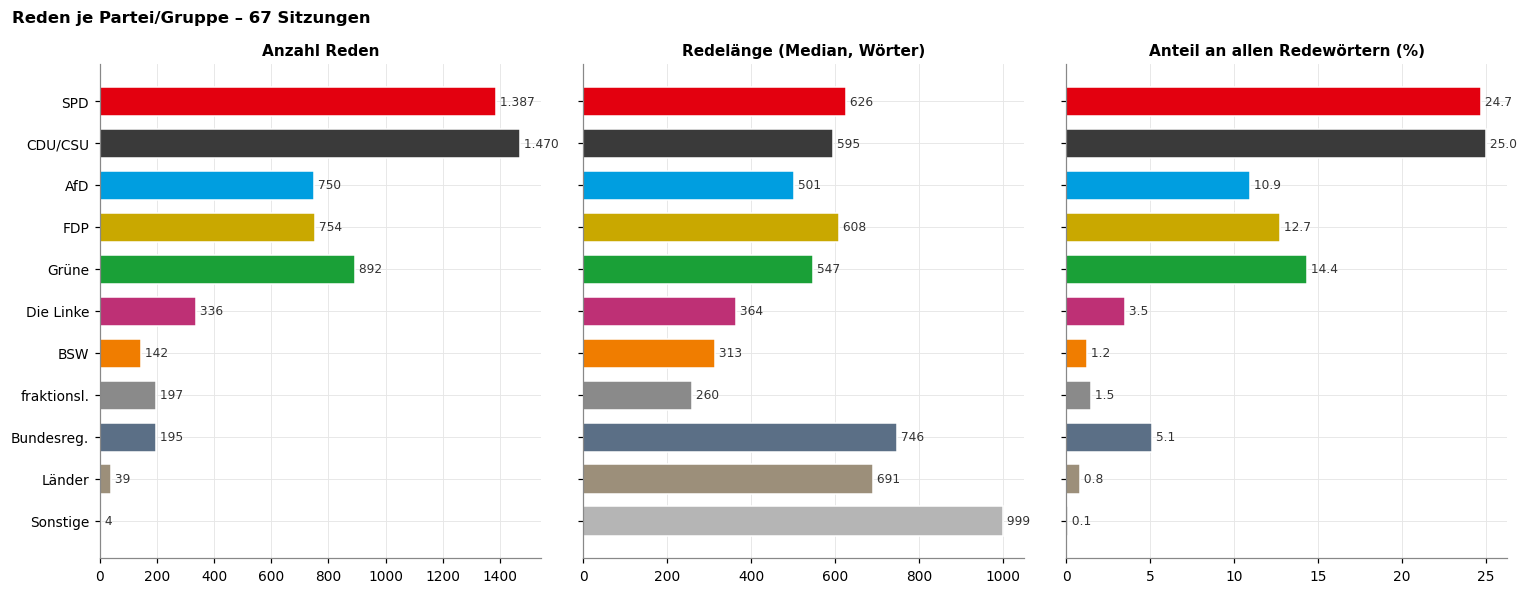

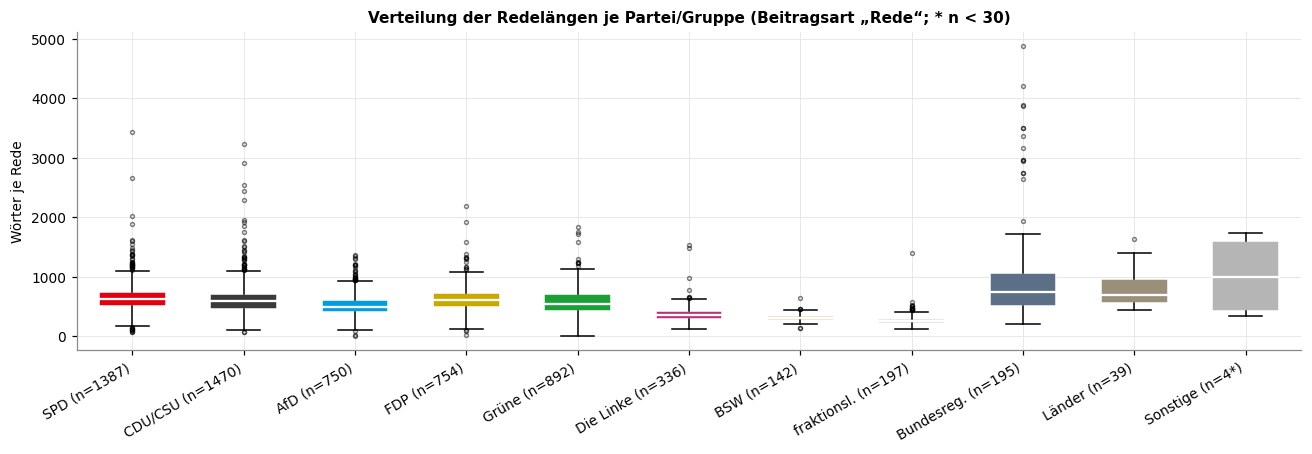

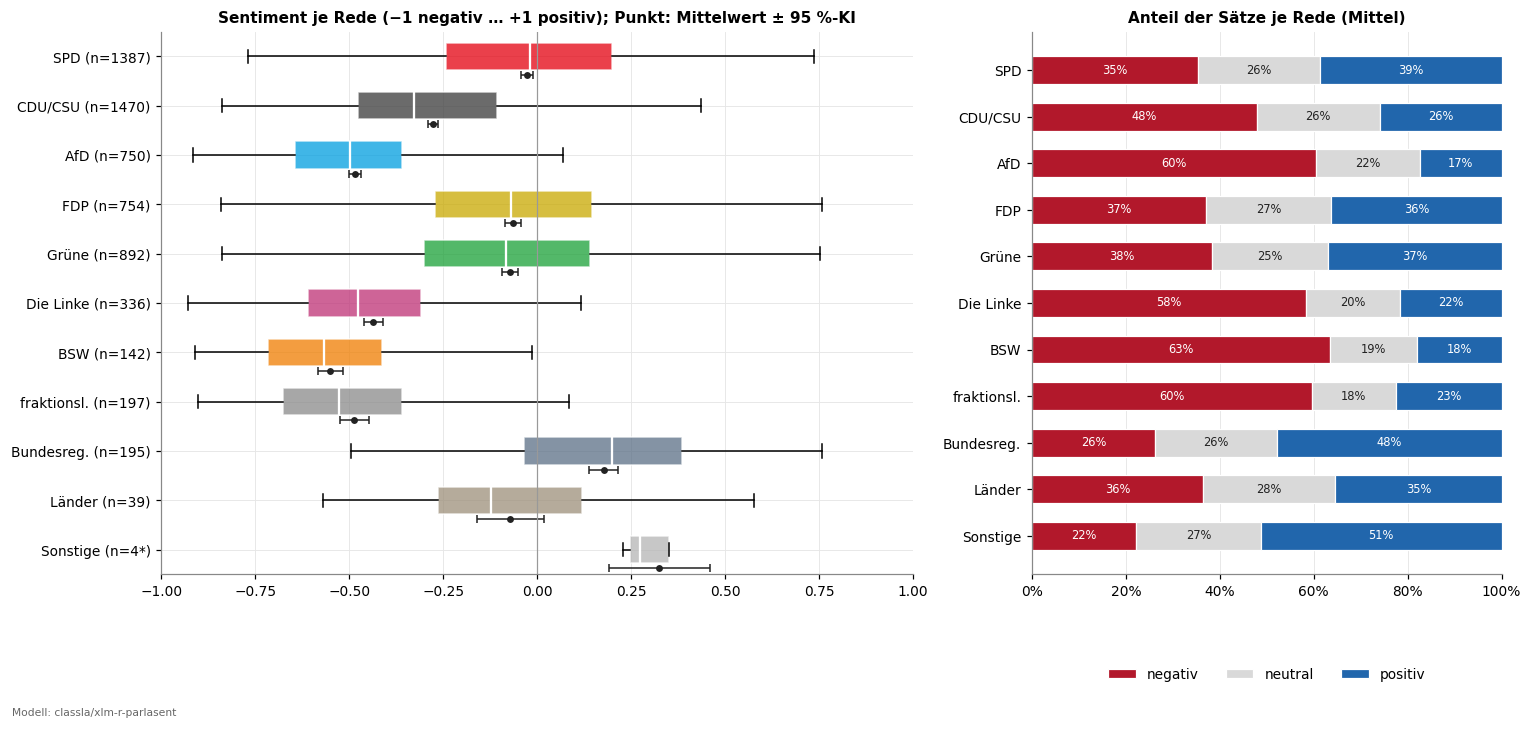

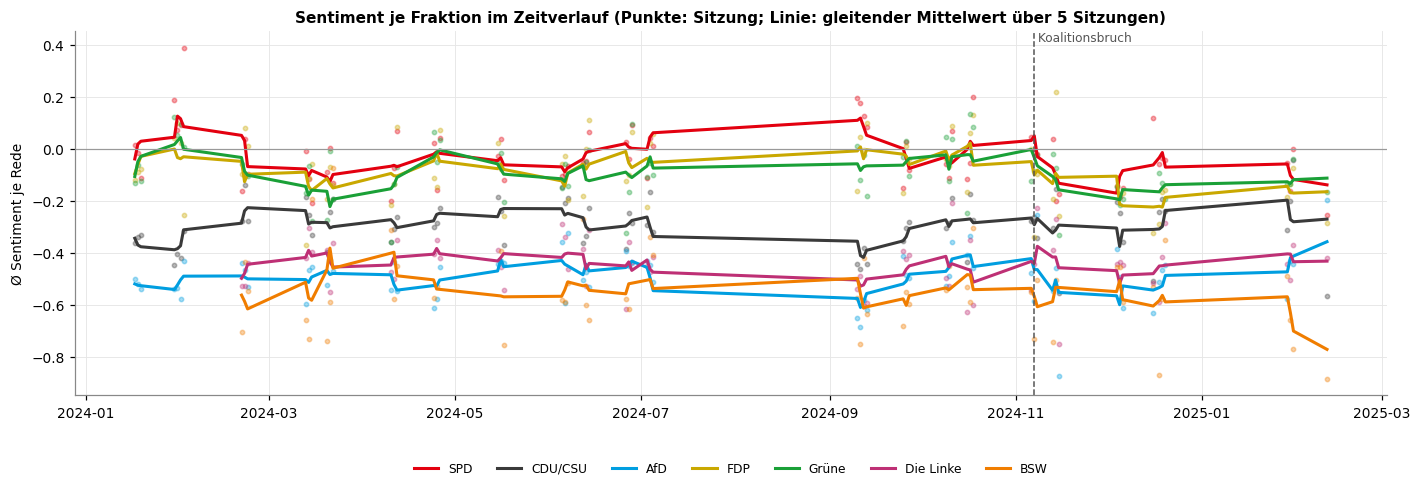

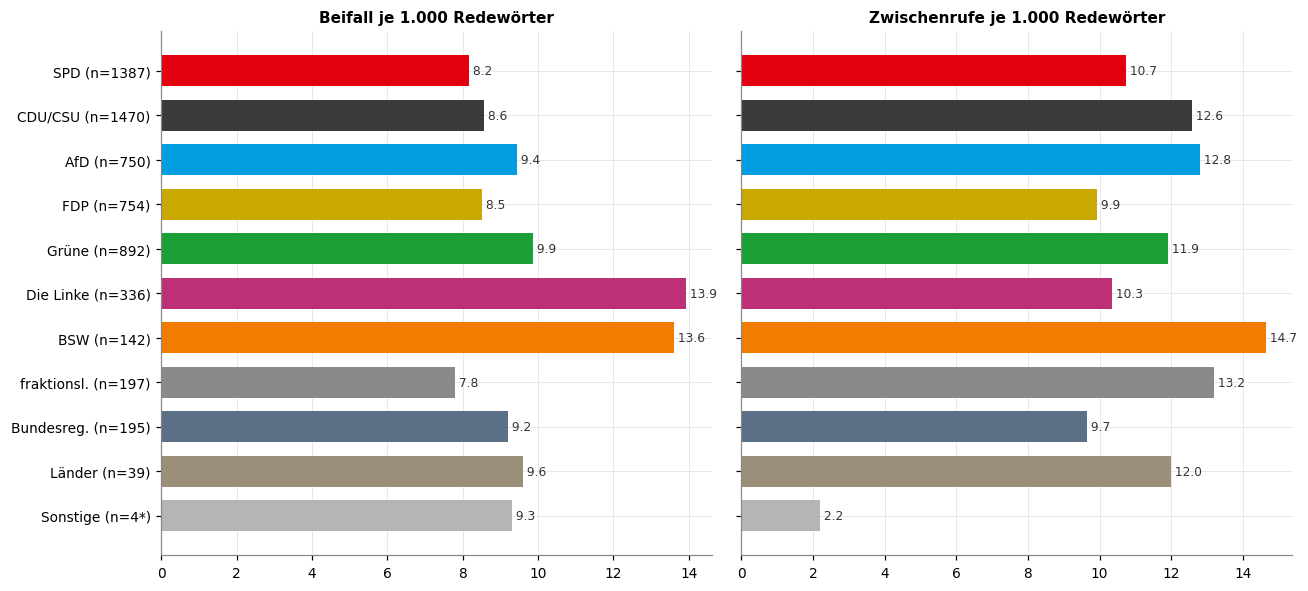

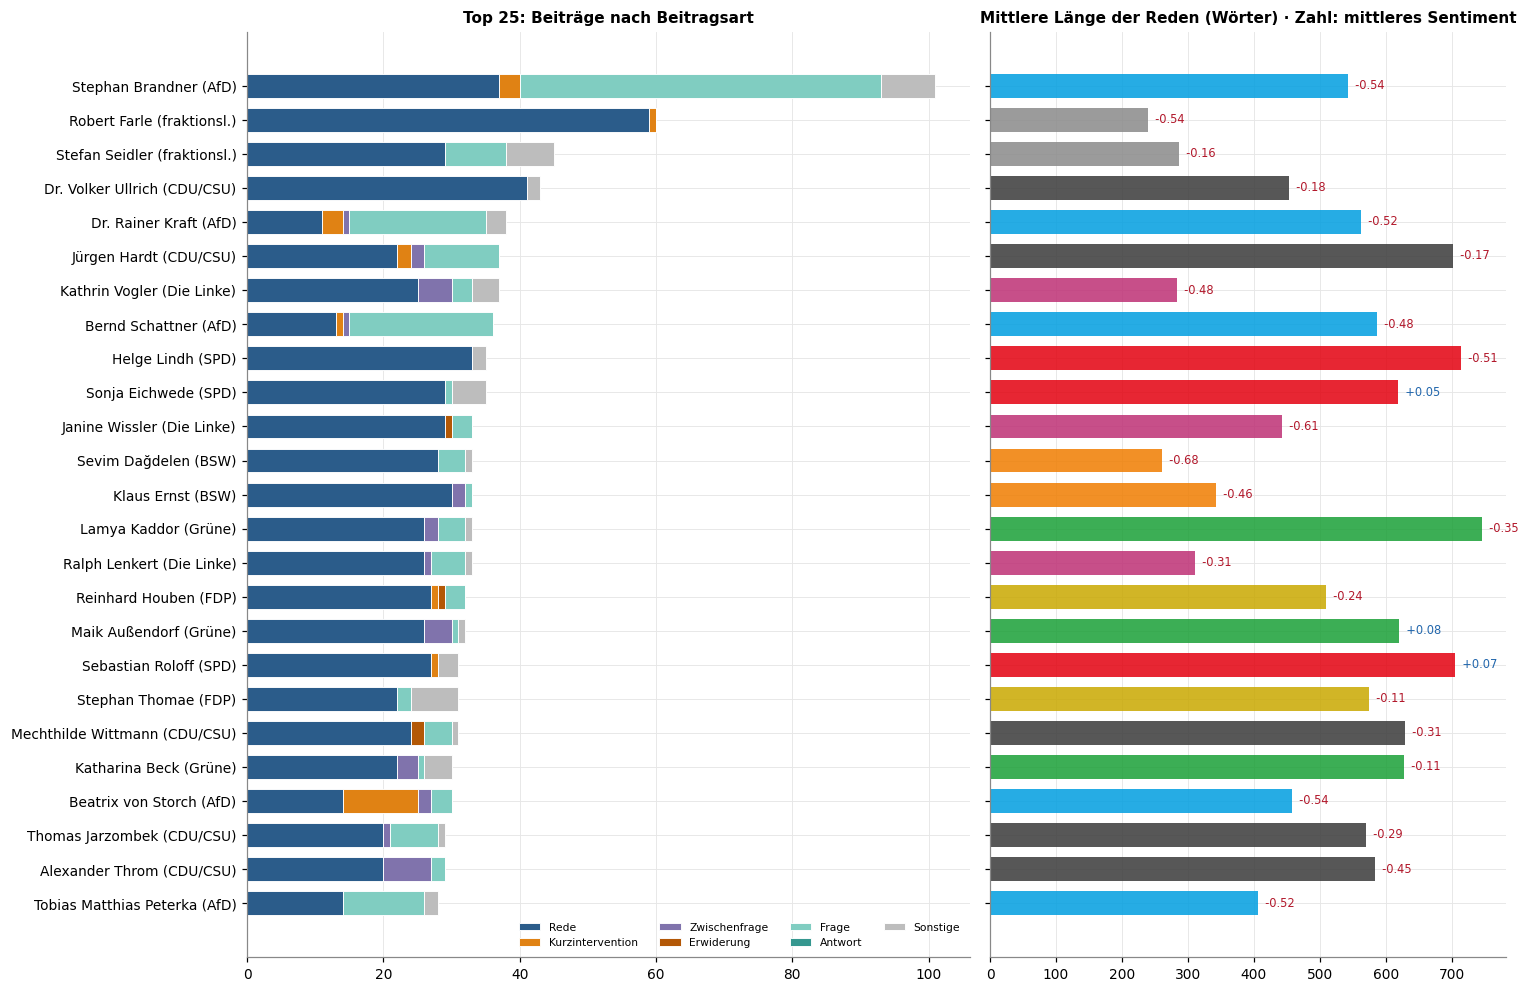

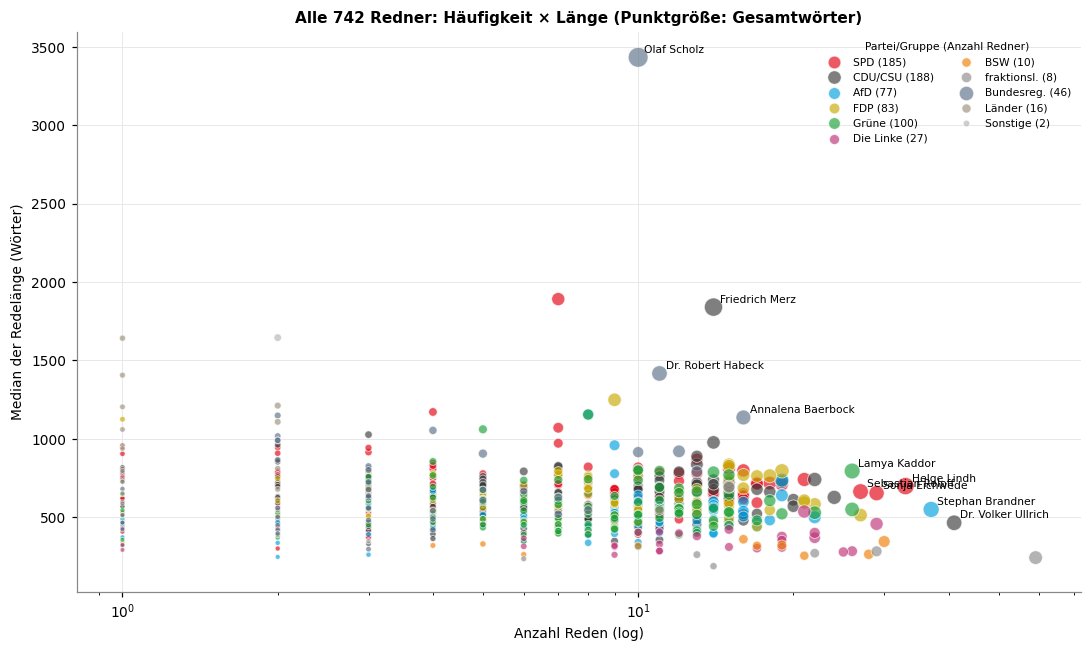

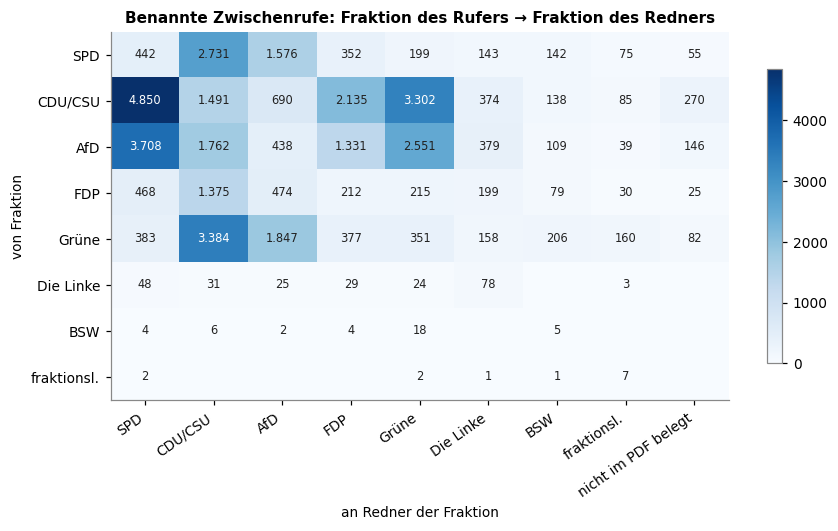

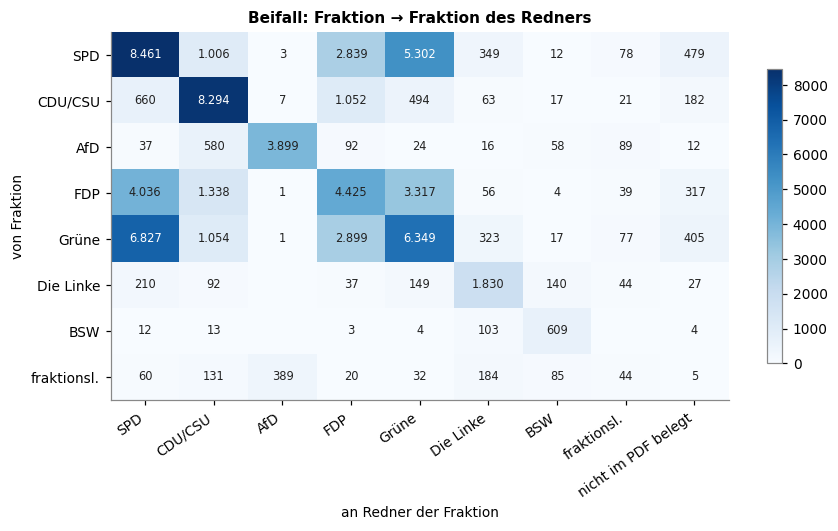

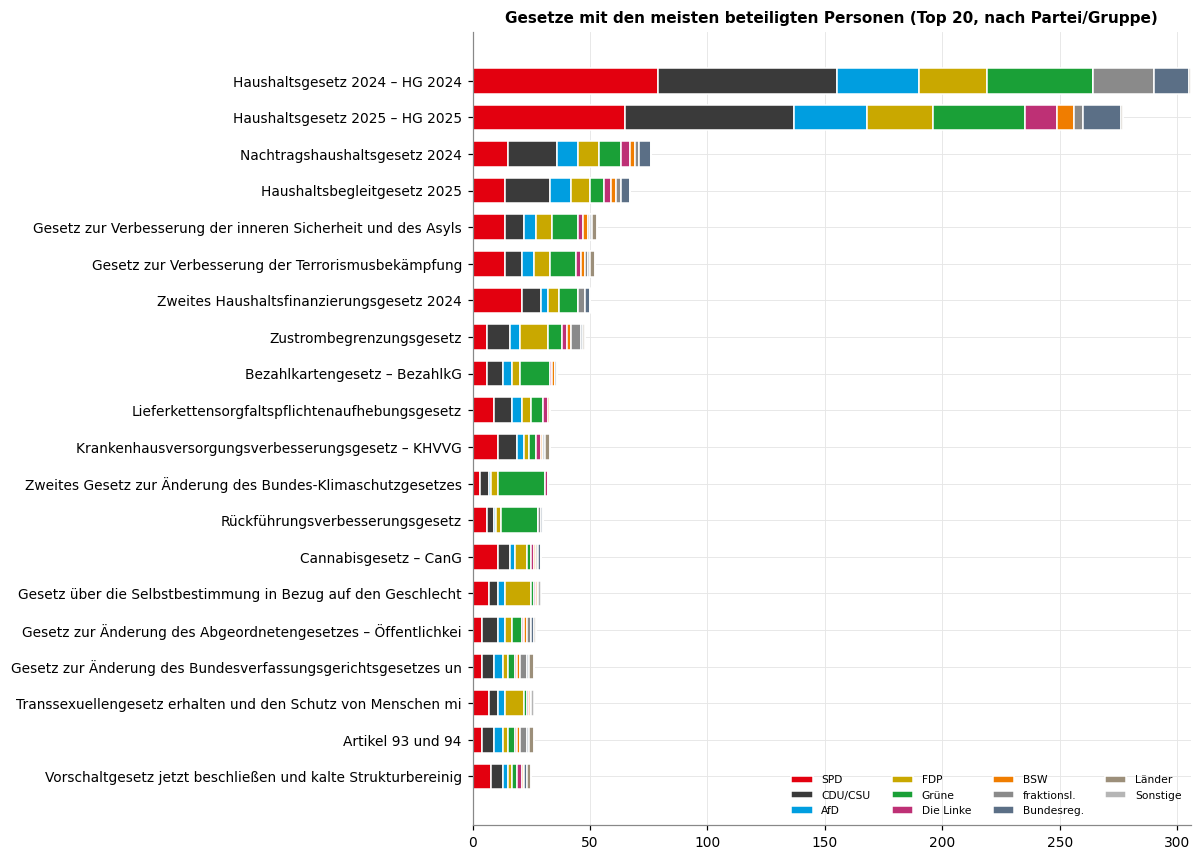

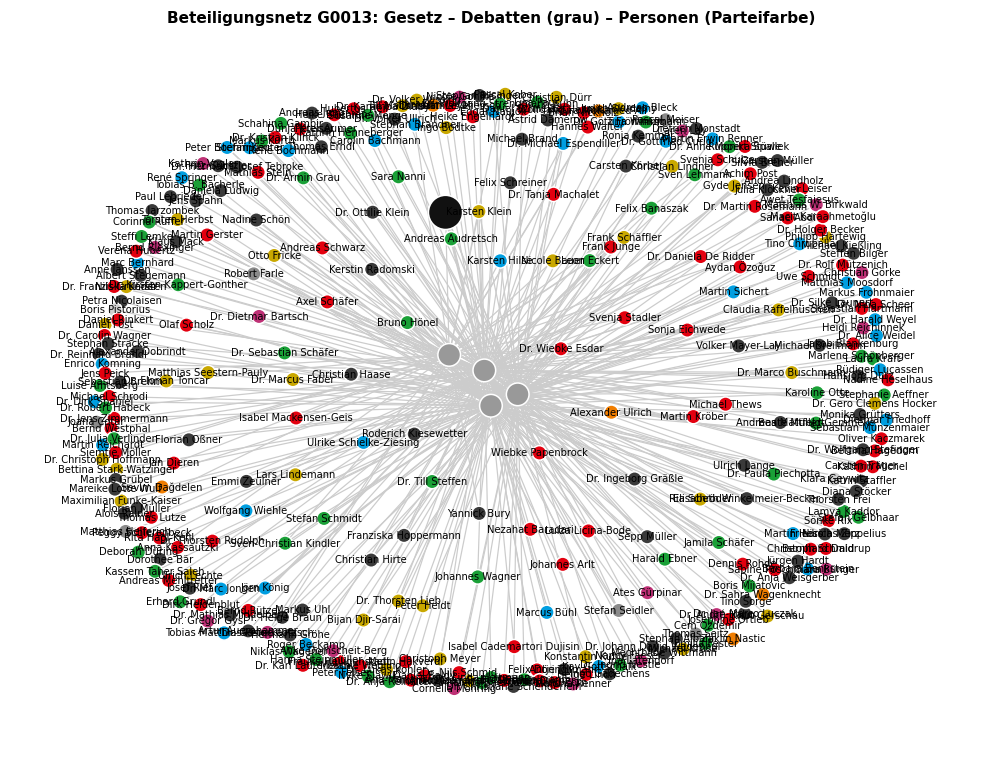

In [39]:
# ---------------------------------------------------------------------
# Visualisierungen (PNG in output/abbildungen)
# ---------------------------------------------------------------------
GRAFIK = Grafiken(FIGUR_DIR)

GRAFIK.parteien(REDEN); plt.show()
GRAFIK.laengen(REDEN); plt.show()
if REDEN["Sentiment_norm"].notna().any():
    GRAFIK.sentiment_parteien(REDEN, SENTIMENT_MODELL); plt.show()
    GRAFIK.sentiment_verlauf(REDEN, SITZUNG_DATUM); plt.show()
GRAFIK.reaktionen(REDEN); plt.show()
GRAFIK.redner(REDEN, REDNER); plt.show()
GRAFIK.streuung_redner(REDNER); plt.show()
_m = lambda art: (INTERAKTION.loc[INTERAKTION["art"].eq(art)].assign(von=lambda d: d["von"].str.replace("Partei:", "", regex=False),
                  an=lambda d: d["an"].str.replace("Partei:", "", regex=False)).pivot_table(index="von", columns="an", values="anzahl", aggfunc="sum"))
if len(INTERAKTION):
    GRAFIK.interaktion(_m("ZWISCHENRUF"), "Benannte Zwischenrufe: Fraktion des Rufers → Fraktion des Redners", "05a_zwischenrufe"); plt.show()
    GRAFIK.interaktion(_m("BEIFALL"), "Beifall: Fraktion → Fraktion des Redners", "05b_beifall"); plt.show()
if len(BETEILIGUNG_INHALT):
    GRAFIK.gesetze(BETEILIGUNG_INHALT, GESETZE); plt.show()
    GRAFIK.graph(GRAPH, GESETZ_BETEILIGTE.groupby("Gesetz_ID")["Person_ID"].nunique().idxmax()); plt.show()

## [↩](#toc) 13) LLM-basierte Auswertung (RAG mit Belegen)<a class="anchor" id="k13"></a>

Fragen an den Korpus werden in drei Schritten beantwortet: (1) der **Graph** schränkt auf die Debatten eines Gesetzes ein (dokumentweise Zerlegung statt Suche im Gesamtkorpus, vgl. SPD-RAG, Yagiz et al.), (2) das eingestellte **Suchverfahren** (`SUCHVERFAHREN`: BM25, Dense oder ihre RRF-Fusion, jeweils optional mit Reranking) liefert die Kandidaten; ein **Cross-Encoder** (`BAAI/bge-reranker-v2-m3`, lokal) ordnet die Top-50 neu – er bewertet Frage und Passage gemeinsam statt getrennt eingebettet; die besten Passagen stehen im Kontext in Originalreihenfolge, (3) das **LLM** antwortet nur aus diesen Passagen und nennt die verwendeten Belegnummern; jede Nummer zeigt auf Rede, Redner und Fundstelle (Druckseite/Quadrant). Reichen die Passagen nicht, antwortet das Modell ausdrücklich, dass die Quellen nicht ausreichen.

In [40]:
# ---------------------------------------------------------------------
# LLM-basierte Auswertung (RAG): Graph schränkt ein, Hybrid-RRF findet Kandidaten, der Cross-Encoder ordnet
# sie neu, das LLM antwortet mit Belegnummern
# ---------------------------------------------------------------------
if LLM_BEREIT and len(GESETZE):
    QA = RagQA(SUCHE, BACKEND, REDEN)
    _g = GESETZ_BETEILIGTE.groupby("Gesetz_ID")["Person_ID"].nunique().idxmax()
    _deb = GRAPH.gesetz_debatten(_g)                    # Graph: Gesetz <- Vorlage -> Debatte schränkt das Retrieval ein
    _titel = txt(GESETZE.set_index("Gesetz_ID").loc[_g, "Kurztitel"]) or GESETZE.set_index("Gesetz_ID").loc[_g, "Gesetzestitel"]
    ANTWORT = QA.frage(f"Welche Argumente bringen die Fraktionen für und gegen das {_titel} vor?", debatten=_deb)
    print(ANTWORT["antwort"]); display(ANTWORT["belege"])
else:
    print("RAG-Auswertung übersprungen (LLM nicht verfügbar)")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

00:26:49 | INFO    | Reranker geladen: BAAI/bge-reranker-v2-m3 (cuda)


Die Fraktionen bringen folgende Argumente für und gegen das Haushaltsgesetz 2024 vor:

**Gegen das Haushaltsgesetz 2024:**
- Die CDU/CSU kritisiert den Haushalt 2024 als „dreifach verfassungswidrig“ und betont, dass er Unklarheiten und Risiken für die Bauwirtschaft schuf. Sie argumentieren, dass die Koalition durch die Kürzungen und die fehlende Planungssicherheit den Bauwirtschaftssektor und die Bevölkerung enttäuscht hat. (belege: [1], [2])
- Die SPD kritisiert die Streichung der Steuerrückerstattung für Agrardiesel, da dies die Wettbewerbsfähigkeit der Landwirtschaft in der EU schädige und zu Verunsicherung in der Branche führe. Sie betonen, dass alternative Antriebstechniken in den nächsten Jahren nicht zur Verfügung stehen und die Kürzungen daher unverhältnismäßig seien. (belege: [3], [4], [5], [6], [8])
- Die SPD kritisiert zudem die Verschärfung der Sanktionen für Bürgergeldempfänger, da sie dies als unangemessen für die Arbeitsförderung betrachtet. (belege: [7])

**Für das Haus

,Nr,Rede_ID,Redner,Partei,Fundstelle
0,1,20/149:R0064,Dr. Jan-Marco Luczak,CDU/CSU,S. 19037 A
1,2,20/152:R0006,Yannick Bury,CDU/CSU,S. 19416 B
2,3,20/152:R0039,Johannes Arlt,SPD,S. 19461 D
3,4,20/152:R0041,Jakob Blankenburg,SPD,S. 19463 C
4,5,20/152:R0045,Anna Kassautzki,SPD,S. 19465 A
5,6,20/152:R0048,Isabel Mackensen-Geis,SPD,S. 19467 B
6,7,20/152:R0050,Jens Peick,SPD,S. 19468 C
7,8,20/152:R0053,Hannes Walter,SPD,S. 19469 D


## [↩](#toc) 14) Evaluation<a class="anchor" id="k14"></a>

**Protokoll.** Entwickelt wird nur auf DEV. Nach dem Methoden-Freeze: `EVAL_SPLITS = ("validierung",)`, danach einmalig `("test",)` mit `TEST_FREIGABE = True`; jede Testauswertung wird mit Zeitstempel und Pipelineversion in `test_auswertungen.jsonl` protokolliert. Die δ-Kalibrierung der Zuordnung läuft nur auf DEV.

| Prüfung | Referenz | Kennzahl |
|:--|:--|:--|
| Struktur (immer) | IV des PDFs | IV-Redner im Text gefunden, Beiträge ohne IV-Anker, Zeilentypen |
| Goldfälle | echte Formen aus den Protokollen | Unit-Tests der Kennungen und Textwerkzeuge (Kopf, Ortszusatz, römische TOPs, Sammeldrucksache, Stammformen, Belegprüfung …) und – mit Embeddingmodell – der Zero-Shot-Aufgaben (Kurzintervention, Zwischenfrage, Erwiderung, Rolle, Beifall …) |
| Zero-Shot | Abstand zur zweitbesten Klasse; Übereinstimmung Modell ↔ Kopfwort | Anteil unsicherer Entscheidungen je Aufgabe; Trefferquote des Modells auf den Texten mit Kopfwort; die unsichersten Fälle und die Widersprüche werden in Kap. 5b angezeigt |
| Reden | DIP-Aktivitäten „Rede“ | TP = Σ_Person min(eigen, DIP); Precision/Recall; Parteiübereinstimmung |
| Beitragsarten | DIP-Aktivitätsarten | Gegenüberstellung der Häufigkeiten; Fehlerliste `eval_arten_fehler` je Sitzung und Person mit beiden Artenprofilen und den eigenen Rede-IDs; `Recall_ohne_SL` ohne DIP-Aktivitäten der Sitzungsleitung |
| Textvollständigkeit | amtliches XML (`<rede>`) | Hauptmaß je Person × Sitzung (Summe der Wörter, unabhängig vom Zuschnitt der Einheiten – das XML führt in Frage-Debatten jeden Wortbeitrag als eigene `<rede>`, wir den Fragekomplex wie DIP); zusätzlich je Rede für Personen ohne Frage/Antwort: Verhältnis, Anteil < 5 %, Korrelation |
| Gesetze | DIP-Vorgänge „Gesetzgebung“ | Precision/Recall/F1 für Lexik, NER, LLM, Hybrid (Drucksache, Kurztitel, Titelähnlichkeit); zusätzlich `Recall_im_IV`: nur Vorgänge, die einem Tagesordnungseintrag der Sitzung entsprechen. DIP verknüpft ein Protokoll auch mit Vorgängen, die dort nur angesagt (nachträgliche Überweisung) oder mitgeteilt werden – Phase 2: etwa 20 der 27 nicht gefundenen Vorgänge |
| Beteiligung | DIP-Vorgangsbezug der Reden | Person × Vorgang je Sitzung, bedingt auf gefundene Gesetze; Debatte vs. Inhalt(δ); Fehlerliste; Precision zusätzlich ohne Paare mit gekürzter DIP-Vorgangsliste (`Precision_bereinigt`) |
| Sentiment | LLM als zweiter Bewerter (ungeschichtete Stichprobe, 300 Sätze); Prüfung über bekannte Gruppen; dev: Modellwahl ParlaSent vs. NLI-Zero-Shot | Übereinstimmung, Makro-F1, κ, gleiche Richtung; Differenzen mit 95 %-KI; Regel → Modell |
| Retrieval | Struktur als Gold: Anfrage = Titel eines Gesetzes, relevant = Chunks seiner Debatten (Suche über alle Chunks) | Hit@10, P@10, MRR, nDCG@10 für BM25, Dense, RRF, Dense + Reranker, RRF + Reranker (Wahl von `SUCHVERFAHREN`); Grenze: Anfragen mit exakten Begriffen (Drucksache, Kürzel) misst sie nicht – misst den Engpass des RAG (Banerjee: „The Bottleneck Is Retrieval, Not Reading“) und dient dem Vergleich der Embeddingmodelle |
| Beteiligung (Inhalt) | – | **nicht** gegen DIP messbar: DIP verknüpft jede Rede eines Tagesordnungspunkts mit allen dort beratenen Vorgängen; daher steigt der DIP-F1 mit δ bis zur Debattenzuordnung. Die inhaltliche Zuordnung ist eine eigene Sicht, keine Korrektur |
| Abstimmungsergebnis | DIP-Beschlüsse (`vorgangspositionen`: Beschlusstenor je Drucksache und Sitzung) | Genauigkeit und Abdeckung je Variante (Formel, LLM, Hybrid), alle Vorlagen und Gesetzesvorlagen |
| Beratungsart | DIP-Vorgangspositionen „1./2./3. Beratung“ je Gesetzgebungsvorgang | Anteil übereinstimmender Lesungen |

Die Normierer der Evaluation (Personen, Titel, Parteien) sind **eigene Funktionen**; eine Änderung der Pipeline verändert die Messung nie unbemerkt.

**Vorher/Nachher.** Liegt eine Kopie des Ausgabeordners der Vorversion unter `VERGLEICH_DIR` (Standard `output_v03/`), stellt die Evaluation die Kennzahlen beider Versionen auf demselben Split nebeneinander (Gesetze, Beitragsarten, Beteiligung). Die Debattenbildung v03 ändert auf 20/146, 20/199 und 20/205 nichts (Debatten identisch mit v02); in Haushaltssitzungen und bei gemeinsamen Aufrufen ändert sie die Zuordnung gewollt (Kennzahl `debatten` gegen das XML).

In [41]:
# =====================================================================
# Evaluation – getrennter Code: eigene Normierer, Kopplung an die Pipeline NUR über Ergebnistabellen
# =====================================================================
import difflib
import xml.etree.ElementTree as ET


_PARTEI_EVAL = {"spd": "SPD", "cdu/csu": "CDU/CSU", "afd": "AfD", "fdp": "FDP", "bündnis90/diegrünen": "BÜNDNIS 90/DIE GRÜNEN",
                "dielinke": "Die Linke", "bsw": "BSW", "fraktionslos": "fraktionslos"}


def _partei_eval(t: str) -> str | None:
    return _PARTEI_EVAL.get(re.sub(r"[\s.\-]+", "", str(t)).casefold())


def _schluessel_person(name: str) -> str:
    n = re.sub(r"\([^()]*\)", " ", str(name))
    n = re.sub(r"\b(?:Dr|Prof|h\.\s?c|med|rer\.\s?nat|phil|jur)\.", " ", n)
    n = unicodedata.normalize("NFKD", n)
    n = "".join(c for c in n if not unicodedata.combining(c)).casefold()
    return " ".join(re.findall(r"[a-z]+(?:-[a-z]+)?", n))


def _schluessel_titel(titel: str) -> str:
    t = unicodedata.normalize("NFKD", str(titel)).casefold()
    t = "".join(c for c in t if not unicodedata.combining(c))
    t = re.sub(r"\bentwurfs? (?:eines|einer)\b", " ", t)
    t = re.sub(r"(gesetz|gesetzbuch)es\b", r"\1", t)
    return " ".join(re.findall(r"[a-z0-9]+", t))


INHALT_STOPP = {"der", "die", "das", "des", "dem", "den", "und", "zur", "zum", "zu", "von", "vom", "im", "in", "fur",
                "uber", "mit", "sowie", "eines", "einer", "einem", "an", "auf", "weiterer", "vorschriften"}


def _inhaltswoerter(t: str) -> set[str]:
    return {w for w in t.split() if w not in INHALT_STOPP and not re.fullmatch(r"(?:erst|zweit|dritt|viert|funft|sechst|siebt|acht|neunt|zehnt)\w*", w)}


def titel_aehnlich(a: str, b: str) -> float:
    """Ähnlichkeit zweier Gesetzestitel: max(Sequenzähnlichkeit, Enthaltensein der Inhaltswörter ab 3)."""
    ka, kb = _schluessel_titel(a), _schluessel_titel(b)
    if not ka or not kb:
        return 0.0
    s = difflib.SequenceMatcher(None, ka, kb).ratio()
    wa, wb = _inhaltswoerter(ka), _inhaltswoerter(kb)
    kurz, lang = sorted((wa, wb), key=len)
    zahlen = lambda w: {x for x in w if x.isdigit()}
    if len(kurz) >= 3 and kurz <= lang and zahlen(kurz) <= zahlen(lang):
        s = max(s, 0.9)
    return s


class Referenz:
    """Liest DIP-JSON ({'documents': [...]}) und amtliche XML-Protokolle – ausschließlich hier."""

    def __init__(self, ordner: Path):
        self.ordner = Path(ordner)

    def dip(self, sitzung: int, name: str) -> list[dict]:
        p = self.ordner / "dip" / f"20_{sitzung:03d}" / f"{name}.json"
        if not p.is_file():
            return []
        d = json.loads(p.read_text(encoding="utf-8"))
        if isinstance(d, dict) and "documents" in d:
            return d["documents"]
        return list(d.values()) if isinstance(d, dict) else d

    def xml_reden(self, sitzung: int) -> pd.DataFrame:
        """<rede>: Rednertext = <p> nach dem Rednerabsatz bis zu einem <name>-Element (Sitzungsleitung),
        danach wieder ab dem nächsten <p klasse='redner'>; <kommentar> (Zwischenrufe) zählt nicht."""
        p = self.ordner / "xml" / f"20_{sitzung:03d}.xml"
        if not p.is_file():
            return pd.DataFrame()
        zeilen, wurzel = [], ET.parse(p).getroot()
        top = {id(r): t.get("top-id") for t in wurzel.iter("tagesordnungspunkt") for r in t.iter("rede")}
        for i, rede in enumerate(wurzel.iter("rede")):
            red = rede.find(".//redner")
            name = " ".join(x for x in (red.findtext(".//vorname"), red.findtext(".//nachname")) if x) if red is not None else ""
            fraktion = red.findtext(".//fraktion") if red is not None else None
            rolle = red.findtext(".//rolle_kurz") if red is not None else None
            woerter, aktiv = 0, True
            for el in rede:
                if el.tag == "name":
                    aktiv = False
                elif el.tag == "p":
                    if el.get("klasse") == "redner":
                        aktiv = True
                        continue
                    if aktiv:
                        woerter += len("".join(el.itertext()).split())
            zeilen.append({"Sitzung": sitzung, "XML_Nr": i + 1, "Rede_XML": rede.get("id"), "Name": name,
                           "Key": _schluessel_person(name), "Fraktion": fraktion, "Rolle": rolle, "Woerter_XML": woerter,
                           "TOP_XML": top.get(id(rede))})
        return pd.DataFrame(zeilen)


class Bewertung:
    def __init__(self, ref: Referenz, sitzungen: list[int]):
        self.ref, self.s = ref, sitzungen

    # ---------------------------------------------------------------- Reden
    def reden_dip(self, reden: pd.DataFrame, arten=("Rede",)) -> tuple[pd.DataFrame, dict]:
        """TP = Σ_Person min(eigen, DIP) je Protokoll (DIP liefert keine Positionen)."""
        zeilen, partei_ok = [], []
        for s in self.s:
            akt = [a for a in self.ref.dip(s, "aktivitaeten") if a.get("aktivitaetsart") in arten]
            if not akt:
                continue
            gold = Counter(_schluessel_person(str(a.get("titel", "")).split(",")[0]) for a in akt)
            e = reden.loc[reden["Sitzung"].eq(s) & reden["Beitragsart"].isin(arten) & ~reden["Leer"]]
            eigen = Counter(e["Redner"].map(_schluessel_person))
            tp = sum(min(n, eigen[k]) for k, n in gold.items())
            zeilen.append({"Sitzung": s, "DIP": sum(gold.values()), "Eigen": sum(eigen.values()), "TP": tp})
            gp = {}
            for a in akt:
                teile = [t.strip() for t in str(a.get("titel", "")).split(",")]
                f = next((_partei_eval(t) for t in teile[1:] if _partei_eval(t)), None)
                if f:
                    gp[_schluessel_person(teile[0])] = f
            for k, p in e.drop_duplicates("Redner").set_index(e.drop_duplicates("Redner")["Redner"].map(_schluessel_person))["Partei"].items():
                if k in gp and isinstance(p, str):
                    partei_ok.append(p == gp[k])
        df = pd.DataFrame(zeilen)
        return df, self._prf(df) | {"Partei_korrekt": float(np.mean(partei_ok)) if partei_ok else np.nan,
                                    "n_Partei": len(partei_ok)}

    ARTEN = {"Rede": ["Rede"], "Kurzintervention": ["Kurzintervention"], "Erwiderung": ["Erwiderung"],
             "Zwischenfrage": ["Zwischenfrage"], "Geschäftsordnung": ["Zur Geschäftsordnung BT"],
             "Frage": ["Frage", "Zusatzfrage"], "Antwort": ["Antwort", "Einleitende Ausführungen und Beantwortung"],
             "Rede (zu Protokoll)": ["Rede (zu Protokoll gegeben)"],
             "Erklärung (schriftlich)": ["Schriftliche Erklärung gem. § 31 Geschäftsordnung BT"],
             "Erklärung": ["Mündliche Erklärung gem. § 31 Geschäftsordnung BT",
                           "Erklärung zur Aussprache gem. § 30 Geschäftsordnung BT"]}

    def arten_dip(self, reden: pd.DataFrame, sitzungsleitung: dict[int, set] | None = None) -> tuple[pd.DataFrame, pd.DataFrame]:
        """Je Beitragsart (zugeordnet zu DIP-Aktivitätsarten): Anzahl und TP über Personen (Σ min). Dazu die
        Fehlerliste: je Sitzung und Person, deren Artenprofil von DIP abweicht, beide Profile und die eigenen
        Rede_IDs (DIP-Arten ohne Zuordnung erscheinen mit ihrem DIP-Namen). DIP zählt auch Aktivitäten der
        Sitzungsleitung, die wir bewusst nicht als Beiträge führen: `sitzungsleitung` (Sitzung -> Personen)
        markiert sie; DIP_ohne_SL/Recall_ohne_SL rechnen sie heraus."""
        sl_alle = {s: {_schluessel_person(n) for n in ns} for s, ns in (sitzungsleitung or {}).items()}
        zu = {d: e for e, ds in self.ARTEN.items() for d in ds}
        zeilen, fehler = [], []
        for s in self.s:
            akt = self.ref.dip(s, "aktivitaeten")
            if not akt:
                continue
            gold = defaultdict(Counter)
            roh = defaultdict(Counter)                                   # DIP-Aktivitätsarten im Original
            for a in akt:
                art, k = a.get("aktivitaetsart"), _schluessel_person(str(a.get("titel", "")).split(",")[0])
                gold[k][zu.get(art, f"[DIP] {art}")] += 1
                roh[k][art] += 1
            e = reden.loc[reden["Sitzung"].eq(s) & ~reden["Leer"]]
            eigen, ids = defaultdict(Counter), defaultdict(list)
            for k, art, rid in zip(e["Redner"].map(_schluessel_person), e["Beitragsart"], e["Rede_ID"]):
                if art in self.ARTEN:
                    eigen[k][art] += 1
                    ids[k].append(f"{rid} ({art})")
            sl = sl_alle.get(s, set())
            for k in sorted(set(gold) | set(eigen)):
                g = Counter({x: n for x, n in gold[k].items() if x in self.ARTEN})
                if g != eigen[k]:
                    fmt = lambda c: ", ".join(f"{x}×{n}" for x, n in sorted(c.items()))
                    fehler.append({"Sitzung": s, "Person": k, "DIP": fmt(gold[k]), "DIP_roh": fmt(roh[k]), "Eigen": fmt(eigen[k]),
                                   "Sitzungsleitung": k in sl, "Rede_IDs": "; ".join(ids[k])})
            for art in self.ARTEN:
                zeilen.append({"Sitzung": s, "Beitragsart": art, "DIP": sum(c[art] for c in gold.values()),
                               "DIP_ohne_SL": sum(c[art] for k, c in gold.items() if k not in sl),
                               "Eigen": sum(c[art] for c in eigen.values()),
                               "TP": sum(min(c[art], eigen[k][art]) for k, c in gold.items())})
        df = (pd.DataFrame(zeilen).groupby("Beitragsart", sort=False)[["DIP", "DIP_ohne_SL", "Eigen", "TP"]].sum()
              if zeilen else pd.DataFrame(columns=["DIP", "DIP_ohne_SL", "Eigen", "TP"]))
        df = df.assign(**self._prf_spalten(df))
        df["Recall_ohne_SL"] = (df["TP"] / df["DIP_ohne_SL"].where(df["DIP_ohne_SL"] > 0)).round(3)
        return df, pd.DataFrame(fehler)

    def reden_xml(self, reden: pd.DataFrame) -> tuple[pd.DataFrame, dict, pd.DataFrame]:
        """Textvollständigkeit gegen das amtliche XML. Hauptmaß je Person × Sitzung (Summe der Wörter) – unabhängig
        davon, wie Beiträge zu Einheiten geschnitten sind (XML: ein <rede> je Wortbeitrag, auch in Frage-Debatten;
        wir: Fragekomplexe wie DIP). Zusätzlich je Rede für Personen ohne Frage/Antwort in der Sitzung (das XML
        kennt keine Debatten): i-te XML-Rede einer Person ↔ i-te eigene Einheit außerhalb der Anlagen, ohne Zwischenfragen
        und Zwischenbeiträge – das XML führt sie in der <rede> der unterbrochenen Person, nicht als eigene <rede>. Rückgabe: Personentabelle, Kennzahlen, Redetabelle."""
        pers, paare = [], []
        for s in self.s:
            x = self.ref.xml_reden(s)
            if x.empty:
                continue
            e = reden.loc[reden["Sitzung"].eq(s) & ~reden["Leer"]].copy()
            e["Key"] = e["Redner"].map(_schluessel_person)
            p = (x.groupby("Key").agg(Name=("Name", "first"), Woerter_XML=("Woerter_XML", "sum"), Reden_XML=("Rede_XML", "size"))
                 .join(e.groupby("Key").agg(Woerter=("Woerter", "sum"), Einheiten=("Rede_ID", "size")), how="left"))
            pers.append(p.reset_index().assign(Sitzung=s))
            qa = e["Beitragsart"].isin(["Frage", "Antwort"])
            e = e.loc[~qa & e["Bereich"].ne("anlagen") & ~e["Beitragsart"].isin(["Zwischenfrage", "Zwischenbeitrag"])]
            xs = x.loc[~x["Key"].isin(reden.loc[reden["Sitzung"].eq(s) & reden["Beitragsart"].isin(["Frage", "Antwort"]), "Redner"]
                                      .map(_schluessel_person))].copy()
            e["i"] = e.groupby("Key").cumcount(); xs["i"] = xs.groupby("Key").cumcount()
            paare.append(xs.merge(e[["Key", "i", "Rede_ID", "Debatte_ID", "Woerter", "Partei", "Beitragsart"]], on=["Key", "i"], how="left"))
        if not pers:
            return pd.DataFrame(), {}, pd.DataFrame()
        p, m = pd.concat(pers, ignore_index=True), pd.concat(paare, ignore_index=True)
        def kenn(d: pd.DataFrame, n: str) -> dict:
            ok = d.dropna(subset=["Woerter"])
            rel = (ok["Woerter"] - ok["Woerter_XML"]) / ok["Woerter_XML"].clip(lower=1)
            return {f"{n}_XML": len(d), f"{n}_zugeordnet": len(ok),
                    f"{n}_Woerter_Verhaeltnis": ok["Woerter"].sum() / max(ok["Woerter_XML"].sum(), 1),
                    f"{n}_Anteil_Abw_unter_5pct": float((rel.abs() < 0.05).mean()) if len(ok) else np.nan,
                    f"{n}_Korrelation": float(np.corrcoef(ok["Woerter"], ok["Woerter_XML"])[0, 1]) if len(ok) > 2 else np.nan}
        return p, kenn(p, "Personen") | kenn(m, "Reden"), m

    @staticmethod
    def debatten_xml(paare: pd.DataFrame) -> tuple[dict, pd.DataFrame]:
        """Debattengrenzen gegen das amtliche XML (<tagesordnungspunkt top-id>): für aufeinanderfolgende,
        zugeordnete Reden (XML-Reihenfolge) ist 'Grenze' = anderer Tagesordnungspunkt bzw. andere Debatte.
        Gemeinsam aufgerufene Punkte führt das XML als einen Punkt ('Zusatzpunkt 23, 24'). Unterpunkte zählen wie bei uns
        zum Oberpunkt: Nummern 'I.14' und Gliederungen ohne TOP-Kennung ('Einzelplan 09' → 'Einzelplan 11'), gezählt in
        'Grenzen_Unterpunkte_XML'. Rückgabe: Precision/Recall/F1 der Grenzen, Fehlerliste."""
        if paare is None or not len(paare) or "TOP_XML" not in paare:
            return {}, pd.DataFrame()
        m = paare.dropna(subset=["Rede_ID", "TOP_XML"]).sort_values(["Sitzung", "XML_Nr"]).copy()
        m["TOP"] = m["TOP_XML"].map(lambda t: Kennung.TOP_UNTERNUMMER.sub(r"\1", str(t)))
        offiziell = m["TOP"].map(lambda t: bool(Kennung.AUFRUF_PUNKT.match(t)))
        m["Ebene"] = m["TOP"].where(offiziell, "Gliederung " + m["TOP"].str.split().str[0])   # 'Einzelplan 09' -> Gliederung
        v = m.groupby("Sitzung").shift(1)
        m = m.assign(TOP_vorher=v["TOP"], Ebene_vorher=v["Ebene"], Debatte_vorher=v["Debatte_ID"],
                     Redner_vorher=v["Name"]).dropna(subset=["TOP_vorher"])
        gold, wir = m["Ebene"].ne(m["Ebene_vorher"]), m["Debatte_ID"].ne(m["Debatte_vorher"])
        unter = m["TOP"].ne(m["TOP_vorher"]) & ~gold
        tp = int((gold & wir).sum())
        p, r = tp / max(int(wir.sum()), 1), tp / max(int(gold.sum()), 1)
        kenn = {"Paare": len(m), "Grenzen_XML": int(gold.sum()), "Grenzen_Unterpunkte_XML": int(unter.sum()),
                "Grenzen_wir": int(wir.sum()),
                "Precision": p, "Recall": r, "F1": 2 * p * r / (p + r) if p + r else 0.0,
                "Uebereinstimmung": float((gold == wir).mean()) if len(m) else np.nan}
        fehler = m.loc[gold != wir, ["Sitzung", "XML_Nr", "Redner_vorher", "Name", "TOP_vorher", "TOP",
                                       "Debatte_vorher", "Debatte_ID"]].assign(
            Fehler=np.where(gold[gold != wir], "Grenze fehlt", "Grenze zu viel"))
        return kenn, fehler.reset_index(drop=True)

    # ---------------------------------------------------------------- Gesetze
    def dip_gesetze(self, s: int) -> list[dict]:
        ds = defaultdict(set)
        for d in self.ref.dip(s, "drucksachen"):
            for b in d.get("vorgangsbezug") or []:
                if d.get("dokumentnummer"):
                    ds[str(b.get("id"))].add(d["dokumentnummer"])
        return [{"Vorgang": str(v.get("id")), "Titel": v.get("titel", ""), "Drucksachen": ds[str(v.get("id"))]}
                for v in self.ref.dip(s, "vorgaenge") if v.get("vorgangstyp") == "Gesetzgebung"]

    def _treffer(self, e: dict, g: dict) -> tuple[float, str]:
        if set(e.get("Drucksachen") or []) & g["Drucksachen"]:
            return 1.0, "Drucksache"
        kurz = e.get("Kurztitel")
        if isinstance(kurz, str) and len(kurz) > 5 and _schluessel_titel(kurz) in _schluessel_titel(g["Titel"]):
            return 0.95, "Kurztitel"
        return titel_aehnlich(e["Titel"], g["Titel"]), "Titel"

    def gesetze_dip(self, varianten: dict[str, pd.DataFrame], schwelle: float = 0.85,
                    vorlagen: pd.DataFrame | None = None) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
        """Je Variante (Lexik/NER/LLM/Hybrid): eindeutige Zuordnung eigener Gesetzesvorlagen ↔ DIP-Vorgänge
        (Gesetzgebung) je Protokoll, greedy nach Score. Zusätzlich die Abbildung Vorlage -> alle DIP-Vorgänge
        mit Score ≥ Schwelle (für die Beteiligung; parallele Entwürfe gleichen Titels).
        DIP verknüpft ein Protokoll auch mit Vorgängen, die dort nur angesagt (nachträgliche Überweisung) oder
        mitgeteilt werden. `im_IV`: der Vorgang entspricht einem Eintrag der Tagesordnung (IV) der Sitzung –
        gleich welchen Typs (Drucksache oder Titel); Recall_im_IV zählt nur diese Vorgänge."""
        def auf_tagesordnung(s: int, g: dict) -> bool:
            if vorlagen is None:
                return True
            return any(self._treffer({"Drucksachen": d if isinstance(d, (list, tuple, set)) else [], "Kurztitel": k,
                                      "Titel": t if isinstance(t, str) else x}, g)[0] >= schwelle
                       for d, k, t, x in vorlagen.loc[vorlagen["Sitzung"].eq(s), ["Drucksachen", "Kurztitel", "Titel", "Text"]]
                       .itertuples(index=False))
        zeilen, fehler, abbildung = [], [], []
        for name, df in varianten.items():
            for s in self.s:
                gold = self.dip_gesetze(s)
                for g in gold:
                    g.setdefault("im_IV", auf_tagesordnung(s, g))
                eigen = df.loc[df["Sitzung"].eq(s)].to_dict("records")
                if not self.ref.dip(s, "vorgaenge"):
                    continue
                paare = sorted(((i, j, *self._treffer(e, g)) for i, e in enumerate(eigen) for j, g in enumerate(gold)),
                               key=lambda x: -x[2])
                gi, gj, tp = set(), set(), 0
                for i, j, sc, art in paare:
                    if sc >= schwelle and i not in gi and j not in gj:
                        gi.add(i); gj.add(j); tp += 1
                    if name == "Hybrid" and sc >= schwelle:
                        abbildung.append({"Sitzung": s, "Vorlage_ID": eigen[i]["Vorlage_ID"], "Vorgang": gold[j]["Vorgang"],
                                          "Score": sc, "Art": art})
                zeilen.append({"Variante": name, "Sitzung": s, "DIP": len(gold), "Eigen": len(eigen), "TP": tp,
                               "DIP_im_IV": sum(g["im_IV"] for g in gold),
                               "TP_im_IV": sum(gold[j]["im_IV"] for j in gj)})
                if name == "Hybrid":
                    fehler += [{"Sitzung": s, "Fehler": "nicht gefunden (FN)", "Titel": g["Titel"], "im_IV": g["im_IV"]}
                               for j, g in enumerate(gold) if j not in gj]
                    fehler += [{"Sitzung": s, "Fehler": "ohne DIP-Entsprechung (FP)", "Titel": e["Titel"]} for i, e in enumerate(eigen) if i not in gi]
        df = pd.DataFrame(zeilen)
        summe = (df.groupby("Variante", sort=False)[["DIP", "Eigen", "TP", "DIP_im_IV", "TP_im_IV"]].sum()
                 if len(df) else pd.DataFrame())
        if len(summe):
            summe = summe.assign(**self._prf_spalten(summe))
            summe["Recall_im_IV"] = (summe["TP_im_IV"] / summe["DIP_im_IV"].where(summe["DIP_im_IV"] > 0)).round(3)
        return summe, pd.DataFrame(fehler), pd.DataFrame(abbildung)

    TENOR = (("Annahme einer Entschließung", None), ("Annahme", "angenommen"), ("Ablehnung", "abgelehnt"),
             ("Überweisung", "überwiesen"), ("Erledig", "erledigt"))     # DIP-Beschlusstenor -> unsere Ergebnisklasse

    def abstimmungen_dip(self, varianten: dict[str, pd.DataFrame]) -> tuple[pd.DataFrame, pd.DataFrame]:
        """Ergebnisse gegen die amtlichen DIP-Beschlüsse (vorgangspositionen: beschlussfassung je Drucksache und
        Sitzung). Ein Beschluss wird den Vorlagen derselben Sitzung zugeordnet, deren Drucksachen seine Drucksache
        enthalten; richtig, wenn eine davon dasselbe Ergebnis trägt. Tenöre ohne Gegenstück (Kenntnisnahme,
        Entschließung …) zählen als nicht vergleichbar. Zeilen: Variante × (alle Vorlagen / Gesetzesvorlagen);
        Fehlerliste der letzten Variante."""
        gold = [(s, p, b) for s in self.s for p in self.ref.dip(s, "vorgangspositionen")
                for b in p.get("beschlussfassung") or []]
        tab, fehler = {}, pd.DataFrame()
        for name, vorlagen in varianten.items():
            v = vorlagen.assign(_ds=vorlagen["Drucksachen"].map(
                lambda d: set(d) if isinstance(d, (list, tuple, set)) else set(re.findall(r"\d+/\d+", str(d)))))
            zeilen = []
            for s, p, b in gold:
                nr, tenor = b.get("dokumentnummer"), str(b.get("beschlusstenor", ""))
                dip = next((k for t, k in self.TENOR if tenor.startswith(t)), None)
                m = v.loc[v["Sitzung"].eq(s) & v["_ds"].map(lambda d: nr in d)]
                eigen = [e for e in m["Ergebnis"] if isinstance(e, str) and e != "keine Abstimmung"] if "Ergebnis" in m else []
                zeilen.append({"Sitzung": s, "Drucksache": nr, "Tenor_DIP": tenor, "DIP": dip, "Seite_DIP": b.get("seite"),
                               "Vorgangstyp": p.get("vorgangstyp"), "Position": p.get("vorgangsposition"),
                               "Gesetz": bool(m["Gesetz_final"].fillna(False).astype(bool).any()) if "Gesetz_final" in m else False,
                               "Vorlage_gefunden": len(m) > 0, "Eigen": "; ".join(dict.fromkeys(eigen)) or None,
                               "Richtig": dip is not None and dip in eigen,
                               "Beleg": next((x for x in m.get("Ergebnis_Beleg", []) if isinstance(x, str)), None)})
            d = pd.DataFrame(zeilen)
            if d.empty:
                continue
            for teil, x in (("alle", d), ("Gesetze", d.loc[d["Gesetz"]])):
                gef = x.loc[x["DIP"].notna() & x["Vorlage_gefunden"]]
                mit = gef.loc[gef["Eigen"].notna()]
                tab[(name, teil)] = {"Beschluesse_DIP": len(x), "vergleichbar": int(x["DIP"].notna().sum()),
                                     "Vorlage_gefunden": len(gef), "mit_Ergebnis": len(mit), "richtig": int(mit["Richtig"].sum()),
                                     "Genauigkeit": mit["Richtig"].mean() if len(mit) else np.nan,
                                     "Abdeckung": len(mit) / len(gef) if len(gef) else np.nan}
            fehler = d.loc[d["DIP"].notna() & d["Vorlage_gefunden"] & ~d["Richtig"]].reset_index(drop=True)
        return pd.DataFrame(tab).T, fehler

    LESUNG = {"Erste Beratung": {1}, "Zweite Beratung": {2}, "Dritte Beratung": {3}, "Zweite und dritte Beratung": {2, 3}}

    def beratung_dip(self, vorlagen: pd.DataFrame) -> tuple[dict, pd.DataFrame]:
        """Beratungsart der Gesetzesvorlagen gegen DIP: je Gesetzgebungsvorgang und Sitzung die Lesungen der
        Vorgangspositionen ('1. Beratung', '2. Beratung …', '3. Beratung'); zugeordnet über die Drucksachen der
        Beschlüsse. Richtig, wenn die Menge der Lesungen übereinstimmt."""
        v = vorlagen.loc[vorlagen["Gesetz_final"].fillna(False).astype(bool)]
        v = v.assign(_ds=v["Drucksachen"].map(lambda d: set(d) if isinstance(d, (list, tuple, set))
                                              else set(re.findall(r"\d+/\d+", str(d)))))
        gold = defaultdict(lambda: (set(), set()))
        for s in self.s:
            for p in self.ref.dip(s, "vorgangspositionen"):
                if p.get("vorgangstyp") != "Gesetzgebung":
                    continue
                pos = str(p.get("vorgangsposition", ""))
                les = {n for n in (1, 2, 3) if pos.startswith(f"{n}.")}
                ds = {b["dokumentnummer"] for b in p.get("beschlussfassung") or [] if b.get("dokumentnummer")}
                if les and ds:
                    g = gold[(s, p.get("vorgang_id"))]
                    g[0].update(les); g[1].update(ds)
        zeilen = []
        for (s, vid), (les, ds) in gold.items():
            m = v.loc[v["Sitzung"].eq(s) & v["_ds"].map(lambda d: bool(d & ds))]
            eigen = set().union(*[self.LESUNG.get(b, set()) for b in m["Beratung"]]) if len(m) else set()
            zeilen.append({"Sitzung": s, "Vorgang": vid, "Drucksachen": sorted(ds), "DIP": sorted(les),
                           "Eigen": sorted(eigen), "gefunden": len(m) > 0, "Richtig": eigen == les})
        d = pd.DataFrame(zeilen)
        if d.empty:
            return {}, d
        gef = d.loc[d["gefunden"]]
        return ({"Vorgaenge_DIP": len(d), "gefunden": len(gef), "richtig": int(gef["Richtig"].sum()),
                 "Genauigkeit": gef["Richtig"].mean() if len(gef) else np.nan},
                d.loc[d["gefunden"] & ~d["Richtig"]].reset_index(drop=True))

    def beteiligung_dip(self, varianten: dict[str, pd.DataFrame], abbildung: pd.DataFrame,
                        arten=("Rede",)) -> tuple[pd.DataFrame, pd.DataFrame]:
        """Person × Vorgang je Sitzung, bedingt auf korrekt gefundene Gesetze (Abbildung aus gesetze_dip).
        Zweiter Rückgabewert (v09): Fehlerliste der ersten Variante (nur eigen = Precision-Fehler, nur DIP = Recall-Fehler).
        v10: Die DIP-Schnittstelle kürzt bei manchen Aktivitäten die Liste der Vorgänge (`vorgangsbezug_anzahl` größer
        als die Liste). Eigene Paare ohne Gegenstück, deren DIP-Aktivität gekürzt ist, sind nicht beurteilbar: Sie werden
        gekennzeichnet, und die Precision wird zusätzlich ohne sie ausgewiesen (`Precision_bereinigt`)."""
        if abbildung.empty:
            return pd.DataFrame(), pd.DataFrame()
        gefunden = set(zip(abbildung["Sitzung"], abbildung["Vorgang"]))
        gold, gekuerzt, gekuerzt_pers = set(), 0, set()
        for s in self.s:
            for a in self.ref.dip(s, "aktivitaeten"):
                if a.get("aktivitaetsart") not in arten:
                    continue
                bez = a.get("vorgangsbezug") or []
                k = _schluessel_person(str(a.get("titel", "")).split(",")[0])
                if (a.get("vorgangsbezug_anzahl") or 0) > len(bez):     # DIP-Schnittstelle kürzt die Vorgangsliste
                    gekuerzt += 1
                    gekuerzt_pers.add((s, k))
                gold |= {(s, k, str(b.get("id"))) for b in bez if (s, str(b.get("id"))) in gefunden}
        zeilen, fehler = [], pd.DataFrame()
        for name, b in varianten.items():
            b = b.loc[b["Beitragsart"].isin(arten) & b["Sitzung"].isin(self.s)] if "Sitzung" in b else b
            m = b.merge(abbildung[["Vorlage_ID", "Vorgang"]], on="Vorlage_ID")
            pred = set(zip(m["Sitzung"], m["Redner"].map(_schluessel_person), m["Vorgang"]))
            if fehler.empty:
                info = m.assign(P=m["Redner"].map(_schluessel_person)).drop_duplicates(["Sitzung", "P", "Vorgang"])
                info = info.set_index(["Sitzung", "P", "Vorgang"])
                fehler = pd.DataFrame([{"Sitzung": s, "Person": k, "Vorgang": v, "Fehler": art,
                                        "DIP_gekuerzt": (s, k) in gekuerzt_pers,
                                        **({c: info.loc[(s, k, v), c] for c in ("Redner", "Vorlage_ID", "Debatte_ID", "Zuordnung")
                                            if c in info} if (s, k, v) in info.index else {})}
                                       for art, menge in (("nur eigen", pred - gold), ("nur DIP", gold - pred))
                                       for s, k, v in sorted(menge)])
            tp = len(pred & gold)
            p, r = tp / max(len(pred), 1), tp / max(len(gold), 1)
            # bereinigt (v10): eigene Paare ohne DIP-Gegenstück, deren DIP-Aktivität gekürzt ist, sind nicht beurteilbar
            unklar = {(s, k, v) for s, k, v in pred - gold if (s, k) in gekuerzt_pers}
            zeilen.append({"Variante": name, "Paare_eigen": len(pred), "Paare_DIP": len(gold), "TP": tp,
                           "Precision": p, "Recall": r, "F1": 2 * p * r / (p + r) if p + r else 0.0,
                           "DIP_gekuerzt": gekuerzt, "Paare_nicht_beurteilbar": len(unklar),
                           "Precision_bereinigt": tp / max(len(pred) - len(unklar), 1)})
        return pd.DataFrame(zeilen), fehler

    # ---------------------------------------------------------------- Retrieval (strukturelles Gold)
    @staticmethod
    def retrieval(suche, gesetze: pd.DataFrame, vorlagen: pd.DataFrame, n: int = 150, seed: int = 42,
                  verfahren=("bm25", "dense", "rrf", "dense+rerank", "rrf+rerank"), top: int = 10) -> pd.DataFrame:
        """Retrieval-Güte ohne Annotation (v03): Anfrage = Kurztitel bzw. Titel eines Gesetzes; relevant sind die
        Chunks der Debatten, in denen eine Vorlage dieses Gesetzes beraten wurde (Struktur als Gold). Suche über
        alle Chunks ohne Einschränkung. Kennzahlen je Verfahren: Hit@10, P@10, MRR, nDCG@10. Grenze: Chunks
        verbundener Debatten zählen auch für die mitberatenen Gesetze als relevant; Anfragen mit exakten Begriffen
        (Drucksachennummer, Kürzel), bei denen BM25 typischerweise stark ist, misst die Kennzahl nicht.
        Auswahlregel (vorab festgelegt): nDCG@10 entscheidet; liegen Varianten innerhalb von 0,01, gilt die einfachere."""
        deb = vorlagen.dropna(subset=["Gesetz_ID"]).groupby("Gesetz_ID")["Debatte_ID"].apply(set)
        g = gesetze.loc[gesetze["Gesetz_ID"].isin(deb.index)]
        g = g.sample(min(n, len(g)), random_state=seed)
        chunk_deb = suche.c["Debatte_ID"].to_numpy()
        zeilen = []
        for v in verfahren:
            if v.endswith("+rerank") and suche.reranker is None or v.startswith(("dense", "rrf")) and suche.E is None:
                continue
            m = []
            for r in g.itertuples(index=False):
                frage = txt(r.Kurztitel) or txt(r.Gesetzestitel)
                rel = np.isin(chunk_deb, list(deb[r.Gesetz_ID]))
                if not frage or not rel.any():
                    continue
                t = suche.suche(frage, top=top, verfahren=v)
                treffer = rel[t.index.to_numpy()]
                erst = int(np.argmax(treffer)) + 1 if treffer.any() else None
                dcg = sum(1 / np.log2(i + 2) for i, x in enumerate(treffer) if x)
                idcg = sum(1 / np.log2(i + 2) for i in range(min(top, int(rel.sum()))))
                m.append((treffer.any(), treffer.mean(), 1 / erst if erst else 0.0, dcg / idcg if idcg else 0.0))
            if m and not (v.endswith("+rerank") and suche.reranker is None):   # Reranker ausgefallen: keine Zeile
                a = np.array(m, dtype=float)
                zeilen.append({"Verfahren": v + (" (eingestellt)" if v == suche.verfahren else ""), "Anfragen": len(m), "Hit@10": a[:, 0].mean(), "P@10": a[:, 1].mean(),
                               "MRR": a[:, 2].mean(), "nDCG@10": a[:, 3].mean()})
        return pd.DataFrame(zeilen)

    # ---------------------------------------------------------------- Sentiment
    @staticmethod
    def kappa(gold: list[str], pred: list[str]) -> dict:
        klassen, n = sorted(set(gold) | set(pred)), len(gold)
        if n == 0:
            return {}
        acc = sum(g == p for g, p in zip(gold, pred)) / n
        f1 = []
        for k in klassen:
            tp = sum(g == p == k for g, p in zip(gold, pred))
            fp = sum(p == k != g for g, p in zip(gold, pred)); fn = sum(g == k != p for g, p in zip(gold, pred))
            f1.append(2 * tp / (2 * tp + fp + fn) if tp else 0.0)
        pe = sum((gold.count(k) / n) * (pred.count(k) / n) for k in klassen)
        return {"n": n, "Accuracy": acc, "Makro_F1": float(np.mean(f1)), "Kappa": (acc - pe) / (1 - pe) if pe < 1 else 1.0}

    # ---------------------------------------------------------------- Hilfen
    @staticmethod
    def _prf(df: pd.DataFrame) -> dict:
        if df.empty:
            return {}
        t = df[["DIP", "Eigen", "TP"]].sum()
        p, r = t["TP"] / max(t["Eigen"], 1), t["TP"] / max(t["DIP"], 1)
        return {"Precision": p, "Recall": r, "F1": 2 * p * r / (p + r) if p + r else 0.0, **t.to_dict()}

    @staticmethod
    def _prf_spalten(s: pd.DataFrame) -> dict:
        p = s["TP"] / s["Eigen"].clip(lower=1)
        r = s["TP"] / s["DIP"].clip(lower=1)
        return {"Precision": p.round(3), "Recall": r.round(3), "F1": (2 * p * r / (p + r).replace(0, np.nan)).round(3)}


class Modellvergleich:
    """Kennzahlen je Lauf (Modellkombination × Protokollmenge) unter `ordner/<Lauf>/` sichern und alle Läufe auf
    denselben Protokollen nebeneinanderstellen. Je Lauf wird genau ein Modell gegenüber der Basis getauscht; die
    Auswahlregeln sind vorab festgelegt (Kap. 14) und werden hier nur angewandt – entschieden wird auf allen
    DEV-Protokollen, eine kleinere Menge dient der Vorauswahl."""

    TOLERANZ = 0.01
    STRUKTUR = ["Arten_F1", "Debatten_F1", "Gesetze_F1_Hybrid"]       # dürfen beim Embeddingwechsel nicht fallen
    LLM_ZIEL = ["Gesetze_F1_LLM", "Abstimmung_LLM_F1", "Grundform_Quote"]

    def __init__(self, ordner: Path):
        self.o = ordner
        self.o.mkdir(parents=True, exist_ok=True)

    @staticmethod
    def name(llm: str, embed: str, sitzungen: list[int]) -> str:
        h = hashlib.sha256(json.dumps(sorted(sitzungen)).encode()).hexdigest()[:6]
        return re.sub(r"[^\w.-]+", "-", f"{llm}_{embed}") + f"__{len(sitzungen)}P-{h}"

    @staticmethod
    def kennzahlen(ev: dict, vorlagen: pd.DataFrame) -> dict:
        def zeile(df, spalte, schluessel, wert):
            if not isinstance(df, pd.DataFrame) or df.empty:
                return np.nan
            d = df.set_index(spalte) if spalte in df.columns else df
            return float(d.loc[schluessel, wert]) if schluessel in d.index else np.nan
        k = {"Reden_F1": ev["reden"].get("F1", np.nan), "Debatten_F1": ev["debatten"].get("F1", np.nan),
             "Arten_F1": float(np.nanmean([zeile(ev["arten"], "Beitragsart", a, "F1")
                                           for a in ("Kurzintervention", "Erwiderung", "Zwischenfrage")])),
             "Gesetze_F1_Hybrid": zeile(ev["gesetze"], "Variante", "Hybrid", "F1"),
             "Gesetze_F1_LLM": zeile(ev["gesetze"], "Variante", "LLM", "F1"),
             "Beratung": ev["beratung"].get("Genauigkeit", np.nan),
             "Sentiment_Kappa": ev["sentiment"].get("Kappa", np.nan),
             "Sentiment_Richtung": ev["sentiment"].get("Richtung_gleich", np.nan)}
        r = ev.get("retrieval", pd.DataFrame())
        if len(r):
            r = r.assign(Verfahren=r["Verfahren"].str.replace(" (eingestellt)", "", regex=False),
                         eingestellt=r["Verfahren"].str.endswith("(eingestellt)"))
            k["Retrieval_nDCG10"] = float(r.loc[r["eingestellt"], "nDCG@10"].max())
            k["Retrieval_nDCG10_dense"] = zeile(r, "Verfahren", "dense", "nDCG@10")
        a = ev.get("abstimmung", pd.DataFrame())
        for v in ("LLM", "Hybrid"):
            if ("%s" % v, "alle") in a.index:
                g, d = a.loc[(v, "alle"), "Genauigkeit"], a.loc[(v, "alle"), "Abdeckung"]
                k[f"Abstimmung_{v}_F1"] = float(2 * g * d / (g + d)) if g + d else 0.0   # Genauigkeit × Abdeckung
        if "Grundform_belegt" in vorlagen:
            k["Grundform_Quote"] = float(vorlagen["Grundform_belegt"].dropna().astype(bool).mean())
        return k

    def sichern(self, lauf: str, werte: dict, eval_dir: Path) -> Path:
        z = self.o / lauf
        z.mkdir(parents=True, exist_ok=True)
        for f in eval_dir.glob("eval_*.csv"):
            (z / f.name).write_bytes(f.read_bytes())
        (z / "kennzahlen.json").write_text(json.dumps(werte, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
        return z

    def tabelle(self, sitzungen: list[int]) -> pd.DataFrame:
        zeilen = [json.loads(f.read_text(encoding="utf-8")) for f in sorted(self.o.glob("*/kennzahlen.json"))]
        t = pd.DataFrame([z for z in zeilen if z.get("Sitzungen") == sorted(sitzungen)])
        return t.set_index("Lauf") if len(t) else t

    def empfehlung(self, t: pd.DataFrame, basis: tuple[str, str]) -> list[str]:
        """Auswahlregeln (Kap. 14) auf die Läufe derselben Protokollmenge anwenden."""
        b = t.loc[t["LLM"].eq(basis[0]) & t["Embedding"].eq(basis[1])] if len(t) else t
        if b.empty:
            return [f"Basislauf {basis} auf diesen Protokollen fehlt – zuerst die Basis laufen lassen"]
        if len(t) < 2:
            return ["Nur ein Lauf auf diesen Protokollen – noch nichts zu vergleichen"]
        b, out = b.iloc[0], []
        e = t.loc[t["LLM"].eq(b["LLM"])]
        if len(e) > 1:
            ok = (e[self.STRUKTUR] >= b[self.STRUKTUR] - self.TOLERANZ) | b[self.STRUKTUR].isna().to_numpy()
            zul = e.loc[ok.all(axis=1)]
            kand = zul.loc[zul["Retrieval_nDCG10"] >= zul["Retrieval_nDCG10"].max() - self.TOLERANZ]
            if kand.empty:
                out.append("Embedding: keine Entscheidung – nDCG@10 fehlt")
            else:
                w = kand.sort_values("Embedding_GB").iloc[0]
                out.append(f"Embedding: {w['Embedding']} (nDCG@10 {w['Retrieval_nDCG10']:.3f}; zulässig: "
                           f"{', '.join(zul['Embedding'])}; ausgeschlossen wegen Struktur: "
                           f"{', '.join(sorted(set(e['Embedding']) - set(zul['Embedding']))) or '–'})")
        m = t.loc[t["Embedding"].eq(b["Embedding"])]
        if len(m) > 1:
            s = m[self.LLM_ZIEL].mean(axis=1)
            w = b.name if not s.notna().any() or s[b.name] >= s.max() - self.TOLERANZ else s.idxmax()
            out.append(f"LLM: {m.loc[w, 'LLM']} (Mittel {s[w]:.3f}; " + ", ".join(
                f"{m.loc[i, 'LLM']} {s[i]:.3f}" for i in s.sort_values(ascending=False).index) + ")")
        if t["n_Protokolle"].iloc[0] < 43:
            out.append("Vorauswahl auf einer Teilmenge – entschieden wird auf allen DEV-Protokollen")
        return out

In [42]:
# ---------------------------------------------------------------------
# Goldfälle als Unit-Tests: formale Kennungen offline (< 1 s), Zero-Shot-Fälle mit Embeddingmodell
# ---------------------------------------------------------------------
def selbsttest():
    f = []
    def pruefe(name, ist, soll):
        if ist != soll:
            f.append(f"{name}: {ist!r} != {soll!r}")
    k = parse_kopf("Dr. Robert Habeck, Bundesminister für Wirtschaft und Klimaschutz:")      # Kopf über zwei Zeilen
    pruefe("Kopf Minister", (k.name, k.rolle, k.funktion), ("Dr. Robert Habeck", "offen", "Bundesminister für Wirtschaft und Klimaschutz"))
    k = parse_kopf("Detlef Müller (Chemnitz) (SPD):")
    pruefe("Kopf Ortszusatz", (k.name, k.fraktion, k.zusatz, k.rolle), ("Detlef Müller", "SPD", "Chemnitz", "Abgeordnete"))
    pruefe("Kopf Sitzungsleitung", parse_kopf("Vizepräsidentin Katrin Göring-Eckardt:").rolle, "Sitzungsleitung")
    pruefe("Kopf Satz statt Kopf", parse_kopf("Damit ist die Sache für 2024 erledigt:"), None)
    pruefe("IV römischer TOP", Kennung.IV_BLOCK.match("Tagesordnungspunkt I (Fortsetzung):").group("label"), "I")
    pruefe("IV Unterpunkt", Kennung.IV_UNTERPUNKT.match("I.14 Einzelplan 09 . . . . 19245 B").group("label"), "I.14")
    pruefe("Aufruf Bereich", Sitzungsmodell.aufgerufene_punkte("Ich rufe die Zusatzpunkte 1 bis 4 sowie Zusatzpunkt 9 auf:"),
           [["Zusatzpunkt 1", "Zusatzpunkt 2", "Zusatzpunkt 3", "Zusatzpunkt 4", "Zusatzpunkt 9"]])
    pruefe("Aufruf Buchstaben", Sitzungsmodell.aufgerufene_punkte(
        "Ich rufe nun die Tagesordnungspunkte VI a bis VI h sowie Zusatzpunkt 1 auf. Wir kommen zur Abstimmung."),
           [["Tagesordnungspunkt VI", "Zusatzpunkt 1"]])
    pruefe("Aufruf Unterpunkt", Sitzungsmodell.aufgerufene_punkte("Ich rufe auf den Tagesordnungspunkt I.14: Berichterstattung …"),
           [["Tagesordnungspunkt I.14"]])
    pruefe("Punkte Plural", Kennung.punkte("Zusatzpunkte", "3 und 4"), ["Zusatzpunkt 3", "Zusatzpunkt 4"])
    pruefe("Punkte Bereich", Kennung.punkte("Tagesordnungspunkte", "21 a bis 21 c und 8"), ["Tagesordnungspunkt 21", "Tagesordnungspunkt 8"])
    pruefe("Grundform ok", grundform_ok("Zweites Gesetz zur Änderung des Betriebsverfassungsgesetzes",
                                        "Zweiten Gesetzes zur Änderung des Betriebsverfassungsgesetzes"), True)
    pruefe("Grundform Kompositum", grundform_ok("Haushaltsgesetz 2024", "Haushaltsgesetzes 2024"), True)
    pruefe("Grundform hinten geändert", grundform_ok("Gesetz zur Änderung des Funkanlagengesetz",
                                                     "Gesetzes zur Änderung des Funkanlagengesetzes"), False)
    pruefe("Grundform Kurztitel gestrichen", grundform_ok("Gesetz zur Verbesserung der Rückführung",
                                                          "Gesetzes zur Verbesserung der Rückführung (Rückführungsverbesserungsgesetz)"), False)
    pruefe("Kein Aufruf", Sitzungsmodell.aufgerufene_punkte("Wir kommen zu Tagesordnungspunkt 5."), [])
    pruefe("XML Unterpunkt", Kennung.TOP_UNTERNUMMER.sub(r"\1", "Tagesordnungspunkt I.14"), "Tagesordnungspunkt I")
    pruefe("IV Seitenverweis", Kennung.SEITENVERWEIS.search("Katja Mast (SPD) . . . . . . 25814 C").groups(), ("25814", "C"))
    pruefe("IV Person", Inhaltsverzeichnis._art("Katja Mast (SPD)", None), "person")
    pruefe("IV Kandidat", Inhaltsverzeichnis._art("Fragestunde (Drucksache 20/13401)", None), "kandidat")
    pruefe("Drucksache Sammel", Vorlagen._haupt_ds("Drucksachen 20/12685, 20/12868 Nr. 2.1, 20/13712", None), "20/12685")
    pruefe("Klammerzusatz", klammerzusatz("Gesetzes über … Haushaltsjahr 2024 (Nachtragshaushaltsgesetz 2024)"), "Nachtragshaushaltsgesetz 2024")
    pruefe("Stamm Genitiv", titel_schluessel("Zweiten Haushaltsfinanzierungsgesetzes 2024"), titel_schluessel("Zweites Haushaltsfinanzierungsgesetz 2024"))
    pruefe("Stamm trennt Gesetze", titel_schluessel("Haushaltsgesetz 2025") == titel_schluessel("Haushaltsfinanzierungsgesetz 2025"), False)
    pruefe("Gesetzeswort Titel", gesetzeswoerter("Gesetzes zur Begrenzung des Zustroms (Zustrombegrenzungsgesetz)"),
           ["Gesetzes", "Zustrombegrenzungsgesetz"])
    pruefe("Gesetzeswort kein Kopf", gesetzeswoerter("Der Gesetzentwurf ist gesetzlich geboten"), [])
    pruefe("Gesetzeswort benannt", gesetzeswoerter("Das GESETZ und das Bürgergeld-Gesetz sowie das Strafgesetzbuch", benannt=True),
           ["Bürgergeld-Gesetz", "Strafgesetzbuch"])
    pruefe("Titelkopf", [gesetzeswoerter(" ".join(t.split()[:3])) for t in
                         ("Zweiten Haushaltsfinanzierungsgesetzes 2024", "Antrag des Bundeskanzlers gemäß Artikel 68 des Grundgesetzes")],
           [["Haushaltsfinanzierungsgesetzes"], []])
    pruefe("Signal + Typ", (gesetz_basis(True, "Antrag"), gesetz_basis(True, None), gesetz_basis(False, "Gesetzentwurf")),
           (False, True, False))
    pruefe("Beleg Grundform", belegt_flexion("Zweites Haushaltsfinanzierungsgesetz 2024", "Entwurfs eines Zweiten Haushaltsfinanzierungsgesetzes 2024"), True)
    pruefe("Beleg erfunden", belegt_flexion("Rentenpaket II", "Entwurfs eines Gesetzes zur Stärkung der Rente"), False)
    pruefe("Beleg gekürzt", im_beleg("Entwurf eines Gesetzes über die Feststellung eines Nachtrags",
                                     "Gesetzes über die Feststellung eines Nachtrags (Nachtragshaushaltsgesetz 2024)"),
           "Gesetzes über die Feststellung eines Nachtrags")
    pruefe("Beleg wörtlich", belegt("Nachtragshaushaltsgesetz  2024", "… (Nachtragshaushaltsgesetz 2024) …"), True)
    pruefe("Datum", _datum("Berlin, Mittwoch, den 13. November 2024"), "2024-11-13")
    pruefe("Fraktionen im Text", fraktionen_in("Beifall bei der SPD und des BÜNDNISSES 90/DIE GRÜNEN – Zuruf von der LINKEN"),
           ["SPD", "BÜNDNIS 90/DIE GRÜNEN", "Die Linke"])
    st = Silbentrennung(Counter({"bundesregierung": 3}))
    pruefe("Trennung Wort", st.fuege(["die Bundes-", "regierung handelt"]), "die Bundesregierung handelt")
    pruefe("Trennung Koordination", st.fuege(["Wirtschafts-", "und Finanzpolitik"]), "Wirtschafts- und Finanzpolitik")
    pruefe("Trennung Großschreibung", st.fuege(["die AfD-", "Fraktion"]), "die AfD-Fraktion")
    z = zerlege_zwischenrufe(pd.DataFrame([{"Sitzung": 1, "Beitrag_Nr": 1, "Ruf_Nr": 1,
        "Text": "(Beifall bei der SPD – Jens Spahn [CDU/CSU]: Das fragen wir uns bei Ihnen auch!)"}]))
    pruefe("Zwischenruf Person", (z["Art"].iloc[1], z["Person"].iloc[1], z["Fraktionen"].iloc[1]), ("Zwischenruf", "Jens Spahn", ["CDU/CSU"]))
    pruefe("Zwischenruf Fraktionen", z["Fraktionen"].iloc[0], ["SPD"])
    pruefe("RRF", round(float(rrf([np.array([1.0, 2.0]), np.array([2.0, np.inf])], 60)[0]), 5), round(1 / 61 + 1 / 62, 5))
    pruefe("Abstimmungsliste Name", Abstimmungslisten._namensform("Michael Brand (Fulda)"), True)
    pruefe("Kopfwort", [ZeroShot.kopfwort("zwischenruf", t) for t in ("Zurufe von der AfD", "Lebhafter Beifall", "Gegenruf")],
           ["Zuruf", "Beifall", None])
    pruefe("Beleg nicht hinter dem Gesetzeswort", im_beleg("Änderung des Funkanlagengesetzes",
                                                          "Gesetzes zur Änderung des Funkanlagengesetzes", anfang=True), None)
    pruefe("Beleg ab Titelanfang", im_beleg("Gesetz zur Änderung des Gesetzes über Energie und des Energieverbrauchskennzeichnungsgesetzes",
                                            "Gesetzes über Energiedienstleistungen und des Energieverbrauchskennzeichnungsgesetzes", anfang=True), None)
    pruefe("Typtext ohne Gliederung", Klassifikation.typ_text("Tagesordnungspunkt 4 | Zusatzpunkt 2 | Erste Beratung"), "Erste Beratung")
    if SATZTRENNER.art.startswith("SaT"):
        pruefe("Sätze (SaT)", len(saetze("Dr. Müller kam am 7. Oktober. Er sprach! Gut so?")), 3)
    return f


def selbsttest_zero_shot():
    """Echte Formulierungen aus den Protokollen; prüft Prototypen, Kopfwort und Modelle (Verfahren laut AUFGABEN)."""
    faelle = [("hinweis", "Ich erteile jetzt das Wort für eine Kurzintervention an Stefan Keuter.", "Kurzintervention"),
              ("hinweis", "Ich erlaube die Zwischenfrage von Kollege Rief, ja.", "Zwischenfrage"),
              ("hinweis", "Herr Ministerpräsident, Sie haben die Möglichkeit, zu erwidern.", "Erwiderung"),
              ("hinweis", "Nächster Redner ist für die Fraktion der FDP der Kollege Torsten Herbst.", "Worterteilung"),
              ("hinweis", "Eine Zusatzfrage hat die Kollegin Lötzsch.", "Worterteilung"),
              ("hinweis", "Zur Abgabe einer Regierungserklärung hat das Wort der Bundeskanzler Olaf Scholz.", "Worterteilung"),
              ("rolle", "Bundesminister für Wirtschaft und Klimaschutz", "Bundesregierung"),
              ("rolle", "Ministerpräsident (Bayern)", "Länder"),
              ("zwischenruf", "Beifall bei der SPD sowie bei Abgeordneten des BÜNDNISSES 90/DIE GRÜNEN", "Beifall"),
              ("zwischenruf", "Lachen bei der AfD", "Lachen"),
              ("zwischenruf", "Bravo-Rufe bei der CDU/CSU", "Zustimmung"),
              ("debattentyp", "Befragung der Bundesregierung", "Regierungsbefragung"),
              ("debattentyp", Klassifikation.typ_text("Tagesordnungspunkt 4 | Erste Beratung des von der Bundesregierung "
                              "eingebrachten Entwurfs eines Gesetzes zur Modernisierung des Wehrdienstes"), "Beratung"),
              ("debattentyp", Klassifikation.typ_text("Tagesordnungspunkt 1 | Antrag des Bundeskanzlers gemäß Artikel 68 des "
                              "Grundgesetzes | Namentliche Abstimmung"), "Beratung"),
              ("anlage", "Erklärung nach § 31 GO der Abgeordneten Dr. Anja Weisgerber und Dr. Georg Kippels (beide CDU/CSU) "
                         "zu der namentlichen Abstimmung über den Entwurf eines Gesetzes", "Erklärung")]
    ist = [KLASSIFIKATION.klassifiziere(a, [t])["Klasse"].iloc[0] for a, t, _ in faelle]
    return [f"{a}: '{t[:50]}' -> {i!r} (erwartet {s!r})" for (a, t, s), i in zip(faelle, ist) if i != s]


FEHLER_SELBSTTEST = selbsttest()
print("Goldfälle (Kennungen, Text):", "alle bestanden" if not FEHLER_SELBSTTEST else FEHLER_SELBSTTEST)
if ZS.aktiv or LLM_KLASS:
    FEHLER_ZERO_SHOT = selbsttest_zero_shot()
    print("Goldfälle (Zero-Shot):", "alle bestanden" if not FEHLER_ZERO_SHOT else FEHLER_ZERO_SHOT)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

Goldfälle (Kennungen, Text): alle bestanden
Goldfälle (Zero-Shot): ["zwischenruf: 'Bravo-Rufe bei der CDU/CSU' -> 'Zuruf' (erwartet 'Zustimmung')"]


In [43]:
# ---------------------------------------------------------------------
# Evaluation (nur dev): Split-Gating, DIP/XML-Referenz, Variantenvergleich
# ---------------------------------------------------------------------
EVAL = {}
if MODUS == "dev":
    if "test" in EVAL_SPLITS and not TEST_FREIGABE:
        raise PermissionError("Test-Split nur mit TEST_FREIGABE = True (einmalig nach dem Methoden-Freeze)")
    _s = [s for s in SPLIT.sitzungen(EVAL_SPLITS) if s in KORPUS.daten]
    BEW = Bewertung(Referenz(VALIDATION_DIR), _s)
    print(f"Evaluation auf {EVAL_SPLITS}: {len(_s)} Protokolle")
    _ohne = {q: [s for s in _s if not p(s).is_file()] for q, p in (
        ("DIP", lambda s: VALIDATION_DIR / "dip" / f"20_{s:03d}" / "aktivitaeten.json"),
        ("XML", lambda s: VALIDATION_DIR / "xml" / f"20_{s:03d}.xml"))}
    print("Referenz fehlt:", {q: v or "–" for q, v in _ohne.items()})
    EVAL["struktur"] = STRUKTUR.loc[STRUKTUR["Sitzung"].isin(_s)]
    EVAL["reden_tab"], EVAL["reden"] = BEW.reden_dip(REDEN)
    _sl = BEITRAEGE.loc[BEITRAEGE["Rolle"].eq("Sitzungsleitung")].groupby("Sitzung")["Name"].agg(set).to_dict()
    EVAL["arten"], EVAL["arten_fehler"] = BEW.arten_dip(REDEN, _sl)
    EVAL["xml_tab"], EVAL["xml"], EVAL["xml_reden"] = BEW.reden_xml(REDEN)
    EVAL["debatten"], EVAL["debatten_fehler"] = BEW.debatten_xml(EVAL["xml_reden"])   # Debattengrenzen gegen XML-TOP
    _var = {"Lexik": gesetz_entscheidung(VORLAGEN, "lex"), "NER": gesetz_entscheidung(VORLAGEN, "ner"),
            "LLM": gesetz_entscheidung(VORLAGEN, "llm"),
            "Hybrid": gesetz_entscheidung(VORLAGEN, "hybrid")}
    # je Sitzung zählt ein Gesetz einmal (z. B. mehrere Einzelplan-Unterpunkte desselben Haushaltsgesetzes)
    _var = {k: v.loc[v["Gesetz_final"]].assign(Titel=v["Gesetzestitel_final"].fillna(v["Titel"]),
                                                  Kurztitel=v["Kurztitel_final"])
                 .drop_duplicates(["Sitzung", "Titel"]) for k, v in _var.items()}
    EVAL["gesetze"], EVAL["gesetze_fehler"], _abb = BEW.gesetze_dip(_var, vorlagen=VORLAGEN)
    if len(_abb):                                            # Abbildung auf alle Vorlagen desselben Gesetzes je Sitzung
        _h = _var["Hybrid"][["Sitzung", "Vorlage_ID", "Titel"]]
        _alle = gesetz_entscheidung(VORLAGEN, "hybrid").loc[lambda d: d["Gesetz_final"]]
        _alle = _alle.assign(Titel=_alle["Gesetzestitel_final"].fillna(_alle["Titel"]))[["Sitzung", "Vorlage_ID", "Titel"]]
        _abb = (_abb.merge(_h, on=["Sitzung", "Vorlage_ID"]).drop(columns="Vorlage_ID")
                .merge(_alle, on=["Sitzung", "Titel"]))
    _b = {"Debatte": BETEILIGUNG_DEBATTE, "Inhalt (δ=%.2f)" % ZUORDNUNG_DELTA: BETEILIGUNG_INHALT}
    for _d in (0.0, 0.05, 0.2, 0.5):                         # δ-Kalibrierung – nur auf DEV zulässig
        if EVAL_SPLITS == ("entwicklung",) and len(ZUORDNUNG):
            _z = ZUORDNUNG.assign(Zugeordnet=(ZUORDNUNG["RRF"] >= (1 - _d) * ZUORDNUNG.groupby("Rede_ID")["RRF"].transform("max"))
                                 | ZUORDNUNG["Explizit"])
            _v = BETEILIGUNG_DEBATTE["Zuordnung"].eq("verbundene Debatte")
            _b[f"Inhalt (δ={_d:.2f})"] = pd.concat([BETEILIGUNG_DEBATTE.loc[~_v], BETEILIGUNG_DEBATTE.loc[_v].merge(
                _z.loc[_z["Zugeordnet"], ["Rede_ID", "Vorlage_ID"]], on=["Rede_ID", "Vorlage_ID"])])
    EVAL["beteiligung"], EVAL["beteiligung_fehler"] = BEW.beteiligung_dip(_b, _abb)
    # Abstimmungsergebnis und Beratungsart gegen die DIP-Beschlüsse (Varianten wie bei den Gesetzen)
    EVAL["abstimmung"], EVAL["abstimmung_fehler"] = BEW.abstimmungen_dip({
        "Formel": VORLAGEN.assign(Ergebnis=VORLAGEN["Ergebnis_Formel"]),
        "LLM": VORLAGEN.assign(Ergebnis=VORLAGEN["Ergebnis_LLM"]), "Hybrid": VORLAGEN})
    EVAL["beratung"], EVAL["beratung_fehler"] = BEW.beratung_dip(VORLAGEN)
    # Retrieval ohne Annotation: findet die Suche zu einem Gesetzestitel die Reden seiner Debatten? (BM25/Dense/RRF/Rerank)
    EVAL["retrieval"] = BEW.retrieval(SUCHE, GESETZE, VORLAGEN) if len(GESETZE) else pd.DataFrame()
    if len(SENTIMENT_SAETZE) and LLM_NUTZBAR:               # Sentiment: LLM als zweiter Bewerter (Stichprobe)
        EVAL["sentiment_stichprobe"] = sentiment_gegenprobe(SENTIMENT_SAETZE, BACKEND, n=300).dropna(subset=["LLM"])
        _st = EVAL["sentiment_stichprobe"]
        EVAL["sentiment"] = BEW.kappa(_st["Klasse"].tolist(), _st["LLM"].tolist())
        _pol = _st.loc[_st["Klasse"].ne("neutral") & _st["LLM"].ne("neutral")]   # beide wertend: gleiche Richtung?
        EVAL["sentiment"]["Richtung_gleich"] = float(_pol["Klasse"].eq(_pol["LLM"]).mean()) if len(_pol) else np.nan
        display(pd.crosstab(_st["Klasse"], _st["LLM"], rownames=[SENTIMENT_MODELL], colnames=["LLM"]))
        display(bekannte_gruppen(REDEN, SITZUNG_DATUM).round(3))
        if len(SENTIMENT_VARIANTEN) > 1:                     # Modellwahl nach der vorab festgelegten Regel
            EVAL["sentiment_vergleich"], _regel = sentiment_vergleich(SENTIMENT_VARIANTEN, _st, REDEN, SITZUNG_DATUM, SENTIMENT_MODELL)
            display(EVAL["sentiment_vergleich"])
            print("Regel → Sentiment:", _regel)
    else:
        EVAL["sentiment"] = {}
    for k in ("reden", "xml", "debatten", "beratung", "sentiment"):
        print(k, {a: round(b, 3) if isinstance(b, float) else b for a, b in EVAL[k].items()})
    for k in ("arten", "gesetze", "beteiligung", "abstimmung", "retrieval"):
        print(k); display(EVAL[k])
    if len(EVAL["debatten_fehler"]):                             # Einzelfälle: abweichende Debattengrenzen
        print(f"Abweichende Debattengrenzen: {len(EVAL['debatten_fehler'])}")
        display(EVAL["debatten_fehler"].head(20))
    if len(EVAL["arten_fehler"]):                                # Einzelfälle: Personen mit abweichendem Artenprofil
        print(f"Abweichende Artenprofile (Person × Sitzung): {len(EVAL['arten_fehler'])}")
        display(EVAL["arten_fehler"].head(20))
    if "test" in EVAL_SPLITS:
        SPLIT.protokolliere_test(EVAL_DIR, {"reden": EVAL["reden"], "xml": EVAL["xml"], "debatten": EVAL["debatten"],
                                            "gesetze": EVAL["gesetze"].to_dict() if len(EVAL["gesetze"]) else {}})
    _suffix = "_".join(EVAL_SPLITS)
    for _alt_datei in EVAL_DIR.glob(f"eval_*_{_suffix}.csv"):     # keine veralteten Dateien früherer Läufe
        _alt_datei.unlink()
    for k, v in EVAL.items():
        if isinstance(v, pd.DataFrame) and len(v):
            v.to_csv(EVAL_DIR / f"eval_{k}_{_suffix}.csv", encoding="utf-8-sig")
    pd.DataFrame([{**{f"reden_{a}": b for a, b in EVAL["reden"].items()}, **{f"xml_{a}": b for a, b in EVAL["xml"].items()},
                   **{f"debatten_{a}": b for a, b in EVAL["debatten"].items()},
                   **{f"beratung_{a}": b for a, b in EVAL["beratung"].items()},
                   **{f"sentiment_{a}": b for a, b in EVAL["sentiment"].items()}}]) \
        .to_csv(EVAL_DIR / f"eval_kennzahlen_{_suffix}.csv", encoding="utf-8-sig", index=False)
    # Vorher/Nachher: dieselben Kennzahlen aus einer Kopie des Ausgabeordners der Vorversion (gleicher Split)
    _alt, _v = VERGLEICH_DIR / "evaluation", VERGLEICH_DIR.name.removeprefix("output_") or "vorher"
    if _alt.is_dir():
        for _name in ("gesetze", "arten", "beteiligung"):
            _a, _n = _alt / f"eval_{_name}_{_suffix}.csv", EVAL_DIR / f"eval_{_name}_{_suffix}.csv"
            if _a.is_file() and _n.is_file():
                print(f"Vergleich {_v} → {VERSION}: {_name}")
                display(pd.concat({_v: pd.read_csv(_a, index_col=0), VERSION: pd.read_csv(_n, index_col=0)}, axis=1))
        if (_alt.parent / "ergebnisse" / "reden.csv").is_file():
            _r1 = pd.read_csv(_alt.parent / "ergebnisse" / "reden.csv", usecols=["Sitzung", "Beitragsart"])
            _r1 = _r1.loc[_r1["Sitzung"].isin(_s)]
            display(pd.concat({_v: _r1["Beitragsart"].value_counts(),
                               VERSION: REDEN.loc[REDEN["Sitzung"].isin(_s), "Beitragsart"].value_counts()}, axis=1))
    else:
        print(f"Kein Vergleichsordner {VERGLEICH_DIR.name}/ – für den Vorher/Nachher-Vergleich die Ausgabe der Vorversion dorthin kopieren")
else:
    print("Betrieb: keine Referenzdaten, nur referenzfreie Kontrollen (Kap. 5)")

Betrieb: keine Referenzdaten, nur referenzfreie Kontrollen (Kap. 5)


## [↩](#toc) 15) Export und Laufzeitbericht<a class="anchor" id="k15"></a>

`output/ergebnisse/`: alle Tabellen als CSV (UTF-8 mit BOM für Excel) und – falls `pyarrow` installiert ist – Parquet; Arbeitsmappe `KOM82_Ergebnisse.xlsx` (Gesetze, Beteiligte, Redner, Parteien, Vorlagen, Reden, Struktur); Neo4j-CSV; `laufzeit.csv`; `laufumgebung.json` (Kap. 2). `output/text/`: Markdown je Protokoll. Mit `ZIP_ERSTELLEN = True` entsteht `output/KOM82_Daten.zip` (Ergebnisse, Texte, Abbildungen, PDFs) mit `manifest.json` (SHA-256 je Datei) für den Cloud-Upload.

**Abgabeläufe.** (1) `MODUS = "dev"` → Evaluation DEV, nach Freeze Validierung, dann Test (einmalig). (2) Kernel-Neustart, `MODUS = "betrieb"`, `ZIP_ERSTELLEN = True` → vollständiger Lauf über alle 67 Protokolle; Kennzahlen und Laufzeiten in den Bericht.

In [44]:
# =====================================================================
# Export: Ergebnistabellen (CSV/Parquet), Arbeitsmappe, Abgabe-ZIP mit Prüfsummen
# =====================================================================
class Export:
    def __init__(self, ordner: Path, logger: logging.Logger):
        self.ordner, self.log = Path(ordner), logger
        self.ordner.mkdir(parents=True, exist_ok=True)

    def tabellen(self, tabellen: dict[str, pd.DataFrame]) -> list[Path]:
        pfade = []
        parquet = _modul_da("pyarrow")
        for name, df in tabellen.items():
            if df is None or not len(df):
                continue
            flach = df.copy()
            for c in flach.columns:
                if flach[c].map(lambda x: isinstance(x, (list, dict, tuple, np.ndarray))).any():
                    flach[c] = flach[c].map(lambda x: json.dumps(list(x) if isinstance(x, (tuple, np.ndarray)) else x,
                                                                 ensure_ascii=False, default=str))
            p = self.ordner / f"{name}.csv"
            flach.to_csv(p, index=False, encoding="utf-8-sig"); pfade.append(p)
            if parquet:
                flach.to_parquet(self.ordner / f"{name}.parquet", index=False); pfade.append(self.ordner / f"{name}.parquet")
        return pfade

    def arbeitsmappe(self, blaetter: dict[str, pd.DataFrame], name: str = "KOM82_Ergebnisse.xlsx") -> Path:
        p = self.ordner / name
        with pd.ExcelWriter(p, engine="openpyxl") as xw:
            for blatt, df in blaetter.items():
                if df is None or not len(df):
                    continue
                d = df.copy()
                for c in d.columns:
                    if d[c].dtype == object:
                        d[c] = d[c].map(lambda x: json.dumps(x, ensure_ascii=False, default=str) if isinstance(x, (list, dict))
                                        else (x[:32000] if isinstance(x, str) else x))
                d.to_excel(xw, sheet_name=blatt[:31], index=False)
        return p

    @staticmethod
    def zip_abgabe(ziel: Path, ordner: dict[str, Path]) -> Path:
        """ZIP mit Ergebnissen, Texten und PDFs; manifest.json mit SHA-256 je Datei."""
        manifest = {}
        with zipfile.ZipFile(ziel, "w", compression=zipfile.ZIP_DEFLATED) as zf:
            for praefix, o in ordner.items():
                for f in sorted(Path(o).rglob("*")):
                    if f.is_file() and f.suffix != ".part":
                        arc = f"{praefix}/{f.relative_to(o).as_posix()}"
                        zf.write(f, arc)
                        manifest[arc] = hashlib.sha256(f.read_bytes()).hexdigest()
            zf.writestr("manifest.json", json.dumps(manifest, indent=1))
        return ziel

In [45]:
# ---------------------------------------------------------------------
# Export: Tabellen (CSV/Parquet), Arbeitsmappe, Laufzeitbericht, optional Abgabe-ZIP; RunPod beenden
# ---------------------------------------------------------------------
with stufe("15_export"):
    EXPORT = Export(ERGEBNIS_DIR, logger)
    _gesetze_aus = (GESETZE.merge(GESETZ_BETEILIGTE.groupby("Gesetz_ID").agg(
        Beteiligte=("Person_ID", "nunique"),
        Beteiligte_Liste=("Redner", lambda s: sorted(set(s)))), on="Gesetz_ID", how="left"))
    _tab = {"sitzungen": META, "debatten": DEBATTEN, "vorlagen": VORLAGEN, "gesetze": _gesetze_aus,
            "gesetz_beteiligte": GESETZ_BETEILIGTE, "beteiligung_debatte": BETEILIGUNG_DEBATTE,
            "beteiligung_inhalt": BETEILIGUNG_INHALT, "zuordnung_rrf": ZUORDNUNG, "reden": REDEN,
            "beitraege": BEITRAEGE, "zwischenrufe": ZWISCHENRUFE, "personen": PERSONEN, "redner": REDNER,
            "parteien": PARTEIEN.reset_index(), "struktur_pruefung": STRUKTUR, "erwaehnungen": ERWAEHNUNGEN,
            "zero_shot": pd.concat(ZS.protokoll).drop_duplicates(["Aufgabe", "Text"]) if ZS.protokoll else None}
    EXPORT.tabellen(_tab)
    EXPORT.arbeitsmappe({"Gesetze": _gesetze_aus, "Gesetz_Beteiligte": GESETZ_BETEILIGTE, "Redner": REDNER,
                         "Parteien": PARTEIEN.reset_index(), "Vorlagen": VORLAGEN.drop(columns=["Zeilen"], errors="ignore"),
                         "Reden": REDEN.drop(columns=["Text"]), "Struktur": STRUKTUR})
    LAUFZEIT = pd.DataFrame([{"Stufe": k, "Sekunden": v} for k, v in LAUFZEITEN.items()])
    LAUFZEIT.to_csv(ERGEBNIS_DIR / "laufzeit.csv", index=False)
    if ZIP_ERSTELLEN:
        _zip = Export.zip_abgabe(OUTPUT_DIR / "KOM82_Daten.zip", {"ergebnisse": ERGEBNIS_DIR, "text": TEXT_DIR,
                                                                  "abbildungen": FIGUR_DIR, "pdf": PDF_DIR})
        print(f"ZIP: {_zip} ({_zip.stat().st_size / 2**20:.0f} MB)")
WACH.aus()
if RUNPOD_SITZUNG is not None:
    RUNPOD_SITZUNG.__exit__(None, None, None)
print(f"Modellaufrufe: {dict(BACKEND.statistik)}")
display(LAUFZEIT)

00:27:35 | INFO    | Stufe 15_export                        11.9 s
00:27:35 | INFO    | Standby wieder erlaubt


Pod terminiert: 6pc11lnzbh6cjq


00:27:36 | INFO    | RunPod beendet, keine Pods aktiv


Modellaufrufe: {'emb_cache': 154, 'emb_neu': 33982, 'chat_neu': 12234, 'chat_cache': 63, 'chat_fehler': 9}


,Stufe,Sekunden
0,4_struktur,68.6
1,5b_klassifikation,4616.5
2,6_reden,107.8
3,7_gesetze,4282.0
4,7_erwaehnungen,920.8
5,8_beteiligung,2722.8
6,9_sentiment,348.7
7,11_graph,2.7


### [↩](#toc) 15b) Modellvergleich (nur dev)<a class="anchor" id="k15b"></a>

**Frage.** Sind andere Modelle derselben Größenklasse besser als die Basis `qwen3:8b` + `qwen3-embedding:4b`? Kandidaten: Embedding `qwen3-embedding:8b`, `bge-m3`; LLM `llama3.1:8b`, `granite3.3:8b`, `qwen3.5:9b`. Alle laufen lokal (Laptop, 8 GB VRAM) und auf RunPod mit identischen Gewichten.

**Vorgehen.** Je Lauf wird **genau ein** Modell gegenüber der Basis getauscht (`MODELL_PARAMETER`). (1) Vorauswahl auf 10 systematisch gewählten DEV-Protokollen (jedes 4.–5., ganzer Zeitraum): `[146, 154, 159, 168, 175, 180, 189, 197, 204, 212]` – die Basis kommt dabei aus dem Cache. (2) Entscheidung auf allen 43 DEV-Protokollen gegen die Basis. Validierung und Test sehen nur das gewählte Paar. Jeder Lauf sichert seine Kennzahlen und Evaluationsdateien unter `output/vergleich/<Lauf>/`; die Zelle stellt alle Läufe derselben Protokollmenge nebeneinander und wendet die Regeln an. Der Modell-Cache ist gemeinsam: ein Lauf mit schon gesehenem Modell kostet keine Modellzeit.

**Auswahlregeln (vorab festgelegt, Toleranz 0,01).**

| Wechsel | entscheidet | Bedingung | Gleichstand |
|:--|:--|:--|:--|
| Embedding | nDCG@10 des eingestellten Suchverfahrens | Zero-Shot-abhängige Struktur fällt nicht um mehr als 0,01: Beitragsarten (Mittel F1 Kurzintervention, Erwiderung, Zwischenfrage), Debattengrenzen, Gesetze (Hybrid) | kleineres Modell |
| LLM | Mittel aus Gesetze-F1 der LLM-Variante, Abstimmung (harmonisches Mittel aus Genauigkeit und Abdeckung der LLM-Variante) und Quote belegter Grundformen | – | Basis bleibt |

Das Embeddingmodell bestimmt auch die Zero-Shot-Aufgaben IV-Eintrag, Rolle, Zwischenruf, Vorlagentyp und Beratung, daher die Strukturbedingung; die Beitragsart entscheidet dagegen das LLM (Hinweis der Worterteilung), sie ändert sich deshalb mit dem LLM, nicht mit dem Embedding. Für das LLM zählt die **LLM-Variante** der Gesetze, nicht der Hybrid: auf DEV ist der Hybrid mit der Lexik identisch (F1 0,924), das LLM würde dort nicht unterschieden. Sentiment-κ, LLM-Fehler und Laufzeit werden mit ausgewiesen, entscheiden aber nicht. **Verzerrung:** Prompts und Prototypen sind mit der Basis entwickelt; ein Kandidat muss diesen Vorteil überwinden.

**Ergebnisse der Entwicklungsphase (Stand 08.11.2026; Validierung und Test sehen nur die gewählten Modelle).** Die Läufe sind mit dieser Zelle reproduzierbar (Modus `dev`, `MODELL_PARAMETER`, `SITZUNGEN`); die Tabellen hier halten die Ergebnisse fest, damit sie auch ohne `output/vergleich/` sichtbar sind.

*LLM – Vorauswahl auf 10 DEV-Protokollen (Embedding `qwen3-embedding:4b`)*

| LLM | Gesetze-F1 (LLM) | Abstimmung (LLM) | Grundform belegt | **Mittel (Regel)** | Beitragsarten-F1 | Reden-F1 | Sentiment-κ |
|:--|--:|--:|--:|--:|--:|--:|--:|
| **`qwen3:8b`** | 0,745 | **0,751** | **0,963** | **0,820** | **0,875** | **0,969** | 0,495 |
| `qwen3.5:9b` | 0,694 | 0,696 | 0,926 | 0,772 | 0,856 | 0,969 | 0,435 |
| `llama3.1:8b` | 0,655 | 0,718 | 0,786 | 0,719 | 0,743 | 0,965 | 0,585 |
| `granite3.3:8b` | **0,755** | 0,672 | 0,577 | 0,668 | 0,629 | 0,929 | 0,545 |

`qwen3:8b` bleibt (Abstand > 0,04 zum Zweiten); keine Entscheidung auf 43 Protokollen nötig. `llama3.1` erzeugt bei Sammelabstimmungen erfundene Vorlagennummern bis zur Ausgabegrenze; `granite3.3` verwirft 11 von 26 Titeln bei der Grundform.

*Embedding – Vorauswahl (10 DEV-Protokolle) und Entscheidung (43), LLM `qwen3:8b`*

| Embedding | Größe | nDCG@10 `dense+rerank` (10 / **43**) | nDCG@10 `dense` (10 / 43) | Struktur |
|:--|--:|--:|--:|:--|
| **`qwen3-embedding:4b`** | 2,5 GB | 0,798 / **0,654** | 0,817 / 0,628 | Referenz |
| `qwen3-embedding:8b` | 4,7 GB | 0,798 / – | 0,819 / – | gleich (nach Vorauswahl ausgeschieden: kein Gewinn bei doppelter Größe) |
| `bge-m3` | 1,2 GB | 0,799 / 0,610 | 0,707 / 0,515 | gleich |

Auf 10 Protokollen lagen alle drei innerhalb der Toleranz; erst der größere Suchkorpus (43 Protokolle, 15.104 Abschnitte) trennt: `bge-m3` liegt 0,044 zurück → `qwen3-embedding:4b` bleibt. Die Vorauswahl war hier nicht trennscharf – genau dafür ist die Entscheidung auf allen DEV-Protokollen vorgesehen.

*Sentiment – 43 DEV-Protokolle (LLM-Bewerter auf 300 ungeschichteten Sätzen)*

| Modell | **κ** | Makro-F1 | gleiche Richtung | Anteil neutral | Opposition − Regierung | FDP nach − vor Koalitionsbruch |
|:--|--:|--:|--:|--:|--:|--:|
| **`classla/xlm-r-parlasent`** | **0,468** | 0,642 | 0,94 | 27 % | −0,31 [−0,33; −0,29] | −0,13 [−0,20; −0,06] |
| `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` | 0,198 | 0,365 | 0,75 | 0,5 % | −0,11 | −0,05 |

*Suchverfahren (43 DEV-Protokolle, Kap. 14):* nDCG@10 `bm25` 0,398 · `dense` 0,628 · `rrf` 0,548 · **`dense+rerank` 0,654** · `rrf+rerank` 0,621.

**Festgelegte Laufumgebung** für Validierung und Test: dieselben Modelle (Digests), RunPod A40, Parallelität 8 – wie in der Entwicklung.

**Änderungen nach der Validierung (v09, 08.11.2026).** Der Validierungslauf (12 Protokolle, v08) bestätigte die Entwicklungszahlen – Reden 0,973, Debattengrenzen 1,000, Gesetze 0,979, Beitragsarten, Sentiment κ 0,505 – mit einer Ausnahme: dem **Abstimmungsergebnis** (Hybrid, alle Vorlagen: Genauigkeit 0,838 bei 78 % Abdeckung gegenüber 0,917 bei 99 % auf DEV). Rund 115 der 124 Fehler hatten **eine** Ursache: Abstimmungs- und Überweisungspassagen, die sich **über die Punktnummer** auf ihre Vorlagen beziehen („Wir kommen zur Überweisung der Vorlagen zu den Tagesordnungspunkten 25 a bis 25 s …“ am Ende einer anderen Debatte; Sammelübersichten des Petitionsausschusses ohne Drucksache), erreichten die Vorlagen nicht. Die Schwäche war **bereits in der Entwicklung erkennbar**: Dieselbe Ursache stand hinter 22 der 50 DEV-Fehler (Petitionen „angenommen“ → „überwiesen“), sie war dort aber noch nicht behoben. Die Validierung hat sie **bestätigt** und ihre Tragweite gezeigt – sie enthielt mehr solcher Sammelblöcke. Damit entspricht die Änderung dem vorgesehenen Ablauf: Die Validierung dient der Auswahl und Korrektur, die unverzerrte Schätzung liefert allein der Test. Geändert wurden ausschließlich allgemein begründete Regeln derselben Art wie bisher (formale Kennungen des Protokolls), keine Einzelfälle:

| Änderung | Begründung |
|:--|:--|
| Ausdrückliche Verweise auf Tagesordnungs- und Zusatzpunkte als Anker (nachrangig zur Drucksache) und als Fenstergrenze; Buchstaben (24 c) werden unterschieden | Die Sitzungsleitung bezieht sich bei Sammelüberweisungen und Einzelabstimmungen über die Punktnummer auf die Vorlagen |
| Sammelübersichten als formaler Anker | Petitionen werden über die Nummer der Sammelübersicht abgestimmt, nicht über die Drucksache |
| Eingefügter Tagesordnungstext als nachrangiger Anker | er ist keine Äußerung und steht nicht immer genau am Aufruf |
| LLM: Passagen mit Verweis auf den Punkt gehen zusätzlich an dessen Debatte | gleiche Ursache; die Texte der übrigen Debatten bleiben unverändert |
| Evaluation: Fehlerliste der Beteiligung (`eval_beteiligung_fehler_*`) | Precision der Beteiligung auf VAL 0,915 (DEV 0,990); Ursache ohne Fehlerliste nicht prüfbar – reine Messung |

Ergebnis der Läufe mit v09 (Hybrid, Genauigkeit bei Abdeckung):

| | alle Vorlagen v08 → v09 | Gesetzesvorlagen v08 → v09 |
|:--|:--|:--|
| DEV (43) | 0,917 / 99 % → **0,974 / 99 %** | 0,990 / 99 % → **1,000 / 100 %** |
| VAL (12) | 0,838 / 78 % → **0,989 / 100 %** | 0,918 / 76 % → **1,000 / 100 %** |

Fehler: DEV 50 → 18, VAL 124 → 4. Alle übrigen Kennzahlen sind auf DEV unverändert (Reden, Debatten, Beratung, Sentiment, Retrieval) – die Änderung wirkt nur dort, wo sie soll. Kein zuvor richtiges Ergebnis wurde falsch, bis auf eines auf DEV, das vorher nur zufällig stimmte (20/196, ein Ergebnis aus einer Ansage zu Sitzungsbeginn).

**Beteiligung auf VAL (Precision 0,915, DEV 0,990).** Die Fehlerliste (v09) zeigt: alle 65 eigenen Paare ohne DIP-Gegenstück stammen aus der Zuordnung über eine *verbundene Debatte* – große Sammeldebatten (20/211: Zusatzpunkte 29–34 und Tagesordnungspunkt 5) und die Debatte zu den Beschlussempfehlungen des Vermittlungsausschusses in 20/176. Die Debattengrenzen sind dort laut XML richtig; die DIP-Schnittstelle kürzt bei manchen Aktivitäten die Liste der Vorgänge. Ab v10 werden solche Paare gekennzeichnet und die Precision zusätzlich ohne sie ausgewiesen (Messkorrektur, keine Methodenänderung). Ergebnis v10 (VAL, Debatte): Precision 0,915, **bereinigt 0,952** (30 Paare nicht beurteilbar, alle 27 aus 20/211 darunter); Inhalt (δ = 0,10) bereinigt 0,961. Die übrigen 35 Paare – 24 aus 20/176 (Vermittlungsausschuss; die Zugehörigkeit zur Debatte ist laut XML belegt, das DIP ordnet die Reden keinem der Vorgänge zu, ohne Kürzung), 11 aus 20/207, 20/188, 20/194 – lassen sich nicht in Fehler der Zuordnung über die verbundene Debatte und Lücken der Referenz trennen; sie sind als Grenze dokumentiert. Die Methode bleibt unverändert, alle übrigen VAL-Auswertungen von v10 sind bitgleich zu v09.

**Fazit der Validierung.** Mit Ausnahme der Abstimmung liegen alle Kennzahlen auf den zuvor ungesehenen Protokollen gleichauf mit DEV oder darüber – die Pipeline verallgemeinert, statt auf die Entwicklungsdaten zugeschnitten zu sein. Es geht um einen allgemein funktionierenden, dokumentierten Weg, nicht um jede Einzelheit: auch die Referenzen (DIP, XML) sind nicht fehlerfrei. Danach bleibt die Methode unverändert; der Test läuft einmal.

**Test (v11, einmalig am 10.11.2026; 12 Protokolle).** Methode und Modelle unverändert seit v10, Auswertung genau einmal (`TEST_FREIGABE`, protokolliert in `test_auswertungen.jsonl`):

| Kennzahl | DEV | VAL | **TEST** |
|:--|:--|:--|:--|
| Reden F1 | 0,977 | 0,973 | **0,984** |
| Partei korrekt | 1,000 | 1,000 | **1,000** |
| Wörter eigen/XML je Person (Korrelation) | 1,008 (0,980) | 1,002 (0,984) | **1,024 (0,831)** |
| Debattengrenzen F1 | 0,998 | 1,000 | **0,979** |
| Gesetze F1 (Recall im IV) | 0,924 (0,979) | 0,979 (1,000) | **0,959 (0,979)** |
| Abstimmung alle: Genauigkeit / Abdeckung | 0,974 / 99 % | 0,989 / 100 % | **0,886 / 100 %** |
| Abstimmung Gesetze | 1,000 | 1,000 | **0,969** |
| Beratungsart | 0,979 | 0,953 | **0,923** |
| Beteiligung Debatte F1 (Precision) | 0,987 (0,990) | 0,945 (0,915) | **0,888 (0,808)** |
| Beitragsarten ZF / KI / Erw. | 0,91 / 0,90 / 0,84 | 0,97 / 0,91 / 0,85 | **0,92 / 0,95 / 0,85** |
| Sentiment κ | 0,468 | 0,505 | **0,476** |
| Retrieval nDCG@10 | 0,654 | 0,619 | **0,636** |

Fehleranalyse der drei Rückgänge: (1) **Abstimmung** – 28 der 40 Fehler stammen aus *einem* Block (20/203, Zusatzpunkt 32 zzzz: Sammelübersichten); der Punktverweis kannte nur 1–3 Buchstaben und las „zzzz“ als Verweis auf den ganzen Zusatzpunkt; 8 Fehler betreffen Wahlvorschläge (Ergebnis nicht als Feststellungsformel verkündet), 2 einen Gesetzentwurf (20/11370, ungeklärt). (2) **Beteiligung** – 102 der 191 eigenen Paare ohne DIP-Gegenstück stammen aus *einer* verbundenen Debatte (20/183, Tagesordnungspunkte 1–3, 51 Redner × 2 Gesetzesvorlagen); keine Kürzung im DIP – der bekannte Definitionsunterschied „verbundene Debatte“. (3) **Textmenge** – ein Ausreißer: Die schriftliche Erklärung von Thomas Rachel (20/209, Anlage 3) erhielt den Text der folgenden gemeinsamen Erklärung (Anlage 4, ohne Sprecherkopf); ohne ihn Korrelation 0,95.

**Nach dem Test behoben (v12/v13).** Zwei der Ursachen sind allgemeine Fehler, keine Einzelfälle, und werden in der Abgabefassung offen dokumentiert behoben: (a) Punktbuchstaben beliebiger Länge (a … z, aa … zz, …, zzzz; zugleich werden „und“/„bis“ nie mehr als Buchstabe gelesen), (b) eine Anlagenüberschrift („Anlage 4“) beendet den Wortlaut des laufenden Beitrags; Tabellen (namentliche Abstimmungslisten), Zwischenrufe und Einschübe (Anlagentitel, die die folgenden Anlagenbeiträge ihren Debatten zuordnen) bleiben unverändert (v13). **Die Testwerte oben beziehen sich auf v11 und bleiben die berichtete, unverzerrte Schätzung**; einen zweiten Test gibt es nicht. Nachmessung mit v13 (gegenüber v10), um Nebenwirkungen auszuschließen:

| Kennzahl | DEV v10 → v13 | VAL v10 → v13 | Ursache |
|:--|:--|:--|:--|
| Abstimmung, alle (Genauigkeit) | 0,974 → 0,976 | 0,989 → 0,989 | Beleg aus Anlagentext entfällt (DEV +1 richtig); Formel bitgleich, LLM-Anfragen wegen geänderter Eingaben neu erzeugt – dabei verlor auf DEV eine Vorlage ihr Ergebnis (Abdeckung 546 → 545 von 550) |
| Textmenge je Person (Korrelation) | 0,980 → 0,987 | 0,984 → 0,985 | Anlagentext zählt nicht mehr als Rede |
| Retrieval nDCG@10 | 0,654 → 0,669 | 0,619 → 0,646 | fehlzugeordnete Anlagentexte waren Störabschnitte |
| Sentiment κ | 0,468 → 0,504 | 0,505 → 0,516 | neue Stichprobe (Schwankung, keine Verbesserung) |

Alle übrigen Kennzahlen unverändert. Ein Zwischenstand (v12) hatte an der Anlagenüberschrift auch die Einschübe abgetrennt und auf VAL vier Reden zu Protokoll als schriftliche Erklärung eingestuft; v13 behebt das (Zahl der Einschübe wieder wie v10).

In [46]:
# ---------------------------------------------------------------------
# Modellvergleich (nur dev): Kennzahlen dieses Laufs sichern, Läufe auf denselben Protokollen gegenüberstellen
# ---------------------------------------------------------------------
if MODUS != "dev" or not EVAL or not _s:
    print("Modellvergleich nur im Modus dev mit Evaluation – Ergebnisse der Entwicklungsphase: Tabelle oben")
else:
    MV = Modellvergleich(OUTPUT_DIR / "vergleich")
    _gb = lambda m: round(next((v for k, v in BACKEND.groesse.items() if k in (m, f"{m}:latest")), 0) / 1e9, 2)
    _lauf = LAUF or Modellvergleich.name(MODELLE.llm, MODELLE.embed, _s)
    MV.sichern(_lauf, {"Lauf": _lauf, "Version": VERSION, "Zeit": datetime.now().isoformat(timespec="seconds"),
                       "LLM": MODELLE.llm, "Embedding": MODELLE.embed, "LLM_GB": _gb(MODELLE.llm),
                       "Embedding_GB": _gb(MODELLE.embed), "Instruktion": BACKEND.instruktion(),
                       "Suchverfahren": SUCHVERFAHREN, "Sitzungen": sorted(_s), "n_Protokolle": len(_s),
                       "LLM_Fehler": BACKEND.statistik["chat_fehler"] + BACKEND.statistik["chat_fehler_cache"],
                       "Laufzeit_min": round(sum(LAUFZEITEN.values()) / 60, 1),
                       **Modellvergleich.kennzahlen(EVAL, VORLAGEN)}, EVAL_DIR)
    VERGLEICH = MV.tabelle(_s)
    print(f"Lauf {_lauf} gesichert | Läufe auf diesen {len(_s)} Protokollen: {len(VERGLEICH)}")
    display(VERGLEICH.drop(columns=["Sitzungen"]).T)
    for _z in MV.empfehlung(VERGLEICH, VERGLEICH_BASIS):
        print("Regel →", _z)

Modellvergleich nur im Modus dev mit Evaluation – Ergebnisse der Entwicklungsphase: Tabelle oben


## [↩](#toc) 16) Grenzen und Ausblick<a class="anchor" id="k16"></a>

| Bereich | Grenze | Umgang / Ausblick |
|:--|:--|:--|
| Layout | Typografie (Kopfschrift, Einzüge) ist für WP 20 konstant; ein geänderter Satz bricht die Erkennung | Kontrolle je Protokoll über die IV-Abdeckung (Kap. 5); Schwellen zentral in `LayoutParameter` |
| Backend | PyMuPDF ist Standard, pdfplumber der Rückfall; beide liefern dieselbe Wörtertabelle | `BACKEND_VERGLEICH = True` vergleicht beide Backends auf einem DEV-Protokoll (Kennzahlen aus Kap. 5 müssen übereinstimmen) |
| Redeeinheit | DIP und das PDF definieren Reden teils anders (Unterbrechung, Erwiderung) | Fehleranalyse je Person in Kap. 14 |
| Partei | Regierungsmitglieder ohne Mandat haben im PDF keine Parteiangabe | „nicht im PDF belegt“; Gruppe *Bundesregierung* |
| Gesetze | Legal-NER ist auf Urteilen trainiert (Domänenwechsel); ohne Modelle (kein NER, kein Embedding, kein LLM) werden keine Gesetze erkannt; Gesetze, die nur in Reden genannt werden, sind „Erwähnungen“, keine Beratung | Vergleich NER/LLM/Hybrid gegen DIP; NER-Modell austauschbar (`NER_MODELL`); eigene Tabelle `ERWAEHNUNGEN` mit Passage |
| Zero-Shot | Prototypen sind Definitionen, keine gelernten Grenzen; Unterscheidungen wie „Zweite“ vs. „Zweite und dritte Beratung“ sind für Embeddings schwer (dort entscheidet das LLM) | Unsicherheitsmaß je Entscheidung; Goldfälle; Prototypen nur auf DEV anpassen. **Ausblick:** trainierter Klassifikator (z. B. GePaBERT) auf XML-Labels nur des DEV-Splits – erfordert eine bewusste Lockerung der Datentrennung (Entscheidung in Kap. 5b dokumentiert) |
| Regeln | Verbleibend: 11 formale Kennungen (Format des Protokolls), Lexika (Fraktionen, Ämter, Monate, Namenspartikel) und das lexikalische Gesetzes-Kopfwort als Signal | ändert sich das Format (neue Wahlperiode, neue Fraktion), sind genau diese Stellen anzupassen |
| Schriftliche Fragen | Schriftlich beantwortete Fragen in der Anlage haben keinen Sprecherkopf und erzeugen keinen Beitrag; DIP zählt Frage und Antwort | bewusste Entscheidung (Kap. 5); **Ausblick:** Fragesteller und Antwortende aus der Überschrift lesen |
| Sitzungsleitung | DIP führt auch Aktivitäten der Sitzungsleitung (z. B. Geschäftsordnung, Würdigungen); wir führen die Sitzungsleitung nicht als Beiträge | Kap. 14 weist `Recall_ohne_SL` aus und markiert diese Fälle in der Fehlerliste |
| Erklärungen | Gemeinsame Erklärungen nach § 31 GO haben keinen Sprecherkopf und erzeugen keinen Beitrag; DIP zählt vermutlich je Unterzeichner | bewusste Entscheidung (Kap. 5); **Ausblick:** Unterzeichner aus der Anlagenüberschrift lesen (Namensform wie bei den Abstimmungslisten) und je Person einen Beitrag anlegen |
| Beteiligung | DIP verknüpft Reden teils mit allen Vorlagen einer verbundenen Debatte | beide Definitionen ausgewiesen; δ auf DEV kalibriert |
| Sentiment | ParlaSent ist nicht auf Deutsch trainiert; Tonalität ≠ Position; keine menschliche Annotation, der LLM-Bewerter ist kein Goldstandard; die Grenze „neutral“ ist zwischen Verfahren strittig (fast alle Abweichungen liegen dort, gegensätzliche Urteile sind selten) | Vergleich mit einem NLI-Zero-Shot-Modell nach vorab festgelegter Regel (ParlaSent gewählt); Klassengrenzen von ParlaSent nach der Modellkarte (1,5 / 3,5); Prüfung über bekannte Gruppen (Opposition vs. Regierung, FDP vor/nach dem Koalitionsbruch) als Validitätsnachweis ohne Etiketten |
| Scores | RRF-Werte sind Rangfusionen, NER-Scores Modellkonfidenzen – beides **keine Wahrscheinlichkeiten** | eindeutig benannte Spalten (`RRF_Score`, `NER_Score`); strukturelle Zuordnungen tragen keinen Score; nicht als Konfidenz verwenden |
| Retrieval | Dense-Qualität hängt vom Embeddingmodell ab | Austausch über `MODELL_PARAMETER["embed"]`; Cache je Modell-Digest |
| Reranking | Ein Bi-Encoder bettet Frage und Passage getrennt ein; Feinheiten der Relevanz gehen verloren | Cross-Encoder `bge-reranker-v2-m3` auf den Top-50 (umgesetzt, Kap. 13); Wahl `dense+rerank` nach nDCG@10 (Kap. 14) |

**Umgang / Ausblick / Upgrades.** Bewusst nicht umgesetzt, mit Begründung und Weg:

| Upgrade | Nutzen | Weg / Aufwand |
|:--|:--|:--|
| **Sentiment je Rede mit dem LLM** (`qwen3:8b`) | bewertet die Tonalität im Zusammenhang statt Satz für Satz; Klähn et al. (2025): 8B-LLMs erreichen auf deutschen Daten rund 90 % des Bestwerts | eine Anfrage je Rede (≈ 5.000 für 67 Protokolle, ≈ 40 min auf der A40); je Satz (> 100.000 Anfragen) wäre nicht vertretbar |
| **Menschliche Referenz für die Grenzfälle** | ersetzt die Plausibilitätsprüfung durch eine Messung: ≈ 200 geschichtete DEV-Sätze, blind annotiert (negativ / neutral / positiv) | Modellwahl und Klassengrenzen gegen diese Referenz; ein Annotator ist eine Einschränkung (keine Inter-Annotator-Übereinstimmung) |
| **Pipeline je PDF, Download überlappend** | beim ersten Lauf: Stufe 1 rechnet, während das nächste PDF lädt; dev: DIP-Referenzen im Hintergrund, Kap. 14 wartet nur bei Bedarf | Download bleibt seriell (0,25 s Abstand, Nutzungsbedingungen); Gewinn nur beim Erstabruf, Läufe aus dem Cache gewinnen nichts |
| **Interaktive Rednerstatistik** (HTML, z. B. Plotly) | Filter und Suche über alle Redner | zusätzliche Abhängigkeit; statisch: Streudiagramm aller Redner und `redner.csv` |
| Positionserkennung statt Tonalität | Zustimmung/Ablehnung zum Gesetz | eigene Aufgabe mit Referenz aus namentlichen Abstimmungen |
| Abstimmungsverhalten je Person | Namenslisten namentlicher Abstimmungen auswerten | Listen werden bereits gelesen (Personenstamm) |
| Inkrafttreten | Verknüpfung mit dem Bundesgesetzblatt | externe Quelle |

**Architektur:** ein ausdrückliches Datenmodell mit der Drucksache als zentralem Objekt (Gesetz ← Drucksachen ← Beratung (Sitzung, TOP, Lesung) ← Abstimmung ← Rede) statt der nachträglich zusammengesetzten Gesetzesidentität; Auslagerung der Klassen in ein Paket mit eigenen Tests (heute: Module mit End-to-End-Test, aus denen das Notebook erzeugt wird).